## v82 (March 2026) — Eigenvector decomposition per parameter group

**Goal**: Answer "which trainable parameters contribute most to the landscape becoming
extremely sharp in one direction?" by decomposing the top Hessian eigenvectors into
per-parameter-group energy fractions at each topology epoch.

**Background**: The Hessian eigenvectors were already computed via Lanczos iteration
(v68) and cached for reuse across adjacent epochs (v80). The bias projection function
`_topology_eigvec_bias_projection()` and storage lists existed since v79, but were
never wired up — `record()` appended NaN placeholders. The eigenvector tensors were
not passed back through the hessian sampler's metadata dict.

### v82 changes

**Cell 16 — Topology analysis setup:**

1. **`_topology_sample_loss_landscape_hessian()` metadata**: Added `'eigenvector1'` and
   `'eigenvector2'` keys containing the top-2 Hessian eigenvector tensors (detached,
   moved to CPU to avoid GPU memory retention).

2. **New function `_topology_eigvec_param_energy(model, eigvec_tensor)`**: Decomposes
   an eigenvector into per-parameter-group energy. For each named parameter group,
   computes ||v_group||² / ||v||² — the fraction of total eigenvector energy (squared
   L2 norm) belonging to that group. Returns a dict keyed by parameter name.

3. **`TopologyTracker.__init__`**: Added `eigvec1_param_energy` and
   `eigvec2_param_energy` storage lists (list of dicts, one per epoch).

4. **`TopologyTracker.record()`**: Replaced v79 NaN stubs with actual calls to
   `_topology_eigvec_bias_projection()` and `_topology_eigvec_param_energy()`.
   Prints top-3 energy contributors and bias projection angle during training.
   Gracefully handles domain method (no eigenvectors → appends NaN/empty dict).

5. **`TopologyTracker.to_dict()`**: Serializes energy fractions as `{name: frac}` dicts.

6. **`TopologyTracker.from_dict()`**: Restores energy data with backward-compatible
   defaults (missing keys → empty lists). Old v81 checkpoints load without error.

**Cell 40 — Topology export to Excel:**

7. **Hessian Topology sheet**: Dynamically discovers parameter group names from the
   first non-empty energy dict. Adds one column per group for eigvec1 (`Eigvec1 frac:
   {name}`) and one for eigvec2 (`Eigvec2 frac: {name}`), inserted before the Seizure
   column.

### Interpreting the output

After running, the Hessian Topology sheet will show, for each topology epoch, what
fraction of each eigenvector's energy lives in each parameter group. When λ₁ spikes:

- **output_weights dominates (~0.7+)**: Sharpness is in the readout layer.
- **bias_e + bias_i disproportionately large** (relative to 2/11000 param share):
  Curvature concentrates at the WC bifurcation — the seizure boundary creates a
  sharp ridge in parameter space.
- **CeLoc/CeRem/CeLocI spike**: Recurrent dynamics becoming critically sensitive.
- **Energy spread evenly**: Global phenomenon, not localized to any group.

The bias projection angle (0° = aligned with seizure boundary normal) adds another
dimension: even if bias_e/bias_i carry small total energy, the direction tells you
whether the sharpest parameter-space direction points toward the bifurcation.

---

## v81 (March 2026) — Checkpoint continuity fix

**Problem**: Resumed runs produced different loss/accuracy trajectories and raster plots
than continuous runs with the same seed. Two independent root causes identified; neither
was related to the v79→v80 topology changes.

**Cause 1 — RNG states not saved/restored:** The checkpoint saved model weights and
optimizer state but not the four random number generators (PyTorch CPU, PyTorch CUDA,
NumPy, Python `random`). On resume, the seeding cell re-initialised all RNGs from
`RANDOM_SEED`, replaying the same random draws as the very start of a fresh run rather
than continuing from the mid-training state. This affected DataLoader batch ordering
and every other stochastic operation after the resume point.

**Cause 2 — Network activity state not saved/restored:** `E_state`, `I_state`,
`O_state`, `H_state`, and `global_train_time_s` were not in the checkpoint. On resume
they were reset to zeros (and H to a fresh uniform draw, which is RNG-dependent,
compounding Cause 1). Because the WC network carries state continuously across images
and epochs, resetting these states changes the trajectory from the very first image of
the first resumed epoch.

**Additional issue — DataLoader generator not saved:** `train_loader` uses a dedicated
`torch.Generator` object `g` (cell 11: `g = torch.Generator(); g.manual_seed(...)`),
separate from the global torch RNG. Restoring only `torch.random.set_rng_state()` left
`g` in its re-seeded state, so batch shuffle order still diverged on resume.

### v81 changes (all in cell 24 — training cell)

1. **`save_checkpoint()` signature**: new `network_state=None` keyword argument.

2. **Global RNG capture**: `torch.random.get_rng_state()`, `torch.cuda.get_rng_state()`,
   `np.random.get_state()`, `random.getstate()` stored in `checkpoint['rng_states']`.
   Version string bumped to `'v81'`.

3. **Mid-training call site** (`if _save_this_epoch`): network state dict `_ns` now
   packed **after** the validation eval — so the restored state on resume exactly matches
   the post-validation state that feeds into the next training epoch. Contains
   `E/I/O/H_state`, `global_train_time_s`, and `g.get_state()`.

4. **End-of-training call site**: same `network_state` dict (`_ns_eot`) added to the
   final checkpoint call, which previously had no `network_state` at all.

5. **Restore block** (after `optimizer.load_state_dict()`): restores all four global
   RNG states, then E/I/O/H (moved to `model.device`), `global_train_time_s`, and
   `g.set_state()`. Graceful warnings (not crashes) for pre-v81 checkpoints missing
   any field.

**Note**: for two *independent* Colab sessions started from the same seed to be
bit-exact (rather than just checkpoint-resume being bit-exact), add to cell 9:
```python
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
torch.use_deterministic_algorithms(True, warn_only=True)
```

---

## v80 (March 2026) — Topology analysis runtime optimisations

**Motivation**: topology measurements (domain + hessian, dense window from epoch 16) were taking ~1 day per run.
All changes below are purely algorithmic efficiency improvements; grid resolution, sample counts, and all
analysis outputs are identical to v79.

### v80 changes (all in cell 16 — topology setup)

1. **Batched WC simulator** (`_topology_simulate_batched`, new function): Runs all B fixed-batch samples
   simultaneously using `[B, N]` state tensors. Sparse mat-mat pattern `[N,N] @ [N,B].T` is natively
   supported by PyTorch CSR. Replaces ~500 sequential Python→GPU dispatches per grid point with a single
   batched forward pass. Euler integration is bit-identical to `model.forward()`, including the correct
   old-E ordering for H dynamics (`H_new = H + dt*(-H + E_old)/tau_H`).

2. **Domain grid: matrices + I_ext pre-built once** (`_topology_sample_loss_landscape_domain`): `bias_e`
   and `bias_i` are additive scalars that don't affect sparse connectivity matrices or
   `compute_mnist_input()`. Both are now built once before the 225-point grid loop. Previously: rebuilt
   inside every per-sample iteration — ~42 million redundant CSR constructions per measurement epoch.

3. **Hessian grid: batched per grid point** (`_topology_sample_loss_landscape_hessian`): Eigenvector
   perturbations shift all parameters, so matrices/I_ext are rebuilt per grid point (not pre-built).
   But with the batched simulator, CSR reconstructions drop from 225×500 = 112,500 to 225.

4. **Hessian eigenvector cache** (`_hessian_eigvec_cache`): Lanczos eigenvectors reused for up to 2
   consecutive measurement epochs (configurable via `eigvec_cache_interval`). Eigenvectors evolve slowly
   during the dense-window phase. Halves Lanczos invocations from epoch 16 onward. Auto-invalidated
   when the interval is exceeded.

5. **Larger HVP micro-batch** (in `forward_model_batch`): Micro-batch size raised 5→25. Reduces
   Python-level loop iterations in the finite-difference HVP from 20 to 4 for the default 100-sample
   Hessian estimate.

6. **E-I scan batched** (`_topology_scan_ei_balance_axis`): Same optimisation as the domain grid.
   Matrices and I_ext pre-built once; all B samples evaluated in one batched forward pass per scan
   point. Full 500-sample fixed_batch preserved for consistency with the 2D grid.

---

## v79 (March 2026)
**Sharpened loss landscape analysis at seizure onset — 7 changes:**

- **#1 — Dense topology from epoch 16 onward:** Topology is now measured every epoch once `epoch >= transition_epoch` (default 16), capturing the transition window at full resolution. The 4-epoch stride continues for epochs < 16.
- **#2 — Expanded domain perturbation range to ±2.0:** The domain grid now spans ±2.0 units in bias_e × bias_i, sufficient to include the seizure boundary within the grid near crossing epochs and to capture full basin structure. (±0.5 was only local-neighborhood.)
- **#3 — Topology spreadsheet export with manual Seizure column:** New cell exports all topology metrics (both methods, all epochs) to an Excel file after training, with a blank `Seizure` column for manual annotation after raster inspection.
- **#4 — Saddle point locations:** `_topology_find_local_minima_locations()` identifies (bias_e, bias_i) coordinates of local minima in the domain grid; stored per epoch and exported to spreadsheet.
- **#5 — 1D scan along E–I balance axis:** Each domain topology measurement now also runs a 40-point scan along the (1, −1)/√2 direction (E–I balance axis) centred on the current training position, range ±3.0. Stored as `ei_scan_coords` / `ei_scan_losses` in the tracker and exported to spreadsheet.
- **#6 — Hessian eigenvector bias projection:** Leading Hessian eigenvector is projected onto the (bias_e, bias_i) subspace; the angle relative to the seizure boundary normal (2.07, 1)/||(2.07,1)|| is stored per epoch (`eigvec1_bias_angle`, `eigvec1_bias_e_proj`, `eigvec1_bias_i_proj`).
- **#7 — Fixed evaluation batch increased to 500:** `num_samples` raised from 100 → 500 for all topology grid evaluations, reducing residual noise at the critical transition epochs.

# Changelog - WC_MNIST_Classifier_BPTT_sequential

## v78 (March 2026)
New cell 39, right after the noise eval and before finalize. It runs both domain and hessian methods at ±0.5 (your current setting, as a baseline), ±1.0, ±2.0, and ±4.0, then produces three outputs:

- Summary table — saddle counts, persistence, and loss range side by side for each range × method combination.
- Grid visualizations — the four loss grids per method shown as heatmaps with persistence diagrams below each. This is where you'll visually see whether the landscape develops real structure (valleys, ridges) at wider ranges or stays flat.
- Trend plots — saddle count, average persistence, and loss range as a function of perturbation range. You're looking for a plateau in the persistence curve — that's the range where you're capturing the full local basin.

## v77 (March 2026)
**Fixed evaluation batch for topology analysis — eliminates shuffle noise:**
- **Root cause identified:** With `shuffle=True` on the train_loader, each grid point in the topology analysis evaluated a *different* random subset of 100 images. The per-point Monte Carlo noise (σ ≈ 0.025) exceeded the spatial signal at 1-cell spacing (Δ ≈ 0.012), making SNR ≈ 0.5. Persistent homology was analyzing noise, not landscape structure.
- **Added `_topology_presample_fixed_batch()`** — pre-samples a fixed set of images once per topology measurement, reused identically for all grid points.
- **Modified `_topology_compute_loss_at_point()`** to accept an optional `fixed_batch` parameter; when provided, iterates the fixed batch instead of the shuffled data_loader.
- **Threaded `fixed_batch` through** `_topology_compute_loss_at_params_domain()`, `_topology_compute_loss_at_coords_hessian()`, and both `_topology_sample_loss_landscape_*()` functions.
- **Result:** All grid points now see identical images. Loss differences between grid points are purely due to parameter perturbation. SNR is effectively infinite (deterministic evaluation). No change to compute cost.
- **Added noise floor evaluation cell** (cell 38) for diagnostic use.

## v76 (February 2026)
**Topology Data in Checkpoints — Full Save/Restore:**
- **Added `TopologyTracker.to_dict()` and `TopologyTracker.from_dict()`** methods for robust serialization of topology tracker state as plain Python dicts/lists (not pickled class instances)
- **`save_checkpoint` now serializes topology tracker data** via `to_dict()`, storing all tracked metrics (epochs, saddle points, persistence, loss grids, eigenvalues, parameter centers, training metrics) as checkpoint-safe primitives
- **`load_latest_checkpoint` now fully restores topology tracker state** from checkpoint data via `from_dict()`, so topology analysis continues seamlessly across Colab restarts
- **Impact**: Previously, topology tracker objects were saved as raw pickled instances but never restored on resume — topology analysis data from before a restart was lost. Now all topology evolution data survives restarts and is available for the final plots and Word export
- **Backward compatible**: `from_dict()` gracefully handles missing keys, so loading v75 checkpoints still works (trackers start empty if no topology data found)

## v75 (February 2026)
**Critical Fix - RANDOM_SEED Definition Order:**
- **Fixed order in Cell 7**: `RANDOM_SEED` now defined BEFORE `rng = np.random.default_rng(RANDOM_SEED)`
- **Impact**: v74 would crash with `NameError: name 'RANDOM_SEED' is not defined`

**What was broken in v74:**
- Line 5: `rng = np.random.default_rng(RANDOM_SEED)` ← Used RANDOM_SEED
- Line 15: `RANDOM_SEED = 1` ← Defined RANDOM_SEED (too late!)

**Fixed in v75:**
- RANDOM_SEED defined first, then used in rng creation

## v74 (February 2026)
- Fixed data split seed override (separate RNG)
- Added verification and re-seeding

## v73-v70 and Earlier
See previous versions.

---



In [1]:
# @title Setup: imports and device
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.sparse as sp

import os
from datetime import datetime

import torchvision.datasets as datasets
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [2]:
# @title Run Metadata

from datetime import datetime
from zoneinfo import ZoneInfo
#from pathlib import Path

NOTEBOOK_NAME = "6_+S_+H_v81_MNIST_Classifier_BPTT_sequential_v82.ipynb"
print(f"Notebook Name: {NOTEBOOK_NAME}")

eastern = ZoneInfo("America/New_York")
now_et = datetime.now(eastern)
timestamp = now_et.strftime("%Y%m%d_%H%M%S")
human_readable = now_et.strftime("%Y-%m-%d %H:%M:%S %Z")
print(f"Run timestamp: {timestamp} = {human_readable}")


Notebook Name: 6_+S_+H_v81_MNIST_Classifier_BPTT_sequential_v82.ipynb
Run timestamp: 20260330_213339 = 2026-03-30 21:33:39 EDT


In [3]:
# @title Mount Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


In [4]:
# @title Checkpoint Configuration (v76)

from pathlib import Path
from datetime import datetime

# =============================================================================
# SET YOUR RUN ID HERE
# Change this for each independent parallel run to avoid checkpoint conflicts
# =============================================================================

# Option 1: Manual descriptive ID (recommended)
RUN_ID = "7_+S-H_v82"  # ← CHANGE THIS for each independent experiment. The first number is the seed.

# Option 2: Automatic timestamp-based ID (uncomment to use)
# RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

# Option 3: Based on hyperparameters (set after hyperparameters cell)
# RUN_ID = f"bias_e_{BIAS_E_INIT:.3f}_alpha_H_{ALPHA_H:.2f}"

# =============================================================================
# Build checkpoint directory path
# =============================================================================

CHECKPOINT_BASE = '/content/drive/MyDrive/WC_MNIST_Checkpoints'
CHECKPOINT_DIR = f"{CHECKPOINT_BASE}/{RUN_ID}"

print("="*70)
print("CHECKPOINT CONFIGURATION")
print("="*70)
print(f"Run ID: {RUN_ID}")
print(f"Checkpoint directory: {CHECKPOINT_DIR}")
print()

# Check if resuming or starting fresh
if Path(CHECKPOINT_DIR).exists():
    existing = list(Path(CHECKPOINT_DIR).glob('checkpoint_epoch_*.pkl'))
    if existing:
        latest = max(existing, key=lambda p: p.stat().st_mtime)
        print(f"⚠️  RESUMING: Found {len(existing)} existing checkpoint(s)")
        print(f"   Latest: {latest.name}")
        print(f"   Training will continue from this checkpoint")
        print()
        print(f"   To start fresh: Change RUN_ID or delete {CHECKPOINT_DIR}")
    else:
        print(f"✓ STARTING FRESH: Empty checkpoint directory")
else:
    print(f"✓ STARTING FRESH: New checkpoint directory will be created")

print("="*70)
print()
print("💡 TIP: To run parallel experiments, copy this notebook and change RUN_ID")
print("   Example: RUN_ID = 'experiment_A' in notebook 1")
print("            RUN_ID = 'experiment_B' in notebook 2")
print()


CHECKPOINT CONFIGURATION
Run ID: 7_+S-H_v82
Checkpoint directory: /content/drive/MyDrive/WC_MNIST_Checkpoints/7_+S-H_v82

⚠️  RESUMING: Found 3 existing checkpoint(s)
   Latest: checkpoint_epoch_0026.pkl
   Training will continue from this checkpoint

   To start fresh: Change RUN_ID or delete /content/drive/MyDrive/WC_MNIST_Checkpoints/7_+S-H_v82

💡 TIP: To run parallel experiments, copy this notebook and change RUN_ID
   Example: RUN_ID = 'experiment_A' in notebook 1
            RUN_ID = 'experiment_B' in notebook 2



In [5]:
# @title Figure capture setup (run this before generating plots for Word export)

import os
import uuid
import matplotlib.pyplot as plt

FIG_CAPTURE_DIR = "saved_figures"
os.makedirs(FIG_CAPTURE_DIR, exist_ok=True)

if "SAVED_FIG_PATHS" not in globals():
    SAVED_FIG_PATHS = []

if not hasattr(plt, "_original_show"):
    plt._original_show = plt.show

def _capture_and_show(*args, **kwargs):
    """Wrapper around plt.show that also saves the current figure to disk."""
    fig = plt.gcf()
    if fig is not None:
        idx = len(SAVED_FIG_PATHS) + 1
        fname = f"figure_{idx:02d}_{uuid.uuid4().hex[:8]}.png"
        path = os.path.join(FIG_CAPTURE_DIR, fname)
        fig.savefig(path, dpi=150, bbox_inches="tight")
        SAVED_FIG_PATHS.append(path)
        print(f"📷 Captured figure {idx} -> {path}")

    return plt._original_show(*args, **kwargs)

plt.show = _capture_and_show
print("✅ Figure capture is active. Any subsequent plt.show() will save the figure and register its path.")


✅ Figure capture is active. Any subsequent plt.show() will save the figure and register its path.


In [6]:
# @title Clear any cached hyperparameter variables

# --------------------------------------------------------------------
# v52: Clear any cached hyperparameter variables from prior runs
# This prevents stale values from persisting when code is edited
# without restarting the Colab runtime.
# --------------------------------------------------------------------
_vars_to_clear = [
    # Randomized hyperparameters
    'P_REWIRE_PyPy', 'P_REWIRE_PyInh', 'bias_out', 'output_weight_scale',
    'BIAS_E_INIT', 'BIAS_I_INIT', 'PULSED_STIMULI',
    'SEQUENTIAL_ROW_INPUT', 'ROW_DURATION',
    # Range definitions (could be edited)
    'P_REWIRE_PyPy_MIN', 'P_REWIRE_PyPy_MAX', 'P_REWIRE_PyInh_MIN', 'P_REWIRE_PyInh_MAX',
    'BIAS_OUT_MIN', 'BIAS_OUT_MAX', 'OUTPUT_WEIGHT_SCALE_MIN', 'OUTPUT_WEIGHT_SCALE_MAX',
    'BIAS_E_INIT_MIN', 'BIAS_E_INIT_MAX', 'BIAS_I_INIT_MIN', 'BIAS_I_INIT_MAX',
    'TAUPY_MIN', 'TAUPY_MAX', 'TAUINH_MIN', 'TAUINH_MAX', 'TAUOUT_MIN', 'TAUOUT_MAX',
    'MNIST_WEIGHT_MIN', 'MNIST_WEIGHT_MAX', 'INH2PY_GAIN_MIN', 'INH2PY_GAIN_MAX',
    'CELOC_INIT_SCALE_MIN', 'CELOC_INIT_SCALE_MAX',
    'CEREM_INIT_SCALE_MIN', 'CEREM_INIT_SCALE_MAX',
    'CELOCI_INIT_SCALE_MIN', 'CELOCI_INIT_SCALE_MAX',
    # Fixed hyperparameters (could be edited)
    'BATCH_SIZE', 'NUM_EPOCHS', 'SCALE', 'EPOCH_STRIDE_FOR_WORD_FIGS',
    'LEARNING_RATE', 'MNIST_INPUT_SCALE',
    'IMAGES_PER_EPOCH', 'EVAL_IMAGES',
    'IMAGE_DURATION', 'OUTPUT_AVERAGE_WINDOW',
    'dt', 'record_every',
    # RNG (ensure fresh generator each run)
    'rng',
]
for _v in _vars_to_clear:
    if _v in globals():
        del globals()[_v]
del _vars_to_clear, _v

In [7]:
# @title Hyperparameters (fixed & randomized)
import numpy as np
import math as mth

# =============================================================================
# RANDOM SEED - Set this for reproducible results
# =============================================================================
# v75: RANDOM_SEED must be defined FIRST (before rng creation)
# Change this value to get different (but reproducible) random experiments

RANDOM_SEED = 7  # ← CHANGE THIS for different random experiments

# =============================================================================

# Random generator for this run (uses RANDOM_SEED defined above)
rng = np.random.default_rng(RANDOM_SEED)  # v72: Use seed for reproducibility

# --------------------------------------------------------------------

# Parameter exploration mode (no training): run many independent short simulations
# --------------------------------------------------------------------
PARAM_EXPLORE_MODE = False   # Set to True for parameter exploration (no training)
NUM_RUNS = 25             # Number of independent runs in exploration mode
RUN_SECONDS = 10.0           # Seconds per exploration run
# v73: RANDOM_SEED_BASE is ONLY for parameter exploration mode
# When PARAM_EXPLORE_MODE=True, each run uses: seed = RANDOM_SEED_BASE + run_id
# For normal training, use RANDOM_SEED (defined above) instead
RANDOM_SEED_BASE = None

# --------------------------------------------------------------------
# Core training control
# --------------------------------------------------------------------
BATCH_SIZE = 64          # kept integer / fixed
NUM_EPOCHS = 32
SCALE = 4                # used to derive image counts

# how often to generate raster/LFP Word figures (every Nth epoch)
#EPOCH_STRIDE_FOR_WORD_FIGS = mth.ceil(NUM_EPOCHS / 25)
EPOCH_STRIDE_FOR_WORD_FIGS = 1

# Stimulus scheduling
#PULSED_STIMULI = False  # If True, present images in 1s on / 1s off cycles during training & validation
PULSED_STIMULI = rng.choice([False, True])

# Simulation timing
dt = 1.0 / 500
record_every = 1

# --------------------------------------------------------------------
# Hyperparameter ranges (continuous distributions) for *randomized* ones
# --------------------------------------------------------------------
# Small-world rewiring probabilities
P_REWIRE_PyPy_MIN,  P_REWIRE_PyPy_MAX  = 0.001, 0.9
P_REWIRE_PyInh_MIN, P_REWIRE_PyInh_MAX = 0.001, 0.9

# Output-layer bias and weight scale
BIAS_OUT_MIN, BIAS_OUT_MAX = -4.0, -2.0
OUTPUT_WEIGHT_SCALE_MIN, OUTPUT_WEIGHT_SCALE_MAX = 0.005, 0.02

# --------------------------------------------------------------------
# Fixed hyperparameters requested
# --------------------------------------------------------------------
LEARNING_RATE = 1e-3
MNIST_INPUT_SCALE = 3.0

# --------------------------------------------------------------------
# Sample remaining hyperparameters from Uniform(min, max)
# --------------------------------------------------------------------
P_REWIRE_PyPy  = float(rng.uniform(P_REWIRE_PyPy_MIN,  P_REWIRE_PyPy_MAX))
P_REWIRE_PyInh = float(rng.uniform(P_REWIRE_PyInh_MIN, P_REWIRE_PyInh_MAX))

bias_out = float(rng.uniform(BIAS_OUT_MIN, BIAS_OUT_MAX))
output_weight_scale = float(rng.uniform(OUTPUT_WEIGHT_SCALE_MIN, OUTPUT_WEIGHT_SCALE_MAX))

# --------------------------------------------------------------------
# Derived dataset sizes (kept simple / deterministic)
# --------------------------------------------------------------------
IMAGES_PER_EPOCH = SCALE * BATCH_SIZE   # subset per epoch for speed
EVAL_IMAGES      = 10 * SCALE           # evaluation images after training

# --------------------------------------------------------------------
# Model / simulation parameters (mostly fixed)
# --------------------------------------------------------------------
# MNIST input parameters
IMAGE_DURATION = 0.25  # seconds (250 ms)

# Sequential row-by-row input presentation (v54)
SEQUENTIAL_ROW_INPUT = True  # If True, present image rows sequentially; if False, present full image at once
ROW_DURATION = IMAGE_DURATION / 28  # Duration per row when SEQUENTIAL_ROW_INPUT=True

# --- v54: Print sequential row input settings ---
print(f"Sequential row input settings:")
print(f"  SEQUENTIAL_ROW_INPUT: {SEQUENTIAL_ROW_INPUT}")
if SEQUENTIAL_ROW_INPUT:
    print(f"  ROW_DURATION: {ROW_DURATION*1000:.2f} ms ({ROW_DURATION/dt:.1f} timesteps per row)")
    print(f"  Total rows: 28, Total presentation time: {IMAGE_DURATION*1000:.0f} ms")

# Output assessment parameters
OUTPUT_AVERAGE_WINDOW = 0.01  # seconds (10 ms)

# --------------------------------------------------------------------
# Time constants (LEARNABLE per-unit vectors inside SparseBigWilsonCowan)
# --------------------------------------------------------------------
# These bounds define the *initialization distributions*:
#   tauPy  initialized i.i.d. per WC unit from Uniform(TAUPY_MIN,  TAUPY_MAX)
#   tauInh initialized i.i.d. per WC unit from Uniform(TAUINH_MIN, TAUINH_MAX)
#   tauOut initialized i.i.d. per output unit from Uniform(TAUOUT_MIN, TAUOUT_MAX)


#1/10/26
TAUPY_MIN,  TAUPY_MAX  = 0.01, 0.08   #More conservative range-- avoids outliers
TAUINH_MIN, TAUINH_MAX = 0.01, 0.08   #Same
TAUOUT_MIN, TAUOUT_MAX = 1.0 / 25 * 1.0, 1.0 / 25 * 1.0 #Kept pre-1/120/26
# --------------------------------------------------------------------
# Slow adaptation/hyperpolarization variable H (v57)
# --------------------------------------------------------------------
# H provides negative feedback to E dynamics: input_e includes -ALPHA_H * H
# τ_H * dH/dt = -H + E  (H accumulates when E is high, decays when E is low)
# τ_H >> τ_E, τ_I allows H to accumulate during seizures and provide slow termination

# v63: TAU_H is now randomized from Uniform(TAU_H_MIN, TAU_H_MAX)
TAU_H_MIN = 0.5       # Minimum time constant for H (seconds)
TAU_H_MAX = 3.0       # Maximum time constant for H (seconds)
TAU_H = float(rng.uniform(TAU_H_MIN, TAU_H_MAX))  # Sampled once for training mode

# v58: ALPHA_H is now randomized from Uniform(ALPHA_H_MIN, ALPHA_H_MAX)
# ALPHA_H_MIN = 1.0     # Minimum adaptation strength
# ALPHA_H_MAX = 10.0     # Maximum adaptation strength

#To turn off H-current:
ALPHA_H_MIN = 0.0     # Minimum adaptation strength
ALPHA_H_MAX = 0.0     # Maximum adaptation strength

ALPHA_H = float(rng.uniform(ALPHA_H_MIN, ALPHA_H_MAX))  # Sampled once for training mode


H_INIT_MIN = 0.0      # Minimum for i.i.d. uniform initialization of H per neuron
H_INIT_MAX = 0.01      # Maximum for i.i.d. uniform initialization of H per neuron

print(f"Slow adaptation (H) settings:")
print(f"  TAU_H: {TAU_H:.4f}s ({TAU_H*1000:.0f}ms) (sampled from Uniform({TAU_H_MIN}, {TAU_H_MAX}))")
print(f"  ALPHA_H: {ALPHA_H:.4f} (sampled from Uniform({ALPHA_H_MIN}, {ALPHA_H_MAX}))")
print(f"  H_INIT: Uniform({H_INIT_MIN}, {H_INIT_MAX})")

# The model creates per-unit vectors internally using the bounds above.

# --------------------------------------------------------------------
# Ranges for INITIAL values of learnable parameters
# (used inside SparseBigWilsonCowan.__init__)
# --------------------------------------------------------------------

BIAS_E_INIT_MIN, BIAS_E_INIT_MAX = -8.0, 0.0
BIAS_I_INIT_MIN, BIAS_I_INIT_MAX = -12.0, 0.0  #1/6/26


# --- v50: sample scalar initial biases here (kept scalar semantics identical) ---
BIAS_E_INIT = float(rng.uniform(BIAS_E_INIT_MIN, BIAS_E_INIT_MAX))
BIAS_I_INIT = float(rng.uniform(BIAS_I_INIT_MIN, BIAS_I_INIT_MAX))

# --- v52: verification prints to confirm correct distributions ---
print(f"Bias initialization ranges:")
print(f"  BIAS_E_INIT: Uniform({BIAS_E_INIT_MIN}, {BIAS_E_INIT_MAX}) -> sampled {BIAS_E_INIT:.4f}")
print(f"  BIAS_I_INIT: Uniform({BIAS_I_INIT_MIN}, {BIAS_I_INIT_MAX}) -> sampled {BIAS_I_INIT:.4f}")

#MNIST_WEIGHT_MIN, MNIST_WEIGHT_MAX       = 0.05, 0.20
MNIST_WEIGHT_MIN, MNIST_WEIGHT_MAX       = -12.0, 13.0       #1/10/26
INH2PY_GAIN_MIN, INH2PY_GAIN_MAX         = 12.0, 37.0        #1/10/26

CELOC_INIT_SCALE_MIN,  CELOC_INIT_SCALE_MAX  = -0.3, 1.5    #1/10/26
CEREM_INIT_SCALE_MIN,  CEREM_INIT_SCALE_MAX  = -0.4, 1.5    #1/10/26
CELOCI_INIT_SCALE_MIN, CELOCI_INIT_SCALE_MAX = -0.7, 1.5    #1/10/26

Sequential row input settings:
  SEQUENTIAL_ROW_INPUT: True
  ROW_DURATION: 8.93 ms (4.5 timesteps per row)
  Total rows: 28, Total presentation time: 250 ms
Slow adaptation (H) settings:
  TAU_H: 2.6839s (2684ms) (sampled from Uniform(0.5, 3.0))
  ALPHA_H: 0.0000 (sampled from Uniform(0.0, 0.0))
  H_INIT: Uniform(0.0, 0.01)
Bias initialization ranges:
  BIAS_E_INIT: Uniform(-8.0, 0.0) -> sampled -1.4302
  BIAS_I_INIT: Uniform(-12.0, 0.0) -> sampled -2.4352


In [8]:
# @title Comprehensive Random Seeding for Reproducibility (v74)

import numpy as np
import torch
import random

# =============================================================================
# Set all random number generators for bit-exact reproducibility
# =============================================================================

# v73: Verify RANDOM_SEED was set in hyperparameters cell
if 'RANDOM_SEED' not in globals():
    raise RuntimeError(
        "ERROR: RANDOM_SEED not defined!\n"
        "The Hyperparameters cell must be run BEFORE this seeding cell.\n"
        "Make sure you ran Cell 7 (Hyperparameters) first."
    )

print("="*70)
print("SEEDING ALL RANDOM NUMBER GENERATORS")
print("="*70)
print(f"Random seed: {RANDOM_SEED}")
print()

# Seed NumPy (affects numpy random operations)
np.random.seed(RANDOM_SEED)
print(f"✓ NumPy seeded: {RANDOM_SEED}")

# Seed Python's built-in random (affects random.shuffle, random.choice, etc.)
random.seed(RANDOM_SEED)
print(f"✓ Python random seeded: {RANDOM_SEED}")

# Seed PyTorch CPU operations
torch.manual_seed(RANDOM_SEED)
print(f"✓ PyTorch CPU seeded: {RANDOM_SEED}")

# Seed PyTorch CUDA operations (if using GPU)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)  # For multi-GPU
    print(f"✓ PyTorch CUDA seeded: {RANDOM_SEED}")

    # Make CUDA operations deterministic (may reduce performance slightly)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"✓ CUDA deterministic mode enabled")
else:
    print(f"  (No CUDA available - CPU only)")

print("="*70)
print()

# v74: Set flag to verify seeding was completed
# This helps detect cell execution order problems
torch._claude_seeding_complete = True
np.random._claude_seed_value = RANDOM_SEED


print("All RNGs seeded. Results should be reproducible across runs.")
print()


SEEDING ALL RANDOM NUMBER GENERATORS
Random seed: 7

✓ NumPy seeded: 7
✓ Python random seeded: 7
✓ PyTorch CPU seeded: 7
✓ PyTorch CUDA seeded: 7
✓ CUDA deterministic mode enabled

All RNGs seeded. Results should be reproducible across runs.



In [9]:
# @title Metadata / Hyperparameters for Word & CSV export: how things were specified or sampled

hyperparam_sampling_info = {
    "BATCH_SIZE": {
        "value": BATCH_SIZE,
        "distribution": "Fixed",
    },
    "NUM_EPOCHS": {
        "value": NUM_EPOCHS,
        "distribution": "Fixed",
    },
    "PULSED_STIMULI": {
        "value": PULSED_STIMULI,
        "distribution": "Fixed",
    },
    "EPOCH_STRIDE_FOR_WORD_FIGS": {
        "value": EPOCH_STRIDE_FOR_WORD_FIGS,
        "distribution": "Fixed",
    },
    "SCALE": {
        "value": SCALE,
        "distribution": "Fixed",
    },
    "LEARNING_RATE": {
        "value": LEARNING_RATE,
        "distribution": "Fixed",
    },
    "MNIST_INPUT_SCALE": {
        "value": MNIST_INPUT_SCALE,
        "distribution": "Fixed",
    },
    "P_REWIRE_PyPy": {
        "value": P_REWIRE_PyPy,
        "distribution": "Uniform",
        "min": P_REWIRE_PyPy_MIN,
        "max": P_REWIRE_PyPy_MAX,
    },
    "P_REWIRE_PyInh": {
        "value": P_REWIRE_PyInh,
        "distribution": "Uniform",
        "min": P_REWIRE_PyInh_MIN,
        "max": P_REWIRE_PyInh_MAX,
    },
    "bias_out": {
        "value": bias_out,
        "distribution": "Uniform",
        "min": BIAS_OUT_MIN,
        "max": BIAS_OUT_MAX,
    },
    "output_weight_scale": {
        "value": output_weight_scale,
        "distribution": "Uniform",
        "min": OUTPUT_WEIGHT_SCALE_MIN,
        "max": OUTPUT_WEIGHT_SCALE_MAX,
    },
    # --- v52: log sampled initial bias values ---
    "BIAS_E_INIT": {
        "value": BIAS_E_INIT,
        "distribution": "Uniform",
        "min": BIAS_E_INIT_MIN,
        "max": BIAS_E_INIT_MAX,
    },
    "BIAS_I_INIT": {
        "value": BIAS_I_INIT,
        "distribution": "Uniform",
        "min": BIAS_I_INIT_MIN,
        "max": BIAS_I_INIT_MAX,
    },
    "IMAGE_DURATION": {
        "value": IMAGE_DURATION,
        "distribution": "Fixed",
    },
    "SEQUENTIAL_ROW_INPUT": {
        "value": SEQUENTIAL_ROW_INPUT,
        "distribution": "Fixed",
    },
    "ROW_DURATION": {
        "value": ROW_DURATION if SEQUENTIAL_ROW_INPUT else None,
        "distribution": "Derived (IMAGE_DURATION / 28)",
    },

    "OUTPUT_AVERAGE_WINDOW": {
        "value": OUTPUT_AVERAGE_WINDOW,
        "distribution": "Fixed",
    },

    # --- NEW (Option A): taus are learnable vectors; report init ranges, not scalar values ---
    "TAUPY_INIT_RANGE": {
        "value": f"[{TAUPY_MIN}, {TAUPY_MAX}] (per WC unit)",
        "distribution": "Uniform (per WC unit)",
        "min": TAUPY_MIN,
        "max": TAUPY_MAX,
    },
    "TAUINH_INIT_RANGE": {
        "value": f"[{TAUINH_MIN}, {TAUINH_MAX}] (per WC unit)",
        "distribution": "Uniform (per WC unit)",
        "min": TAUINH_MIN,
        "max": TAUINH_MAX,
    },
    "TAUOUT_INIT_RANGE": {
        "value": f"[{TAUOUT_MIN}, {TAUOUT_MAX}] (per output unit)",
        "distribution": "Uniform (per output unit)",
        "min": TAUOUT_MIN,
        "max": TAUOUT_MAX,
    },

    # v57/v58/v63: H adaptation parameters
    "TAU_H": {
        "value": TAU_H,
        "distribution": "Uniform",  # v63: now randomized
        "min": TAU_H_MIN,
        "max": TAU_H_MAX,
    },
    "ALPHA_H": {
        "value": ALPHA_H,
        "distribution": "Uniform",  # v58: now randomized
        "min": ALPHA_H_MIN,
        "max": ALPHA_H_MAX,
    },
    "H_INIT_RANGE": {
        "value": f"[{H_INIT_MIN}, {H_INIT_MAX}] (per WC unit)",
        "distribution": "Uniform (per WC unit)",
        "min": H_INIT_MIN,
        "max": H_INIT_MAX,
    },

    "dt": {
        "value": dt,
        "distribution": "Fixed",
    },
    "record_every": {
        "value": record_every,
        "distribution": "Fixed",
    },
    "IMAGES_PER_EPOCH": {
        "value": IMAGES_PER_EPOCH,
        "distribution": "Deterministic (SCALE * BATCH_SIZE)",
    },
    "EVAL_IMAGES": {
        "value": EVAL_IMAGES,
        "distribution": "Deterministic (10 * SCALE)",
    },
}

learnable_param_init_distributions = {
    "bias_e": {
        "distribution": "Uniform",
        "min": BIAS_E_INIT_MIN,
        "max": BIAS_E_INIT_MAX,
    },
    "bias_i": {
        "distribution": "Uniform",
        "min": BIAS_I_INIT_MIN,
        "max": BIAS_I_INIT_MAX,
    },
    "mnist_weights": {
        "distribution": "Uniform",
        "min": MNIST_WEIGHT_MIN,
        "max": MNIST_WEIGHT_MAX,
    },
    "inh_to_exc_gain": {
        "distribution": "Uniform",
        "min": INH2PY_GAIN_MIN,
        "max": INH2PY_GAIN_MAX,
    },

    # --- NEW (Option A): learnable taus are randomly initialized as vectors ---
    "tauPy": {
        "distribution": "Uniform (per WC unit)",
        "min": TAUPY_MIN,
        "max": TAUPY_MAX,
    },
    "tauInh": {
        "distribution": "Uniform (per WC unit)",
        "min": TAUINH_MIN,
        "max": TAUINH_MAX,
    },
    "tauOut": {
        "distribution": "Uniform (per output unit)",
        "min": TAUOUT_MIN,
        "max": TAUOUT_MAX,
    },

    "CeLoc_values": {
        "distribution": "Scaled base CeLoc.values()",
        "min": CELOC_INIT_SCALE_MIN,
        "max": CELOC_INIT_SCALE_MAX,
    },
    "CeRem_values": {
        "distribution": "Scaled base CeRem.values()",
        "min": CEREM_INIT_SCALE_MIN,
        "max": CEREM_INIT_SCALE_MAX,
    },
    "CeLocI_values": {
        "distribution": "Scaled base CeLocI.values()",
        "min": CELOCI_INIT_SCALE_MIN,
        "max": CELOCI_INIT_SCALE_MAX,
    },
    "output_weights": {
        "distribution": "Normal(0, output_weight_scale)",
        "min": None,
        "max": None,
    },
}

print("Hyperparameters for this run:")
for name, info in hyperparam_sampling_info.items():
    print(f"  {name}: {info.get('value')}")


Hyperparameters for this run:
  BATCH_SIZE: 64
  NUM_EPOCHS: 32
  PULSED_STIMULI: True
  EPOCH_STRIDE_FOR_WORD_FIGS: 1
  SCALE: 4
  LEARNING_RATE: 0.001
  MNIST_INPUT_SCALE: 3.0
  P_REWIRE_PyPy: 0.8075952070716483
  P_REWIRE_PyInh: 0.6983414355304289
  bias_out: -3.5495856200188163
  output_weight_scale: 0.009502494273668382
  BIAS_E_INIT: -1.4301726529378698
  BIAS_I_INIT: -2.4351668549754457
  IMAGE_DURATION: 0.25
  SEQUENTIAL_ROW_INPUT: True
  ROW_DURATION: 0.008928571428571428
  OUTPUT_AVERAGE_WINDOW: 0.01
  TAUPY_INIT_RANGE: [0.01, 0.08] (per WC unit)
  TAUINH_INIT_RANGE: [0.01, 0.08] (per WC unit)
  TAUOUT_INIT_RANGE: [0.04, 0.04] (per output unit)
  TAU_H: 2.6838836134906545
  ALPHA_H: 0.0
  H_INIT_RANGE: [0.0, 0.01] (per WC unit)
  dt: 0.002
  record_every: 1
  IMAGES_PER_EPOCH: 256
  EVAL_IMAGES: 40


In [10]:
# @title Download MNIST data and define the dataloader

from torch.utils.data import DataLoader, Subset
import numpy as np

# Download full training set and separate test set
mnist_full_train = datasets.MNIST(root="/datasets", transform=transforms.ToTensor(), download=True, train=True)
mnist_test = datasets.MNIST(root="/datasets", transform=transforms.ToTensor(), download=True, train=False)

# Standard 50k / 10k train/validation split
num_train = len(mnist_full_train)  # expected 60,000
indices = np.arange(num_train)
# v74: Use separate RNG for data split (doesn't affect global np.random)
# This ensures consistent train/test split across all experiments
# while allowing RANDOM_SEED to control model initialization
split_rng = np.random.default_rng(123)
split_rng.shuffle(indices)

train_size = 50000
train_indices = indices[:train_size]
val_indices = indices[train_size:]

mnist_train = Subset(mnist_full_train, train_indices)
mnist_val = Subset(mnist_full_train, val_indices)

# Define dataloaders

# v71: Worker seeding function for reproducible DataLoader shuffling
def seed_worker(worker_id):
    """Seed worker processes for deterministic data loading."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# v71: Create generator for deterministic shuffling
g = torch.Generator()
g.manual_seed(RANDOM_SEED)

train_loader = DataLoader(
    mnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    worker_init_fn=seed_worker,  # v71: Deterministic workers
    generator=g  # v71: Seeded shuffling
)
val_loader   = DataLoader(mnist_val,   batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(mnist_test,  batch_size=BATCH_SIZE, shuffle=False)

print('MNIST data loaded with train/validation split')
print(f'Training samples:   {len(mnist_train)}')
print(f'Validation samples: {len(mnist_val)}')
print(f'Test samples:       {len(mnist_test)}')


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 500kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.60MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.78MB/s]

MNIST data loaded with train/validation split
Training samples:   50000
Validation samples: 10000
Test samples:       10000


In [11]:
# @title Generate small-world connectivity matrices
import numpy as np
import scipy.sparse as sp

# ---- Network size for the n28 configuration (MNIST output layer) ----
# We keep N = 28 x 28 to match the original Conns_n28.mat file and MNIST (28x28).
N_side = 28
N = N_side * N_side

# ---- Target degree statistics (from the original Conns_n28.mat) ----
# Original CeLoc had ~122000 nonzeros for N=784 -> mean out-degree ≈ 155.6
# Original CeLocI had ~121853 nonzeros -> mean out-degree ≈ 155.4
# We choose even k so that a ring-lattice with degree k has N * k edges,
# which keeps the number of connections very close to the original.
TARGET_OUTDEG_PyPy = 156   # Py -> Py
TARGET_OUTDEG_PyInh = 156  # Py -> Inh

K_PyPy = int(2 * round(TARGET_OUTDEG_PyPy / 2))
K_PyInh = int(2 * round(TARGET_OUTDEG_PyInh / 2))

print(f"Using K_PyPy = {K_PyPy}, K_PyInh = {K_PyInh} for small-world construction (N = {N}).")



print(f"P_REWIRE_PyPy = {P_REWIRE_PyPy}, P_REWIRE_PyInh = {P_REWIRE_PyInh}")

rng = np.random.default_rng(seed=12345)


def generate_ring_lattice_directed(N, k):
    """
    Directed ring-lattice on N nodes with out-degree k for each node.

    For each source i, we create k/2 edges to neighbors ahead and k/2 edges to
    neighbors behind on the ring (mod N). The adjacency is returned as an
    (N x N) SciPy CSR matrix with entries in {0,1}.
    """
    assert k % 2 == 0, "k must be even for the ring-lattice construction."
    rows = []
    cols = []
    data = []
    half_k = k // 2

    for i in range(N):
        for offset in range(1, half_k + 1):
            j_fwd = (i + offset) % N
            j_back = (i - offset) % N

            # forward edge
            rows.append(j_fwd)   # target index
            cols.append(i)       # source index
            data.append(1.0)

            # backward edge
            rows.append(j_back)
            cols.append(i)
            data.append(1.0)

    mat = sp.csr_matrix((data, (rows, cols)), shape=(N, N), dtype=np.float32)
    mat.sum_duplicates()
    return mat


def generate_ws_directed_csr(N, k, p_rewire, rng):
    """
    Directed Watts–Strogatz-style small-world network.

    Start from a ring-lattice with out-degree k, then for each edge (i -> j)
    we rewire its target j to a new random target j_new with probability p_rewire,
    avoiding self-loops.
    """
    base = generate_ring_lattice_directed(N, k)
    rows, cols = base.nonzero()
    rows_ws = rows.astype(np.int64).copy()
    cols_ws = cols.astype(np.int64).copy()

    for idx in range(len(rows_ws)):
        if rng.random() < p_rewire:
            src = cols_ws[idx]
            # draw a new target different from the source
            while True:
                j_new = int(rng.integers(0, N))
                if j_new != src:
                    rows_ws[idx] = j_new
                    break

    data_ws = np.ones_like(rows_ws, dtype=np.float32)
    mat_ws = sp.csr_matrix((data_ws, (rows_ws, cols_ws)), shape=(N, N), dtype=np.float32)
    mat_ws.sum_duplicates()
    return mat_ws


# ---- Build Py->Py connectivity as CeLoc (local) + CeRem (long-range) ----
# Step 1: regular ring-lattice with degree K_PyPy
ring = generate_ring_lattice_directed(N, K_PyPy)
rows, cols = ring.nonzero()
n_edges = len(rows)

# Step 2: choose which edges become "long-range"
mask_rem = rng.random(n_edges) < P_REWIRE_PyPy

# CeLoc: edges that remain local
rows_loc = rows[~mask_rem]
cols_loc = cols[~mask_rem]
data_loc = np.ones_like(rows_loc, dtype=np.float32)
CeLoc_csr = sp.csr_matrix((data_loc, (rows_loc, cols_loc)), shape=(N, N), dtype=np.float32)
CeLoc_csr.eliminate_zeros()

# CeRem: rewired edges
rows_rem = rows[mask_rem].astype(np.int64).copy()
cols_rem = cols[mask_rem].astype(np.int64).copy()

for idx in range(len(rows_rem)):
    src = cols_rem[idx]
    # draw a new target for this "remote" edge, avoiding self-loops
    while True:
        new_row = int(rng.integers(0, N))
        if new_row != src:
            rows_rem[idx] = new_row
            break

data_rem = np.ones_like(rows_rem, dtype=np.float32)
CeRem_csr = sp.csr_matrix((data_rem, (rows_rem, cols_rem)), shape=(N, N), dtype=np.float32)
CeRem_csr.sum_duplicates()

# ---- Build Py->Inh connectivity as a separate small-world network ----
# We still represent it as an N x N matrix, interpreted as Inh (rows)
# receiving from Py (columns), just like CeLocI in the original code.
CeLocI_csr = generate_ws_directed_csr(N, K_PyInh, P_REWIRE_PyInh, rng)

print("Small-world CeLoc shape:", CeLoc_csr.shape, "nnz:", CeLoc_csr.nnz)
print("Small-world CeRem shape:", CeRem_csr.shape, "nnz:", CeRem_csr.nnz)
print("Small-world CeLocI shape:", CeLocI_csr.shape, "nnz:", CeLocI_csr.nnz)

# Quick summary of degree statistics
CeEE_csr = CeLoc_csr + CeRem_csr
out_deg_PyPy_sw = np.array(CeEE_csr.getnnz(axis=0)).ravel()
out_deg_PyInh_sw = np.array(CeLocI_csr.getnnz(axis=0)).ravel()

print(f"Mean out-degree Py->Py (small-world): {out_deg_PyPy_sw.mean():.2f}")
print(f"Mean out-degree Py->Inh (small-world): {out_deg_PyInh_sw.mean():.2f}")


Using K_PyPy = 156, K_PyInh = 156 for small-world construction (N = 784).
P_REWIRE_PyPy = 0.8075952070716483, P_REWIRE_PyInh = 0.6983414355304289
Small-world CeLoc shape: (784, 784) nnz: 23743
Small-world CeRem shape: (784, 784) nnz: 91177
Small-world CeLocI shape: (784, 784) nnz: 112000
Mean out-degree Py->Py (small-world): 142.16
Mean out-degree Py->Inh (small-world): 142.86


In [12]:
# @title Convert SciPy sparse connectivity to torch sparse tensors

def csr_to_torch_sparse(csr, device=device):
    """Convert a SciPy CSR matrix to a torch.sparse_csr_tensor on the given device."""
    indptr  = torch.from_numpy(csr.indptr.astype(np.int64))
    indices = torch.from_numpy(csr.indices.astype(np.int64))
    data    = torch.from_numpy(csr.data.astype(np.float32))
    return torch.sparse_csr_tensor(indptr, indices, data,
                                   size=csr.shape,
                                   device=device)

CeLoc  = csr_to_torch_sparse(CeLoc_csr,  device=device)
CeRem  = csr_to_torch_sparse(CeRem_csr,  device=device)
CeLocI = csr_to_torch_sparse(CeLocI_csr, device=device)

N = CeLoc.shape[0]
print("Network size N:", N)
print("Total Py->Py nnz:", (CeLoc_csr.nnz + CeRem_csr.nnz))
print("Total Py->Inh nnz:", CeLocI_csr.nnz)


Network size N: 784
Total Py->Py nnz: 114920
Total Py->Inh nnz: 112000


/tmp/ipykernel_951/1065996793.py:8: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  return torch.sparse_csr_tensor(indptr, indices, data,


In [13]:
# @title class definition SparseBigWilsonCowan

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

class SparseBigWilsonCowan(nn.Module):
    """
    Large Wilson–Cowan network with sparse connectivity and learnable parameters.
    """

    def __init__(
        self,
        CeLoc,
        CeRem,
        CeLocI,
        tauPy=1.0 / 25,
        tauInh=0.5 / 25,
        tauOut=1.0 / 25,
        tau_H=1.0,
        alpha_H=0.5,
        bias_e=-2.5,
        bias_i=-3.0,
        bias_out=-3.0,
        mnist_input_dim=784,
        num_output=10,
        output_weight_scale=0.01,
        device=None,
        bias_e_init=None,
        bias_i_init=None):
        super().__init__()

        if device is None:
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.device = device

        # Dimensions
        self.N = int(CeLoc.shape[0])
        self.num_output = int(num_output)
        self.mnist_input_dim = int(mnist_input_dim)
        self.mnist_neurons = min(self.N, self.mnist_input_dim)

        # ------------------------------------------------------------
        # Slow adaptation variable H (v57) - fixed (non-learnable)
        # ------------------------------------------------------------
        # v59: Use passed parameters directly (don't override with globals)
        # The caller is responsible for providing the correct values:
        # - Training mode: passes TAU_H, ALPHA_H from hyperparameters cell
        # - Exploration mode: passes tau_H from globals, alpha_H_run sampled per run
        self.tau_H = float(tau_H)
        # The caller is responsible for providing the correct value:
        # - Training mode: passes ALPHA_H from hyperparameters cell
        # - Exploration mode: passes alpha_H_run sampled per run
        self.alpha_H = float(alpha_H)

        # ------------------------------------------------------------
        # Learnable per-unit time constants (softplus positivity; NOT range-bounded)
        # ------------------------------------------------------------
        self.tau_floor = 1e-4

        def inv_softplus(x: torch.Tensor) -> torch.Tensor:
            # inverse of softplus for x>0
            return torch.log(torch.expm1(x))

        # Initialize taus from ranges if provided
        if "TAUPY_MIN" in globals() and "TAUPY_MAX" in globals():
            tauPy_init = np.random.uniform(TAUPY_MIN, TAUPY_MAX, size=self.N).astype(np.float32)
        else:
            tauPy_init = np.full(self.N, float(tauPy), dtype=np.float32)

        if "TAUINH_MIN" in globals() and "TAUINH_MAX" in globals():
            tauInh_init = np.random.uniform(TAUINH_MIN, TAUINH_MAX, size=self.N).astype(np.float32)
        else:
            tauInh_init = np.full(self.N, float(tauInh), dtype=np.float32)

        if "TAUOUT_MIN" in globals() and "TAUOUT_MAX" in globals():
            tauOut_init = np.random.uniform(TAUOUT_MIN, TAUOUT_MAX, size=self.num_output).astype(np.float32)
        else:
            tauOut_init = torch.full((self.num_output,), float(tauOut), dtype=torch.float32)

        # raw params live on device
        tauPy_t = torch.tensor(tauPy_init, device=self.device, dtype=torch.float32)
        tauInh_t = torch.tensor(tauInh_init, device=self.device, dtype=torch.float32)
        tauOut_t = torch.tensor(tauOut_init, device=self.device, dtype=torch.float32)

        # ensure strictly > tau_floor before inverse
        eps = 1e-8
        self.tauPy_raw = nn.Parameter(inv_softplus(torch.clamp(tauPy_t - self.tau_floor, min=eps)))
        self.tauInh_raw = nn.Parameter(inv_softplus(torch.clamp(tauInh_t - self.tau_floor, min=eps)))
        self.tauOut_raw = nn.Parameter(inv_softplus(torch.clamp(tauOut_t - self.tau_floor, min=eps)))

        # ------------------------------------------------------------
        # Bias terms (v37-style initialization)
        # ------------------------------------------------------------
        if "BIAS_E_INIT_MIN" in globals() and "BIAS_E_INIT_MAX" in globals():
            be = float(np.random.uniform(BIAS_E_INIT_MIN, BIAS_E_INIT_MAX)) if (bias_e_init is None) else float(bias_e_init)
        else:
            be = float(bias_e)

        if "BIAS_I_INIT_MIN" in globals() and "BIAS_I_INIT_MAX" in globals():
            bi = float(np.random.uniform(BIAS_I_INIT_MIN, BIAS_I_INIT_MAX)) if (bias_i_init is None) else float(bias_i_init)
        else:
            bi = float(bias_i)

        self.bias_e = nn.Parameter(torch.tensor(be, dtype=torch.float32, device=self.device))
        self.bias_i = nn.Parameter(torch.tensor(bi, dtype=torch.float32, device=self.device))

        # Keep bias_out fixed (v37 behavior)
        self.bias_out = float(bias_out)

        # ------------------------------------------------------------
        # MNIST input weights (v37-style random init)
        # ------------------------------------------------------------
        if "MNIST_WEIGHT_MIN" in globals() and "MNIST_WEIGHT_MAX" in globals():
            mnist_init = torch.empty(self.mnist_neurons, device=self.device).uniform_(MNIST_WEIGHT_MIN, MNIST_WEIGHT_MAX)
        else:
            mnist_init = torch.full((self.mnist_neurons,), 0.1, dtype=torch.float32, device=self.device)

        self.mnist_weights = nn.Parameter(mnist_init)

        # ------------------------------------------------------------
        # Inhibitory-to-excitatory gain (v37-style)
        # ------------------------------------------------------------
        if "INH2PY_GAIN_MIN" in globals() and "INH2PY_GAIN_MAX" in globals():
            inh_init = torch.empty(self.N, device=self.device).uniform_(INH2PY_GAIN_MIN, INH2PY_GAIN_MAX)
        else:
            inh_init = torch.full((self.N,), 25.0, dtype=torch.float32, device=self.device)

        self.inh_to_exc_gain = nn.Parameter(inh_init)

        # ------------------------------------------------------------
        # Sparse connectivity (CSR + randomized scaling, v37-style)
        # ------------------------------------------------------------
        def to_csr(mat):
            if isinstance(mat, torch.Tensor) and mat.is_sparse_csr:
                return mat
            if isinstance(mat, torch.Tensor) and mat.is_sparse:
                return mat.to_sparse_csr()
            return torch.tensor(mat, dtype=torch.float32, device=self.device).to_sparse_csr()

        CeLoc_csr = to_csr(CeLoc).to(self.device)
        CeRem_csr = to_csr(CeRem).to(self.device)
        CeLocI_csr = to_csr(CeLocI).to(self.device)

        CeLoc_vals = CeLoc_csr.values().clone()
        CeRem_vals = CeRem_csr.values().clone()
        CeLocI_vals = CeLocI_csr.values().clone()

        if "CELOC_INIT_SCALE_MIN" in globals() and "CELOC_INIT_SCALE_MAX" in globals():
            CeLoc_vals *= torch.empty_like(CeLoc_vals).uniform_(CELOC_INIT_SCALE_MIN, CELOC_INIT_SCALE_MAX)
        if "CEREM_INIT_SCALE_MIN" in globals() and "CEREM_INIT_SCALE_MAX" in globals():
            CeRem_vals *= torch.empty_like(CeRem_vals).uniform_(CEREM_INIT_SCALE_MIN, CEREM_INIT_SCALE_MAX)
        if "CELOCI_INIT_SCALE_MIN" in globals() and "CELOCI_INIT_SCALE_MAX" in globals():
            CeLocI_vals *= torch.empty_like(CeLocI_vals).uniform_(CELOCI_INIT_SCALE_MIN, CELOCI_INIT_SCALE_MAX)

        self.CeLoc_crow_indices = CeLoc_csr.crow_indices()
        self.CeLoc_col_indices = CeLoc_csr.col_indices()
        self.CeLoc_shape = CeLoc_csr.shape
        self.CeLoc_values = nn.Parameter(CeLoc_vals)

        self.CeRem_crow_indices = CeRem_csr.crow_indices()
        self.CeRem_col_indices = CeRem_csr.col_indices()
        self.CeRem_shape = CeRem_csr.shape
        self.CeRem_values = nn.Parameter(CeRem_vals)

        self.CeLocI_crow_indices = CeLocI_csr.crow_indices()
        self.CeLocI_col_indices = CeLocI_csr.col_indices()
        self.CeLocI_shape = CeLocI_csr.shape
        self.CeLocI_values = nn.Parameter(CeLocI_vals)

        # Output weights
        self.output_weights = nn.Parameter(
            torch.randn(self.num_output, self.N, device=self.device) * float(output_weight_scale)
        )

    # ------------------------------------------------------------
    # Effective taus (positive)
    # ------------------------------------------------------------
    @property
    def tauPy_eff(self):
        return self.tau_floor + F.softplus(self.tauPy_raw)

    @property
    def tauInh_eff(self):
        return self.tau_floor + F.softplus(self.tauInh_raw)

    @property
    def tauOut_eff(self):
        return self.tau_floor + F.softplus(self.tauOut_raw)

    # ------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------
    def _get_sparse_matrix(self, crow, col, vals, shape):
        return torch.sparse_csr_tensor(crow, col, vals, size=shape, device=self.device)

    def activation(self, x, gain=1.0, threshold=4.0):
        return torch.sigmoid(gain * (x - threshold))

    def compute_mnist_input(self, mnist_image, active_row=None):
            """
            Compute the input to the network from an MNIST image.
            Uses 1:1 connections with learnable weights.

            mnist_image: shape (784,) - flattened MNIST image [0, 1]
            active_row: int or None - if specified, only pixels in this row (0-27) receive input.
                        When None, all pixels receive input simultaneously (original behavior).
            Returns: shape (N,) - input current to each neuron
            """
            I_ext = torch.zeros(self.N, device=self.device)

            if active_row is None:
                # Original behavior: all pixels at once
                I_ext[:self.mnist_neurons] = mnist_image[:self.mnist_neurons] * self.mnist_weights
            else:
                # Sequential row input: only activate neurons corresponding to active_row
                # Each row has 28 pixels, row i spans indices [i*28 : (i+1)*28]
                row_start = active_row * 28
                row_end = row_start + 28
                # Clamp to valid range
                row_start = max(0, min(row_start, self.mnist_neurons))
                row_end = max(0, min(row_end, self.mnist_neurons))
                if row_start < row_end:
                    I_ext[row_start:row_end] = mnist_image[row_start:row_end] * self.mnist_weights[row_start:row_end]

            return I_ext

    @torch.no_grad()
    def step(self, E, I, O, I_ext, dt, H=None):
        """One Euler step of the dynamics (no gradients).

        Args:
            E, I, O: Current state vectors
            I_ext: External input
            dt: Time step
            H: Slow adaptation variable (optional, defaults to zeros if None)

        Returns:
            E_new, I_new, O_new, H_new: Updated state vectors
        """
        # Force consistent dtype/device (prevents Float/Double matmul issues)
        E = E.to(device=self.device, dtype=torch.float32)
        I = I.to(device=self.device, dtype=torch.float32)
        O = O.to(device=self.device, dtype=torch.float32)
        I_ext = I_ext.to(device=self.device, dtype=torch.float32)

        # Initialize H if not provided (v57)
        if H is None:
            H = torch.zeros(self.N, device=self.device, dtype=torch.float32)
        else:
            H = H.to(device=self.device, dtype=torch.float32)

        # Reconstruct sparse matrices with learnable weights
        CeLoc = self._get_sparse_matrix(
            self.CeLoc_crow_indices, self.CeLoc_col_indices,
            self.CeLoc_values, self.CeLoc_shape
        )
        CeRem = self._get_sparse_matrix(
            self.CeRem_crow_indices, self.CeRem_col_indices,
            self.CeRem_values, self.CeRem_shape
        )
        CeLocI = self._get_sparse_matrix(
            self.CeLocI_crow_indices, self.CeLocI_col_indices,
            self.CeLocI_values, self.CeLocI_shape
        )

        # Connectivity-based inputs for E-I network
        Py2Py = 10.0 * E              + 0.15 * (CeLoc @ E)              + 0.05 * (CeRem @ E)

        # I -> E (local, per-neuron, learnable gain)
        Inh2Py = self.inh_to_exc_gain * I

        Py2Inh = 0.1 * (CeLocI @ E)              + 15.0 * E

        # Net inputs (v57: added -alpha_H * H for slow adaptation feedback)
        input_e = Py2Py - Inh2Py + I_ext + self.bias_e - self.alpha_H * H
        input_i = Py2Inh + self.bias_i

        # Output layer input
        input_out = torch.matmul(self.output_weights, E) + self.bias_out

        # Activations
        S_e = self.activation(input_e)
        S_i = self.activation(input_i)
        S_out = self.activation(input_out)

        # Euler integration
        dE_dt = (-E + S_e) / self.tauPy_eff
        dI_dt = (-I + S_i) / self.tauInh_eff
        dO_dt = (-O + S_out) / self.tauOut_eff

        # v57: Slow adaptation dynamics: tau_H * dH/dt = -H + E
        dH_dt = (-H + E) / self.tau_H

        E_new = E + dt * dE_dt
        I_new = I + dt * dI_dt
        O_new = O + dt * dO_dt
        H_new = H + dt * dH_dt

        return E_new, I_new, O_new, H_new

    def forward(self, E, I, O, I_ext, dt, H=None):
        """Forward pass WITH gradients (for training).

        Args:
            E, I, O: Current state vectors
            I_ext: External input
            dt: Time step
            H: Slow adaptation variable (optional, defaults to zeros if None)

        Returns:
            E_new, I_new, O_new, H_new: Updated state vectors
        """
        # Force consistent dtype/device (prevents Float/Double matmul issues)
        E = E.to(device=self.device, dtype=torch.float32)
        I = I.to(device=self.device, dtype=torch.float32)
        O = O.to(device=self.device, dtype=torch.float32)
        I_ext = I_ext.to(device=self.device, dtype=torch.float32)

        # Initialize H if not provided (v57)
        if H is None:
            H = torch.zeros(self.N, device=self.device, dtype=torch.float32)
        else:
            H = H.to(device=self.device, dtype=torch.float32)

        # Reconstruct sparse matrices with learnable weights
        CeLoc = self._get_sparse_matrix(
            self.CeLoc_crow_indices, self.CeLoc_col_indices,
            self.CeLoc_values, self.CeLoc_shape
        )
        CeRem = self._get_sparse_matrix(
            self.CeRem_crow_indices, self.CeRem_col_indices,
            self.CeRem_values, self.CeRem_shape
        )
        CeLocI = self._get_sparse_matrix(
            self.CeLocI_crow_indices, self.CeLocI_col_indices,
            self.CeLocI_values, self.CeLocI_shape
        )

        # Connectivity-based inputs for E-I network
        Py2Py = 10.0 * E              + 0.15 * (CeLoc @ E)              + 0.05 * (CeRem @ E)

        # I -> E (local, per-neuron, learnable gain)
        Inh2Py = self.inh_to_exc_gain * I

        Py2Inh = 0.1 * (CeLocI @ E)              + 15.0 * E

        # Net inputs (v57: added -alpha_H * H for slow adaptation feedback)
        input_e = Py2Py - Inh2Py + I_ext + self.bias_e - self.alpha_H * H
        input_i = Py2Inh + self.bias_i

        # Output layer input
        input_out = torch.matmul(self.output_weights, E) + self.bias_out

        # Activations
        S_e = self.activation(input_e)
        S_i = self.activation(input_i)
        S_out = self.activation(input_out)

        # Euler integration
        dE_dt = (-E + S_e) / self.tauPy_eff
        dI_dt = (-I + S_i) / self.tauInh_eff
        dO_dt = (-O + S_out) / self.tauOut_eff

        # v57: Slow adaptation dynamics: tau_H * dH/dt = -H + E
        dH_dt = (-H + E) / self.tau_H

        E_new = E + dt * dE_dt
        I_new = I + dt * dI_dt
        O_new = O + dt * dO_dt
        H_new = H + dt * dH_dt

        return E_new, I_new, O_new, H_new

In [14]:
# @title Instantiate SparseBigWilsonCowan model

# Build the Wilson–Cowan network model with learnable sparse connectivity.
# Run after CeLoc/CeRem/CeLocI are created.

# IMPORTANT: if you changed the class definition cell, do:
# Runtime > Restart runtime
# then run class cell again before running this cell.

# =============================================================================
# v74: Verify seeding and re-seed before model creation
# =============================================================================
# Verify Cell 8 (Comprehensive Seeding) was run
if not hasattr(torch, '_claude_seeding_complete'):
    raise RuntimeError(
        "ERROR: Cell 8 (Comprehensive Seeding) has not been run!\n"
        "Please run cells in order: 7 → 8 → 10 → THIS CELL\n"
        "Cell 8 seeds all random number generators."
    )

print("="*70)
print("MODEL CREATION - Re-seeding RNGs")
print("="*70)
print(f"Using RANDOM_SEED = {RANDOM_SEED}")

# Explicitly re-seed before model creation
# (Necessary because Cell 10 uses a separate RNG, but doesn't override globals)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)

print("✓ NumPy re-seeded")
print("✓ PyTorch re-seeded")
print("="*70)
print()


model = SparseBigWilsonCowan(
    bias_e_init=BIAS_E_INIT,
    bias_i_init=BIAS_I_INIT,
    CeLoc=CeLoc,
    CeRem=CeRem,
    CeLocI=CeLocI,
    device=device,
    num_output=10,
    mnist_input_dim=784,
    bias_out=bias_out,
    output_weight_scale=output_weight_scale,
    tau_H=TAU_H,      # v59: explicitly pass H parameters
    alpha_H=ALPHA_H,  # v59: uses value sampled in hyperparameters cell
)

model.to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total learnable parameters: {total_params:,}")

# ------------------------------
# Helper: summarize tensors
# ------------------------------
def summarize_param_tensor(t):
    arr = t.detach().cpu().numpy().ravel()
    return {
        "mean": float(arr.mean()),
        "std": float(arr.std()),
        "min": float(arr.min()),
        "max": float(arr.max()),
    }

# ------------------------------
# Robust parameter lookup
# ------------------------------
# Map names -> actual Parameter objects (works regardless of attribute naming)
param_by_name = dict(model.named_parameters())

# Always log the effective (physical) taus (these should exist as @property)
learnable_param_names = {
    "bias_e": "bias_e",
    "bias_i": "bias_i",
    "mnist_weights": "mnist_weights",
    "inh_to_exc_gain": "inh_to_exc_gain",
    "CeLoc_values": "CeLoc_values",
    "CeRem_values": "CeRem_values",
    "CeLocI_values": "CeLocI_values",
    "output_weights": "output_weights",

    # effective taus used in dynamics (preferred for logging)
    "tauPy": ("call", "tauPy_eff"),
    "tauInh": ("call", "tauInh_eff"),
    "tauOut": ("call", "tauOut_eff"),
}

# Optionally also log raw tau parameters IF they exist under any common name
for raw_key in ["tauPy_raw", "tauInh_raw", "tauOut_raw", "tauPy_raw_", "tauInh_raw_", "tauOut_raw_"]:
    if raw_key in param_by_name:
        learnable_param_names[raw_key] = ("param_by_name", raw_key)

# ------------------------------
# Capture INITIAL parameter statistics
# ------------------------------
initial_param_stats = {}
for label, spec in learnable_param_names.items():
    if isinstance(spec, tuple):
        kind = spec[0]
        name = spec[1]
        if kind == "call":
            t = getattr(model, name)
        elif kind == "param_by_name":
            t = param_by_name[name]
        else:
            raise RuntimeError(f"Unknown spec kind: {kind}")
    else:
        t = getattr(model, spec)
    initial_param_stats[label] = summarize_param_tensor(t)

print("Captured initial parameter statistics for Word export.")

# Sanity prints for taus (effective)
with torch.no_grad():
    print("tauPy_eff mean/std/min/max:",
          float(model.tauPy_eff.mean().cpu()),
          float(model.tauPy_eff.std(unbiased=False).cpu()),
          float(model.tauPy_eff.min().cpu()),
          float(model.tauPy_eff.max().cpu()))
    print("tauInh_eff mean/std/min/max:",
          float(model.tauInh_eff.mean().cpu()),
          float(model.tauInh_eff.std(unbiased=False).cpu()),
          float(model.tauInh_eff.min().cpu()),
          float(model.tauInh_eff.max().cpu()))
    print("tauOut_eff mean/std/min/max:",
          float(model.tauOut_eff.mean().cpu()),
          float(model.tauOut_eff.std(unbiased=False).cpu()),
          float(model.tauOut_eff.min().cpu()),
          float(model.tauOut_eff.max().cpu()))


MODEL CREATION - Re-seeding RNGs
Using RANDOM_SEED = 7
✓ NumPy re-seeded
✓ PyTorch re-seeded

SparseBigWilsonCowan()
Total learnable parameters: 237,908
Captured initial parameter statistics for Word export.
tauPy_eff mean/std/min/max: 0.04468318447470665 0.02028336375951767 0.010012942366302013 0.07998130470514297
tauInh_eff mean/std/min/max: 0.04439661279320717 0.020401589572429657 0.010119553655385971 0.07984936982393265
tauOut_eff mean/std/min/max: 0.04000000283122063 0.0 0.04000000283122063 0.04000000283122063


In [15]:
# @title Loss Landscape Topology Analysis Setup (Xie et al. 2024 inspired) - DUAL METHOD + FIXED BATCH (v77)
# ============================================================================
# Implements loss landscape topology analysis based on:
# "Evaluating Loss Landscapes from a Topology Perspective" (Xie et al., 2024)
#
# v66: Now runs BOTH methods in parallel:
#   - 'domain': Uses bias_e and bias_i (probes E-I balance directly)
#   - 'hessian': Uses top-2 Hessian eigenvectors (directions of max curvature)
#
# Metrics computed for each method:
#   - Number of saddle points (from 0-dim persistence diagram)
#   - Average persistence (mean feature lifetime)
# ============================================================================

# Skip if in parameter exploration mode
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping topology analysis setup.")
else:
    import numpy as np
    import torch
    import torch.nn as nn
    import matplotlib.pyplot as plt
    from typing import Dict, List, Tuple, Optional

    # Install gudhi if not available
    try:
        import gudhi
        print("✓ gudhi library available")
    except ImportError:
        print("Installing gudhi for topological data analysis...")
        import subprocess
        subprocess.check_call(['pip', 'install', 'gudhi', '--quiet'])
        import gudhi
        print("✓ gudhi installed successfully")

    # Install pyhessian (needed for hessian method)
    try:
        from pyhessian import hessian
        print("✓ pyhessian library available")
    except ImportError:
        print("Installing pyhessian for Hessian eigenvector computation...")
        import subprocess
        subprocess.check_call(['pip', 'install', 'pyhessian', '--quiet'])
        from pyhessian import hessian
        print("✓ pyhessian installed successfully")

    # ========================================================================
    # Configuration (applies to BOTH methods)
    # ========================================================================
    TOPOLOGY_CONFIG = {
        # v68: Lanczos configuration for fast Hessian eigenvalue computation
        'lanczos_iterations': 50,     # Number of Lanczos iterations (oversubscribe for accuracy)
        'num_eigenvalues': 20,        # v68: Top 10 eigenvalues sufficient with Lanczos
        'hessian_num_samples': 100,   # v68: Reduced for Lanczos (still accurate)
        'use_lanczos': True,          # Use Lanczos iteration instead of power iteration
        'grid_size': 15,             # Grid resolution (15x15 = 225 points)
        'perturbation_range': 2.0,   # v79: Raised from ±0.5 → ±2.0; captures seizure boundary within grid near crossing
        'num_samples': 500,           # v79: Raised from 100 → 500 for cleaner signal at transition epochs
        # Note: 'subspace_method' is no longer used - both methods run automatically
        'param1_name': 'bias_e',     # For domain method: first parameter (x-axis)
        'param2_name': 'bias_i',     # For domain method: second parameter (y-axis)

    }

    # Track interval synchronized with other periodic measurements
    # if 'EPOCH_STRIDE_FOR_WORD_FIGS' in globals():
    #     TOPOLOGY_CONFIG['track_interval'] = EPOCH_STRIDE_FOR_WORD_FIGS
    # else:
    #     TOPOLOGY_CONFIG['track_interval'] = 10
    TOPOLOGY_CONFIG['track_interval'] = 4
    TOPOLOGY_CONFIG['transition_epoch'] = 16  # v79: measure every epoch from here onward

    print(f"Topology analysis configuration (DUAL METHOD - v66):")
    print(f"  Running BOTH 'domain' AND 'hessian' methods")
    for k, v in TOPOLOGY_CONFIG.items():
        print(f"  {k}: {v}")

    # ========================================================================
    # Hessian eigenvector computation
    # ========================================================================

    def _compute_top_hessian_eigenvectors(
        model, criterion, data_loader, device, num_samples: int, top_k: int = 2
    ) -> Tuple[List[torch.Tensor], List[float]]:
        """
        Compute top-k Hessian eigenvectors using Lanczos iteration (v68).
        Memory-efficient version that doesn't accumulate computation graphs.
        """
        from scipy.sparse.linalg import LinearOperator, eigsh
        import gc

        model.eval()

        # Collect data samples
        data_list = []
        target_list = []
        samples_collected = 0

        for batch_data, batch_target in data_loader:
            batch_data = batch_data.to(device)
            batch_target = batch_target.to(device)
            for i in range(batch_data.size(0)):
                if samples_collected >= num_samples:
                    break
                data_list.append(batch_data[i:i+1].detach())
                target_list.append(batch_target[i:i+1].detach())
                samples_collected += 1
            if samples_collected >= num_samples:
                break

        if len(data_list) == 0:
            raise ValueError("No data collected")

        data_batch = torch.cat(data_list, dim=0)
        target_batch = torch.cat(target_list, dim=0)

        params = [p for p in model.parameters() if p.requires_grad]
        num_params = sum(p.numel() for p in params)

        print(f"    Computing Hessian with Lanczos ({num_params} params, {num_samples} samples)...")

        # Get config values
        seq_input = globals().get('SEQUENTIAL_ROW_INPUT', False)
        img_dur = globals().get('IMAGE_DURATION', 0.25)
        dt_sim = globals().get('dt', 0.002)
        scale = globals().get('MNIST_INPUT_SCALE', 1.0)
        num_steps = int(img_dur / dt_sim)
        buffer_steps = max(1, int(0.01 / dt_sim))
        N = model.N
        num_output = model.num_output

        def forward_model_batch():
            """
            Run forward pass with aggressive memory management.
            Process in micro-batches and clear cache frequently.
            """
            # v80: Larger micro-batches reduce Python dispatch overhead
            micro_batch_size = 25
            all_losses = []

            for batch_start in range(0, data_batch.size(0), micro_batch_size):
                batch_end = min(batch_start + micro_batch_size, data_batch.size(0))
                micro_losses = []

                for i in range(batch_start, batch_end):
                    mnist_image = data_batch[i].view(-1)
                    label = target_batch[i]

                    # Initialize states without gradients
                    E = torch.zeros(N, device=device, requires_grad=False)
                    I_state = torch.zeros(N, device=device, requires_grad=False)
                    O = torch.zeros(num_output, device=device, requires_grad=False)
                    H = torch.zeros(N, device=device, requires_grad=False)

                    output_buffer = []

                    if seq_input:
                        row_duration = img_dur / 28
                        steps_per_row = max(1, int(row_duration / dt_sim))
                        for step in range(num_steps):
                            current_row = min(step // steps_per_row, 27)
                            I_ext = model.compute_mnist_input(mnist_image * scale, active_row=current_row)
                            E, I_state, O, H = model.forward(E, I_state, O, I_ext, dt_sim, H=H)
                            if step >= num_steps - buffer_steps:
                                output_buffer.append(O)
                    else:
                        I_ext = model.compute_mnist_input(mnist_image * scale)
                        for step in range(num_steps):
                            E, I_state, O, H = model.forward(E, I_state, O, I_ext, dt_sim, H=H)
                            if step >= num_steps - buffer_steps:
                                output_buffer.append(O)

                    avg_output = torch.stack(output_buffer).mean(dim=0)
                    sample_loss = criterion(avg_output.unsqueeze(0), label.unsqueeze(0))
                    micro_losses.append(sample_loss)

                    # Explicit cleanup
                    del E, I_state, O, H, output_buffer, avg_output

                # Average micro-batch and accumulate
                if micro_losses:
                    micro_batch_loss = torch.stack(micro_losses).mean()
                    all_losses.append(micro_batch_loss)
                    del micro_losses, micro_batch_loss

                # Force cleanup after each micro-batch
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            # Final average
            if not all_losses:
                raise ValueError("No losses computed")

            total_loss = torch.stack(all_losses).mean()
            return total_loss

        def hessian_vector_product(v_np):
            """
            Approximate H*v using finite differences.
            This avoids creating computation graphs for second derivatives.

            H*v ≈ (∇L(θ + εv) - ∇L(θ - εv)) / (2ε)

            This is much more memory-efficient than automatic differentiation
            for large recurrent networks.
            """
            epsilon = 1e-4  # v68/v69: Reduced for better accuracy near critical E-I transitions

            v_torch = torch.from_numpy(v_np).float().to(device)

            # Helper function to get gradients at a parameter point
            def get_grad_at_params(param_delta=None):
                # Save original parameters
                original_params = [p.data.clone() for p in params]

                try:
                    # Apply delta if provided
                    if param_delta is not None:
                        idx = 0
                        for p in params:
                            numel = p.numel()
                            p.data.add_(param_delta[idx:idx+numel].view_as(p))
                            idx += numel

                    # Compute loss and gradient (single backward, not double)
                    model.zero_grad(set_to_none=True)
                    loss = forward_model_batch()
                    loss.backward()

                    # Extract gradients
                    grad = torch.cat([p.grad.flatten() for p in params])
                    grad_np = grad.detach().cpu().numpy()

                    return grad_np

                finally:
                    # Restore original parameters
                    for p, orig in zip(params, original_params):
                        p.data.copy_(orig)
                    model.zero_grad(set_to_none=True)
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            # Compute gradients at θ + εv and θ - εv
            grad_plus = get_grad_at_params(epsilon * v_torch)
            grad_minus = get_grad_at_params(-epsilon * v_torch)

            # Finite difference approximation: (∇L(θ+εv) - ∇L(θ-εv)) / (2ε)
            hvp_approx = (grad_plus - grad_minus) / (2 * epsilon)

            # Cleanup
            del v_torch, grad_plus, grad_minus
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            return hvp_approx

        H_op = LinearOperator((num_params, num_params), matvec=hessian_vector_product)

        k_lanczos = globals().get('TOPOLOGY_CONFIG', {}).get('lanczos_iterations', 30)

        # Run Lanczos
        try:
            eigenvalues_np, eigenvectors_np = eigsh(
                H_op,
                k=top_k,
                which='LA',
                ncv=min(k_lanczos, num_params),
                tol=1e-3,
                maxiter=num_params
            )

            idx = eigenvalues_np.argsort()[::-1]
            eigenvalues_np = eigenvalues_np[idx]
            eigenvectors_np = eigenvectors_np[:, idx]

            eigenvectors = [
                torch.from_numpy(eigenvectors_np[:, i]).float().to(device)
                for i in range(top_k)
            ]
            eigenvalues = eigenvalues_np.tolist()

            for i, ev in enumerate(eigenvalues):
                print(f"      Eigenvector {i+1}: eigenvalue = {ev:.4f}")

        except Exception as e:
            print(f"\n{'='*60}")
            print(f"❌ LANCZOS FAILED: {str(e)}")
            print(f"{'='*60}")
            print("\nTopology analysis failed. Possible causes:")
            print("  1. Out of memory - reduce 'hessian_num_samples' in TOPOLOGY_CONFIG")
            print("  2. Numerical issues - model may be unstable")
            print("\nStopping training to allow investigation.")
            print(f"{'='*60}\n")
            raise  # Re-raise the exception to stop training

        except Exception as e:
            print(f"      Lanczos failed: {e}")
            print(f"      Using simple approximation instead")
            # Fallback: just return dummy values
            eigenvectors = [torch.randn(num_params, device=device) for _ in range(top_k)]
            eigenvalues = [1.0] * top_k

        model.train()
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
        gc.collect()

        return eigenvectors, eigenvalues

    def _params_to_vector(model) -> torch.Tensor:
        """Flatten all model parameters into a single vector."""
        return torch.cat([p.data.flatten() for p in model.parameters() if p.requires_grad])


    def _vector_to_params(model, vector: torch.Tensor):
        """Load a flat vector back into model parameters."""
        idx = 0
        for p in model.parameters():
            if p.requires_grad:
                numel = p.numel()
                p.data.copy_(vector[idx:idx+numel].view_as(p))
                idx += numel


    # ========================================================================
    # Fixed evaluation batch (v77: eliminates shuffle noise)
    # ========================================================================

    def _topology_presample_fixed_batch(data_loader, device, num_samples: int):
        """
        Pre-sample a fixed batch of images from the data loader (v77).

        Returns a list of (mnist_image, label) tuples on the target device.
        This batch is reused for ALL grid points within a single topology
        measurement, eliminating the Monte Carlo noise that arises when
        each grid point sees a different random subset of images.
        """
        fixed_batch = []
        for batch_data, batch_target in data_loader:
            batch_data = batch_data.to(device)
            batch_target = batch_target.to(device)
            for i in range(batch_data.size(0)):
                if len(fixed_batch) >= num_samples:
                    break
                fixed_batch.append((batch_data[i].view(-1), batch_target[i]))
            if len(fixed_batch) >= num_samples:
                break
        print(f"    Pre-sampled fixed evaluation batch: {len(fixed_batch)} images")
        return fixed_batch

    # ========================================================================
    # v80: Batched loss evaluator — replaces per-sample Python for-loop
    # ========================================================================

    def _topology_simulate_batched(model, fixed_batch, num_samples, device,
                                    pre_built_matrices=None,
                                    pre_computed_I_ext=None):
        """
        Run WC dynamics for B samples simultaneously with [B, N] state tensors.

        Replaces the sequential per-sample loop in _topology_compute_loss_at_point.
        All ops (sparse mat-mat, elementwise, dense mat-mat) support a batch
        dimension natively in PyTorch — no model changes required.

        Sparse mat-mat pattern: [N,N] sparse @ [N,B] dense = [N,B], then .T
        to recover [B,N].  E.T is made contiguous before each multiply.

        Args:
            pre_built_matrices: (CeLoc, CeRem, CeLocI) pre-built sparse CSR
                tensors.  Pass when connectivity weights are constant across
                a series of evaluations (domain grid: only bias_e/bias_i vary).
                When None, matrices are rebuilt from current model parameters.
            pre_computed_I_ext: [B, N] tensor (non-sequential) or [28, B, N]
                (sequential).  Pass when mnist_weights are constant across
                evaluations (domain grid, E-I scan).  When None, computed fresh.

        Returns:
            float — mean cross-entropy loss across the B samples.
        """
        import torch.nn.functional as _F

        seq_input  = globals().get('SEQUENTIAL_ROW_INPUT', False)
        img_dur    = globals().get('IMAGE_DURATION', 0.25)
        dt_sim     = globals().get('dt', 0.002)
        num_steps  = int(img_dur / dt_sim)
        buf_steps  = max(1, int(0.01 / dt_sim))

        B    = min(num_samples, len(fixed_batch))
        N    = model.N
        Nout = model.num_output
        mn   = model.mnist_neurons

        model.eval()
        with torch.no_grad():
            # ── Sparse matrices (built once per call or reused) ──────────
            if pre_built_matrices is not None:
                CeLoc, CeRem, CeLocI = pre_built_matrices
            else:
                CeLoc  = model._get_sparse_matrix(
                    model.CeLoc_crow_indices,  model.CeLoc_col_indices,
                    model.CeLoc_values,  model.CeLoc_shape)
                CeRem  = model._get_sparse_matrix(
                    model.CeRem_crow_indices,  model.CeRem_col_indices,
                    model.CeRem_values,  model.CeRem_shape)
                CeLocI = model._get_sparse_matrix(
                    model.CeLocI_crow_indices, model.CeLocI_col_indices,
                    model.CeLocI_values, model.CeLocI_shape)

            # ── Cached parameter tensors ──────────────────────────────────
            tauPy    = model.tauPy_eff           # [N]
            tauInh   = model.tauInh_eff          # [N]
            tauOut   = model.tauOut_eff          # [Nout]
            inh_g    = model.inh_to_exc_gain     # [N]
            W_out    = model.output_weights      # [Nout, N]
            bias_e   = model.bias_e              # scalar Parameter
            bias_i   = model.bias_i              # scalar Parameter
            bias_out = float(model.bias_out)
            alpha_H  = float(model.alpha_H)
            tau_H    = float(model.tau_H)
            thresh   = 4.0

            # ── External input [B, N] or [28, B, N] ──────────────────────
            if pre_computed_I_ext is not None:
                if not seq_input:
                    I_ext_batch = pre_computed_I_ext          # [B, N]
                else:
                    I_ext_rows  = pre_computed_I_ext          # [28, B, N]
            else:
                scale = globals().get('MNIST_INPUT_SCALE', 1.0)
                imgs  = torch.stack(
                    [img.to(device) for img, _ in fixed_batch[:B]])  # [B, 784]
                eff = min(mn, imgs.shape[1])
                if not seq_input:
                    I_ext_batch = torch.zeros(B, N, device=device)
                    I_ext_batch[:, :eff] = imgs[:, :eff] * model.mnist_weights[:eff]
                else:
                    I_ext_rows = torch.zeros(28, B, N, device=device)
                    for _row in range(28):
                        rs = _row * 28
                        re = min(rs + 28, eff)
                        if rs < re:
                            I_ext_rows[_row, :, rs:re] = (
                                imgs[:, rs:re] * model.mnist_weights[rs:re])

            labels = torch.stack(
                [lbl.to(device) for _, lbl in fixed_batch[:B]])  # [B] Long

            # ── Row stride for sequential input ───────────────────────────
            if seq_input:
                steps_per_row = max(1, int((img_dur / 28) / dt_sim))

            # ── Batch states ──────────────────────────────────────────────
            E       = torch.zeros(B, N,    device=device)
            I_s     = torch.zeros(B, N,    device=device)
            O       = torch.zeros(B, Nout, device=device)
            H       = torch.zeros(B, N,    device=device)
            out_acc = torch.zeros(B, Nout, device=device)
            cnt     = 0

            for step in range(num_steps):
                # External input for this timestep
                if not seq_input:
                    Ix = I_ext_batch                                      # [B, N]
                else:
                    Ix = I_ext_rows[min(step // steps_per_row, 27)]      # [B, N]

                # Sparse mat-mat: [N,N] @ [N,B] → [N,B] → .T → [B,N]
                ET = E.T.contiguous()                                     # [N, B]
                Py2Py  = (10.0  * E
                          + 0.15 * (CeLoc  @ ET).T
                          + 0.05 * (CeRem  @ ET).T)
                Inh2Py = inh_g * I_s               # [N] * [B,N] → [B,N]
                Py2Inh = 0.1 * (CeLocI @ ET).T + 15.0 * E

                inp_e   = Py2Py - Inh2Py + Ix + bias_e - alpha_H * H    # [B,N]
                inp_i   = Py2Inh + bias_i                                # [B,N]
                inp_out = E @ W_out.T + bias_out                         # [B,Nout]

                Se   = torch.sigmoid(inp_e   - thresh)
                Si   = torch.sigmoid(inp_i   - thresh)
                Sout = torch.sigmoid(inp_out - thresh)

                # Euler step — H uses OLD E to match model.forward() exactly
                E_new   = E   + dt_sim * (-E   + Se  ) / tauPy
                I_new   = I_s + dt_sim * (-I_s + Si  ) / tauInh
                O_new   = O   + dt_sim * (-O   + Sout) / tauOut
                H_new   = H   + dt_sim * (-H   + E   ) / tau_H  # old E ✓
                E, I_s, O, H = E_new, I_new, O_new, H_new

                if step >= num_steps - buf_steps:
                    out_acc += O
                    cnt += 1

        avg_out = out_acc / max(cnt, 1)                                   # [B, Nout]
        loss_val = _F.cross_entropy(avg_out, labels).item()
        model.train()
        return loss_val


    # ========================================================================
    # Loss computation functions
    # ========================================================================

    def _topology_compute_loss_at_point(
        model, criterion, data_loader, device, num_samples: int,
        fixed_batch=None
    ) -> float:
        """Compute average loss at current parameter values.

        Args:
            fixed_batch: If provided (list of (image, label) tuples), use this
                instead of iterating data_loader. This ensures all grid points
                are evaluated on the same images, eliminating shuffle noise (v77).
        """
        model.eval()
        total_loss = 0.0
        samples_processed = 0

        N = model.N
        num_output = model.num_output

        seq_input = globals().get('SEQUENTIAL_ROW_INPUT', False)
        img_dur = globals().get('IMAGE_DURATION', 0.25)
        dt_sim = globals().get('dt', 0.002)
        scale = globals().get('MNIST_INPUT_SCALE', 1.0)

        with torch.no_grad():
            # v77: Use fixed batch if provided, otherwise iterate data_loader
            if fixed_batch is not None:
                sample_iterator = fixed_batch[:num_samples]
            else:
                # Legacy path: iterate data_loader (subject to shuffle noise)
                sample_iterator = []
                for batch_data, batch_target in data_loader:
                    batch_data = batch_data.to(device)
                    batch_target = batch_target.to(device)
                    for i in range(batch_data.size(0)):
                        if len(sample_iterator) >= num_samples:
                            break
                        sample_iterator.append((batch_data[i].view(-1), batch_target[i]))
                    if len(sample_iterator) >= num_samples:
                        break

            for mnist_image, label in sample_iterator:
                    E = torch.zeros(N, device=device)
                    I_state = torch.zeros(N, device=device)
                    O = torch.zeros(num_output, device=device)
                    H = torch.zeros(N, device=device)

                    num_steps = int(img_dur / dt_sim)
                    buffer_steps = max(1, int(0.01 / dt_sim))
                    output_buffer = []

                    if seq_input:
                        row_duration = img_dur / 28
                        steps_per_row = max(1, int(row_duration / dt_sim))
                        for step in range(num_steps):
                            current_row = min(step // steps_per_row, 27)
                            I_ext = model.compute_mnist_input(mnist_image * scale, active_row=current_row)
                            E, I_state, O, H = model.forward(E, I_state, O, I_ext, dt_sim, H=H)
                            if step >= num_steps - buffer_steps:
                                output_buffer.append(O.clone())
                    else:
                        I_ext = model.compute_mnist_input(mnist_image * scale)
                        for step in range(num_steps):
                            E, I_state, O, H = model.forward(E, I_state, O, I_ext, dt_sim, H=H)
                            if step >= num_steps - buffer_steps:
                                output_buffer.append(O.clone())

                    avg_output = torch.stack(output_buffer).mean(dim=0)
                    loss = criterion(avg_output.unsqueeze(0), label.unsqueeze(0))
                    total_loss += loss.item()
                    samples_processed += 1

        model.train()
        return total_loss / max(samples_processed, 1)


    def _topology_compute_loss_at_params_domain(
        model, criterion, data_loader, device,
        param1_name: str, param1_value: float,
        param2_name: str, param2_value: float,
        num_samples: int, original_params: Dict[str, torch.Tensor],
        fixed_batch=None
    ) -> float:
        """Compute loss at specific parameter values (domain method)."""
        param1 = dict(model.named_parameters())[param1_name]
        param2 = dict(model.named_parameters())[param2_name]

        with torch.no_grad():
            param1.copy_(torch.tensor(param1_value, device=device))
            param2.copy_(torch.tensor(param2_value, device=device))

        loss = _topology_compute_loss_at_point(model, criterion, data_loader, device, num_samples,
                                                fixed_batch=fixed_batch)

        with torch.no_grad():
            param1.copy_(original_params[param1_name])
            param2.copy_(original_params[param2_name])

        return loss


    def _topology_compute_loss_at_coords_hessian(
        model, criterion, data_loader, device,
        alpha1: float, alpha2: float,
        theta_0: torch.Tensor, delta1: torch.Tensor, delta2: torch.Tensor,
        num_samples: int, fixed_batch=None
    ) -> float:
        """Compute loss at coordinates in Hessian eigenvector subspace."""
        # θ = θ_0 + α1*δ1 + α2*δ2
        theta_new = theta_0 + alpha1 * delta1 + alpha2 * delta2
        _vector_to_params(model, theta_new)

        loss = _topology_compute_loss_at_point(model, criterion, data_loader, device, num_samples,
                                                fixed_batch=fixed_batch)

        # Restore original parameters
        _vector_to_params(model, theta_0)

        return loss


    # ========================================================================
    # Loss landscape sampling (separate functions for each method)
    # ========================================================================

    def _topology_sample_loss_landscape_domain(
        model, criterion, data_loader, device,
        param1_name: str, param2_name: str,
        grid_size: int, perturbation_range: float, num_samples: int,
        verbose: bool = True
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, Dict]:
        """Sample loss landscape using domain-informed parameters (v80: batched).

        v80 optimisations vs v77:
          - Sparse matrices built ONCE before the grid loop (not per sample).
          - I_ext pre-computed ONCE (bias_e/bias_i are additive scalars that
            do not enter compute_mnist_input, so I_ext is grid-invariant).
          - All 500 samples evaluated as a single [B, N] batched forward pass
            per grid point, replacing 500 sequential Python iterations.
        """

        # v77: Pre-sample fixed evaluation batch to eliminate shuffle noise
        fixed_batch = _topology_presample_fixed_batch(data_loader, device, num_samples)

        # v80: Build sparse matrices ONCE — they are unaffected by bias_e/bias_i.
        _CeLoc  = model._get_sparse_matrix(
            model.CeLoc_crow_indices,  model.CeLoc_col_indices,
            model.CeLoc_values,  model.CeLoc_shape)
        _CeRem  = model._get_sparse_matrix(
            model.CeRem_crow_indices,  model.CeRem_col_indices,
            model.CeRem_values,  model.CeRem_shape)
        _CeLocI = model._get_sparse_matrix(
            model.CeLocI_crow_indices, model.CeLocI_col_indices,
            model.CeLocI_values, model.CeLocI_shape)
        pre_built = (_CeLoc, _CeRem, _CeLocI)

        # v80: Pre-compute I_ext for all B samples ONCE.
        # bias_e and bias_i are additive scalars in the network equations;
        # compute_mnist_input() uses only mnist_weights and the pixel values.
        seq_input = globals().get('SEQUENTIAL_ROW_INPUT', False)
        B   = min(num_samples, len(fixed_batch))
        N   = model.N
        mn  = model.mnist_neurons
        with torch.no_grad():
            imgs = torch.stack(
                [img.to(model.device) for img, _ in fixed_batch[:B]])  # [B, 784]
            eff = min(mn, imgs.shape[1])
            if not seq_input:
                pre_I_ext = torch.zeros(B, N, device=model.device)
                pre_I_ext[:, :eff] = imgs[:, :eff] * model.mnist_weights[:eff]
            else:
                pre_I_ext = torch.zeros(28, B, N, device=model.device)
                for _row in range(28):
                    rs = _row * 28
                    re = min(rs + 28, eff)
                    if rs < re:
                        pre_I_ext[_row, :, rs:re] = (
                            imgs[:, rs:re] * model.mnist_weights[rs:re])

        original_params = {name: param.data.clone()
                           for name, param in model.named_parameters()}

        param1_center = dict(model.named_parameters())[param1_name].item()
        param2_center = dict(model.named_parameters())[param2_name].item()

        param1_values = np.linspace(
            param1_center - perturbation_range,
            param1_center + perturbation_range,
            grid_size)
        param2_values = np.linspace(
            param2_center - perturbation_range,
            param2_center + perturbation_range,
            grid_size)

        loss_grid = np.zeros((grid_size, grid_size))

        if verbose:
            print(f"    Sampling {grid_size}x{grid_size} grid "
                  f"(domain method, v80 batched)...")
            print(f"      {param1_name}: [{param1_values[0]:.3f}, "
                  f"{param1_values[-1]:.3f}] (center: {param1_center:.3f})")
            print(f"      {param2_name}: [{param2_values[0]:.3f}, "
                  f"{param2_values[-1]:.3f}] (center: {param2_center:.3f})")

        # Direct references to bias parameters for fast in-place update
        p1_param = dict(model.named_parameters())[param1_name]
        p2_param = dict(model.named_parameters())[param2_name]

        for i, p1 in enumerate(param1_values):
            for j, p2 in enumerate(param2_values):
                with torch.no_grad():
                    p1_param.fill_(p1)
                    p2_param.fill_(p2)
                loss_grid[j, i] = _topology_simulate_batched(
                    model, fixed_batch, num_samples, model.device,
                    pre_built_matrices=pre_built,
                    pre_computed_I_ext=pre_I_ext,
                )

        # Restore all original parameters
        for name, param in model.named_parameters():
            with torch.no_grad():
                param.copy_(original_params[name])

        metadata = {
            'method': 'domain',
            'param1_name': param1_name,
            'param2_name': param2_name,
            'param1_center': param1_center,
            'param2_center': param2_center,
            'fixed_batch': fixed_batch,  # v79: threaded out for EI scan reuse
        }

        return param1_values, param2_values, loss_grid, metadata


    # v80: Module-level eigenvector cache — avoids re-running Lanczos every epoch
    # in the dense-measurement window (epochs 16+) where the eigenvectors
    # evolve slowly.  Reset automatically when the interval is exceeded.
    _hessian_eigvec_cache = {
        'eigenvectors': None, 'eigenvalues': None, 'epoch': -999}

    def _topology_sample_loss_landscape_hessian(
        model, criterion, data_loader, device,
        grid_size: int, perturbation_range: float, num_samples: int,
        hessian_num_samples: int,
        verbose: bool = True,
        current_epoch: int = None,       # v80: for eigenvector caching
        eigvec_cache_interval: int = 2,  # v80: recompute Lanczos every N epochs
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, Dict]:
        """Sample loss landscape using top-2 Hessian eigenvectors (v80: cached eigvecs, batched grid).

        v80 optimisations vs v77:
          - Eigenvectors reused for up to eigvec_cache_interval consecutive
            measurements (default 2 epochs).  Eigenvectors change smoothly
            during the dense-window phase so this introduces negligible error.
          - Grid points evaluated with _topology_simulate_batched instead of
            500 sequential per-sample Python iterations.  The full parameter
            vector changes at each grid point (eigenvector perturbation affects
            all weights), so matrices and I_ext are rebuilt per grid point but
            NOT per sample — still a 500x reduction in CSR reconstructions.
        """

        # v77: Pre-sample fixed evaluation batch to eliminate shuffle noise
        fixed_batch = _topology_presample_fixed_batch(data_loader, device, num_samples)

        # v80: Reuse cached eigenvectors if they are fresh enough
        cache = _hessian_eigvec_cache
        fresh_enough = (
            current_epoch is not None
            and cache['eigenvectors'] is not None
            and (current_epoch - cache['epoch']) < eigvec_cache_interval
        )

        if fresh_enough:
            eigenvectors = cache['eigenvectors']
            eigenvalues  = cache['eigenvalues']
            if verbose:
                print(f"    Reusing Hessian eigenvectors from epoch "
                      f"{cache['epoch']} "
                      f"(delta={current_epoch - cache['epoch']} < "
                      f"{eigvec_cache_interval}; recomputing every "
                      f"{eigvec_cache_interval} epochs)")
        else:
            eigenvectors, eigenvalues = _compute_top_hessian_eigenvectors(
                model, criterion, data_loader, device,
                num_samples=hessian_num_samples, top_k=2)
            cache['eigenvectors'] = eigenvectors
            cache['eigenvalues']  = eigenvalues
            cache['epoch']        = (current_epoch
                                     if current_epoch is not None else -999)

        delta1, delta2 = eigenvectors[0], eigenvectors[1]
        lambda1, lambda2 = eigenvalues[0], eigenvalues[1]

        # Store original parameters
        theta_0 = _params_to_vector(model)

        # Create coordinate grid
        alpha1_values = np.linspace(-perturbation_range, perturbation_range, grid_size)
        alpha2_values = np.linspace(-perturbation_range, perturbation_range, grid_size)

        loss_grid = np.zeros((grid_size, grid_size))

        if verbose:
            print(f"    Sampling {grid_size}x{grid_size} grid "
                  f"(Hessian method, v80 batched)...")
            print(f"      Eigenvalue 1: {lambda1:.4f}")
            print(f"      Eigenvalue 2: {lambda2:.4f}")
            print(f"      Coordinate range: [{-perturbation_range:.3f}, "
                  f"{perturbation_range:.3f}]")

        for i, a1 in enumerate(alpha1_values):
            for j, a2 in enumerate(alpha2_values):
                # θ = θ_0 + α1·δ1 + α2·δ2  (perturbs ALL parameters)
                theta_new = theta_0 + a1 * delta1 + a2 * delta2
                _vector_to_params(model, theta_new)
                # Matrices and I_ext must be rebuilt per grid point because
                # the eigenvector perturbation shifts CeLoc_values, CeRem_values,
                # CeLocI_values, and mnist_weights along with bias_e/bias_i.
                loss_grid[j, i] = _topology_simulate_batched(
                    model, fixed_batch, num_samples, device,
                    pre_built_matrices=None,
                    pre_computed_I_ext=None,
                )

        # Restore original parameters
        _vector_to_params(model, theta_0)

        metadata = {
            'method': 'hessian',
            'eigenvalue1': lambda1,
            'eigenvalue2': lambda2,
            'eigenvector1_norm': float(delta1.norm().item()),
            'eigenvector2_norm': float(delta2.norm().item()),
            # v82: pass eigenvector tensors (CPU) for per-parameter decomposition
            'eigenvector1': delta1.detach().cpu(),
            'eigenvector2': delta2.detach().cpu(),
        }

        return alpha1_values, alpha2_values, loss_grid, metadata


    # ========================================================================
    # Topology computation
    # ========================================================================

    def _topology_compute_metrics(loss_grid: np.ndarray) -> Dict:
        """Compute topological metrics from loss landscape using gudhi."""

        cubical_complex = gudhi.CubicalComplex(
            top_dimensional_cells=loss_grid.flatten(),
            dimensions=loss_grid.shape
        )
        cubical_complex.compute_persistence()

        persistence_pairs = []
        for interval in cubical_complex.persistence_intervals_in_dimension(0):
            birth, death = interval
            if not np.isinf(death):
                persistence_pairs.append((birth, death))

        # Compute loss landscape statistics (helps diagnose flat landscapes)
        loss_min = float(loss_grid.min())
        loss_max = float(loss_grid.max())
        loss_range = loss_max - loss_min
        loss_std = float(loss_grid.std())

        if len(persistence_pairs) == 0:
            return {
                'num_saddle_points': 0,
                'num_minima': 1,
                'avg_persistence': 0.0,
                'max_persistence': 0.0,
                'persistence_pairs': [],
                'loss_min': loss_min,
                'loss_max': loss_max,
                'loss_range': loss_range,
                'loss_std': loss_std,
            }

        persistences = [d - b for b, d in persistence_pairs]

        return {
            'num_saddle_points': len(persistence_pairs),
            'num_minima': len(persistence_pairs) + 1,
            'avg_persistence': float(np.mean(persistences)),
            'max_persistence': float(np.max(persistences)),
            'persistence_pairs': persistence_pairs,
            'loss_min': loss_min,
            'loss_max': loss_max,
            'loss_range': loss_range,
            'loss_std': loss_std,
        }



    # ========================================================================
    # v79: Saddle location, 1-D E–I scan, and eigenvector bias projection
    # ========================================================================

    def _topology_find_local_minima_locations(loss_grid, param1_values, param2_values):
        """
        Find coordinates of local minima in the loss grid.
        A grid point is a local minimum if its loss is strictly less than all
        4-connected neighbours.
        Returns a list of (bias_i, bias_e, loss) tuples.
        NOTE: param1_values=bias_e (cols), param2_values=bias_i (rows),
        so the tuple order is (bias_i, bias_e, loss) — matching the
        spreadsheet export which unpacks as (bi, be, lv).
        """
        locs = []
        rows, cols = loss_grid.shape
        for r in range(rows):
            for c in range(cols):
                val = loss_grid[r, c]
                neighbours = []
                if r > 0:       neighbours.append(loss_grid[r-1, c])
                if r < rows-1:  neighbours.append(loss_grid[r+1, c])
                if c > 0:       neighbours.append(loss_grid[r, c-1])
                if c < cols-1:  neighbours.append(loss_grid[r, c+1])
                if neighbours and val < min(neighbours):
                    locs.append((float(param2_values[r]), float(param1_values[c]), float(val)))
        return locs  # list of (bias_i, bias_e, loss) — see docstring

    def _topology_scan_ei_balance_axis(
        model, criterion, device, fixed_batch,
        bias_e_center, bias_i_center,
        n_points=40, scan_range=3.0
    ):
        """
        1-D loss profile along the E–I balance axis (v80: batched evaluator).

        Direction (1,−1)/√2 in (bias_e, bias_i) space, centred on the
        current training position, scanning ±scan_range units.
        Returns (t_values, loss_values, be_values, bi_values).

        v80 optimisations vs v79:
          - Sparse matrices built ONCE (only bias_e/bias_i vary along scan).
          - I_ext pre-computed ONCE (mnist_weights unchanged during scan).
          - All B samples evaluated as a single [B, N] batched forward pass
            per scan point, replacing B sequential Python iterations.
        """
        import math as _math
        direction = 1.0 / _math.sqrt(2.0)

        param_dict = dict(model.named_parameters())
        be_param = param_dict['bias_e']
        bi_param = param_dict['bias_i']

        t_values  = np.linspace(-scan_range, scan_range, n_points)
        loss_vals = np.zeros(n_points)
        be_vals   = np.zeros(n_points)
        bi_vals   = np.zeros(n_points)

        # v80: Pre-build sparse matrices ONCE (bias_e/bi don't affect them)
        _CeLoc  = model._get_sparse_matrix(
            model.CeLoc_crow_indices,  model.CeLoc_col_indices,
            model.CeLoc_values,  model.CeLoc_shape)
        _CeRem  = model._get_sparse_matrix(
            model.CeRem_crow_indices,  model.CeRem_col_indices,
            model.CeRem_values,  model.CeRem_shape)
        _CeLocI = model._get_sparse_matrix(
            model.CeLocI_crow_indices, model.CeLocI_col_indices,
            model.CeLocI_values, model.CeLocI_shape)
        pre_built = (_CeLoc, _CeRem, _CeLocI)

        # v80: Pre-compute I_ext for all B samples ONCE
        B   = len(fixed_batch)
        N   = model.N
        mn  = model.mnist_neurons
        seq_input = globals().get('SEQUENTIAL_ROW_INPUT', False)
        with torch.no_grad():
            imgs = torch.stack([img.to(device) for img, _ in fixed_batch])  # [B, 784]
            eff  = min(mn, imgs.shape[1])
            if not seq_input:
                pre_I_ext = torch.zeros(B, N, device=device)
                pre_I_ext[:, :eff] = imgs[:, :eff] * model.mnist_weights[:eff]
            else:
                pre_I_ext = torch.zeros(28, B, N, device=device)
                for _row in range(28):
                    rs = _row * 28
                    re = min(rs + 28, eff)
                    if rs < re:
                        pre_I_ext[_row, :, rs:re] = (
                            imgs[:, rs:re] * model.mnist_weights[rs:re])

        try:
            for k, t in enumerate(t_values):
                be_val = bias_e_center + t * direction
                bi_val = bias_i_center - t * direction
                with torch.no_grad():
                    be_param.fill_(be_val)
                    bi_param.fill_(bi_val)
                be_vals[k] = be_val
                bi_vals[k] = bi_val
                loss_vals[k] = _topology_simulate_batched(
                    model, fixed_batch, B, device,
                    pre_built_matrices=pre_built,
                    pre_computed_I_ext=pre_I_ext,
                )
        finally:
            # Always restore original bias values (even if NaN at seizure boundary)
            with torch.no_grad():
                be_param.fill_(bias_e_center)
                bi_param.fill_(bias_i_center)
            model.train()

        return t_values.tolist(), loss_vals.tolist(), be_vals.tolist(), bi_vals.tolist()

    def _get_param_flat_index(model, param_name):
        """Return the start index of `param_name` in the flattened parameter vector."""
        idx = 0
        for name, p in model.named_parameters():
            if not p.requires_grad:
                continue
            if name == param_name:
                return idx
            idx += p.numel()
        return None

    def _topology_eigvec_bias_projection(model, eigvec_tensor):
        """
        Project the leading Hessian eigenvector onto bias_e and bias_i axes.
        Returns (bias_e_proj, bias_i_proj, angle_deg_from_seizure_normal).
        angle_deg_from_seizure_normal: angle between the (bias_e, bias_i) component
        of the eigenvector and the seizure boundary normal (2.07, 1)/||(2.07,1)||.
        0° means eigenvector points along the seizure boundary normal (maximum
        curvature is in the direction that crosses the seizure threshold).
        """
        import math as _math
        idx_e = _get_param_flat_index(model, 'bias_e')
        idx_i = _get_param_flat_index(model, 'bias_i')
        v = eigvec_tensor.cpu().numpy()
        if idx_e is None or idx_i is None:
            return 0.0, 0.0, float('nan')
        proj_e = float(v[idx_e]) if idx_e < len(v) else 0.0
        proj_i = float(v[idx_i]) if idx_i < len(v) else 0.0
        # Seizure boundary normal direction: (2.07, 1) / ||(2.07,1)||
        sz_norm = _math.sqrt(2.07**2 + 1.0)
        sz_ne, sz_ni = 2.07 / sz_norm, 1.0 / sz_norm
        # Angle between (proj_e, proj_i) and seizure normal
        mag = _math.sqrt(proj_e**2 + proj_i**2)
        if mag < 1e-12:
            angle_deg = float('nan')
        else:
            cos_a = (proj_e * sz_ne + proj_i * sz_ni) / mag
            cos_a = max(-1.0, min(1.0, cos_a))
            angle_deg = _math.degrees(_math.acos(cos_a))
        return proj_e, proj_i, angle_deg


    def _topology_eigvec_param_energy(model, eigvec_tensor):
        """
        v82: Decompose a Hessian eigenvector into per-parameter-group energy.

        Energy = sum of squared components for each parameter group,
        i.e., ||v_group||^2 / ||v||^2  gives the fraction of total eigenvector
        energy in that group.

        Returns dict: {param_name: {'energy': float, 'frac': float, 'num_params': int}}
        """
        v = eigvec_tensor.cpu().numpy()
        total_energy = float(np.sum(v ** 2))

        result = {}
        idx = 0
        for name, p in model.named_parameters():
            if not p.requires_grad:
                continue
            n = p.numel()
            components = v[idx:idx + n]
            energy = float(np.sum(components ** 2))
            frac = energy / total_energy if total_energy > 1e-12 else 0.0
            result[name] = {
                'energy': energy,
                'frac': frac,
                'num_params': n,
            }
            idx += n

        return result

    # ========================================================================
    # Topology tracker class
    # ========================================================================

    class TopologyTracker:
        """Track topology metrics across training epochs."""

        def __init__(self, config: Dict, method: str):
            """
            Initialize tracker for a specific method.

            Args:
                config: Configuration dictionary
                method: 'domain' or 'hessian'
            """
            self.config = config
            self.method = method

            # Common storage
            self.epochs: List[int] = []
            self.num_saddle_points: List[int] = []
            self.avg_persistence: List[float] = []
            self.num_minima: List[int] = []
            self.max_persistence: List[float] = []
            self.loss_grids: List[np.ndarray] = []
            self.train_loss: List[float] = []
            self.train_acc: List[float] = []
            self.loss_range: List[float] = []  # Track landscape "depth"
            self.loss_min_list: List[float] = []
            self.loss_max_list: List[float] = []
            self.loss_std_list: List[float] = []
            # v79: saddle/minima locations, 1-D scan, eigvec projection
            self.local_minima_locations: List = []  # list of lists of (bi, be, loss)
            self.ei_scan_t: List = []              # list of t_values arrays
            self.ei_scan_loss: List = []           # list of loss_values arrays
            self.ei_scan_be: List = []             # list of bias_e arrays
            self.ei_scan_bi: List = []             # list of bias_i arrays
            self.eigvec1_bias_e_proj: List[float] = []
            self.eigvec1_bias_i_proj: List[float] = []
            self.eigvec1_bias_angle: List[float] = []
            # v82: per-parameter-group eigenvector energy decomposition
            self.eigvec1_param_energy: List[Dict] = []
            self.eigvec2_param_energy: List[Dict] = []

            # Method-specific storage
            if self.method == 'domain':
                self.param1_values: List[float] = []
                self.param2_values: List[float] = []
            else:  # hessian
                self.eigenvalue1: List[float] = []
                self.eigenvalue2: List[float] = []

        def record(
            self, epoch: int, model, criterion, data_loader, device,
            current_train_loss: float = None, current_train_acc: float = None
        ):
            """Record topology at current epoch."""
            print(f"\n  --- Topology Analysis: Epoch {epoch} ({self.method} method) ---")

            # Sample loss landscape based on method
            if self.method == 'domain':
                coord1_arr, coord2_arr, loss_grid, metadata = _topology_sample_loss_landscape_domain(
                    model, criterion, data_loader, device,
                    self.config['param1_name'], self.config['param2_name'],
                    self.config['grid_size'], self.config['perturbation_range'],
                    self.config['num_samples']
                )
            else:  # hessian
                coord1_arr, coord2_arr, loss_grid, metadata = _topology_sample_loss_landscape_hessian(
                    model, criterion, data_loader, device,
                    self.config['grid_size'], self.config['perturbation_range'],
                    self.config['num_samples'], self.config.get('hessian_num_samples'),
                    current_epoch=epoch,  # v80: enables eigenvector caching
                )

            # Compute topology
            metrics = _topology_compute_metrics(loss_grid)

            # v79: local minima locations (domain method only)
            if self.method == 'domain':
                minima_locs = _topology_find_local_minima_locations(
                    loss_grid, coord1_arr, coord2_arr)
            else:
                minima_locs = []

            # Store common metrics
            self.epochs.append(epoch)
            self.num_saddle_points.append(metrics['num_saddle_points'])
            self.avg_persistence.append(metrics['avg_persistence'])
            self.num_minima.append(metrics['num_minima'])
            self.max_persistence.append(metrics['max_persistence'])
            self.loss_grids.append(loss_grid)
            self.loss_range.append(metrics.get('loss_range', 0.0))
            self.loss_min_list.append(metrics.get('loss_min', 0.0))
            self.loss_max_list.append(metrics.get('loss_max', 0.0))
            self.loss_std_list.append(metrics.get('loss_std', 0.0))
            self.local_minima_locations.append(minima_locs)

            if current_train_loss is not None:
                self.train_loss.append(current_train_loss)
            if current_train_acc is not None:
                self.train_acc.append(current_train_acc)

            # Store method-specific data
            if self.method == 'domain':
                self.param1_values.append(metadata['param1_center'])
                self.param2_values.append(metadata['param2_center'])
            else:  # hessian
                self.eigenvalue1.append(metadata['eigenvalue1'])
                self.eigenvalue2.append(metadata['eigenvalue2'])

            # v79: 1-D E-I balance scan (domain only)
            # Reuses the fixed_batch already drawn for the domain grid —
            # scan and grid are therefore evaluated on identical images.
            if self.method == 'domain':
                try:
                    # Reuse fixed_batch from domain sampler (no second presample)
                    _fb = metadata.get('fixed_batch', None)
                    if _fb is None:
                        _fb = _topology_presample_fixed_batch(
                            data_loader, device, self.config['num_samples'])
                    t_v, l_v, be_v, bi_v = _topology_scan_ei_balance_axis(
                        model, criterion, device, _fb,
                        metadata['param1_center'], metadata['param2_center'],
                        n_points=40, scan_range=3.0)
                    self.ei_scan_t.append(t_v)
                    self.ei_scan_loss.append(l_v)
                    self.ei_scan_be.append(be_v)
                    self.ei_scan_bi.append(bi_v)
                    print(f'    E-I scan: {len(t_v)} points, '
                          f'loss range [{min(l_v):.4f}, {max(l_v):.4f}]')
                except Exception as _e:
                    print(f'    E-I scan failed: {_e}')
                    self.ei_scan_t.append([])
                    self.ei_scan_loss.append([])
                    self.ei_scan_be.append([])
                    self.ei_scan_bi.append([])
            else:
                self.ei_scan_t.append([])
                self.ei_scan_loss.append([])
                self.ei_scan_be.append([])
                self.ei_scan_bi.append([])

            # v82: Hessian eigenvector bias projection + per-param energy decomposition
            eigvec1 = metadata.get('eigenvector1', None)
            eigvec2 = metadata.get('eigenvector2', None)

            if eigvec1 is not None:
                proj_e, proj_i, angle = _topology_eigvec_bias_projection(model, eigvec1)
                self.eigvec1_bias_e_proj.append(proj_e)
                self.eigvec1_bias_i_proj.append(proj_i)
                self.eigvec1_bias_angle.append(angle)
                energy1 = _topology_eigvec_param_energy(model, eigvec1)
                self.eigvec1_param_energy.append(energy1)
                # Print top contributors
                sorted_e = sorted(energy1.items(), key=lambda x: x[1]['frac'], reverse=True)
                top3 = ', '.join(f"{n}={d['frac']:.1%}" for n, d in sorted_e[:3])
                print(f"    Eigvec1 bias proj: e={proj_e:.4f}, i={proj_i:.4f}, "
                      f"angle={angle:.1f}° from seizure normal")
                print(f"    Eigvec1 energy: {top3}")
            else:
                self.eigvec1_bias_e_proj.append(float('nan'))
                self.eigvec1_bias_i_proj.append(float('nan'))
                self.eigvec1_bias_angle.append(float('nan'))
                self.eigvec1_param_energy.append({})

            if eigvec2 is not None:
                energy2 = _topology_eigvec_param_energy(model, eigvec2)
                self.eigvec2_param_energy.append(energy2)
                sorted_e2 = sorted(energy2.items(), key=lambda x: x[1]['frac'], reverse=True)
                top3_2 = ', '.join(f"{n}={d['frac']:.1%}" for n, d in sorted_e2[:3])
                print(f"    Eigvec2 energy: {top3_2}")
            else:
                self.eigvec2_param_energy.append({})

            print(f"    Saddle points: {metrics['num_saddle_points']}")
            print(f"    Local minima: {metrics['num_minima']}")
            # Use scientific notation for very small persistence values
            avg_p = metrics['avg_persistence']
            max_p = metrics['max_persistence']
            if avg_p > 0 and avg_p < 0.0001:
                print(f"    Avg persistence: {avg_p:.2e} (landscape nearly flat)")
            else:
                print(f"    Avg persistence: {avg_p:.4f}")
            if max_p > 0 and max_p < 0.0001:
                print(f"    Max persistence: {max_p:.2e}")
            else:
                print(f"    Max persistence: {max_p:.4f}")
            # Print loss landscape statistics
            print(f"    Loss range: [{metrics['loss_min']:.4f}, {metrics['loss_max']:.4f}] (Δ={metrics['loss_range']:.4f})")

            return metrics


        def to_dict(self) -> Dict:
            """Serialize tracker state to a plain dict for checkpoint storage (v76)."""
            state = {
                'method': self.method,
                'epochs': list(self.epochs),
                'num_saddle_points': list(self.num_saddle_points),
                'avg_persistence': list(self.avg_persistence),
                'num_minima': list(self.num_minima),
                'max_persistence': list(self.max_persistence),
                'loss_grids': [g.tolist() for g in self.loss_grids],
                'train_loss': list(self.train_loss),
                'train_acc': list(self.train_acc),
                'loss_range': list(self.loss_range),
                'loss_min_list': list(self.loss_min_list),
                'loss_max_list': list(self.loss_max_list),
                'loss_std_list': list(self.loss_std_list),
                'local_minima_locations': self.local_minima_locations,
                'ei_scan_t': self.ei_scan_t,
                'ei_scan_loss': self.ei_scan_loss,
                'ei_scan_be': self.ei_scan_be,
                'ei_scan_bi': self.ei_scan_bi,
                'eigvec1_bias_e_proj': list(self.eigvec1_bias_e_proj),
                'eigvec1_bias_i_proj': list(self.eigvec1_bias_i_proj),
                'eigvec1_bias_angle': list(self.eigvec1_bias_angle),
                # v82: per-parameter-group eigenvector energy fractions
                'eigvec1_param_energy': [
                    {k: v['frac'] for k, v in d.items()} if d else {}
                    for d in self.eigvec1_param_energy
                ],
                'eigvec2_param_energy': [
                    {k: v['frac'] for k, v in d.items()} if d else {}
                    for d in self.eigvec2_param_energy
                ],
            }
            if self.method == 'domain':
                state['param1_values'] = list(self.param1_values)
                state['param2_values'] = list(self.param2_values)
            else:  # hessian
                state['eigenvalue1'] = list(self.eigenvalue1)
                state['eigenvalue2'] = list(self.eigenvalue2)
            return state

        @classmethod
        def from_dict(cls, data: Dict, config: Dict) -> 'TopologyTracker':
            """Reconstruct tracker from a serialized dict (v76). Backward-compatible with empty/missing data."""
            if data is None:
                return None
            method = data.get('method', 'domain')
            tracker = cls(config, method=method)
            tracker.epochs = data.get('epochs', [])
            tracker.num_saddle_points = data.get('num_saddle_points', [])
            tracker.avg_persistence = data.get('avg_persistence', [])
            tracker.num_minima = data.get('num_minima', [])
            tracker.max_persistence = data.get('max_persistence', [])
            tracker.loss_grids = [np.array(g) for g in data.get('loss_grids', [])]
            tracker.train_loss = data.get('train_loss', [])
            tracker.train_acc = data.get('train_acc', [])
            tracker.loss_range = data.get('loss_range', [])
            tracker.loss_min_list = data.get('loss_min_list', [])
            tracker.loss_max_list = data.get('loss_max_list', [])
            tracker.loss_std_list = data.get('loss_std_list', [])
            tracker.local_minima_locations = data.get('local_minima_locations', [])
            tracker.ei_scan_t    = data.get('ei_scan_t', [])
            tracker.ei_scan_loss = data.get('ei_scan_loss', [])
            tracker.ei_scan_be   = data.get('ei_scan_be', [])
            tracker.ei_scan_bi   = data.get('ei_scan_bi', [])
            tracker.eigvec1_bias_e_proj = data.get('eigvec1_bias_e_proj', [])
            tracker.eigvec1_bias_i_proj = data.get('eigvec1_bias_i_proj', [])
            tracker.eigvec1_bias_angle  = data.get('eigvec1_bias_angle', [])
            # v82: restore per-param energy (stored as {name: frac} dicts)
            # Wrap fracs back into full dicts for compatibility with plot/export code
            tracker.eigvec1_param_energy = [
                {k: {'energy': 0.0, 'frac': v, 'num_params': 0} for k, v in d.items()} if isinstance(d, dict) else {}
                for d in data.get('eigvec1_param_energy', [])
            ]
            tracker.eigvec2_param_energy = [
                {k: {'energy': 0.0, 'frac': v, 'num_params': 0} for k, v in d.items()} if isinstance(d, dict) else {}
                for d in data.get('eigvec2_param_energy', [])
            ]
            if method == 'domain':
                tracker.param1_values = data.get('param1_values', [])
                tracker.param2_values = data.get('param2_values', [])
            else:  # hessian
                tracker.eigenvalue1 = data.get('eigenvalue1', [])
                tracker.eigenvalue2 = data.get('eigenvalue2', [])
            return tracker

        def plot(self, save_path: str = None):
            """Plot topology metrics vs epoch."""
            fig, axes = plt.subplots(2, 2, figsize=(12, 10))

            # Saddle points
            axes[0, 0].plot(self.epochs, self.num_saddle_points, 'b-o', lw=2, ms=6)
            axes[0, 0].set_xlabel('Epoch')
            axes[0, 0].set_ylabel('Saddle Points')
            axes[0, 0].set_title('Number of Saddle Points vs Epoch')
            axes[0, 0].grid(True, alpha=0.3)

            # Average persistence
            axes[0, 1].plot(self.epochs, self.avg_persistence, 'r-o', lw=2, ms=6)
            axes[0, 1].set_xlabel('Epoch')
            axes[0, 1].set_ylabel('Average Persistence')
            axes[0, 1].set_title('Average Persistence vs Epoch')
            axes[0, 1].grid(True, alpha=0.3)

            # Method-specific plot
            if self.method == 'domain':
                axes[1, 0].plot(self.epochs, self.param1_values, 'g-o', lw=2, ms=6,
                              label=self.config['param1_name'])
                axes[1, 0].plot(self.epochs, self.param2_values, 'm-o', lw=2, ms=6,
                              label=self.config['param2_name'])
                axes[1, 0].set_xlabel('Epoch')
                axes[1, 0].set_ylabel('Parameter Value')
                axes[1, 0].set_title('E-I Balance Parameters vs Epoch')
                axes[1, 0].legend()
            else:  # hessian
                axes[1, 0].plot(self.epochs, self.eigenvalue1, 'g-o', lw=2, ms=6,
                              label='λ₁ (largest)')
                axes[1, 0].plot(self.epochs, self.eigenvalue2, 'm-o', lw=2, ms=6,
                              label='λ₂ (2nd largest)')
                axes[1, 0].set_xlabel('Epoch')
                axes[1, 0].set_ylabel('Eigenvalue')
                axes[1, 0].set_title('Top Hessian Eigenvalues vs Epoch')
                axes[1, 0].legend()
            axes[1, 0].grid(True, alpha=0.3)

            # Training metrics
            if self.train_loss and self.train_acc:
                ax2 = axes[1, 1]
                color1 = 'tab:blue'
                ax2.set_xlabel('Epoch')
                ax2.set_ylabel('Loss', color=color1)
                ax2.plot(self.epochs, self.train_loss, 'o-', color=color1, lw=2, ms=6)
                ax2.tick_params(axis='y', labelcolor=color1)

                ax3 = ax2.twinx()
                color2 = 'tab:red'
                ax3.set_ylabel('Accuracy (%)', color=color2)
                ax3.plot(self.epochs, self.train_acc, 's-', color=color2, lw=2, ms=6)
                ax3.tick_params(axis='y', labelcolor=color2)

                axes[1, 1].set_title('Training Loss & Accuracy')
            else:
                axes[1, 1].plot(self.epochs, self.num_minima, 'c-o', lw=2, ms=6)
                axes[1, 1].set_xlabel('Epoch')
                axes[1, 1].set_ylabel('Local Minima')
                axes[1, 1].set_title('Number of Local Minima vs Epoch')
            axes[1, 1].grid(True, alpha=0.3)

            method_str = "Domain (bias_e, bias_i)" if self.method == 'domain' else "Hessian Eigenvectors"
            plt.suptitle(f'Loss Landscape Topology Evolution\n[{method_str}]',
                        fontsize=14, fontweight='bold')
            plt.tight_layout()

            if save_path:
                plt.savefig(save_path, dpi=150, bbox_inches='tight')
                print(f"Saved topology plot: {save_path}")

            plt.show()
            return fig


    # ========================================================================
    # Initialize BOTH trackers (v66)
    # ========================================================================

    topology_tracker_domain = TopologyTracker(TOPOLOGY_CONFIG, method='domain')
    topology_tracker_hessian = TopologyTracker(TOPOLOGY_CONFIG, method='hessian')

    print(f"\n✓ DUAL topology trackers initialized (v66)")
    print(f"  Track interval: every {TOPOLOGY_CONFIG['track_interval']} epochs")
    print(f"  Grid: {TOPOLOGY_CONFIG['grid_size']}x{TOPOLOGY_CONFIG['grid_size']} = {TOPOLOGY_CONFIG['grid_size']**2} points")
    print(f"  1. Domain method: {TOPOLOGY_CONFIG['param1_name']} vs {TOPOLOGY_CONFIG['param2_name']}")
    print(f"  2. Hessian method: Top-2 eigenvectors")


Installing gudhi for topological data analysis...
✓ gudhi installed successfully
Installing pyhessian for Hessian eigenvector computation...
✓ pyhessian installed successfully
Topology analysis configuration (DUAL METHOD - v66):
  Running BOTH 'domain' AND 'hessian' methods
  lanczos_iterations: 50
  num_eigenvalues: 20
  hessian_num_samples: 100
  use_lanczos: True
  grid_size: 15
  perturbation_range: 2.0
  num_samples: 500
  param1_name: bias_e
  param2_name: bias_i
  track_interval: 4
  transition_epoch: 16

✓ DUAL topology trackers initialized (v66)
  Track interval: every 4 epochs
  Grid: 15x15 = 225 points
  1. Domain method: bias_e vs bias_i
  2. Hessian method: Top-2 eigenvectors


In [16]:
# @title Preflight checks (fail-fast sanity checks before training)

import math
import torch

print("=" * 80)
print("PREFLIGHT CHECKS")
print("=" * 80)

# --- 1) Model API contract ---
_required = ["compute_mnist_input", "step", "forward"]
_missing = [m for m in _required if not hasattr(model, m)]
if _missing:
    raise RuntimeError(f"Model is missing required methods: {_missing}. "
                       "This usually means the class cell drifted from the evaluate/train API.")

# --- 2) Trainable parameters exist ---
_named = list(model.named_parameters())
_trainable = [(n, p) for (n, p) in _named if p.requires_grad]
print(f"model type: {type(model)}")
print(f"n named params: {len(_named)} | n trainable: {len(_trainable)}")
print("first param names:", [n for n, _ in _named[:15]])

if len(_trainable) == 0:
    raise RuntimeError("No trainable parameters found. Re-run the model instantiation cell after editing the class.")

# --- 3) Dtype consistency (prevents Float vs Double matmul crashes) ---
_param_dtypes = {p.dtype for _, p in _trainable}
if len(_param_dtypes) != 1:
    raise RuntimeError(f"Mixed parameter dtypes detected: {_param_dtypes}. "
                       "Force float32 when creating tensors/Parameters in __init__.")
if list(_param_dtypes)[0] != torch.float32:
    print("WARNING: parameters are not float32:", list(_param_dtypes)[0])

# --- 4) Tau positivity/finite ---
for tau_name in ["tauPy_eff", "tauInh_eff", "tauOut_eff"]:
    tau = getattr(model, tau_name, None)
    if tau is None or (not torch.is_tensor(tau)):
        raise RuntimeError(f"Missing or invalid {tau_name}. Expected a tensor property.")
    if not torch.isfinite(tau).all():
        raise RuntimeError(f"{tau_name} has NaN/Inf values before training.")
    if (tau <= 0).any():
        raise RuntimeError(f"{tau_name} contains non-positive values before training.")
    print(f"{tau_name}: mean={tau.mean().item():.6g} std={tau.std(unbiased=False).item():.6g} "
          f"min={tau.min().item():.6g} max={tau.max().item():.6g}")

# --- 5) One-step smoke test (catches missing compute_mnist_input / shape issues) ---
dt_eff = float(dt)
if not (dt_eff > 0 and math.isfinite(dt_eff)):
    raise RuntimeError(f"dt is invalid: {dt}")

E = torch.zeros(model.N, device=model.device, dtype=torch.float32)
I = torch.zeros(model.N, device=model.device, dtype=torch.float32)
O = torch.zeros(model.num_output, device=model.device, dtype=torch.float32)
H = torch.zeros(model.N, device=model.device, dtype=torch.float32)  # v57: slow adaptation

dummy_img = torch.zeros(model.mnist_input_dim, device=model.device, dtype=torch.float32)
I_ext = model.compute_mnist_input(dummy_img)

with torch.no_grad():
    E2, I2, O2, H2 = model.step(E, I, O, I_ext, dt_eff, H=H)  # v57: added H

# v57: Verify H parameters
print(f"tau_H: {model.tau_H:.4f}s ({model.tau_H*1000:.0f}ms)")
print(f"alpha_H: {model.alpha_H:.4f}")

for name, t, shp in [("E2", E2, (model.N,)), ("I2", I2, (model.N,)), ("O2", O2, (model.num_output,)), ("H2", H2, (model.N,))]:
    if tuple(t.shape) != shp:
        raise RuntimeError(f"{name} has shape {tuple(t.shape)} expected {shp}")
    if not torch.isfinite(t).all():
        raise RuntimeError(f"{name} contains NaN/Inf after one step.")

print("PREFLIGHT PASSED ✅  Safe to run training.")
print("=" * 80)


PREFLIGHT CHECKS
model type: <class '__main__.SparseBigWilsonCowan'>
n named params: 11 | n trainable: 11
first param names: ['tauPy_raw', 'tauInh_raw', 'tauOut_raw', 'bias_e', 'bias_i', 'mnist_weights', 'inh_to_exc_gain', 'CeLoc_values', 'CeRem_values', 'CeLocI_values', 'output_weights']
tauPy_eff: mean=0.0446832 std=0.0202834 min=0.0100129 max=0.0799813
tauInh_eff: mean=0.0443966 std=0.0204016 min=0.0101196 max=0.0798494
tauOut_eff: mean=0.04 std=0 min=0.04 max=0.04
tau_H: 2.6839s (2684ms)
alpha_H: 0.0000
PREFLIGHT PASSED ✅  Safe to run training.


LEARNABLE PARAMETERS SUMMARY (before training)

tauPy_raw:
  Shape: torch.Size([784])
  Total elements: 784
  Mean: -3.2184, Std: 0.5579
  Min:  -4.6090, Max: -2.4870

tauInh_raw:
  Shape: torch.Size([784])
  Total elements: 784
  Mean: -3.2282, Std: 0.5639
  Min:  -4.5982, Max: -2.4887

tauOut_raw:
  Shape: torch.Size([10])
  Total elements: 10
  Mean: -3.2014, Std: 0.0000
  Min:  -3.2014, Max: -3.2014

bias_e:
  Shape: torch.Size([])
  Total elements: 1
  Mean: -1.4302, Std: nan
  Min:  -1.4302, Max: -1.4302

bias_i:
  Shape: torch.Size([])
  Total elements: 1
  Mean: -2.4352, Std: nan
  Min:  -2.4352, Max: -2.4352

mnist_weights:
  Shape: torch.Size([784])
  Total elements: 784
  Mean: 0.4997, Std: 7.4052
  Min:  -11.9758, Max: 12.9942

inh_to_exc_gain:
  Shape: torch.Size([784])
  Total elements: 784
  Mean: 24.7289, Std: 7.3349
  Min:  12.0040, Max: 36.9910

CeLoc_values:
  Shape: torch.Size([23743])
  Total elements: 23,743
  Mean: 0.5978, Std: 0.5204
  Min:  -0.2999, Max: 1.5000

/tmp/ipykernel_951/1038016286.py:21: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  print(f"  Mean: {data.mean().item():.4f}, Std: {data.std().item():.4f}")


📷 Captured figure 1 -> saved_figures/figure_01_0b7c9d47.png


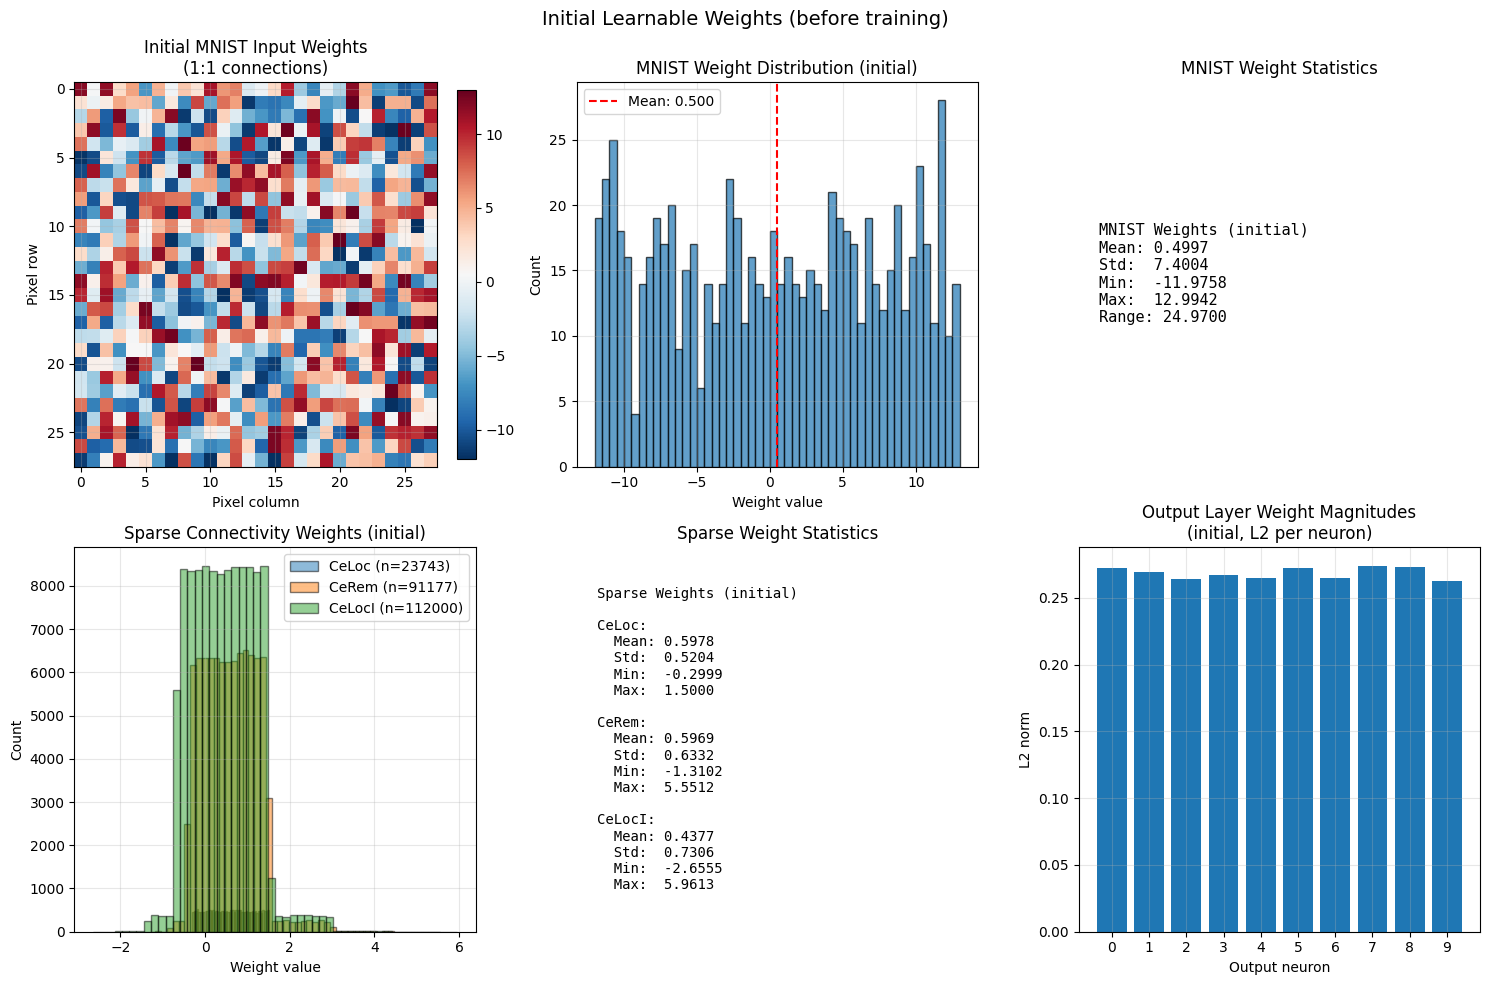

📷 Captured figure 2 -> saved_figures/figure_02_0c300138.png


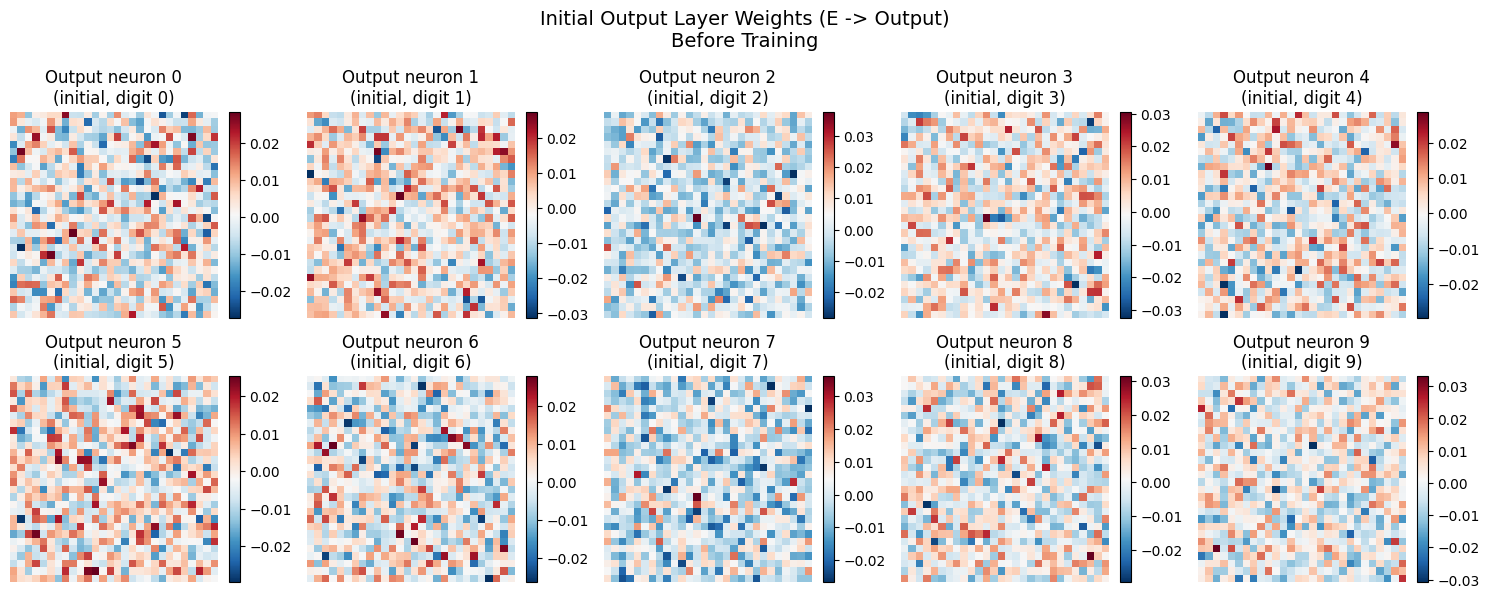


Cached initial weights in 'initial_weight_snapshots' for later comparison.
After training, run:
  1) Visualize Learned Weights After Training
  2) Compare Weights Before and After Training (side-by-side)


In [17]:
# @title Visualize learnable parameters (before training)

import numpy as np
import matplotlib.pyplot as plt

print("="*70)
print("LEARNABLE PARAMETERS SUMMARY (before training)")
print("="*70)

# List all parameters with basic statistics
total_params = 0
for name, param in model.named_parameters():
    print(f"\n{name}:")
    print(f"  Shape: {param.shape}")
    n_el = param.numel()
    total_params += n_el
    print(f"  Total elements: {n_el:,}")

    if n_el > 0:
        data = param.detach().cpu()
        print(f"  Mean: {data.mean().item():.4f}, Std: {data.std().item():.4f}")
        print(f"  Min:  {data.min().item():.4f}, Max: {data.max().item():.4f}")

print("\n" + "="*70)
print(f"TOTAL LEARNABLE PARAMETERS: {total_params:,}")
print("="*70)

# ============================
# Figure 1: Initial weights
# Layout matches the post-training visualization
# ============================

# --- MNIST input weights ---
mnist_weights_init = model.mnist_weights.detach().cpu().numpy()

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Top-left: spatial 28x28 pattern (if applicable)
ax = axes[0, 0]
if mnist_weights_init.size == 28 * 28:
    im = ax.imshow(mnist_weights_init.reshape(28, 28), cmap="RdBu_r", aspect="auto")
    ax.set_title("Initial MNIST Input Weights\n(1:1 connections)")
    ax.set_xlabel("Pixel column")
    ax.set_ylabel("Pixel row")
    plt.colorbar(im, ax=ax, fraction=0.046)
else:
    ax.plot(mnist_weights_init)
    ax.set_title(f"Initial MNIST Input Weights\n({mnist_weights_init.size} connections)")
    ax.set_xlabel("Connection index")
    ax.set_ylabel("Weight value")
ax.grid(alpha=0.3)

# Top-middle: histogram of MNIST input weights
ax = axes[0, 1]
ax.hist(mnist_weights_init, bins=50, edgecolor="black", alpha=0.7)
ax.set_xlabel("Weight value")
ax.set_ylabel("Count")
ax.set_title("MNIST Weight Distribution (initial)")
ax.grid(alpha=0.3)
ax.axvline(mnist_weights_init.mean(), color="red", linestyle="--",
           label=f"Mean: {mnist_weights_init.mean():.3f}")
ax.legend()

# Top-right: MNIST weight statistics as text
ax = axes[0, 2]
stats_lines = [
    "MNIST Weights (initial)",
    f"Mean: {mnist_weights_init.mean():.4f}",
    f"Std:  {mnist_weights_init.std():.4f}",
    f"Min:  {mnist_weights_init.min():.4f}",
    f"Max:  {mnist_weights_init.max():.4f}",
    f"Range: {(mnist_weights_init.max() - mnist_weights_init.min()):.4f}",
]
stats_text = "\n".join(stats_lines)
ax.text(0.05, 0.5, stats_text, fontsize=11, family="monospace",
        va="center", transform=ax.transAxes)
ax.axis("off")
ax.set_title("MNIST Weight Statistics")

# --- Sparse connectivity weights (CeLoc, CeRem, CeLocI) ---
celoc_init = model.CeLoc_values.detach().cpu().numpy()
cerem_init = model.CeRem_values.detach().cpu().numpy()
celoci_init = model.CeLocI_values.detach().cpu().numpy()

ax = axes[1, 0]
if celoc_init.size > 0:
    ax.hist(celoc_init, bins=50, alpha=0.5,
            label=f"CeLoc (n={celoc_init.size})", edgecolor="black")
if cerem_init.size > 0:
    ax.hist(cerem_init, bins=50, alpha=0.5,
            label=f"CeRem (n={cerem_init.size})", edgecolor="black")
if celoci_init.size > 0:
    ax.hist(celoci_init, bins=50, alpha=0.5,
            label=f"CeLocI (n={celoci_init.size})", edgecolor="black")

ax.set_xlabel("Weight value")
ax.set_ylabel("Count")
ax.set_title("Sparse Connectivity Weights (initial)")
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend()
ax.grid(alpha=0.3)

# Bottom-middle: sparse statistics text
ax = axes[1, 1]

def _safe_stats(arr, name):
    if arr.size == 0:
        return f"{name}: (no non-zero entries)"
    return (
        f"{name}:\n"
        f"  Mean: {arr.mean():.4f}\n"
        f"  Std:  {arr.std():.4f}\n"
        f"  Min:  {arr.min():.4f}\n"
        f"  Max:  {arr.max():.4f}"
    )

sparse_stats_lines = [
    "Sparse Weights (initial)",
    "",
    _safe_stats(celoc_init, "CeLoc"),
    "",
    _safe_stats(cerem_init, "CeRem"),
    "",
    _safe_stats(celoci_init, "CeLocI"),
]
sparse_stats_text = "\n".join(sparse_stats_lines)
ax.text(0.05, 0.5, sparse_stats_text, fontsize=10, family="monospace",
        va="center", transform=ax.transAxes)
ax.axis("off")
ax.set_title("Sparse Weight Statistics")

# Bottom-right: output layer weight norms per neuron
output_weights_init = model.output_weights.detach().cpu().numpy()
output_norms_init = np.linalg.norm(output_weights_init, axis=1)

ax = axes[1, 2]
ax.bar(range(output_norms_init.size), output_norms_init)
ax.set_xlabel("Output neuron")
ax.set_ylabel("L2 norm")
ax.set_title("Output Layer Weight Magnitudes\n(initial, L2 per neuron)")
ax.set_xticks(range(output_norms_init.size))
ax.grid(alpha=0.3)

plt.suptitle("Initial Learnable Weights (before training)", fontsize=14)
plt.tight_layout()
plt.show()

# ============================
# Figure 2: Detailed output weights (E -> Output)
# Matches layout of post-training visualization
# ============================

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

output_weights_init = model.output_weights.detach().cpu().numpy()
side = int(np.sqrt(model.N))

for i in range(10):
    ax = axes[i]
    if model.N == side * side:
        weights_2d = output_weights_init[i].reshape(side, side)
        im = ax.imshow(weights_2d, cmap="RdBu_r", aspect="auto")
        ax.set_title(f"Output neuron {i}\n(initial, digit {i})")
        ax.axis("off")
        plt.colorbar(im, ax=ax, fraction=0.046)
    else:
        ax.plot(output_weights_init[i])
        ax.set_title(f"Output neuron {i}\n(initial, digit {i})")
        ax.set_xlabel("E neuron index")
        ax.set_ylabel("Weight")
        ax.grid(alpha=0.3)

plt.suptitle("Initial Output Layer Weights (E -> Output)\nBefore Training", fontsize=14)
plt.tight_layout()
plt.show()

# Cache initial weights for later comparison
initial_weight_snapshots = {
    "mnist": mnist_weights_init.copy(),
    "celoc": celoc_init.copy(),
    "cerem": cerem_init.copy(),
    "celoci": celoci_init.copy(),
    "output_weights": output_weights_init.copy(),
    "output_norms": output_norms_init.copy(),
    "N": int(model.N),
}

print("\nCached initial weights in 'initial_weight_snapshots' for later comparison.")
print("After training, run:")
print("  1) Visualize Learned Weights After Training")
print("  2) Compare Weights Before and After Training (side-by-side)")


In [18]:
# @title MNIST Image Provider

class MNISTImageProvider:
    """
    Provides MNIST images that change every IMAGE_DURATION seconds.
    """
    def __init__(self, mnist_dataset, image_duration=0.25, shuffle=True, device=device):
        self.dataset = mnist_dataset
        self.image_duration = image_duration
        self.device = device

        # Pre-load all images for efficiency
        self.images = []
        self.labels = []
        for img, label in mnist_dataset:
            # img is (1, 28, 28), flatten to (784,)
            self.images.append(img.view(-1))
            self.labels.append(label)

        if shuffle:
            indices = torch.randperm(len(self.images))
            self.images = [self.images[i] for i in indices]
            self.labels = [self.labels[i] for i in indices]

        self.current_idx = 0
        self.current_image_start_time = 0.0

    def get_image_at_time(self, t):
        """
        Get the MNIST image that should be displayed at time t.
        Returns: (image, label) where image is shape (784,)
        """
        # Determine which image index based on time
        image_idx = int(t / self.image_duration) % len(self.images)
        return self.images[image_idx].to(self.device), self.labels[image_idx]

    def reset(self):
        """Reset to the first image."""
        self.current_idx = 0
        self.current_image_start_time = 0.0

In [19]:
# @title Simulation helper with MNIST input and output assessment

def run_simulation_with_mnist(model,
                              mnist_provider,
                              T=100.0,
                              dt=0.01,
                              E0=None,
                              I0=None,
                              O0=None,
                              record_every=1,
                              output_average_window=0.01):
    """
    Run a simulation of the sparse Wilson–Cowan network with MNIST images as input.

    model                 : SparseBigWilsonCowan instance
    mnist_provider        : MNISTImageProvider instance
    T                     : total time (same units as dt)
    dt                    : timestep
    E0, I0, O0            : initial conditions or None
    record_every          : record every 'record_every'-th step
    output_average_window : time window (seconds) to average output at end of each image

    Returns:
        times           : (n_rec,)
        E_traj          : (n_rec, N)
        I_traj          : (n_rec, N)
        O_traj          : (n_rec, num_output)
        image_labels    : list of labels for images shown
        image_times     : list of times when images changed
        output_per_image: list of output vectors (averaged over last window) for each image
    """
    N = model.N
    num_output = model.num_output
    steps = int(np.round(T / dt))
    image_duration = mnist_provider.image_duration

    if E0 is None:
        E = 0.1 * torch.rand(N, device=model.device)
    else:
        E = E0.to(model.device)

    if I0 is None:
        I = 0.1 * torch.rand(N, device=model.device)
    else:
        I = I0.to(model.device)

    if O0 is None:
        O = 0.1 * torch.rand(num_output, device=model.device)
    else:
        O = O0.to(model.device)

    # Reset the MNIST provider
    mnist_provider.reset()

    # figure out which steps we record
    record_indices = np.arange(0, steps, record_every, dtype=int)
    n_rec = len(record_indices)

    E_traj = torch.zeros(n_rec, N, device='cpu')
    I_traj = torch.zeros(n_rec, N, device='cpu')
    O_traj = torch.zeros(n_rec, num_output, device='cpu')
    times  = torch.zeros(n_rec, device='cpu')

    # Track which images are shown
    image_labels = []
    image_times = []
    current_image_idx = -1

    # Track outputs at the end of each image (averaged over last window)
    output_per_image = []

    # Buffer to store outputs for averaging
    output_buffer = []
    buffer_time_threshold = output_average_window

    rec_ptr = 0

    for step in range(steps):
        t = step * dt

        # Get the current MNIST image
        mnist_image, label = mnist_provider.get_image_at_time(t)

        # Track image changes
        image_idx = int(t / mnist_provider.image_duration)
        if image_idx != current_image_idx:
            # New image - process the previous image's output if we have one
            if current_image_idx >= 0 and len(output_buffer) > 0:
                # Average outputs over the buffer
                avg_output = torch.stack(output_buffer).mean(dim=0)
                output_per_image.append(avg_output.cpu().numpy())

            # Reset for new image
            current_image_idx = image_idx
            image_labels.append(label)
            image_times.append(t)
            output_buffer = []

        # Compute external input from MNIST image
        I_ext = model.compute_mnist_input(mnist_image * MNIST_INPUT_SCALE)

        E, I, O = model.step(E, I, O, I_ext, dt)

        # Determine if we're in the averaging window at the end of the image
        time_in_image = t - image_times[-1]
        time_until_next_image = image_duration - time_in_image

        if time_until_next_image <= buffer_time_threshold:
            # We're in the final window - add to buffer
            output_buffer.append(O.clone())

        if step in record_indices:
            E_traj[rec_ptr] = E.detach().cpu()
            I_traj[rec_ptr] = I.detach().cpu()
            O_traj[rec_ptr] = O.detach().cpu()
            times[rec_ptr]  = t
            rec_ptr += 1

    # Process the last image's output
    if len(output_buffer) > 0:
        avg_output = torch.stack(output_buffer).mean(dim=0)
        output_per_image.append(avg_output.cpu().numpy())

    return times, E_traj, I_traj, O_traj, image_labels, image_times, output_per_image, E, I, O

Outgoing Py→Py: mean = 142.157, std = 3.368
Incoming Py→Py: mean = 142.157, std = 10.624
Outgoing Py→Inh: mean = 142.857, std = 3.112
Incoming Py→Inh: mean = 142.857, std = 10.341
Outgoing Inh→Py: mean = 1.000, std = 0.000
Incoming Inh→Py: mean = 1.000, std = 0.000
📷 Captured figure 3 -> saved_figures/figure_03_e6e68f89.png


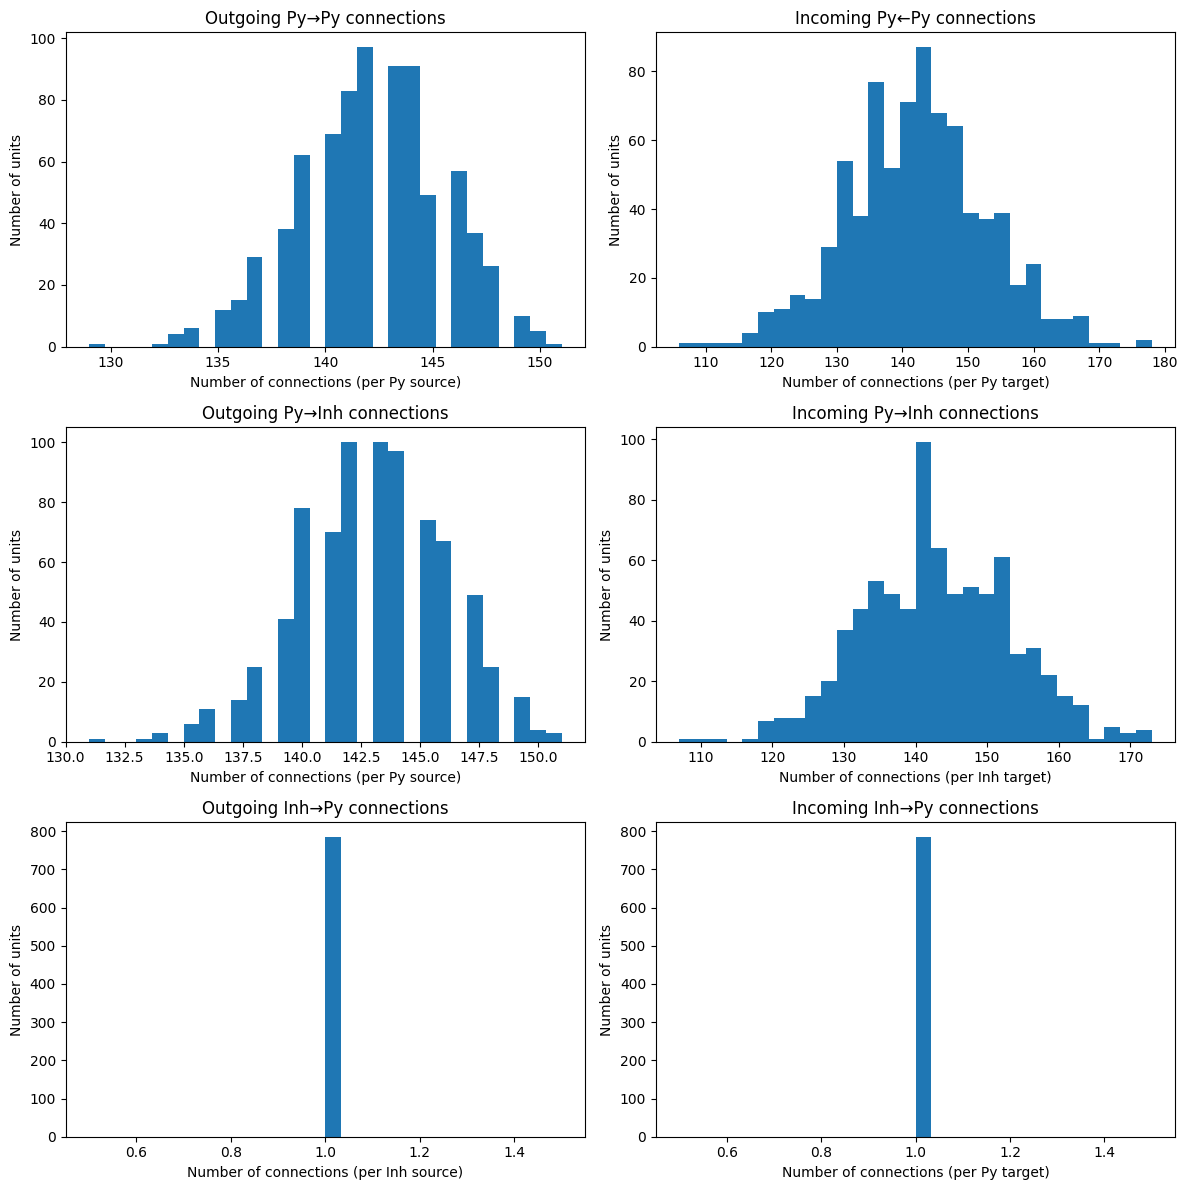

In [20]:
# @title Connectivity histograms

CeEE_csr = CeLoc_csr + CeRem_csr

out_deg_PyPy = np.array(CeEE_csr.getnnz(axis=0)).ravel()
in_deg_PyPy  = np.array(CeEE_csr.getnnz(axis=1)).ravel()
out_deg_PyInh = np.array(CeLocI_csr.getnnz(axis=0)).ravel()
in_deg_PyInh  = np.array(CeLocI_csr.getnnz(axis=1)).ravel()

N = CeLoc_csr.shape[0]
out_deg_InhPy = np.ones(N, dtype=int)
in_deg_InhPy  = np.ones(N, dtype=int)

def print_stats(label, arr):
    print(f"{label}: mean = {np.mean(arr):.3f}, std = {np.std(arr):.3f}")

print_stats("Outgoing Py→Py",  out_deg_PyPy)
print_stats("Incoming Py→Py",  in_deg_PyPy)
print_stats("Outgoing Py→Inh", out_deg_PyInh)
print_stats("Incoming Py→Inh", in_deg_PyInh)
print_stats("Outgoing Inh→Py", out_deg_InhPy)
print_stats("Incoming Inh→Py", in_deg_InhPy)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

axes[0, 0].hist(out_deg_PyPy, bins=30)
axes[0, 0].set_title("Outgoing Py→Py connections")
axes[0, 0].set_xlabel("Number of connections (per Py source)")
axes[0, 0].set_ylabel("Number of units")

axes[0, 1].hist(in_deg_PyPy, bins=30)
axes[0, 1].set_title("Incoming Py←Py connections")
axes[0, 1].set_xlabel("Number of connections (per Py target)")
axes[0, 1].set_ylabel("Number of units")

axes[1, 0].hist(out_deg_PyInh, bins=30)
axes[1, 0].set_title("Outgoing Py→Inh connections")
axes[1, 0].set_xlabel("Number of connections (per Py source)")
axes[1, 0].set_ylabel("Number of units")

axes[1, 1].hist(in_deg_PyInh, bins=30)
axes[1, 1].set_title("Incoming Py→Inh connections")
axes[1, 1].set_xlabel("Number of connections (per Inh target)")
axes[1, 1].set_ylabel("Number of units")

axes[2, 0].hist(out_deg_InhPy, bins=30)
axes[2, 0].set_title("Outgoing Inh→Py connections")
axes[2, 0].set_xlabel("Number of connections (per Inh source)")
axes[2, 0].set_ylabel("Number of units")

axes[2, 1].hist(in_deg_InhPy, bins=30)
axes[2, 1].set_title("Incoming Inh→Py connections")
axes[2, 1].set_xlabel("Number of connections (per Py target)")
axes[2, 1].set_ylabel("Number of units")

plt.tight_layout()
plt.show()

In [21]:

# @title Training Functions - Supervised Learning with Image-Boundary Truncation

import torch.nn.functional as F

def train_one_image(model, mnist_image, label, optimizer, criterion,
                    dt=0.002, image_duration=0.25, output_average_window=0.01,
                    E_init=None, I_init=None, O_init=None, H_init=None,
                    activity_callback=None, activity_time_offset=0.0,
                    sequential_row_input=False, row_duration=None):
    """Train on a single MNIST image using image-boundary truncated BPTT.

    Args:
        model: SparseBigWilsonCowan instance
        mnist_image: (784,) tensor
        label: scalar tensor (0-9)
        optimizer: torch optimizer
        criterion: loss function
        dt: timestep
        image_duration: how long to show image (seconds)
        output_average_window: window for averaging output (seconds)
        E_init, I_init, O_init, H_init: initial network states. If None, zeros are used.
            (v57: H_init added for slow adaptation variable)
        activity_callback: optional function activity_callback(t, E_snapshot, I_snapshot, H_snapshot)
            called at each timestep (t in seconds) with detached E, I, and H.
        sequential_row_input: if True, present image rows one at a time
        row_duration: duration per row (seconds). If None, computed as image_duration/28.

    Returns:
        loss: scalar loss value
        avg_output: final averaged output vector (num_output,)
        correct: boolean, was prediction correct
        E_final, I_final, O_final, H_final: final states (DETACHED, to be fed into next image)
    """
    optimizer.zero_grad()

    # --- Initialize states from previous image (truncate graph) ---
    N = model.N
    num_output = model.num_output

    if E_init is None:
        E = torch.zeros(N, device=model.device)
    else:
        E = E_init.detach()

    if I_init is None:
        I = torch.zeros(N, device=model.device)
    else:
        I = I_init.detach()

    if O_init is None:
        O = torch.zeros(num_output, device=model.device)
    else:
        O = O_init.detach()

    # v57: Initialize H (slow adaptation)
    if H_init is None:
        H = torch.zeros(N, device=model.device)
    else:
        H = H_init.detach()

    # Make them leaf variables with gradients for this image window
    E = E.clone().requires_grad_(True)
    I = I.clone().requires_grad_(True)
    O = O.clone().requires_grad_(True)
    H = H.clone().requires_grad_(True)  # v57: H also needs gradients for BPTT

    num_steps = int(image_duration / dt)
    buffer_steps = int(output_average_window / dt)

    # Buffer for averaging output over last window
    output_buffer = []

    if sequential_row_input:
        # Sequential row-by-row presentation
        if row_duration is None:
            row_duration = image_duration / 28
        steps_per_row = max(1, int(row_duration / dt))

        # Precompute which row is active at each timestep
        # Row i is active during steps [i*steps_per_row, (i+1)*steps_per_row)
        for step in range(num_steps):
            # Determine which row is currently active
            current_row = min(step // steps_per_row, 27)

            # Compute input with only the active row
            I_ext = model.compute_mnist_input(
                mnist_image.to(model.device) * MNIST_INPUT_SCALE,
                active_row=current_row
            )

            E, I, O, H = model.forward(E, I, O, I_ext, dt, H=H)  # v57: added H

            # Optional callback to record activity without tracking gradients
            if activity_callback is not None:
                t = activity_time_offset + (step + 1) * dt
                activity_callback(t, E.detach(), I.detach(), H.detach())  # v57: added H

            # Store outputs in the final averaging window
            if step >= num_steps - buffer_steps:
                output_buffer.append(O)
    else:
        # Original behavior: full image at once
        I_ext = model.compute_mnist_input(mnist_image.to(model.device) * MNIST_INPUT_SCALE)

        for step in range(num_steps):
            E, I, O, H = model.forward(E, I, O, I_ext, dt, H=H)  # v57: added H

            # Optional callback to record activity without tracking gradients
            if activity_callback is not None:
                t = activity_time_offset + (step + 1) * dt
                activity_callback(t, E.detach(), I.detach(), H.detach())  # v57: added H

            # Store outputs in the final averaging window
            if step >= num_steps - buffer_steps:
                output_buffer.append(O)

    # Average output over final window
    avg_output = torch.stack(output_buffer).mean(dim=0)

    # Compute loss
    loss = criterion(avg_output.unsqueeze(0), label.unsqueeze(0))

    # Backward pass through all timesteps of this image
    loss.backward()

    # Update weights
    optimizer.step()

    # Check if prediction was correct
    predicted = torch.argmax(avg_output)
    correct = (predicted == label).item()

    # Detach final states so they can be reused for the next image
    E_final = E.detach()
    I_final = I.detach()
    O_final = O.detach()
    H_final = H.detach()  # v57: slow adaptation

    return loss.item(), avg_output.detach().cpu(), correct, E_final, I_final, O_final, H_final


def train_epoch(model, train_loader, optimizer, criterion,
                dt=0.002, image_duration=0.25, output_average_window=0.01,
                max_images=None, verbose=True,
                E_init=None, I_init=None, O_init=None, H_init=None,
                sequential_row_input=False, row_duration=None):
    """Train for one epoch over the dataset.

    Args:
        model: SparseBigWilsonCowan instance
        train_loader: DataLoader for training data
        optimizer: torch optimizer
        criterion: loss function
        dt: timestep
        image_duration: time each image is shown (seconds)
        output_average_window: window for averaging outputs (seconds)
        max_images: if set, only train on this many images per epoch
        verbose: print progress during training
        E_init, I_init, O_init, H_init: initial states at the START of the epoch.
            These allow continuity of dynamics across epochs. (v57: H_init added)
        sequential_row_input: if True, present image rows one at a time
        row_duration: duration per row (seconds). If None, computed as image_duration/28.

    Returns:
        avg_loss: average loss over the epoch
        accuracy: accuracy over the epoch
        E_final, I_final, O_final, H_final: final states at the END of the epoch
    """
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    # Persistent states across the whole epoch
    E_state = E_init
    I_state = I_init
    O_state = O_init
    H_state = H_init  # v57: slow adaptation

    for batch_idx, (data, target) in enumerate(train_loader):
        data = data.to(model.device)
        target = target.to(model.device)

        batch_size = data.size(0)

        for i in range(batch_size):
            mnist_image = data[i].view(-1)
            label = target[i]

            loss, _, correct, E_state, I_state, O_state, H_state = train_one_image(
                model, mnist_image, label, optimizer, criterion,
                dt=dt,
                image_duration=image_duration,
                output_average_window=output_average_window,
                E_init=E_state,
                I_init=I_state,
                O_init=O_state,
                H_init=H_state,  # v57: slow adaptation
                sequential_row_input=sequential_row_input,
                row_duration=row_duration
            )

            total_loss += loss
            total_correct += correct
            total_images += 1

            if max_images is not None and total_images >= max_images:
                break

        if verbose and (batch_idx + 1) % 10 == 0:
            print(f"  Batch {batch_idx + 1}/{len(train_loader)}, "
                  f"Images: {total_images}, "
                  f"Loss: {total_loss/total_images:.4f}, "
                  f"Acc: {100*total_correct/total_images:.2f}%")  # noqa: E501

        if max_images is not None and total_images >= max_images:
            break

    avg_loss = total_loss / max_images if (max_images is not None and max_images > 0) else total_loss / max(total_images, 1)
    accuracy = total_correct / max(total_images, 1)

    return avg_loss, accuracy, E_state, I_state, O_state, H_state  # v57: added H_state




def evaluate(model, test_loader, criterion,
             dt=0.002, image_duration=0.25, output_average_window=0.01,
             max_images=None, verbose=True,
             E_init=None, I_init=None, O_init=None, H_init=None,
             pulsed_stimuli=False,
             sequential_row_input=False, row_duration=None,
             record_H_history=False):
    """Evaluate model on test set with continuous E/I/O/H dynamics.

    States E, I, O, and H evolve continuously across images during this call.
    If E_init/I_init/O_init/H_init are provided, evaluation will start from those states;
    otherwise, they will be initialized to zero.

    If sequential_row_input is True, images are presented row-by-row over image_duration.

    v57: Added H (slow adaptation) state tracking and optional H_history recording.

    Returns:
        avg_loss: average loss
        accuracy: accuracy
        predictions: list of predicted labels
        true_labels: list of true labels
        outputs_list: list of output vectors (numpy arrays)
        E_state, I_state, O_state, H_state: final states after evaluation
        H_history: dict with 'times', 'means', 'stds' if record_H_history=True, else None
    """
    # v71: Evaluation is deterministic - processes images in order from DataLoader

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    predictions = []
    true_labels = []
    outputs_list = []

    N = model.N
    num_output = model.num_output

    # Initialize persistent states for this evaluation run
    if E_init is None:
        E_state = torch.zeros(N, device=model.device)
    else:
        E_state = E_init.to(model.device)

    if I_init is None:
        I_state = torch.zeros(N, device=model.device)
    else:
        I_state = I_init.to(model.device)

    if O_init is None:
        O_state = torch.zeros(num_output, device=model.device)
    else:
        O_state = O_init.to(model.device)

    # v57: Initialize H (slow adaptation)
    if H_init is None:
        H_state = torch.zeros(N, device=model.device)
    else:
        H_state = H_init.to(model.device)

    # v57: H history tracking for plots
    H_history_times = []
    H_history_means = []
    H_history_stds = []
    eval_time_offset = 0.0  # Track cumulative time during evaluation

    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(test_loader):
            data = data.to(model.device)
            target = target.to(model.device)

            batch_size = data.size(0)

            for i in range(batch_size):
                mnist_image = data[i].view(-1)
                label = target[i]

                # Initialize states from previous image's final state
                E = E_state.clone()
                I = I_state.clone()
                O = O_state.clone()
                H = H_state.clone()  # v57: slow adaptation

                num_steps = int(image_duration / dt)
                buffer_steps = int(output_average_window / dt)

                output_buffer = []

                if sequential_row_input:
                    # Sequential row-by-row presentation
                    if row_duration is None:
                        _row_duration = image_duration / 28
                    else:
                        _row_duration = row_duration
                    steps_per_row = max(1, int(_row_duration / dt))

                    for step in range(num_steps):
                        current_row = min(step // steps_per_row, 27)
                        I_ext = model.compute_mnist_input(
                            mnist_image * MNIST_INPUT_SCALE,
                            active_row=current_row
                        )
                        E, I, O, H = model.step(E, I, O, I_ext, dt, H=H)  # v57: added H

                        # v57: Record H statistics if requested
                        if record_H_history:
                            t = eval_time_offset + step * dt
                            H_history_times.append(t)
                            H_history_means.append(float(H.mean().item()))
                            H_history_stds.append(float(H.std().item()))

                        if step >= num_steps - buffer_steps:
                            output_buffer.append(O)
                else:
                    # Original behavior: full image at once
                    I_ext = model.compute_mnist_input(mnist_image * MNIST_INPUT_SCALE)

                    for step in range(num_steps):
                        E, I, O, H = model.step(E, I, O, I_ext, dt, H=H)  # v57: added H

                        # v57: Record H statistics if requested
                        if record_H_history:
                            t = eval_time_offset + step * dt
                            H_history_times.append(t)
                            H_history_means.append(float(H.mean().item()))
                            H_history_stds.append(float(H.std().item()))

                        if step >= num_steps - buffer_steps:
                            output_buffer.append(O)

                avg_output = torch.stack(output_buffer).mean(dim=0)

                loss = criterion(avg_output.unsqueeze(0), label.unsqueeze(0))
                total_loss += loss.item()

                predicted = torch.argmax(avg_output)
                correct = (predicted == label).item()
                total_correct += correct
                total_images += 1

                predictions.append(predicted.cpu().item())
                true_labels.append(label.cpu().item())
                outputs_list.append(avg_output.cpu().numpy())

                # Update persistent states for continuity across images
                E_state = E.clone()
                I_state = I.clone()
                O_state = O.clone()
                H_state = H.clone()  # v57: slow adaptation

                # v57: Update time offset for H history
                eval_time_offset += image_duration

                # Optional 1s OFF period after blocks of images (pulsed stimulus mode)
                if pulsed_stimuli:
                    images_per_block = max(int(round(1.0 / image_duration)), 1)
                    if (total_images) % images_per_block == 0 and (max_images is None or total_images < max_images):
                        off_duration = 1.0  # seconds of no external input
                        num_off_steps = int(off_duration / dt)
                        I_ext_off = torch.zeros_like(I_ext)
                        for off_step in range(num_off_steps):
                            E_state, I_state, O_state, H_state = model.step(E_state, I_state, O_state, I_ext_off, dt, H=H_state)  # v57: added H

                            # v57: Record H statistics during OFF period if requested
                            if record_H_history:
                                t = eval_time_offset + off_step * dt
                                H_history_times.append(t)
                                H_history_means.append(float(H_state.mean().item()))
                                H_history_stds.append(float(H_state.std().item()))

                        # v57: Update time offset after OFF period
                        eval_time_offset += off_duration

                if max_images is not None and total_images >= max_images:
                    break

            if max_images is not None and total_images >= max_images:
                break

    avg_loss = total_loss / max(total_images, 1)
    accuracy = total_correct / max(total_images, 1)

    if verbose:
        print(f"Evaluation: Loss: {avg_loss:.4f}, Accuracy: {100*accuracy:.2f}%")  # noqa: E501

    # v57: Prepare H history if recorded
    if record_H_history:
        H_history = {
            'times': H_history_times,
            'means': H_history_means,
            'stds': H_history_stds
        }
    else:
        H_history = None

    return avg_loss, accuracy, predictions, true_labels, outputs_list, E_state, I_state, O_state, H_state, H_history


print("Training functions defined successfully!")
print("\nFunctions available:")
print("  - train_one_image(): Train on single image with BPTT (continuous state)")
print("  - train_epoch(): Train for one epoch (continuous state across images/epochs)")
print("  - evaluate(): Evaluate on test set (continuous state across images)")


Training functions defined successfully!

Functions available:
  - train_one_image(): Train on single image with BPTT (continuous state)
  - train_epoch(): Train for one epoch (continuous state across images/epochs)
  - evaluate(): Evaluate on test set (continuous state across images)


In [22]:
# @title Parameter exploration: independent runs (no training) - skip if PARAM_EXPLORE_MODE=False

# NOTE: This cell only runs when PARAM_EXPLORE_MODE = True.
# When PARAM_EXPLORE_MODE = False, this cell is skipped entirely.

if not globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is False. Skipping parameter exploration cell.")
    print("Proceeding to normal training workflow...")
else:
    import os
    import io
    from datetime import datetime

    import numpy as np
    import pandas as pd
    import torch
    import matplotlib.pyplot as plt
    from scipy.signal import butter, lfilter

    # Optional dependencies (Colab-safe)
    try:
        import docx
        from docx import Document
        from docx.shared import Inches
    except ImportError:
        get_ipython().system('pip install python-docx --quiet')
        import docx
        from docx import Document
        from docx.shared import Inches

    try:
        import openpyxl
    except ImportError:
        get_ipython().system('pip install openpyxl --quiet')
        import openpyxl

    print("[PARAM EXPLORE] Starting exploration runs")

    # ------------------------------------------------------------------
    # Helpers (stim onsets + ticks + zero-phase-ish filter + electrodes)
    # ------------------------------------------------------------------
    def _stim_onsets_abs_in_window(t0_abs, t1_abs, image_duration_s,
                                  pulsed=False, pulse_on_s=1.0, pulse_off_s=1.0,
                                  align_t0=0.0):
        try:
            t0_abs = float(t0_abs); t1_abs = float(t1_abs)
            image_duration_s = float(image_duration_s)
            pulse_on_s = float(pulse_on_s); pulse_off_s = float(pulse_off_s)
            align_t0 = float(align_t0)
        except Exception:
            return np.array([], dtype=float)

        if image_duration_s <= 0 or t1_abs <= t0_abs:
            return np.array([], dtype=float)

        eps = 1e-9

        if not pulsed:
            k0 = int(np.ceil((t0_abs - align_t0) / image_duration_s - eps))
            k1 = int(np.floor((t1_abs - align_t0) / image_duration_s + eps))
            if k1 < k0:
                return np.array([], dtype=float)
            ks = np.arange(k0, k1 + 1, dtype=int)
            return (align_t0 + ks * image_duration_s).astype(float)

        cycle = pulse_on_s + pulse_off_s
        if cycle <= 0 or pulse_on_s <= 0:
            return np.array([], dtype=float)

        images_per_block = max(int(round(pulse_on_s / image_duration_s)), 1)
        block_on_dur = images_per_block * image_duration_s
        block_dur = block_on_dur + pulse_off_s

        b0 = int(np.floor((t0_abs - align_t0) / block_dur)) - 1
        b1 = int(np.ceil((t1_abs - align_t0) / block_dur)) + 1

        onsets = []
        for b in range(b0, b1 + 1):
            block_start = align_t0 + b * block_dur
            for j in range(images_per_block):
                tt = block_start + j * image_duration_s
                if (tt + eps) < t0_abs or (tt - eps) > t1_abs:
                    continue
                onsets.append(tt)

        if not onsets:
            return np.array([], dtype=float)
        return np.array(sorted(onsets), dtype=float)


    def _add_stim_ticks(ax, stim_times_s, color="k", where="bottom", height_frac=0.03, offset_frac=0.015):
        stim_times_s = np.asarray(stim_times_s, dtype=float).ravel()
        stim_times_s = stim_times_s[np.isfinite(stim_times_s)]
        if stim_times_s.size == 0:
            return

        y0, y1 = ax.get_ylim()
        yr = (y1 - y0) if (y1 != y0) else 1.0

        if where == "below":
            y_base = y0 - offset_frac * yr
            y_top = y_base + height_frac * yr
            ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=1.0, zorder=20, clip_on=False)
            ax.set_ylim(y0 - (offset_frac + height_frac + 0.01) * yr, y1)
        else:
            y_base = y0 + offset_frac * yr
            y_top = y_base + height_frac * yr
            ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=1.0, zorder=20, clip_on=True)


    def filter_eeg_explore(eeg, cutoff, sample_rate, high_or_low, order):
        """Forward-backward IIR filter."""
        eeg = np.asarray(eeg)
        ny = sample_rate / 2.0
        Wn = np.asarray(cutoff) / ny
        b, a = butter(order, Wn, btype=high_or_low)
        eeg_f = lfilter(b, a, eeg, axis=0)
        eeg_f_reverse = eeg_f[::-1, :]
        eeg_f_reverse_f = lfilter(b, a, eeg_f_reverse, axis=0)
        return eeg_f_reverse_f[::-1, :]


    def _select_torus_electrodes(num_cells, num_row_electrodes=5, num_col_electrodes=5):
        """Return (n, row_labels_1based, col_labels_0based, linear_indices, labels)."""
        n = int(np.sqrt(num_cells))
        if n * n != int(num_cells):
            raise ValueError(f"num_cells={num_cells} is not a perfect square; cannot infer n×n grid.")

        if num_row_electrodes < 1 or num_col_electrodes < 1:
            raise ValueError("num_row_electrodes and num_col_electrodes must be >= 1")
        if num_row_electrodes > n or num_col_electrodes > n:
            raise ValueError(f"Too many electrodes for grid: n={n}, rows={num_row_electrodes}, cols={num_col_electrodes}")

        row_idx0 = (np.round((np.arange(num_row_electrodes) + 0.5) * (n / num_row_electrodes)) % n).astype(int)
        col_idx0 = (np.round((np.arange(num_col_electrodes) + 0.5) * (n / num_col_electrodes)) % n).astype(int)

        row_labels = np.repeat(row_idx0 + 1, len(col_idx0))
        col_labels = np.tile(col_idx0, len(row_idx0))

        labels = [f"r{int(r):02d}_c{int(c):02d}" for r, c in zip(row_labels, col_labels)]
        linear = (col_labels * n + (row_labels - 1)).astype(int)
        return n, row_labels, col_labels, linear, labels

    # ------------------------------------------------------------------
    # Custom simulation function for parameter exploration (supports sequential row input)
    # ------------------------------------------------------------------
    def run_exploration_simulation(model, mnist_provider, T, dt, E0, I0, O0, H0,
                                   record_every=1,
                                   sequential_row_input=False,
                                   row_duration=None,
                                   mnist_input_scale=3.0,
                                   pulsed_stimuli=False,
                                   pulse_on_s=1.0,
                                   pulse_off_s=1.0):
        """
        Run a simulation for parameter exploration with optional sequential row input.

        v57: Added H0 for slow adaptation variable.

        Returns:
            times, E_traj, I_traj, O_traj, H_traj,
            image_labels, image_times, output_per_image,
            E_end, I_end, O_end, H_end,
            mnist_drive_times, mnist_drive_sum, mnist_drive_l2,
            H_history_times, H_history_means, H_history_stds
        """
        N = model.N
        num_output = model.num_output
        steps = int(np.round(T / dt))
        image_duration = mnist_provider.image_duration

        # Initialize states
        E = E0.clone().to(model.device)
        I = I0.clone().to(model.device)
        O = O0.clone().to(model.device)
        H = H0.clone().to(model.device)  # v57: slow adaptation

        # Reset MNIST provider
        try:
            mnist_provider.reset()
        except:
            pass

        # Recording setup
        record_indices = np.arange(0, steps, record_every, dtype=int)
        n_rec = len(record_indices)

        E_traj = torch.zeros(n_rec, N, device='cpu')
        I_traj = torch.zeros(n_rec, N, device='cpu')
        O_traj = torch.zeros(n_rec, num_output, device='cpu')
        H_traj = torch.zeros(n_rec, N, device='cpu')  # v57: slow adaptation
        times = torch.zeros(n_rec, device='cpu')

        # MNIST drive tracking
        mnist_drive_times = []
        mnist_drive_sum = []
        mnist_drive_l2 = []

        # v57: H statistics tracking per timestep
        H_history_times = []
        H_history_means = []
        H_history_stds = []

        # Image tracking
        image_labels = []
        image_times = []
        output_per_image = []
        current_image_idx = -1

        # Pulsed stimuli tracking
        if pulsed_stimuli:
            images_per_block = max(int(round(pulse_on_s / image_duration)), 1)
            block_on_dur = images_per_block * image_duration
            cycle_dur = block_on_dur + pulse_off_s

        # Sequential row input setup
        if sequential_row_input:
            if row_duration is None:
                row_duration = image_duration / 28
            steps_per_row = max(1, int(row_duration / dt))

        rec_ptr = 0

        with torch.no_grad():
            for step in range(steps):
                t = step * dt

                # Determine if we're in an OFF period (pulsed stimuli)
                in_off_period = False
                if pulsed_stimuli:
                    cycle_pos = t % cycle_dur
                    in_off_period = (cycle_pos >= block_on_dur)

                if in_off_period:
                    # No external input during OFF period
                    I_ext = torch.zeros(N, device=model.device)
                    current_label = -1
                else:
                    # Get current MNIST image
                    if pulsed_stimuli:
                        # Adjust time to account for OFF periods
                        cycle_num = int(t / cycle_dur)
                        time_in_cycle = t % cycle_dur
                        effective_t = cycle_num * block_on_dur + min(time_in_cycle, block_on_dur)
                    else:
                        effective_t = t

                    mnist_image, label = mnist_provider.get_image_at_time(effective_t)
                    current_label = label

                    # Track image changes
                    new_image_idx = int(effective_t / image_duration)
                    if new_image_idx != current_image_idx:
                        if current_image_idx >= 0:
                            output_per_image.append(O.detach().cpu().clone())
                        image_labels.append(label)
                        image_times.append(t)
                        current_image_idx = new_image_idx

                    # Compute external input
                    if sequential_row_input:
                        # Determine which row is active within this image
                        time_in_image = effective_t % image_duration
                        current_row = min(int(time_in_image / row_duration), 27)
                        I_ext = model.compute_mnist_input(
                            mnist_image.view(-1).to(model.device) * mnist_input_scale,
                            active_row=current_row
                        )
                    else:
                        I_ext = model.compute_mnist_input(
                            mnist_image.view(-1).to(model.device) * mnist_input_scale
                        )

                # Track MNIST drive
                mnist_drive_times.append(t)
                mnist_drive_sum.append(float(I_ext.sum().item()))
                mnist_drive_l2.append(float(torch.norm(I_ext).item()))

                # Step the model (v57: added H)
                E, I, O, H = model.step(E, I, O, I_ext, dt, H=H)

                # v57: Track H statistics
                H_history_times.append(t)
                H_history_means.append(float(H.mean().item()))
                H_history_stds.append(float(H.std().item()))

                # Record if this is a recording step
                if rec_ptr < n_rec and step == record_indices[rec_ptr]:
                    E_traj[rec_ptr] = E.cpu()
                    I_traj[rec_ptr] = I.cpu()
                    O_traj[rec_ptr] = O.cpu()
                    H_traj[rec_ptr] = H.cpu()  # v57: slow adaptation
                    times[rec_ptr] = t
                    rec_ptr += 1

        # Final output for last image
        if current_image_idx >= 0:
            output_per_image.append(O.detach().cpu().clone())

        return (times.numpy(), E_traj, I_traj, O_traj, H_traj,
                image_labels, image_times, output_per_image,
                E.detach(), I.detach(), O.detach(), H.detach(),
                mnist_drive_times, mnist_drive_sum, mnist_drive_l2,
                H_history_times, H_history_means, H_history_stds)

    # ------------------------------------------------------------------
    # Resolve core constants with safe defaults
    # ------------------------------------------------------------------
    SIDE_LENGTH = int(globals().get("SIDE_LENGTH", 28))
    NUM_UNITS = int(globals().get("NUM_UNITS", SIDE_LENGTH * SIDE_LENGTH))
    NUM_CLASSES = int(globals().get("NUM_CLASSES", 10))

    output_average_window = float(globals().get("output_average_window", globals().get("OUTPUT_AVERAGE_WINDOW", 0.01)))

    IC_E_MAX = float(globals().get("IC_E_MAX", 1.0))
    IC_I_MAX = float(globals().get("IC_I_MAX", 1.0))

    PULSED_STIMULI_EXPLORE = bool(globals().get("PULSED_STIMULI", False))
    PULSE_ON_S = float(globals().get("PULSE_ON_S", globals().get("PULSE_ON_SEC", 1.0)))
    PULSE_OFF_S = float(globals().get("PULSE_OFF_S", globals().get("PULSE_OFF_SEC", 1.0)))

    # v57: Sequential row input support
    SEQUENTIAL_ROW_INPUT_EXPLORE = bool(globals().get("SEQUENTIAL_ROW_INPUT", False))
    IMAGE_DURATION_EXPLORE = float(globals().get("IMAGE_DURATION", 0.25))
    ROW_DURATION_EXPLORE = float(globals().get("ROW_DURATION", IMAGE_DURATION_EXPLORE / 28))

    # MNIST input scale
    MNIST_INPUT_SCALE_EXPLORE = float(globals().get("MNIST_INPUT_SCALE", 3.0))

    # ------------------------------------------------------------------
    # Preconditions (fail-fast)
    # ------------------------------------------------------------------
    _required_globals = ["MNISTImageProvider", "SparseBigWilsonCowan",
                         "generate_ws_directed_csr", "csr_to_torch_sparse"]
    _missing = [k for k in _required_globals if k not in globals()]
    if _missing:
        raise RuntimeError(f"Missing required definitions earlier in notebook: {_missing}")

    _needed_outdeg = ["TARGET_OUTDEG_PyPy", "TARGET_OUTDEG_PyInh"]
    _missing_outdeg = [k for k in _needed_outdeg if k not in globals()]
    if _missing_outdeg:
        raise RuntimeError(f"Missing required outdegree globals earlier in notebook: {_missing_outdeg}")

    # ------------------------------------------------------------------
    # Drive / output paths
    # ------------------------------------------------------------------
    timestamp_tag = datetime.now().strftime("%Y%m%d_%H%M%S")
    drive_root = "/content/drive/MyDrive" if os.path.exists("/content/drive/MyDrive") else "/content"
    out_dir = globals().get("OUTPUT_DIR", None)
    if out_dir is None:
        out_dir = os.path.join(drive_root, "Colab Notebooks", "Learning and Seizures 12_5_25")
    os.makedirs(out_dir, exist_ok=True)

    word_name = f"{NOTEBOOK_NAME.replace('.ipynb', '')}_{timestamp_tag}.docx"
    xlsx_name = "WC_MNIST_parameter_explore_log.xlsx"
    word_path = os.path.join(out_dir, word_name)
    xlsx_path = os.path.join(out_dir, xlsx_name)

    print(f"✅ Word doc will be saved to: {word_path}")
    print(f"✅ Log will be saved to: {xlsx_path}")

    # ------------------------------------------------------------------
    # MNIST dataset/provider init
    # ------------------------------------------------------------------
    if "mnist_train_dataset" not in globals() or globals().get("mnist_train_dataset", None) is None:
        from torchvision import datasets, transforms
        mnist_transform = transforms.Compose([transforms.ToTensor()])
        mnist_train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=mnist_transform)
        globals()["mnist_train_dataset"] = mnist_train_dataset
        print("[PARAM EXPLORE] MNIST train dataset initialized.")

    device = globals().get("device", None)
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    globals()["device"] = device

    mnist_provider_explore = MNISTImageProvider(
        mnist_train_dataset,
        image_duration=IMAGE_DURATION_EXPLORE,
        shuffle=True,
        device=device
    )

    # ------------------------------------------------------------------
    # Seeding base
    # ------------------------------------------------------------------
    RANDOM_SEED_BASE_VAL = globals().get("RANDOM_SEED_BASE", None)
    if RANDOM_SEED_BASE_VAL is None:
        seed_base = int(datetime.now().timestamp())
        print(f"[PARAM EXPLORE] RANDOM_SEED_BASE is None -> using base seed {seed_base}")
    else:
        seed_base = int(RANDOM_SEED_BASE_VAL)

    # ------------------------------------------------------------------
    # Single Word document for all runs
    # ------------------------------------------------------------------
    doc = Document()
    doc.add_heading("WC_MNIST Parameter Exploration (independent runs)", level=1)
    doc.add_paragraph(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    doc.add_paragraph(f"Notebook: {globals().get('NOTEBOOK_NAME', 'WC_MNIST_Classifier_BPTT_sequential')}")
    doc.add_paragraph(f"Device: {device}")
    doc.add_paragraph(f"SEQUENTIAL_ROW_INPUT={SEQUENTIAL_ROW_INPUT_EXPLORE}")
    doc.add_paragraph(f"PULSED_STIMULI={PULSED_STIMULI_EXPLORE}, pulse_on={PULSE_ON_S}s, pulse_off={PULSE_OFF_S}s, image_duration={mnist_provider_explore.image_duration}s")

    # ------------------------------------------------------------------
    # Utility functions
    # ------------------------------------------------------------------
    def _resolve_global_name(name: str) -> str:
        if name in globals():
            return name
        alias_map = {
            "P_REWIRE_PY_PY_MIN":  "P_REWIRE_PyPy_MIN",
            "P_REWIRE_PY_PY_MAX":  "P_REWIRE_PyPy_MAX",
            "P_REWIRE_PY_INH_MIN": "P_REWIRE_PyInh_MIN",
            "P_REWIRE_PY_INH_MAX": "P_REWIRE_PyInh_MAX",
        }
        alt = alias_map.get(name)
        if alt and alt in globals():
            return alt
        return name

    def _u(min_name, max_name, label_for_err):
        min_name_r = _resolve_global_name(min_name)
        max_name_r = _resolve_global_name(max_name)
        if min_name_r not in globals() or max_name_r not in globals():
            raise RuntimeError(
                f"Missing {min_name}/{max_name} globals needed to sample {label_for_err}. "
                f"(Tried aliases: {min_name_r}/{max_name_r})"
            )
        return float(np.random.uniform(float(globals()[min_name_r]), float(globals()[max_name_r])))

    def _tensor_stats(t: torch.Tensor) -> dict:
        t = t.detach().float().flatten()
        if t.is_cuda:
            t = t.cpu()
        if t.numel() == 0:
            return {"min": np.nan, "max": np.nan, "mean": np.nan, "std": np.nan}
        return {
            "min": float(t.min().item()),
            "max": float(t.max().item()),
            "mean": float(t.mean().item()),
            "std": float(t.std(unbiased=False).item()),
        }

    def run_one_exploration(run_id: int, run_seed: int, doc: Document) -> dict:
        """One independent run: build params + connectivity + model, simulate, plot, insert into doc, return log row."""
        np.random.seed(int(run_seed))
        torch.manual_seed(int(run_seed))

        # ---- Random hyperparameters ----
        p_rewire_py_py  = _u("P_REWIRE_PyPy_MIN",  "P_REWIRE_PyPy_MAX",  "p_rewire_py_py")
        p_rewire_py_inh = _u("P_REWIRE_PyInh_MIN", "P_REWIRE_PyInh_MAX", "p_rewire_py_inh")

        bias_e   = _u("BIAS_E_INIT_MIN", "BIAS_E_INIT_MAX", "bias_e")
        bias_i   = _u("BIAS_I_INIT_MIN", "BIAS_I_INIT_MAX", "bias_i")
        bias_out = _u("BIAS_OUT_MIN",    "BIAS_OUT_MAX",    "bias_out")

        # v58: Sample ALPHA_H fresh for each exploration run
        alpha_H_run = _u("ALPHA_H_MIN", "ALPHA_H_MAX", "alpha_H")

        # v63: Sample TAU_H fresh for each exploration run
        tau_H_run = _u("TAU_H_MIN", "TAU_H_MAX", "tau_H")

        output_weight_scale = _u("OUTPUT_WEIGHT_SCALE_MIN", "OUTPUT_WEIGHT_SCALE_MAX", "output_weight_scale")

        tauPy  = float(globals().get("tauPy",  1.0/25))
        tauInh = float(globals().get("tauInh", 0.5/25))
        tauOut = float(globals().get("tauOut", 1.0/25))

        # ---- WS generation ----
        run_rng = np.random.default_rng(int(run_seed))
        CeLoc_csr  = generate_ws_directed_csr(NUM_UNITS, TARGET_OUTDEG_PyPy,  p_rewire_py_py,  run_rng)
        CeRem_csr  = generate_ws_directed_csr(NUM_UNITS, TARGET_OUTDEG_PyPy,  p_rewire_py_py,  run_rng)
        CeLocI_csr = generate_ws_directed_csr(NUM_UNITS, TARGET_OUTDEG_PyInh, p_rewire_py_inh, run_rng)

        CeLoc_sparse  = csr_to_torch_sparse(CeLoc_csr,  device=device)
        CeRem_sparse  = csr_to_torch_sparse(CeRem_csr,  device=device)
        CeLocI_sparse = csr_to_torch_sparse(CeLocI_csr, device=device)

        # ---- Model ----
        model_explore = SparseBigWilsonCowan(
            CeLoc=CeLoc_sparse,
            CeRem=CeRem_sparse,
            CeLocI=CeLocI_sparse,
            tauPy=tauPy,
            tauInh=tauInh,
            tauOut=tauOut,
            tau_H=tau_H_run,  # v63: use per-run sampled tau_H
            alpha_H=alpha_H_run,  # v58: use per-run sampled alpha_H
            bias_e_init=bias_e,
            bias_i_init=bias_i,
            bias_out=bias_out,
            mnist_input_dim=784,
            num_output=NUM_CLASSES,
            output_weight_scale=output_weight_scale,
            device=device,
        )

        # ---- Random initial conditions ----
        E0 = torch.rand(NUM_UNITS, device=device) * float(IC_E_MAX)
        I0 = torch.rand(NUM_UNITS, device=device) * float(IC_I_MAX)
        O0 = torch.zeros(NUM_CLASSES, device=device)

        # v57: Initialize H from uniform distribution
        H_INIT_MIN_VAL = float(globals().get("H_INIT_MIN", 0.0))
        H_INIT_MAX_VAL = float(globals().get("H_INIT_MAX", 0.1))
        H0 = torch.empty(NUM_UNITS, device=device).uniform_(H_INIT_MIN_VAL, H_INIT_MAX_VAL)

        try:
            mnist_provider_explore.reset()
        except Exception:
            pass

        # ---- Simulate ----
        RUN_SECONDS_VAL = float(globals().get("RUN_SECONDS", 10.0))
        dt_val = float(globals().get("dt", globals().get("DT", 0.002)))
        record_every_val = int(globals().get("record_every", 1))

        t0 = datetime.now()
        (times, E_traj, I_traj, O_traj, H_traj,
         image_labels, image_times, output_per_image,
         E_end, I_end, O_end, H_end,
         mnist_drive_times, mnist_drive_sum, mnist_drive_l2,
         H_history_times, H_history_means, H_history_stds) = run_exploration_simulation(
            model=model_explore,
            mnist_provider=mnist_provider_explore,
            T=RUN_SECONDS_VAL,
            dt=dt_val,
            E0=E0,
            I0=I0,
            O0=O0,
            H0=H0,  # v57: slow adaptation
            record_every=record_every_val,
            sequential_row_input=SEQUENTIAL_ROW_INPUT_EXPLORE,
            row_duration=ROW_DURATION_EXPLORE if SEQUENTIAL_ROW_INPUT_EXPLORE else None,
            mnist_input_scale=MNIST_INPUT_SCALE_EXPLORE,
            pulsed_stimuli=PULSED_STIMULI_EXPLORE,
            pulse_on_s=PULSE_ON_S,
            pulse_off_s=PULSE_OFF_S,
        )
        t1 = datetime.now()
        runtime_s = (t1 - t0).total_seconds()

        times_np = np.asarray(times, dtype=float).ravel()
        E_np = E_traj.detach().cpu().numpy() if torch.is_tensor(E_traj) else np.asarray(E_traj)
        I_np = I_traj.detach().cpu().numpy() if torch.is_tensor(I_traj) else np.asarray(I_traj)

        stim_times = _stim_onsets_abs_in_window(
            float(times_np[0]), float(times_np[-1]),
            image_duration_s=float(mnist_provider_explore.image_duration),
            pulsed=bool(PULSED_STIMULI_EXPLORE),
            pulse_on_s=float(PULSE_ON_S),
            pulse_off_s=float(PULSE_OFF_S),
            align_t0=0.0,
        )

        # ---- Effective tau stats ----
        with torch.no_grad():
            tauPy_eff_s  = _tensor_stats(model_explore.tauPy_eff)
            tauInh_eff_s = _tensor_stats(model_explore.tauInh_eff)
            tauOut_eff_s = _tensor_stats(model_explore.tauOut_eff)

        # ---- Word section ----
        doc.add_page_break()
        doc.add_heading(f"Run {run_id}", level=2)
        doc.add_paragraph(f"Seed: {run_seed}")
        doc.add_paragraph(f"Runtime: {runtime_s:.2f}s")
        doc.add_paragraph(f"p_rewire_py_py={p_rewire_py_py:.6f}, p_rewire_py_inh={p_rewire_py_inh:.6f}")
        doc.add_paragraph(f"bias_e={bias_e:.4f}, bias_i={bias_i:.4f}, bias_out={bias_out:.4f}")
        doc.add_paragraph(
            f"tauPy_eff [min,max,mean,std]=[{tauPy_eff_s['min']:.6f}, {tauPy_eff_s['max']:.6f}, {tauPy_eff_s['mean']:.6f}, {tauPy_eff_s['std']:.6f}]"
        )
        doc.add_paragraph(
            f"tauInh_eff [min,max,mean,std]=[{tauInh_eff_s['min']:.6f}, {tauInh_eff_s['max']:.6f}, {tauInh_eff_s['mean']:.6f}, {tauInh_eff_s['std']:.6f}]"
        )
        doc.add_paragraph(
            f"tauOut_eff [min,max,mean,std]=[{tauOut_eff_s['min']:.6f}, {tauOut_eff_s['max']:.6f}, {tauOut_eff_s['mean']:.6f}, {tauOut_eff_s['std']:.6f}]"
        )

        # v57/v58: H adaptation parameters and statistics
        doc.add_paragraph(f"tau_H: {model_explore.tau_H:.4f}s ({model_explore.tau_H*1000:.0f}ms) (sampled from Uniform({globals().get('TAU_H_MIN', 0.5)}, {globals().get('TAU_H_MAX', 3.0)}))")
        doc.add_paragraph(f"alpha_H: {model_explore.alpha_H:.4f} (sampled from Uniform({globals().get('ALPHA_H_MIN', 2.0)}, {globals().get('ALPHA_H_MAX', 3.0)}))")

        # Initial H statistics
        H0_np = H0.cpu().numpy()
        doc.add_paragraph(f"H_init [min,max,mean,std]=[{H0_np.min():.6f}, {H0_np.max():.6f}, {H0_np.mean():.6f}, {H0_np.std():.6f}]")

        # Final H statistics
        H_end_np = H_end.cpu().numpy()
        doc.add_paragraph(f"H_final [min,max,mean,std]=[{H_end_np.min():.6f}, {H_end_np.max():.6f}, {H_end_np.mean():.6f}, {H_end_np.std():.6f}]")

        # ---- Raster-style heatmap ----
        fig_r, axr = plt.subplots(figsize=(10, 4))
        im_r = axr.imshow(
            E_np.T,
            aspect="auto",
            origin="lower",
            interpolation="nearest",
            extent=[times_np[0], times_np[-1], 0, E_np.shape[1]],
            vmin=0.0, vmax=1.0,
        )
        fig_r.colorbar(im_r, ax=axr, label="E activity")
        axr.set_title(f"Run {run_id}: E activity over full {RUN_SECONDS_VAL:.1f}s")
        axr.set_xlabel("Time (s)")
        axr.set_ylabel("Excitatory unit index")
        _add_stim_ticks(axr, stim_times, color="black", where="below", height_frac=0.04, offset_frac=0.01)
        fig_r.tight_layout()

        buf_raster = io.BytesIO()
        fig_r.savefig(buf_raster, format="png", dpi=200, bbox_inches="tight")
        buf_raster.seek(0)
        plt.close(fig_r)

        doc.add_paragraph("Raster-style heatmap (E activity) with MNIST onset hashmarks:")
        doc.add_picture(buf_raster, width=Inches(6.5))

        # ---- LFP proxy ----
        cutoff_hz = float(globals().get("LFP_CUTOFF_HZ", 1.0))
        sample_rate = 1.0 / float(times_np[1] - times_np[0]) if len(times_np) > 1 else (1.0 / dt_val)

        NUM_ROW_ELECTRODES = int(globals().get("NUM_ROW_ELECTRODES", 5))
        NUM_COL_ELECTRODES = int(globals().get("NUM_COL_ELECTRODES", 5))
        _, _, _, elec_idx, elec_labels = _select_torus_electrodes(E_np.shape[1], NUM_ROW_ELECTRODES, NUM_COL_ELECTRODES)

        CeLoc_sub = CeLoc_csr[elec_idx, :]
        CeRem_sub = CeRem_csr[elec_idx, :]

        loc_term  = E_np @ CeLoc_sub.T
        rem_term  = E_np @ CeRem_sub.T
        self_term = E_np[:, elec_idx]
        inh_term  = I_np[:, elec_idx] if (I_np is not None and I_np.shape == E_np.shape) else np.zeros_like(self_term)

        LFP_elec = 10.0 * self_term + 0.15 * loc_term + 0.05 * rem_term + 25.0 * inh_term
        filtLFP_elec = filter_eeg_explore(LFP_elec, cutoff=cutoff_hz, sample_rate=sample_rate, high_or_low="high", order=4)

        E_count = len(elec_idx)
        offsets = np.arange(1, E_count + 1) * 5.0
        stacked = filtLFP_elec + offsets

        fig_lfp, axl = plt.subplots(figsize=(10, 5))
        axl.plot(times_np, stacked, linewidth=0.8)
        axl.set_xlabel("Time (s)")
        axl.set_ylabel("Electrode (stacked)")
        axl.set_title(f"Run {run_id}: Filtered LFP proxy (high-pass > {cutoff_hz} Hz), full {RUN_SECONDS_VAL:.1f}s")
        axl.set_yticks(offsets)
        axl.set_yticklabels(elec_labels)
        _add_stim_ticks(axl, stim_times, color="black", where="below", height_frac=0.04, offset_frac=0.01)
        fig_lfp.tight_layout()

        buf_lfp = io.BytesIO()
        fig_lfp.savefig(buf_lfp, format="png", dpi=200, bbox_inches="tight")
        buf_lfp.seek(0)
        plt.close(fig_lfp)

        doc.add_paragraph("LFP proxy with MNIST onset hashmarks:")
        doc.add_picture(buf_lfp, width=Inches(6.5))

        # ---- MNIST drive verification ----
        md_t = np.asarray(mnist_drive_times, dtype=float).ravel()
        md_sum = np.asarray(mnist_drive_sum, dtype=float).ravel()
        md_l2 = np.asarray(mnist_drive_l2, dtype=float).ravel()

        fig_md, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
        ax1.plot(md_t, md_sum, linewidth=1.0)
        ax1.set_ylabel("sum(I_ext)")
        ax1.set_title(f"Run {run_id}: MNIST drive delivered to network (verification)")
        _add_stim_ticks(ax1, stim_times, color="black", where="below", height_frac=0.15, offset_frac=0.02)

        ax2.plot(md_t, md_l2, linewidth=1.0)
        ax2.set_ylabel("||I_ext||₂")
        ax2.set_xlabel("Time (s)")
        _add_stim_ticks(ax2, stim_times, color="black", where="below", height_frac=0.15, offset_frac=0.02)
        fig_md.tight_layout()

        buf_md = io.BytesIO()
        fig_md.savefig(buf_md, format="png", dpi=200, bbox_inches="tight")
        buf_md.seek(0)
        plt.close(fig_md)

        doc.add_paragraph("MNIST drive delivered to network (verification):")
        doc.add_picture(buf_md, width=Inches(6.5))

        # ---- v57: H adaptation plots ----
        H_t = np.asarray(H_history_times, dtype=float).ravel()
        H_m = np.asarray(H_history_means, dtype=float).ravel()
        H_s = np.asarray(H_history_stds, dtype=float).ravel()

        fig_h, (ax_h1, ax_h2) = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
        ax_h1.plot(H_t, H_m, linewidth=1.0, color='purple')
        ax_h1.set_ylabel("Mean H")
        ax_h1.set_title(f"Run {run_id}: Slow Adaptation Variable H (v57)")
        ax_h1.grid(True, alpha=0.3)

        ax_h2.plot(H_t, H_s, linewidth=1.0, color='orange')
        ax_h2.set_ylabel("Std H")
        ax_h2.set_xlabel("Time (s)")
        ax_h2.grid(True, alpha=0.3)
        fig_h.tight_layout()

        buf_h = io.BytesIO()
        fig_h.savefig(buf_h, format="png", dpi=200, bbox_inches="tight")
        buf_h.seek(0)
        plt.close(fig_h)

        doc.add_paragraph("Mean H and Std H vs Time (slow adaptation dynamics):")
        doc.add_picture(buf_h, width=Inches(6.5))

        # ---- Log row ----
        row = {
            "run_number": int(run_id),
            "word_doc": word_name,
            "Seizure": "",
            "PULSED_STIMULI": bool(PULSED_STIMULI_EXPLORE),
            "SEQUENTIAL_ROW_INPUT": bool(SEQUENTIAL_ROW_INPUT_EXPLORE),
            "seed": int(run_seed),
            "runtime_s": float(runtime_s),
            "p_rewire_py_py": float(p_rewire_py_py),
            "p_rewire_py_inh": float(p_rewire_py_inh),
            "bias_e": float(bias_e),
            "bias_i": float(bias_i),
            "bias_out": float(bias_out),
            "tauPy_eff_min": float(tauPy_eff_s["min"]),
            "tauPy_eff_max": float(tauPy_eff_s["max"]),
            "tauPy_eff_mean": float(tauPy_eff_s["mean"]),
            "tauPy_eff_std": float(tauPy_eff_s["std"]),
            "tauInh_eff_min": float(tauInh_eff_s["min"]),
            "tauInh_eff_max": float(tauInh_eff_s["max"]),
            "tauInh_eff_mean": float(tauInh_eff_s["mean"]),
            "tauInh_eff_std": float(tauInh_eff_s["std"]),
            # v57/v58: H adaptation parameters and statistics
            "tau_H": float(model_explore.tau_H),
            "alpha_H": float(model_explore.alpha_H),  # v58: per-run sampled value
            "H_init_min": float(H0_np.min()),
            "H_init_max": float(H0_np.max()),
            "H_init_mean": float(H0_np.mean()),
            "H_init_std": float(H0_np.std()),
            "H_final_min": float(H_end_np.min()),
            "H_final_max": float(H_end_np.max()),
            "H_final_mean": float(H_end_np.mean()),
            "H_final_std": float(H_end_np.std()),
        }

        def _param_stats_explore(p: torch.Tensor) -> dict:
            p = p.detach().float()
            if p.is_cuda:
                p = p.cpu()
            if p.numel() == 0:
                return {"mean": np.nan, "std": np.nan, "min": np.nan, "max": np.nan}
            return {
                "mean": float(p.mean().item()),
                "std": float(p.std(unbiased=False).item()),
                "min": float(p.min().item()),
                "max": float(p.max().item()),
            }

        for _name, _param in model_explore.named_parameters():
            if _name.startswith("output_weights") or _name.startswith("tauOut_raw"):
                continue
            _st = _param_stats_explore(_param)
            for _k, _v in _st.items():
                row[f"{_name}_{_k}"] = _v

        return row

    # ------------------------------------------------------------------
    # Main loop
    # ------------------------------------------------------------------
    NUM_RUNS_VAL = int(globals().get("NUM_RUNS", 5))
    rows = []
    for run_id in range(1, NUM_RUNS_VAL + 1):
        run_seed = int(seed_base) + int(run_id)
        print(f"[PARAM EXPLORE] Running exploration {run_id}/{NUM_RUNS_VAL} with seed {run_seed}...")
        row = run_one_exploration(run_id, run_seed, doc)
        rows.append(row)

    # Save outputs
    df = pd.DataFrame(rows)

    # Append to existing XLSX log
    if os.path.exists(xlsx_path):
        try:
            df_existing = pd.read_excel(xlsx_path)
            df_all = pd.concat([df_existing, df], ignore_index=True)
        except Exception as e:
            print(f"[WARN] Failed to read existing XLSX log at {xlsx_path}: {e}. Overwriting with current rows.")
            df_all = df
    else:
        df_all = df

    # Drop deprecated columns if present
    _drop_cols = [
        "tauPy", "tauInh", "tauOut",
        "output_weight_scale",
        "tauOut_raw_mean", "tauOut_raw_std", "tauOut_raw_min", "tauOut_raw_max",
        "output_weights_mean", "output_weights_std", "output_weights_min", "output_weights_max",
    ]
    df_all = df_all.drop(columns=[c for c in _drop_cols if c in df_all.columns], errors="ignore")
    df_all = df_all.drop(columns=[c for c in df_all.columns if c.startswith("tauOut_raw_") or c.startswith("output_weights_")], errors="ignore")

    # Ensure 'Seizure' column is column C
    if 'Seizure' in df_all.columns:
        cols = list(df_all.columns)
        cols.remove('Seizure')
        cols = cols[:2] + ['Seizure'] + cols[2:]
        df_all = df_all[cols]

    df_all.to_excel(xlsx_path, index=False)
    doc.save(word_path)

    print(f"✅ Saved Word doc: {word_path}")
    print(f"✅ Saved/updated XLSX log: {xlsx_path}")
    print("\n[PARAM EXPLORE] Parameter exploration complete. Subsequent cells will be skipped.")


PARAM_EXPLORE_MODE is False. Skipping parameter exploration cell.
Proceeding to normal training workflow...


Simulation start: 2026-03-30 21:34:11 EDT
Runtime type: GPU: NVIDIA L4
model type: <class '__main__.SparseBigWilsonCowan'>
n named params: 11
first few param names: ['tauPy_raw', 'tauInh_raw', 'tauOut_raw', 'bias_e', 'bias_i', 'mnist_weights', 'inh_to_exc_gain', 'CeLoc_values', 'CeRem_values', 'CeLocI_values', 'output_weights']
n trainable params: 11
total trainable numel: 237908
Initial H stats: min=0.000002, max=0.009974, mean=0.005040, std=0.002931
Baseline evaluation on test set before training...
Before training - Test Loss: 2.3026, Test Accuracy: 17.50%
Recorded epoch 0 (initial) values: bias_e=-1.4302, bias_i=-2.4352

  🔄 RESUMING FROM CHECKPOINT
  Epoch: 26 | Saved: 2026-03-30T22:47:15
  File: checkpoint_epoch_0026.pkl
  Version: v81

  ✓ Model state restored
  ✓ Optimizer state restored
  ✓ Global RNG states restored (torch CPU/CUDA, NumPy, Python)
  ✓ Network state (E/I/O/H, global_train_time_s, DataLoader generator) restored
  ✓ Domain topology tracker restored (16 epochs)
 

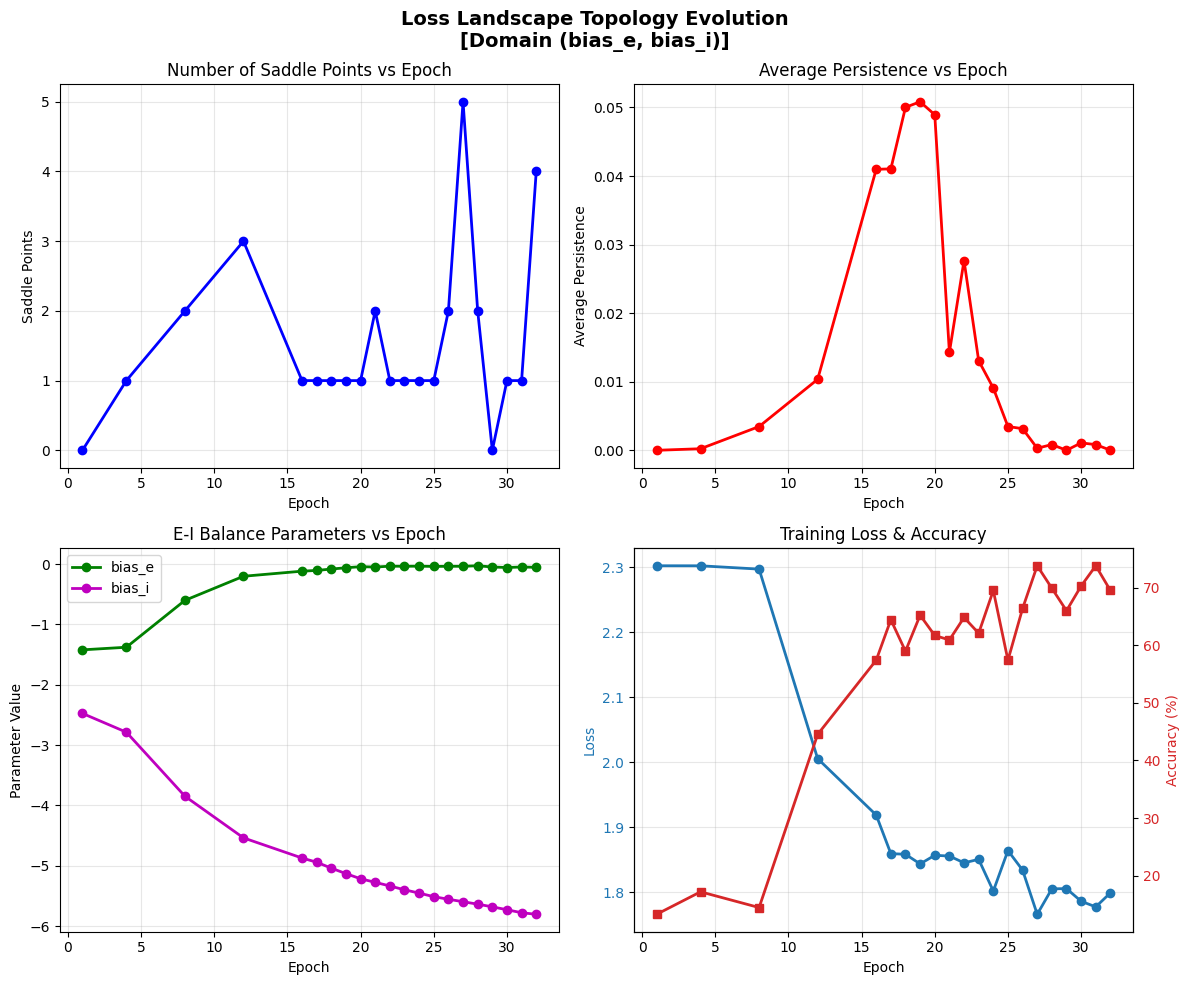


Domain Method Topology Summary:
  Epochs tracked: 21
  Saddle points: min=0, max=5
  Avg persistence: min=0.0000, max=0.0508

Generating HESSIAN topology evolution plot...
Saved topology plot: topology_evolution_hessian_20260331_074848.png
📷 Captured figure 6 -> saved_figures/figure_06_62b7b2bf.png


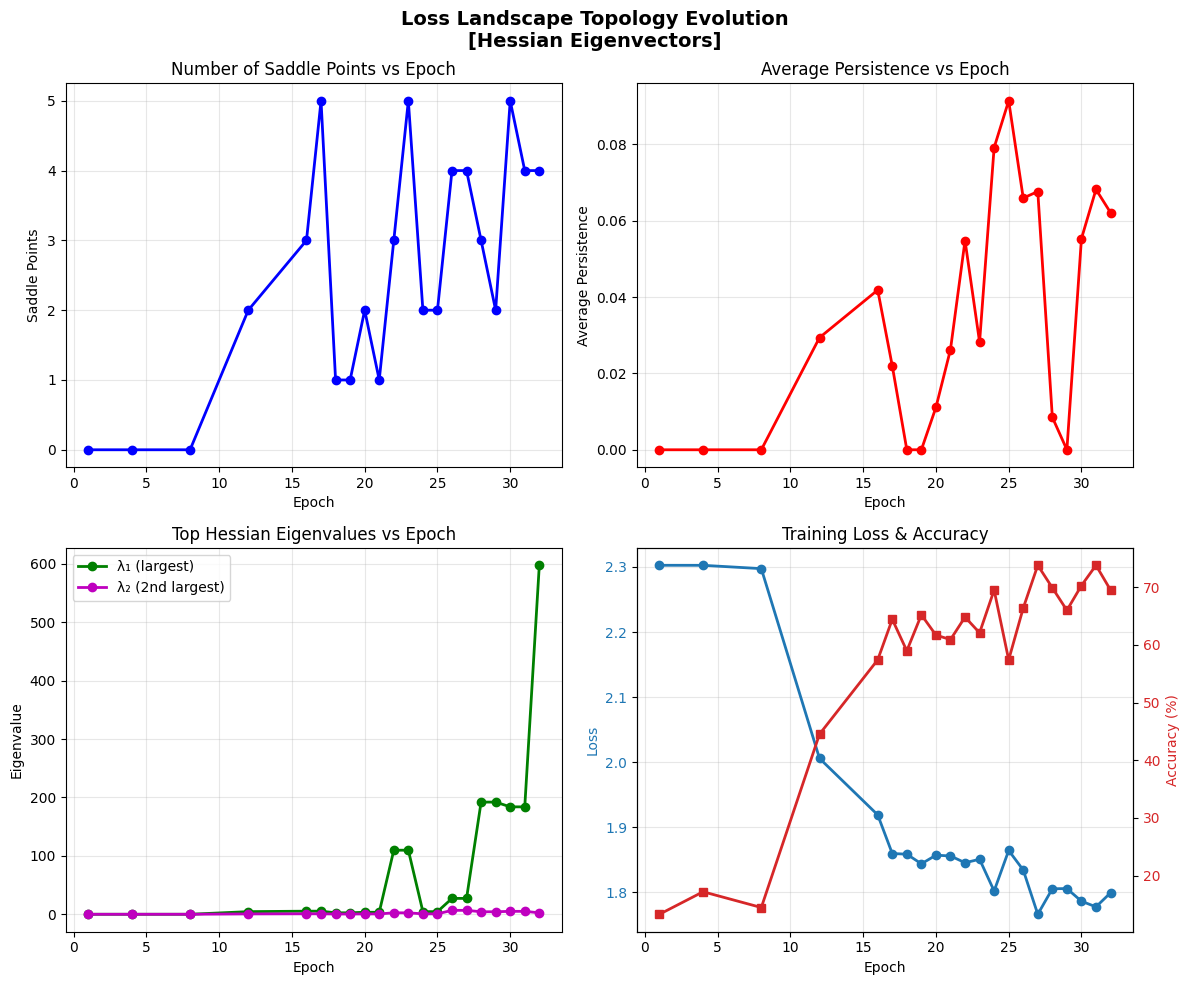


Hessian Method Topology Summary:
  Epochs tracked: 21
  Saddle points: min=0, max=5
  Avg persistence: min=0.0000, max=0.0914

TRAINING COMPLETE!
Final Train Accuracy: 69.53%
Final Test Accuracy: 77.50%
Improvement: 60.00%
Captured final parameter statistics for Word export.

Running H_history evaluation for plotting...
Recorded 4500 H samples for plotting.
Simulation end: 2026-03-31 03:48:56 EDT
Simulation duration (s): 22485.24


In [23]:

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    # @title Train the Model - Supervised Learning

    import numpy as np
    import math

    from datetime import datetime
    from zoneinfo import ZoneInfo

    def _detect_runtime_type():
        """Return a human-readable runtime type string (CPU/GPU + device name when available)."""
        try:
            import torch
            if torch.cuda.is_available():
                try:
                    return f"GPU: {torch.cuda.get_device_name(0)}"
                except Exception:
                    return "GPU"
            return "CPU"
        except Exception:
            return "Unknown"

    eastern = ZoneInfo("America/New_York")
    SIM_START_ET = datetime.now(eastern)
    SIM_START_HUMAN = SIM_START_ET.strftime("%Y-%m-%d %H:%M:%S %Z")
    SIM_RUNTIME_TYPE = _detect_runtime_type()
    print(f"Simulation start: {SIM_START_HUMAN}")
    print(f"Runtime type: {SIM_RUNTIME_TYPE}")

    # ========================================================================
    # v67: Checkpoint System for Resumable Training
    # ========================================================================
    import pickle
    from pathlib import Path
    from datetime import datetime as dt_module

    def save_checkpoint(epoch, results, topology_domain, topology_hessian,
                       save_dir=None,
                       model=None, optimizer=None,
                       network_state=None):           # v81: network activity + generator state
        """Save training checkpoint to Google Drive (v81: full continuity).

        v81 additions vs v76:
          - All four global RNG states saved (PyTorch CPU, PyTorch CUDA, NumPy, Python).
          - DataLoader generator state saved (cell 11: g = torch.Generator()).
          - Network activity state (E/I/O/H tensors + global_train_time_s) saved.
        """
        if save_dir is None:
            save_dir = globals().get('CHECKPOINT_DIR')
            if save_dir is None:
                save_dir = '/content/drive/MyDrive/WC_MNIST_Checkpoints/default_run'
        Path(save_dir).mkdir(parents=True, exist_ok=True)
        topology_domain_dict = topology_domain.to_dict() if hasattr(topology_domain, 'to_dict') else topology_domain
        topology_hessian_dict = topology_hessian.to_dict() if hasattr(topology_hessian, 'to_dict') else topology_hessian

        # v81: Capture all RNG states
        import random as _random
        _rng_states = {
            'torch_cpu': torch.random.get_rng_state(),
            'numpy':     np.random.get_state(),
            'python':    _random.getstate(),
        }
        if torch.cuda.is_available():
            _rng_states['torch_cuda'] = torch.cuda.get_rng_state()

        checkpoint = {
            'epoch': epoch,
            'results': results,
            'topology_domain': topology_domain_dict,
            'topology_hessian': topology_hessian_dict,
            'timestamp': dt_module.now().isoformat(),
            'version': 'v81',
            'notebook_name': globals().get('NOTEBOOK_NAME', 'unknown'),
            'random_seed': globals().get('RANDOM_SEED', None),
            'rng_states': _rng_states,
            'network_state': network_state,
        }

        if model is not None:
            checkpoint['model_state_dict'] = model.state_dict()
        if optimizer is not None:
            checkpoint['optimizer_state_dict'] = optimizer.state_dict()

        checkpoint_path = f"{save_dir}/checkpoint_epoch_{epoch:04d}.pkl"
        try:
            with open(checkpoint_path, 'wb') as f:
                pickle.dump(checkpoint, f)
            file_size_mb = Path(checkpoint_path).stat().st_size / (1024**2)
            print(f"      💾 Checkpoint saved at epoch {epoch}")
            print(f"         📁 {checkpoint_path}")
            print(f"         💿 Size: {file_size_mb:.2f} MB")
            cleanup_old_checkpoints(save_dir, keep_last=3)
        except Exception as e:
            print(f"      ⚠️  WARNING: Failed to save checkpoint: {e}")

    def cleanup_old_checkpoints(save_dir, keep_last=3):
        """Keep only the N most recent checkpoints to save Google Drive space (v69)."""
        checkpoint_dir = Path(save_dir)
        if not checkpoint_dir.exists():
            return

        checkpoints = sorted(
            checkpoint_dir.glob('checkpoint_epoch_*.pkl'),
            key=lambda p: p.stat().st_mtime,
            reverse=True
        )

        for old_checkpoint in checkpoints[keep_last:]:
            try:
                old_checkpoint.unlink()
                print(f"      🗑️  Deleted old checkpoint: {old_checkpoint.name}")
            except Exception:
                pass

    def load_latest_checkpoint(save_dir=None):
        """Load the most recent checkpoint from Google Drive (v74)."""
        # v70: Use global CHECKPOINT_DIR if save_dir not provided
        if save_dir is None:
            save_dir = globals().get('CHECKPOINT_DIR')
            if save_dir is None:
                save_dir = '/content/drive/MyDrive/WC_MNIST_Checkpoints/default_run'

        checkpoint_dir = Path(save_dir)
        if not checkpoint_dir.exists():
            print(f"No checkpoint directory at {save_dir}")
            return None
        checkpoints = list(checkpoint_dir.glob('checkpoint_epoch_*.pkl'))
        if not checkpoints:
            print(f"No checkpoints found in {save_dir}")
            return None
        latest = max(checkpoints, key=lambda p: p.stat().st_mtime)

        try:
            with open(latest, 'rb') as f:
                checkpoint = pickle.load(f)
            print(f"\n{'='*60}")
            print(f"  🔄 RESUMING FROM CHECKPOINT")
            print(f"  Epoch: {checkpoint['epoch']} | Saved: {checkpoint.get('timestamp', 'unknown')[:19]}")
            print(f"  File: {latest.name}")
            print(f"  Version: {checkpoint.get('version', 'unknown')}")
            print(f"{'='*60}\n")
            return checkpoint
        except Exception as e:
            print(f"❌ Error loading checkpoint: {e}")
            return None


    # --------------------------------------------------------------------
    # Initialize optimizer and loss function (DIAGNOSTIC + robust guard)
    # --------------------------------------------------------------------
    import torch
    import torch.nn as nn
    import torch.optim as optim

    print("model type:", type(model))

    if not hasattr(model, "named_parameters"):
        raise RuntimeError(
            "Variable `model` does not look like a torch.nn.Module. It may have been overwritten."
        )

    named = list(model.named_parameters())
    print("n named params:", len(named))
    print("first few param names:", [n for n, _ in named[:12]])

    trainable_params = [p for _, p in named if p.requires_grad]
    print("n trainable params:", len(trainable_params))
    print("total trainable numel:", int(sum(p.numel() for p in trainable_params)) if trainable_params else 0)

    if len(trainable_params) == 0:
        raise RuntimeError(
            "No trainable parameters found. Most common causes:\n"
            "  (1) `model` was overwritten (e.g., set to a tensor or function), OR\n"
            "  (2) you edited the class but did not re-run the cell that creates "
            "`model = SparseBigWilsonCowan(..., bias_e_init=BIAS_E_INIT, bias_i_init=BIAS_I_INIT)`, OR\n"
            "  (3) model construction failed earlier.\n"
            "Scroll up for the printed `model type` and parameter-name preview."
        )


    optimizer = optim.Adam(trainable_params, lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()


    # Containers for evaluation-phase trajectories (for visualization)
    # (In v15, we keep only the raw post-training evaluation trajectory; per-epoch
    #  slices are no longer used.)

    # Containers for training-phase activity (for heatmaps / viewers)
    train_view_E_per_epoch = []
    train_view_I_per_epoch = []
    train_view_t_per_epoch = []

    # v62: Containers for H mean/std per epoch (for H dynamics plots)
    train_view_H_mean_per_epoch = []
    train_view_H_std_per_epoch = []

    # Track training and evaluation history
    train_losses = []
    train_accuracies = []
    test_losses = []
    test_accuracies = []
    val_losses = []
    val_accuracies = []

    # Track bias evolution across epochs
    bias_e_per_epoch = []
    bias_i_per_epoch = []

    # Track time-constant evolution across epochs (taus are per-unit vectors; we log mean/std)
    tauPy_mean_per_epoch = []
    tauPy_std_per_epoch = []
    tauInh_mean_per_epoch = []
    tauInh_std_per_epoch = []
    tauOut_mean_per_epoch = []
    tauOut_std_per_epoch = []

    # Backwards-compatible aliases (means)
    tauPy_per_epoch = tauPy_mean_per_epoch
    tauInh_per_epoch = tauInh_mean_per_epoch
    tauOut_per_epoch = tauOut_mean_per_epoch

    # Track connectivity statistics (means and stds) across epochs
    celoc_mean_per_epoch = []
    celoc_std_per_epoch = []
    cerem_mean_per_epoch = []
    cerem_std_per_epoch = []
    celoci_mean_per_epoch = []
    celoci_std_per_epoch = []

    # Track inhibitory-to-excitatory gain statistics (per-neuron)
    inh2py_mean_per_epoch = []
    inh2py_std_per_epoch = []

    # Track MNIST-input and output-layer weight statistics across epochs
    mnist_mean_per_epoch = []
    mnist_std_per_epoch = []
    output_mean_per_epoch = []
    output_std_per_epoch = []

    # Initial continuous states (start from rest)
    E_state = torch.zeros(model.N, device=model.device)
    I_state = torch.zeros(model.N, device=model.device)
    O_state = torch.zeros(model.num_output, device=model.device)

    # v57: Initialize H (slow adaptation) from uniform distribution
    H_INIT_MIN_VAL = float(globals().get("H_INIT_MIN", 0.0))
    H_INIT_MAX_VAL = float(globals().get("H_INIT_MAX", 0.1))
    H_state = torch.empty(model.N, device=model.device).uniform_(H_INIT_MIN_VAL, H_INIT_MAX_VAL)

    # v57: Record initial H statistics
    initial_H_stats = {
        "min": float(H_state.min().item()),
        "max": float(H_state.max().item()),
        "mean": float(H_state.mean().item()),
        "std": float(H_state.std().item()),
    }
    print(f"Initial H stats: min={initial_H_stats['min']:.6f}, max={initial_H_stats['max']:.6f}, mean={initial_H_stats['mean']:.6f}, std={initial_H_stats['std']:.6f}")

    print("=" * 70)
    print("Baseline evaluation on test set before training...")

    # Baseline evaluation before training
    test_loss, test_acc, _, _, _, E_state, I_state, O_state, H_state, _ = evaluate(
        model, test_loader, criterion,
        dt=dt,
        image_duration=IMAGE_DURATION,
        output_average_window=OUTPUT_AVERAGE_WINDOW,
        max_images=EVAL_IMAGES,
        verbose=False,
        E_init=E_state,
        I_init=I_state,
        O_init=O_state,
        H_init=H_state,  # v57: slow adaptation
        pulsed_stimuli=PULSED_STIMULI,
        sequential_row_input=SEQUENTIAL_ROW_INPUT,
        row_duration=ROW_DURATION if SEQUENTIAL_ROW_INPUT else None,
        record_H_history=False,
    )
    print(f"Before training - Test Loss: {test_loss:.4f}, Test Accuracy: {100*test_acc:.2f}%")

    test_losses.append(test_loss)
    baseline_test_loss = float(test_loss)
    baseline_test_acc = float(test_acc)
    test_accuracies.append(test_acc)

    # --- Training loop (no evaluation phases during training) ---

    TRAIN_HEATMAP_WINDOW = 10.0  # seconds of E activity to keep per epoch
    max_steps_window = int(TRAIN_HEATMAP_WINDOW / dt)

    # Global training-time counter (seconds since start of training)
    global_train_time_s = 0.0

    # --------------------------------------------------------------------
    # v52: Record INITIAL (epoch 0) values BEFORE training begins
    # --------------------------------------------------------------------
    bias_e_per_epoch.append(model.bias_e.item())
    bias_i_per_epoch.append(model.bias_i.item())

    with torch.no_grad():
        tauPy_mean_per_epoch.append(float(model.tauPy_eff.detach().mean().cpu().item()))
        tauPy_std_per_epoch.append(float(model.tauPy_eff.detach().std(unbiased=False).cpu().item()))
        tauInh_mean_per_epoch.append(float(model.tauInh_eff.detach().mean().cpu().item()))
        tauInh_std_per_epoch.append(float(model.tauInh_eff.detach().std(unbiased=False).cpu().item()))
        tauOut_mean_per_epoch.append(float(model.tauOut_eff.detach().mean().cpu().item()))
        tauOut_std_per_epoch.append(float(model.tauOut_eff.detach().std(unbiased=False).cpu().item()))

        celoc_vals = model.CeLoc_values.detach().cpu().numpy()
        cerem_vals = model.CeRem_values.detach().cpu().numpy()
        celoci_vals = model.CeLocI_values.detach().cpu().numpy()
        celoc_mean_per_epoch.append(float(celoc_vals.mean()))
        celoc_std_per_epoch.append(float(celoc_vals.std()))
        cerem_mean_per_epoch.append(float(cerem_vals.mean()))
        cerem_std_per_epoch.append(float(cerem_vals.std()))
        celoci_mean_per_epoch.append(float(celoci_vals.mean()))
        celoci_std_per_epoch.append(float(celoci_vals.std()))

        inh2py_vals = model.inh_to_exc_gain.detach().cpu().numpy()
        inh2py_mean_per_epoch.append(float(inh2py_vals.mean()))
        inh2py_std_per_epoch.append(float(inh2py_vals.std()))

        mnist_vals = model.mnist_weights.detach().cpu().numpy()
        output_vals = model.output_weights.detach().cpu().numpy()
        mnist_mean_per_epoch.append(float(mnist_vals.mean()))
        mnist_std_per_epoch.append(float(mnist_vals.std()))
        output_mean_per_epoch.append(float(output_vals.mean()))
        output_std_per_epoch.append(float(output_vals.std()))

    print(f"Recorded epoch 0 (initial) values: bias_e={bias_e_per_epoch[0]:.4f}, bias_i={bias_i_per_epoch[0]:.4f}")


    # ========================================================================
    # v67: Load checkpoint and initialize start_epoch
    # ========================================================================
    checkpoint = load_latest_checkpoint()
    if checkpoint is not None:
        start_epoch = checkpoint['epoch'] + 1

        # v69: Restore training history
        results = checkpoint.get('results', {})
        train_losses = results.get('train_losses', [])
        train_accuracies = results.get('train_accuracies', [])
        test_losses = results.get('test_losses', [])
        test_accuracies = results.get('test_accuracies', [])
        val_losses = results.get('val_losses', [])
        val_accuracies = results.get('val_accuracies', [])
        bias_e_per_epoch = results.get('bias_e_per_epoch', [])
        bias_i_per_epoch = results.get('bias_i_per_epoch', [])

        # Restore parameter tracking arrays
        tauPy_mean_per_epoch = results.get('tauPy_mean_per_epoch', [])
        tauPy_std_per_epoch = results.get('tauPy_std_per_epoch', [])
        tauInh_mean_per_epoch = results.get('tauInh_mean_per_epoch', [])
        tauInh_std_per_epoch = results.get('tauInh_std_per_epoch', [])
        tauOut_mean_per_epoch = results.get('tauOut_mean_per_epoch', [])
        tauOut_std_per_epoch = results.get('tauOut_std_per_epoch', [])
        celoc_mean_per_epoch = results.get('celoc_mean_per_epoch', [])
        celoc_std_per_epoch = results.get('celoc_std_per_epoch', [])
        cerem_mean_per_epoch = results.get('cerem_mean_per_epoch', [])
        cerem_std_per_epoch = results.get('cerem_std_per_epoch', [])
        celoci_mean_per_epoch = results.get('celoci_mean_per_epoch', [])
        celoci_std_per_epoch = results.get('celoci_std_per_epoch', [])
        inh2py_mean_per_epoch = results.get('inh2py_mean_per_epoch', [])
        inh2py_std_per_epoch = results.get('inh2py_std_per_epoch', [])
        mnist_mean_per_epoch = results.get('mnist_mean_per_epoch', [])
        mnist_std_per_epoch = results.get('mnist_std_per_epoch', [])
        output_mean_per_epoch = results.get('output_mean_per_epoch', [])
        output_std_per_epoch = results.get('output_std_per_epoch', [])

        # Restore training view arrays
        train_view_E_per_epoch = results.get('train_view_E_per_epoch', [])
        train_view_I_per_epoch = results.get('train_view_I_per_epoch', [])
        train_view_t_per_epoch = results.get('train_view_t_per_epoch', [])
        train_view_H_mean_per_epoch = results.get('train_view_H_mean_per_epoch', [])
        train_view_H_std_per_epoch = results.get('train_view_H_std_per_epoch', [])

        # Restore model state
        if 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
            print("  ✓ Model state restored")

        # Restore optimizer state
        if 'optimizer_state_dict' in checkpoint:
            optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            print("  ✓ Optimizer state restored")

        # v81: Restore global RNG states
        import random as _random
        _rng_states = checkpoint.get('rng_states', None)
        if _rng_states is not None:
            torch.random.set_rng_state(_rng_states['torch_cpu'])
            np.random.set_state(_rng_states['numpy'])
            _random.setstate(_rng_states['python'])
            if 'torch_cuda' in _rng_states and torch.cuda.is_available():
                torch.cuda.set_rng_state(_rng_states['torch_cuda'])
            print("  ✓ Global RNG states restored (torch CPU/CUDA, NumPy, Python)")
        else:
            print("  ⚠️  No RNG state in checkpoint (pre-v81). "
                  "Resumed run may diverge from a continuous run.")

        # v81: Restore network activity state and DataLoader generator
        _net_state = checkpoint.get('network_state', None)
        if _net_state is not None:
            E_state             = _net_state['E_state'].to(model.device)
            I_state             = _net_state['I_state'].to(model.device)
            O_state             = _net_state['O_state'].to(model.device)
            H_state             = _net_state['H_state'].to(model.device)
            global_train_time_s = _net_state['global_train_time_s']
            # Restore DataLoader generator (g, from cell 11); separate from global torch RNG
            _dl_gen = _net_state.get('dl_generator_state', None)
            if _dl_gen is not None and 'g' in globals():
                g.set_state(_dl_gen)
                print("  ✓ Network state (E/I/O/H, global_train_time_s, DataLoader generator) restored")
            else:
                print("  ✓ Network state (E/I/O/H, global_train_time_s) restored")
                if _dl_gen is None:
                    print("  ⚠️  No DataLoader generator state (pre-v81).")
        else:
            print("  ⚠️  No network state in checkpoint (pre-v81). "
                  "E/I/O/H reset to zero; global_train_time_s reset to 0.0.")
            E_state             = torch.zeros(model.N,          device=model.device)
            I_state             = torch.zeros(model.N,          device=model.device)
            O_state             = torch.zeros(model.num_output, device=model.device)
            H_state             = torch.zeros(model.N,          device=model.device)
            global_train_time_s = 0.0

        # v76: Restore topology tracker state from checkpoint
        if 'topology_tracker_domain' in globals() and 'topology_tracker_hessian' in globals():
            topo_domain_data = checkpoint.get('topology_domain', None)
            topo_hessian_data = checkpoint.get('topology_hessian', None)

            # Handle both v76 dict format and legacy v75 pickled-object format
            if isinstance(topo_domain_data, dict):
                topology_tracker_domain = TopologyTracker.from_dict(topo_domain_data, TOPOLOGY_CONFIG)
                print(f"  ✓ Domain topology tracker restored ({len(topology_tracker_domain.epochs)} epochs)")
            elif hasattr(topo_domain_data, 'epochs'):
                # Legacy v75: raw TopologyTracker object was pickled directly
                topology_tracker_domain = topo_domain_data
                print(f"  ✓ Domain topology tracker restored from legacy format ({len(topology_tracker_domain.epochs)} epochs)")

            if isinstance(topo_hessian_data, dict):
                topology_tracker_hessian = TopologyTracker.from_dict(topo_hessian_data, TOPOLOGY_CONFIG)
                print(f"  ✓ Hessian topology tracker restored ({len(topology_tracker_hessian.epochs)} epochs)")
            elif hasattr(topo_hessian_data, 'epochs'):
                topology_tracker_hessian = topo_hessian_data
                print(f"  ✓ Hessian topology tracker restored from legacy format ({len(topology_tracker_hessian.epochs)} epochs)")

        print(f"\n📍 Resuming from epoch {start_epoch}\n")
    else:
        start_epoch = 0
        print(f"\n📍 Starting fresh from epoch 0\n")

    for epoch in range(start_epoch, NUM_EPOCHS):
        print("\n" + "=" * 70)
        print(f"Starting epoch {epoch + 1}/{NUM_EPOCHS}...")

        model.train()
        total_loss = 0.0
        total_correct = 0
        total_images = 0

        # Buffers to store last TRAIN_HEATMAP_WINDOW seconds of activity
        epoch_E_buffer = []
        epoch_I_buffer = []
        epoch_t_buffer = []

        # v62: Buffers for H mean/std (same window as E/I)
        epoch_H_mean_buffer = []
        epoch_H_std_buffer = []

        def activity_callback(t, E_snapshot, I_snapshot, H_snapshot=None):
            # Keep only the last max_steps_window frames (last TRAIN_HEATMAP_WINDOW seconds)
            epoch_E_buffer.append(E_snapshot.detach().cpu().numpy())
            epoch_I_buffer.append(I_snapshot.detach().cpu().numpy())
            epoch_t_buffer.append(float(t))

            # v62: Store H mean/std if H_snapshot provided
            if H_snapshot is not None:
                epoch_H_mean_buffer.append(float(H_snapshot.mean().item()))
                epoch_H_std_buffer.append(float(H_snapshot.std().item()))

            if len(epoch_E_buffer) > max_steps_window:
                epoch_E_buffer.pop(0)
                epoch_I_buffer.pop(0)
                epoch_t_buffer.pop(0)
                if len(epoch_H_mean_buffer) > max_steps_window:
                    epoch_H_mean_buffer.pop(0)
                    epoch_H_std_buffer.pop(0)

        for batch_idx, (data, target) in enumerate(train_loader):
            data = data.to(model.device)
            target = target.to(model.device)

            batch_size = data.size(0)
            for i in range(batch_size):
                if IMAGES_PER_EPOCH is not None and total_images >= IMAGES_PER_EPOCH:
                    break

                mnist_image = data[i].view(-1)
                label = target[i]

                loss, _, correct, E_state, I_state, O_state, H_state = train_one_image(
                    model, mnist_image, label, optimizer, criterion,
                    dt=dt,
                    image_duration=IMAGE_DURATION,
                    output_average_window=OUTPUT_AVERAGE_WINDOW,
                    E_init=E_state,
                    I_init=I_state,
                    O_init=O_state,
                    H_init=H_state,  # v57: slow adaptation
                    activity_callback=activity_callback,
                    activity_time_offset=global_train_time_s,
                    sequential_row_input=SEQUENTIAL_ROW_INPUT,
                    row_duration=ROW_DURATION if SEQUENTIAL_ROW_INPUT else None,
                )
                # ----------------------------------------------------------------
                # NaN/Inf guard: stop early and print diagnostics if loss becomes non-finite
                # ----------------------------------------------------------------
                try:
                    _loss_float = float(loss)
                except Exception:
                    _loss_float = float(loss.detach().cpu().item()) if hasattr(loss, "detach") else float(loss)

                if not np.isfinite(_loss_float):
                    print("Non-finite loss detected:", loss)
                    with torch.no_grad():
                        print("tauPy min/max:", float(model.tauPy_eff.min().cpu()), float(model.tauPy_eff.max().cpu()))
                        print("tauInh min/max:", float(model.tauInh_eff.min().cpu()), float(model.tauInh_eff.max().cpu()))
                        print("tauOut min/max:", float(model.tauOut_eff.min().cpu()), float(model.tauOut_eff.max().cpu()))
                        print("E_state min/max:", float(E_state.min().cpu()), float(E_state.max().cpu()))
                        print("I_state min/max:", float(I_state.min().cpu()), float(I_state.max().cpu()))
                        print("O_state min/max:", float(O_state.min().cpu()), float(O_state.max().cpu()))
                    raise RuntimeError("Stopping: non-finite loss (NaN/Inf).")
                global_train_time_s += IMAGE_DURATION

                # Optional 1s OFF period after blocks of images (pulsed stimulus mode)
                if PULSED_STIMULI:
                    images_per_block = max(int(round(1.0 / IMAGE_DURATION)), 1)
                    if (total_images + 1) % images_per_block == 0 and (IMAGES_PER_EPOCH is None or (total_images + 1) < IMAGES_PER_EPOCH):
                        off_duration = 1.0  # seconds of no external input
                        num_off_steps = int(off_duration / dt)
                        import torch
                        with torch.no_grad():
                            I_ext_off = torch.zeros(model.N, device=model.device)
                            for _ in range(num_off_steps):
                                E_state, I_state, O_state, H_state = model.step(E_state, I_state, O_state, I_ext_off, dt, H=H_state)
                                global_train_time_s += dt
                                activity_callback(global_train_time_s, E_state, I_state, H_snapshot=H_state)

                total_loss += loss
                total_correct += correct
                total_images += 1

                if IMAGES_PER_EPOCH is not None and total_images >= IMAGES_PER_EPOCH:
                    break

            if (batch_idx + 1) % 10 == 0:
                avg_so_far = total_loss / max(total_images, 1)
                acc_so_far = 100.0 * total_correct / max(total_images, 1)
                print(
                    f"  Batch {batch_idx + 1}/{len(train_loader)}, "
                    f"Images: {total_images}, "
                    f"Loss: {avg_so_far:.4f}, "
                    f"Acc: {acc_so_far:.2f}%"
                )

            if IMAGES_PER_EPOCH is not None and total_images >= IMAGES_PER_EPOCH:
                break

        # Compute epoch metrics
        train_loss = total_loss / max(total_images, 1)
        train_acc = total_correct / max(total_images, 1)

        print(f"\nEpoch {epoch + 1} Training Complete:")
        print(f"  Train Loss: {train_loss:.4f}, Train Accuracy: {100.0 * train_acc:.2f}%")

        train_losses.append(train_loss)
        train_accuracies.append(train_acc)

        # Capture E/I activity buffers for this epoch as ndarrays [T, N]
        if len(epoch_E_buffer) > 0:
            E_epoch_window = np.stack(epoch_E_buffer, axis=0)
        else:
            E_epoch_window = np.zeros((0, model.N), dtype=np.float32)
        if len(epoch_I_buffer) > 0:
            I_epoch_window = np.stack(epoch_I_buffer, axis=0)
        else:
            I_epoch_window = np.zeros((0, model.N), dtype=np.float32)
        train_view_E_per_epoch.append(E_epoch_window)
        train_view_I_per_epoch.append(I_epoch_window)

        # Capture the corresponding absolute training times for this epoch window
        if len(epoch_t_buffer) > 0:
            t_epoch_window = np.array(epoch_t_buffer, dtype=float)
        else:
            t_epoch_window = np.zeros((E_epoch_window.shape[0],), dtype=float)
        train_view_t_per_epoch.append(t_epoch_window)

        # v62: Capture H mean/std for this epoch
        if len(epoch_H_mean_buffer) > 0:
            H_mean_epoch = np.array(epoch_H_mean_buffer, dtype=float)
            H_std_epoch = np.array(epoch_H_std_buffer, dtype=float)
        else:
            H_mean_epoch = np.zeros((E_epoch_window.shape[0],), dtype=float)
            H_std_epoch = np.zeros((E_epoch_window.shape[0],), dtype=float)
        train_view_H_mean_per_epoch.append(H_mean_epoch)
        train_view_H_std_per_epoch.append(H_std_epoch)


        # ================================================================
        # v66: DUAL Topology Analysis (at intervals matching EPOCH_STRIDE_FOR_WORD_FIGS)
        # ================================================================
        if 'topology_tracker_domain' in globals() and 'topology_tracker_hessian' in globals() and 'TOPOLOGY_CONFIG' in globals():
            track_interval = TOPOLOGY_CONFIG.get('track_interval', 10)
            # v79: Track at epoch 0, every track_interval epochs, AND every
            # epoch once epoch+1 >= transition_epoch (dense window at onset)
            transition_epoch = TOPOLOGY_CONFIG.get('transition_epoch', 9999)
            if epoch == 0 or (epoch + 1) % track_interval == 0 or (epoch + 1) >= transition_epoch:
                current_loss = total_loss / max(total_images, 1)
                current_acc = 100.0 * total_correct / max(total_images, 1)

                # Record DOMAIN method topology
                topology_tracker_domain.record(
                    epoch=epoch + 1,
                    model=model,
                    criterion=criterion,
                    data_loader=train_loader,
                    device=model.device,
                    current_train_loss=current_loss,
                    current_train_acc=current_acc
                )

                # Record HESSIAN method topology
                topology_tracker_hessian.record(
                    epoch=epoch + 1,
                    model=model,
                    criterion=criterion,
                    data_loader=train_loader,
                    device=model.device,
                    current_train_loss=current_loss,
                    current_train_acc=current_acc
                )

        # v69/v79: Save checkpoint after topology analysis
        if 'TOPOLOGY_CONFIG' in globals():
            _topo_transition = TOPOLOGY_CONFIG.get('transition_epoch', 9999)
            _save_this_epoch = (
                (epoch + 1) % TOPOLOGY_CONFIG['track_interval'] == 0
                or (epoch + 1) >= _topo_transition
            )
        else:
            _save_this_epoch = False
        if _save_this_epoch:
            print("\n      Saving checkpoint to Google Drive...")

            # Gather all training state
            results_dict = {
                'train_losses': train_losses,
                'train_accuracies': train_accuracies,
                'test_losses': test_losses,
                'test_accuracies': test_accuracies,
                'val_losses': val_losses,
                'val_accuracies': val_accuracies,
                'bias_e_per_epoch': bias_e_per_epoch,
                'bias_i_per_epoch': bias_i_per_epoch,
                'tauPy_mean_per_epoch': tauPy_mean_per_epoch,
                'tauPy_std_per_epoch': tauPy_std_per_epoch,
                'tauInh_mean_per_epoch': tauInh_mean_per_epoch,
                'tauInh_std_per_epoch': tauInh_std_per_epoch,
                'tauOut_mean_per_epoch': tauOut_mean_per_epoch,
                'tauOut_std_per_epoch': tauOut_std_per_epoch,
                'celoc_mean_per_epoch': celoc_mean_per_epoch,
                'celoc_std_per_epoch': celoc_std_per_epoch,
                'cerem_mean_per_epoch': cerem_mean_per_epoch,
                'cerem_std_per_epoch': cerem_std_per_epoch,
                'celoci_mean_per_epoch': celoci_mean_per_epoch,
                'celoci_std_per_epoch': celoci_std_per_epoch,
                'inh2py_mean_per_epoch': inh2py_mean_per_epoch,
                'inh2py_std_per_epoch': inh2py_std_per_epoch,
                'mnist_mean_per_epoch': mnist_mean_per_epoch,
                'mnist_std_per_epoch': mnist_std_per_epoch,
                'output_mean_per_epoch': output_mean_per_epoch,
                'output_std_per_epoch': output_std_per_epoch,
                # v69: Training view arrays for heatmaps (can be large, but needed for full restore)
                'train_view_E_per_epoch': train_view_E_per_epoch,
                'train_view_I_per_epoch': train_view_I_per_epoch,
                'train_view_t_per_epoch': train_view_t_per_epoch,
                'train_view_H_mean_per_epoch': train_view_H_mean_per_epoch,
                'train_view_H_std_per_epoch': train_view_H_std_per_epoch,
            }

            # v81: Pack network state AFTER validation so resume starts
            # from the exact state that feeds into the next training epoch.
            # dl_generator_state captures g (DataLoader generator, cell 11),
            # which is separate from the global torch RNG.
            _dl_gen_state = g.get_state() if 'g' in globals() else None
            _ns = {
                'E_state':             E_state.detach().cpu(),
                'I_state':             I_state.detach().cpu(),
                'O_state':             O_state.detach().cpu(),
                'H_state':             H_state.detach().cpu(),
                'global_train_time_s': global_train_time_s,
                'dl_generator_state':  _dl_gen_state,
            }
            save_checkpoint(
                epoch=epoch,
                results=results_dict,
                topology_domain=topology_tracker_domain,
                topology_hessian=topology_tracker_hessian,
                model=model,
                optimizer=optimizer,
                network_state=_ns,                          # v81
            )

        # Record bias values after this epoch
        bias_e_per_epoch.append(model.bias_e.item())
        bias_i_per_epoch.append(model.bias_i.item())

        # Record effective tau values after this epoch
        with torch.no_grad():
            tauPy_mean_per_epoch.append(float(model.tauPy_eff.detach().mean().cpu().item()))
            tauPy_std_per_epoch.append(float(model.tauPy_eff.detach().std(unbiased=False).cpu().item()))
            tauInh_mean_per_epoch.append(float(model.tauInh_eff.detach().mean().cpu().item()))
            tauInh_std_per_epoch.append(float(model.tauInh_eff.detach().std(unbiased=False).cpu().item()))
            tauOut_mean_per_epoch.append(float(model.tauOut_eff.detach().mean().cpu().item()))
            tauOut_std_per_epoch.append(float(model.tauOut_eff.detach().std(unbiased=False).cpu().item()))

        # Record connectivity statistics after this epoch
        with torch.no_grad():
            celoc_vals = model.CeLoc_values.detach().cpu().numpy()
            cerem_vals = model.CeRem_values.detach().cpu().numpy()
            celoci_vals = model.CeLocI_values.detach().cpu().numpy()

            celoc_mean_per_epoch.append(float(celoc_vals.mean()))
            celoc_std_per_epoch.append(float(celoc_vals.std()))
            cerem_mean_per_epoch.append(float(cerem_vals.mean()))
            cerem_std_per_epoch.append(float(cerem_vals.std()))
            celoci_mean_per_epoch.append(float(celoci_vals.mean()))
            celoci_std_per_epoch.append(float(celoci_vals.std()))

            # Inhibitory-to-excitatory gains (per neuron)
            inh_vals = model.inh_to_exc_gain.detach().cpu().numpy()
            inh2py_mean_per_epoch.append(float(inh_vals.mean()))
            inh2py_std_per_epoch.append(float(inh_vals.std()))

            # MNIST input weights (per-neuron)
            mnist_vals = model.mnist_weights.detach().cpu().numpy()
            mnist_mean_per_epoch.append(float(mnist_vals.mean()))
            mnist_std_per_epoch.append(float(mnist_vals.std()))

            # Output layer weights
            output_vals = model.output_weights.detach().cpu().numpy()
            output_mean_per_epoch.append(float(output_vals.mean()))
            output_std_per_epoch.append(float(output_vals.std()))


        # --- Validation phase on held-out validation set ---
        # Keep the network state continuous: start validation from the last
        # training state (E_state, I_state, O_state) and carry the final
        # validation state forward into the next epoch.
        model.eval()
        val_loss, val_acc, _, _, _, E_state, I_state, O_state, H_state, _ = evaluate(
            model, val_loader, criterion,
            dt=dt,
            image_duration=IMAGE_DURATION,
            output_average_window=OUTPUT_AVERAGE_WINDOW,
            max_images=EVAL_IMAGES,
            verbose=False,
            E_init=E_state,
            I_init=I_state,
            O_init=O_state,
            H_init=H_state,  # v57: slow adaptation
            pulsed_stimuli=PULSED_STIMULI,
            sequential_row_input=SEQUENTIAL_ROW_INPUT,
            row_duration=ROW_DURATION if SEQUENTIAL_ROW_INPUT else None,
            record_H_history=False,
        )
        print(f"  Validation Loss: {val_loss:.4f}, Validation Accuracy: {100.0 * val_acc:.2f}%")

        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

    # --- One final evaluation phase after training ---

    print("\n" + "=" * 70)
    final_train_loss = float(train_losses[-1]) if len(train_losses) > 0 else None
    final_train_acc = float(train_accuracies[-1]) if len(train_accuracies) > 0 else None
    print("Training complete. Running final evaluation on test set...")

    model.eval()
    test_loss, test_acc, _, _, _, E_state, I_state, O_state, H_state, _ = evaluate(
        model, test_loader, criterion,
        dt=dt,
        image_duration=IMAGE_DURATION,
        output_average_window=OUTPUT_AVERAGE_WINDOW,
        max_images=EVAL_IMAGES,
        verbose=False,
        E_init=E_state,
        I_init=I_state,
        O_init=O_state,
        H_init=H_state,  # v57: slow adaptation
        pulsed_stimuli=PULSED_STIMULI,
        sequential_row_input=SEQUENTIAL_ROW_INPUT,
        row_duration=ROW_DURATION if SEQUENTIAL_ROW_INPUT else None,
        record_H_history=False,
    )
    print(f"After training - Test Loss: {test_loss:.4f}, Test Accuracy: {100*test_acc:.2f}%")

    test_losses.append(test_loss)
    test_accuracies.append(test_acc)
    final_test_loss = float(test_loss)
    final_test_acc = float(test_acc)

    # v57: Record final H statistics
    final_H_stats = {
        "min": float(H_state.min().item()),
        "max": float(H_state.max().item()),
        "mean": float(H_state.mean().item()),
        "std": float(H_state.std().item()),
    }


    print(f"Final H stats: min={final_H_stats['min']:.6f}, max={final_H_stats['max']:.6f}, mean={final_H_stats['mean']:.6f}, std={final_H_stats['std']:.6f}")

    # v77: Final checkpoint — capture all epochs even if not on track_interval boundary
    print("\n      Saving final checkpoint to Google Drive...")
    results_dict = {
        'train_losses': train_losses,
        'train_accuracies': train_accuracies,
        'test_losses': test_losses,
        'test_accuracies': test_accuracies,
        'val_losses': val_losses,
        'val_accuracies': val_accuracies,
        'bias_e_per_epoch': bias_e_per_epoch,
        'bias_i_per_epoch': bias_i_per_epoch,
        'tauPy_mean_per_epoch': tauPy_mean_per_epoch,
        'tauPy_std_per_epoch': tauPy_std_per_epoch,
        'tauInh_mean_per_epoch': tauInh_mean_per_epoch,
        'tauInh_std_per_epoch': tauInh_std_per_epoch,
        'tauOut_mean_per_epoch': tauOut_mean_per_epoch,
        'tauOut_std_per_epoch': tauOut_std_per_epoch,
        'celoc_mean_per_epoch': celoc_mean_per_epoch,
        'celoc_std_per_epoch': celoc_std_per_epoch,
        'cerem_mean_per_epoch': cerem_mean_per_epoch,
        'cerem_std_per_epoch': cerem_std_per_epoch,
        'celoci_mean_per_epoch': celoci_mean_per_epoch,
        'celoci_std_per_epoch': celoci_std_per_epoch,
        'inh2py_mean_per_epoch': inh2py_mean_per_epoch,
        'inh2py_std_per_epoch': inh2py_std_per_epoch,
        'mnist_mean_per_epoch': mnist_mean_per_epoch,
        'mnist_std_per_epoch': mnist_std_per_epoch,
        'output_mean_per_epoch': output_mean_per_epoch,
        'output_std_per_epoch': output_std_per_epoch,
        'train_view_E_per_epoch': train_view_E_per_epoch,
        'train_view_I_per_epoch': train_view_I_per_epoch,
        'train_view_t_per_epoch': train_view_t_per_epoch,
        'train_view_H_mean_per_epoch': train_view_H_mean_per_epoch,
        'train_view_H_std_per_epoch': train_view_H_std_per_epoch,
    }
    # v81: Pack final network state for end-of-training checkpoint
    _dl_gen_state_eot = g.get_state() if 'g' in globals() else None
    _ns_eot = {
        'E_state':             E_state.detach().cpu(),
        'I_state':             I_state.detach().cpu(),
        'O_state':             O_state.detach().cpu(),
        'H_state':             H_state.detach().cpu(),
        'global_train_time_s': global_train_time_s,
        'dl_generator_state':  _dl_gen_state_eot,
    }
    save_checkpoint(
        epoch=NUM_EPOCHS,
        results=results_dict,
        topology_domain=topology_tracker_domain,
        topology_hessian=topology_tracker_hessian,
        model=model,
        optimizer=optimizer,
        network_state=_ns_eot,                         # v81
    )

    # --- Generate a single evaluation-phase trajectory for viewer (no gradients) ---

    print("  Generating evaluation-phase trajectory for viewer...")

    dt_eff = float(dt)
    steps_per_image = int(IMAGE_DURATION / dt_eff)

    # Choose number of test images for a *single* post-training evaluation run
    # used for the LFP plot. We aim for a duration comparable to one training
    # epoch, but never shorter than 10 seconds.
    min_duration = 10.0  # seconds
    if IMAGES_PER_EPOCH is None:
        target_duration = min_duration
    else:
        target_duration = max(min_duration, IMAGES_PER_EPOCH * IMAGE_DURATION)

    num_eval_images = int(math.ceil(target_duration / IMAGE_DURATION))
    num_eval_images = min(num_eval_images, len(mnist_test))

    print(f"  Post-training evaluation duration ~{target_duration:.2f}s, "
          f"using {num_eval_images} test images (IMAGE_DURATION={IMAGE_DURATION:.3f}s)")

    times_eval = []
    E_eval = []
    I_eval = []
    image_times_eval = []

    t = 0.0

    with torch.no_grad():
        E = E_state.clone()
        I = I_state.clone()
        O = O_state.clone()
        H = H_state.clone()  # v60: track H in post-training evaluation

        # Handle sequential row input in post-training trajectory
        if SEQUENTIAL_ROW_INPUT:
            _row_dur = ROW_DURATION if ROW_DURATION else IMAGE_DURATION / 28
            steps_per_row = max(1, int(_row_dur / dt_eff))

        for img_idx in range(num_eval_images):
            mnist_image, label = mnist_test[img_idx]
            mnist_image = mnist_image.view(-1).to(model.device)

            if SEQUENTIAL_ROW_INPUT:
                # Sequential row-by-row presentation
                for step in range(steps_per_image):
                    current_row = min(step // steps_per_row, 27)
                    I_ext = model.compute_mnist_input(mnist_image * MNIST_INPUT_SCALE, active_row=current_row)
                    E, I, O, H = model.step(E, I, O, I_ext, dt_eff, H=H)
                    times_eval.append(t)
                    E_eval.append(E.detach().cpu().numpy())
                    I_eval.append(I.detach().cpu().numpy())
                    t += dt_eff
            else:
                # Original: full image at once
                I_ext = model.compute_mnist_input(mnist_image * MNIST_INPUT_SCALE)
                for step in range(steps_per_image):
                    E, I, O, H = model.step(E, I, O, I_ext, dt_eff, H=H)
                    times_eval.append(t)
                    E_eval.append(E.detach().cpu().numpy())
                    I_eval.append(I.detach().cpu().numpy())
                    t += dt_eff

            image_times_eval.append(t)

    times_eval = np.asarray(times_eval, dtype=float)
    E_eval = np.stack(E_eval, axis=0)
    I_eval = np.stack(I_eval, axis=0)
    image_times_eval = np.asarray(image_times_eval, dtype=float)



    # ================================================================
    # v66: Plot BOTH Topology Evolutions
    # ================================================================
    from datetime import datetime
    topo_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    # Plot DOMAIN method topology
    if 'topology_tracker_domain' in globals() and len(topology_tracker_domain.epochs) > 0:
        print("\n" + "=" * 70)
        print("Generating DOMAIN topology evolution plot...")

        topology_fig_path_domain = f"topology_evolution_domain_{topo_timestamp}.png"
        topology_tracker_domain.plot(save_path=topology_fig_path_domain)

        # Add to saved figures for Word doc
        if 'SAVED_FIG_PATHS' in globals():
            SAVED_FIG_PATHS.append(topology_fig_path_domain)

        # Print summary
        print("\nDomain Method Topology Summary:")
        print(f"  Epochs tracked: {len(topology_tracker_domain.epochs)}")
        print(f"  Saddle points: min={min(topology_tracker_domain.num_saddle_points)}, max={max(topology_tracker_domain.num_saddle_points)}")
        print(f"  Avg persistence: min={min(topology_tracker_domain.avg_persistence):.4f}, max={max(topology_tracker_domain.avg_persistence):.4f}")

    # Plot HESSIAN method topology
    if 'topology_tracker_hessian' in globals() and len(topology_tracker_hessian.epochs) > 0:
        print("\n" + "=" * 70)
        print("Generating HESSIAN topology evolution plot...")

        topology_fig_path_hessian = f"topology_evolution_hessian_{topo_timestamp}.png"
        topology_tracker_hessian.plot(save_path=topology_fig_path_hessian)

        # Add to saved figures for Word doc
        if 'SAVED_FIG_PATHS' in globals():
            SAVED_FIG_PATHS.append(topology_fig_path_hessian)

        # Print summary
        print("\nHessian Method Topology Summary:")
        print(f"  Epochs tracked: {len(topology_tracker_hessian.epochs)}")
        print(f"  Saddle points: min={min(topology_tracker_hessian.num_saddle_points)}, max={max(topology_tracker_hessian.num_saddle_points)}")
        print(f"  Avg persistence: min={min(topology_tracker_hessian.avg_persistence):.4f}, max={max(topology_tracker_hessian.avg_persistence):.4f}")

    print("\n" + "=" * 70)
    print("TRAINING COMPLETE!")
    print("=" * 70)
    print(f"Final Train Accuracy: {100.0 * train_accuracies[-1]:.2f}%")
    print(f"Final Test Accuracy: {100.0 * test_accuracies[-1]:.2f}%")
    print(f"Improvement: {100.0 * (test_accuracies[-1] - test_accuracies[0]):.2f}%")


    # --------------------------------------------------------------------
    # Capture FINAL parameter statistics for Word export
    # --------------------------------------------------------------------
    def summarize_param_tensor(t):
        arr = t.detach().cpu().numpy().ravel()
        return {
            "mean": float(arr.mean()),
            "std": float(arr.std()),
            "min": float(arr.min()),
            "max": float(arr.max()),
        }

    # Robust resolver: learnable_param_names values can be strings or tuple specs,
    # e.g. ("call","tauPy_eff") for properties or ("param_by_name","tauPy_raw") for named parameters.
    param_by_name = dict(model.named_parameters())

    final_param_stats = {}
    for label, spec in learnable_param_names.items():
        if isinstance(spec, tuple):
            kind, name = spec[0], spec[1]
            if kind == "call":
                t = getattr(model, name)
            elif kind == "param_by_name":
                t = param_by_name[name]
            else:
                raise RuntimeError(f"Unknown learnable_param_names spec kind: {kind} for {label}")
        else:
            t = getattr(model, spec)

        final_param_stats[label] = summarize_param_tensor(t)

    print("Captured final parameter statistics for Word export.")
    # v57: Run final evaluation with H_history recording for plotting
    # v61: Use different variable names to avoid overwriting E_eval/I_eval numpy arrays
    print("\nRunning H_history evaluation for plotting...")
    E_init_H_run = torch.zeros(model.N, device=model.device)
    I_init_H_run = torch.zeros(model.N, device=model.device)
    O_init_H_run = torch.zeros(model.num_output, device=model.device)
    H_init_H_run = torch.empty(model.N, device=model.device).uniform_(H_INIT_MIN_VAL, H_INIT_MAX_VAL)

    _, _, _, _, _, _, _, _, _, H_history = evaluate(
        model, test_loader, criterion,
        dt=dt,
        image_duration=IMAGE_DURATION,
        output_average_window=OUTPUT_AVERAGE_WINDOW,
        max_images=min(EVAL_IMAGES, 20),  # Limit for H_history memory
        verbose=False,
        E_init=E_init_H_run,
        I_init=I_init_H_run,
        O_init=O_init_H_run,
        H_init=H_init_H_run,
        pulsed_stimuli=PULSED_STIMULI,
        sequential_row_input=SEQUENTIAL_ROW_INPUT,
        row_duration=ROW_DURATION if SEQUENTIAL_ROW_INPUT else None,
        record_H_history=True,
    )

    if H_history is not None:
        print(f"Recorded {len(H_history['times'])} H samples for plotting.")

    SIM_END_ET = datetime.now(eastern)
    SIM_END_HUMAN = SIM_END_ET.strftime("%Y-%m-%d %H:%M:%S %Z")
    SIM_DURATION_SEC = (SIM_END_ET - SIM_START_ET).total_seconds()
    print(f"Simulation end: {SIM_END_HUMAN}")
    print(f"Simulation duration (s): {SIM_DURATION_SEC:.2f}")


📷 Captured figure 8 -> saved_figures/figure_08_670b6dd9.png


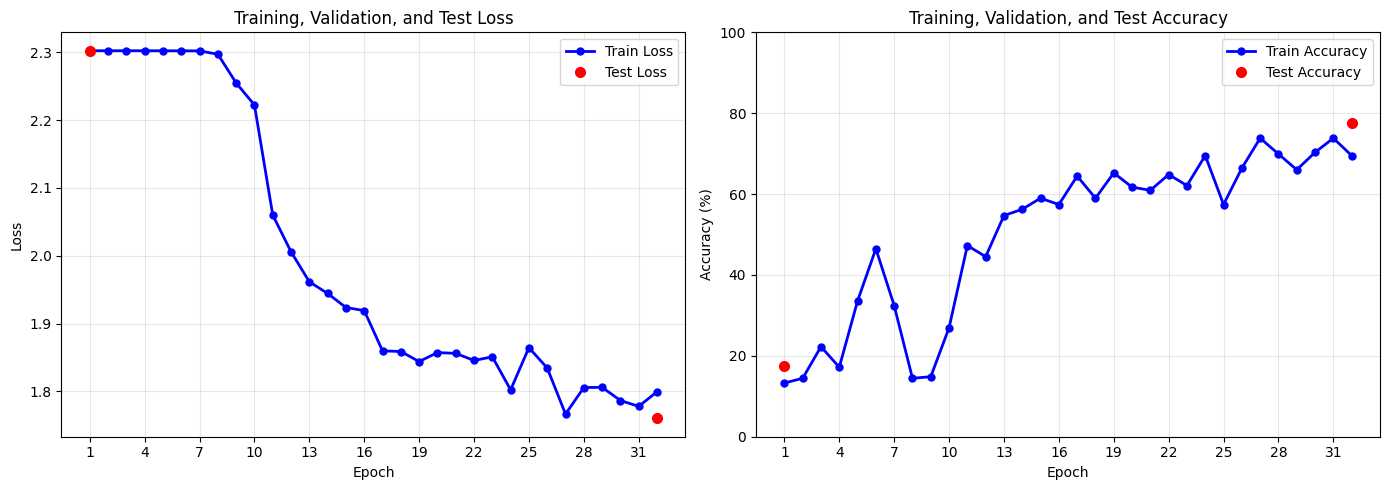

Training Summary:
--------------------------------------------------
Final Train Accuracy: 69.53%
Initial Test Accuracy: 17.50%
Final Test Accuracy: 77.50%
Test Accuracy Improvement: 60.00%
Best Test Accuracy: 77.50% at index 1 (0-based in test_accuracies list)


In [24]:
# @title Visualize Training Progress

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import math
    import matplotlib.pyplot as plt

    # Basic safety checks: we always expect training history
    required = ['train_losses', 'train_accuracies']
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError(
            "Training history not found. Missing: " + ", ".join(missing) +
            ". Run the training cell before visualizing progress."
        )

    n_epochs = len(train_losses)
    if n_epochs == 0:
        raise RuntimeError("No training epochs recorded; nothing to plot.")

    # Epoch indices for training curves (1..n_epochs)
    epochs = np.arange(1, n_epochs + 1)

    # Optional validation and test histories
    has_val = (
        'val_losses' in globals()
        and 'val_accuracies' in globals()
        and len(val_losses) == n_epochs
        and len(val_accuracies) == n_epochs
    )

    has_test = (
        'test_losses' in globals()
        and 'test_accuracies' in globals()
        and len(test_losses) > 0
        and len(test_accuracies) == len(test_losses)
    )

    # Build x-axis for (sparse) test metrics
    if has_test:
        n_test_points = len(test_losses)
        if n_test_points == 1:
            test_epoch_x = np.array([n_epochs], dtype=float)
        else:
            test_epoch_x = np.linspace(1, n_epochs, n_test_points)
    else:
        test_epoch_x = np.array([])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ------------------------------------------------------------------
    # Loss curves
    # ------------------------------------------------------------------
    axes[0].plot(
        epochs,
        train_losses,
        'b-o',
        label='Train Loss',
        linewidth=2,
        markersize=5,
    )

    if has_val:
        axes[0].plot(
            epochs,
            val_losses,
            'g-o',
            label='Validation Loss',
            linewidth=2,
            markersize=5,
        )

    if has_test:
        axes[0].plot(
            test_epoch_x,
            test_losses,
            'ro',
            label='Test Loss',
            markersize=7,
        )

    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training, Validation, and Test Loss' if (has_val or has_test) else 'Training Loss')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # ------------------------------------------------------------------
    # Accuracy curves
    # ------------------------------------------------------------------
    axes[1].plot(
        epochs,
        [100.0 * acc for acc in train_accuracies],
        'b-o',
        label='Train Accuracy',
        linewidth=2,
        markersize=5,
    )

    if has_val:
        axes[1].plot(
            epochs,
            [100.0 * acc for acc in val_accuracies],
            'g-o',
            label='Validation Accuracy',
            linewidth=2,
            markersize=5,
        )

    if has_test:
        axes[1].plot(
            test_epoch_x,
            [100.0 * acc for acc in test_accuracies],
            'ro',
            label='Test Accuracy',
            markersize=7,
        )

    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Training, Validation, and Test Accuracy' if (has_val or has_test) else 'Training Accuracy')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    axes[1].set_ylim([0, 100])

    # ------------------------------------------------------------------
    # Improve x-axis labeling for both panels
    # ------------------------------------------------------------------
    max_ticks = 12
    if n_epochs <= max_ticks:
        xticks = epochs
    else:
        step = int(math.ceil(n_epochs / max_ticks))
        xticks = epochs[::step]

    for ax in axes:
        ax.set_xticks(xticks)
        ax.set_xticklabels([str(int(e)) for e in xticks])

    plt.tight_layout()
    plt.show()

    # Print summary statistics
    print("Training Summary:")
    print("-" * 50)
    print(f"Final Train Accuracy: {100 * train_accuracies[-1]:.2f}%")

    if has_val:
        print(f"Final Validation Accuracy: {100 * val_accuracies[-1]:.2f}%")
        best_val_epoch = 1 + int(np.argmax(val_accuracies))
        print(f"Best Validation Accuracy: {100 * max(val_accuracies):.2f}% at epoch {best_val_epoch}")

    if has_test:
        print(f"Initial Test Accuracy: {100 * test_accuracies[0]:.2f}%")
        if len(test_accuracies) >= 2:
            print(f"Final Test Accuracy: {100 * test_accuracies[-1]:.2f}%")
            print(f"Test Accuracy Improvement: {100 * (test_accuracies[-1] - test_accuracies[0]):.2f}%")
            print(f"Best Test Accuracy: {100 * max(test_accuracies):.2f}% at index "
                  f"{np.argmax(test_accuracies)} (0-based in test_accuracies list)")
        else:
            print("Only one test-accuracy measurement recorded.")


LEARNED WEIGHTS ANALYSIS (after training)
📷 Captured figure 9 -> saved_figures/figure_09_caa40063.png


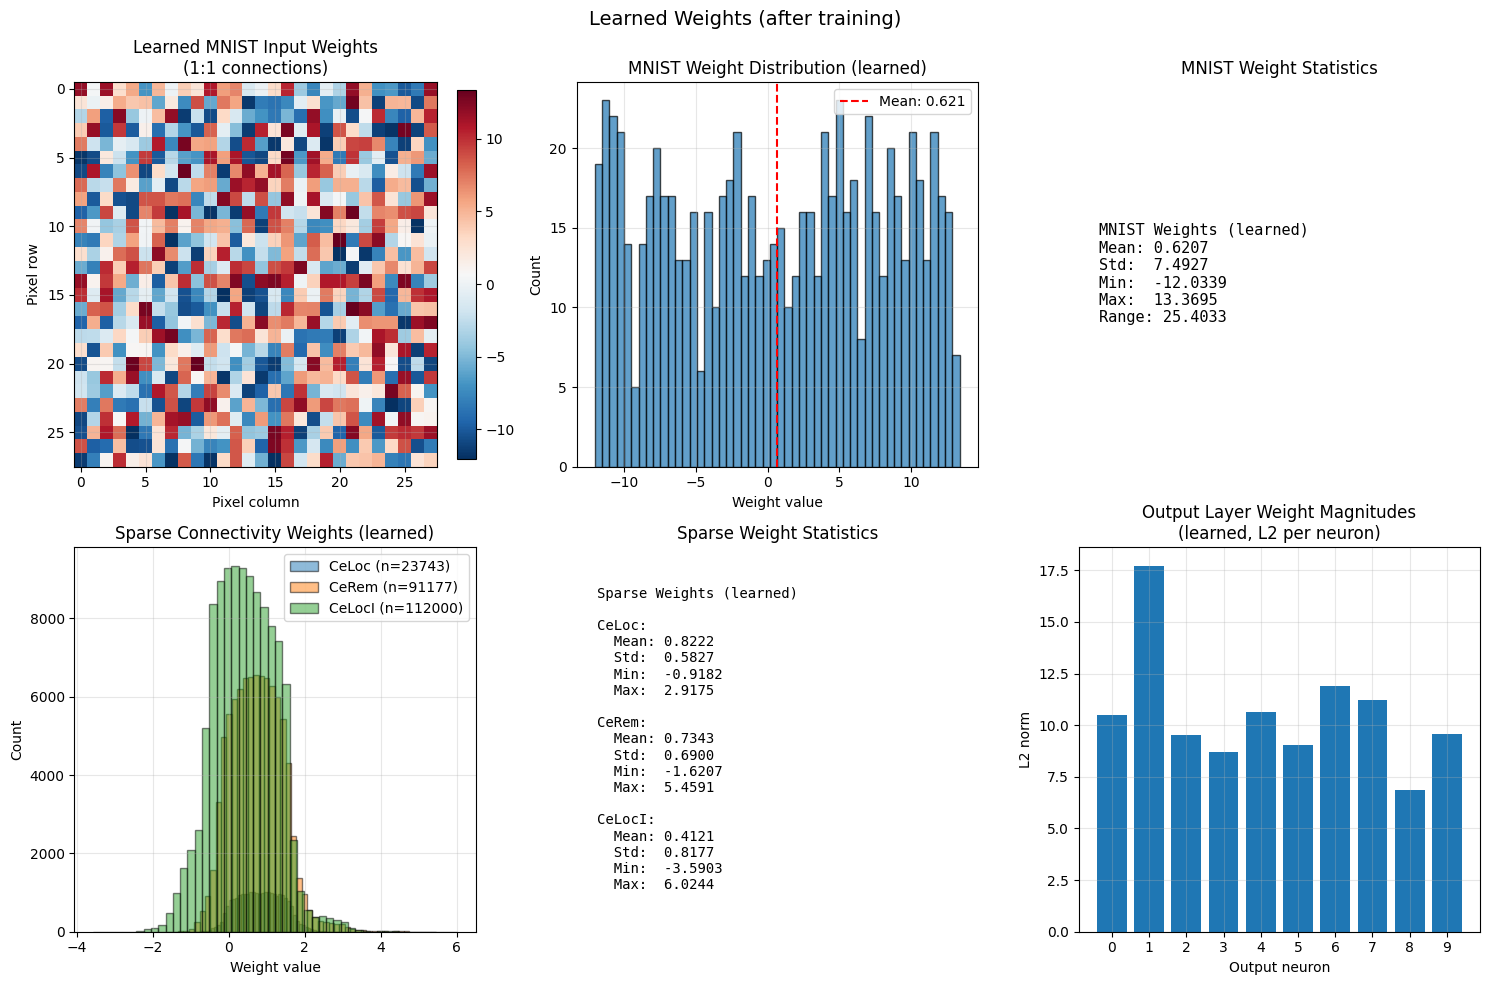

📷 Captured figure 10 -> saved_figures/figure_10_c68b0014.png


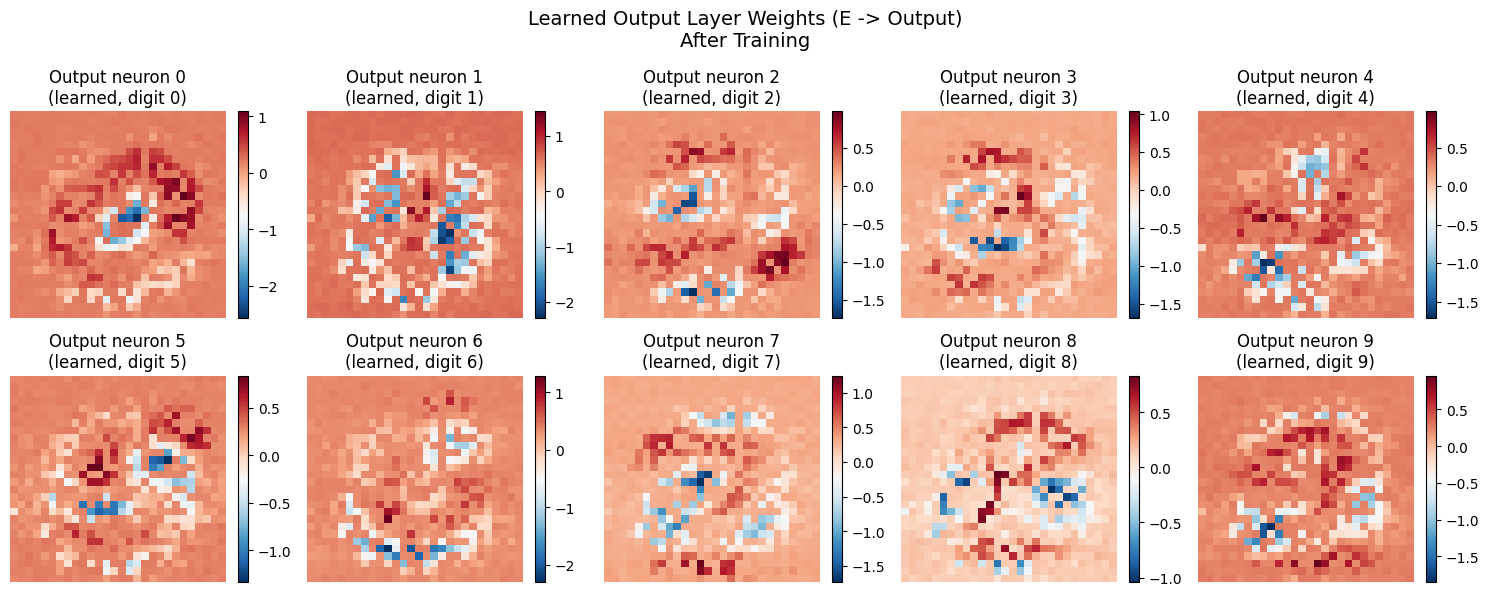


Note: Learned weights should show structure related to digit recognition.
Compare these plots directly with 'Visualize learnable parameters' (before training).


In [25]:
# @title Visualize Learned Weights After Training

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt

    print("="*70)
    print("LEARNED WEIGHTS ANALYSIS (after training)")
    print("="*70)

    # ============================
    # Figure 1: Learned weights in same layout as pre-training
    # ============================

    # --- MNIST input weights (learned) ---
    mnist_weights_learned = model.mnist_weights.detach().cpu().numpy()

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Top-left: spatial 28x28 pattern (if applicable)
    ax = axes[0, 0]
    if mnist_weights_learned.size == 28 * 28:
        im = ax.imshow(mnist_weights_learned.reshape(28, 28), cmap="RdBu_r", aspect="auto")
        ax.set_title("Learned MNIST Input Weights\n(1:1 connections)")
        ax.set_xlabel("Pixel column")
        ax.set_ylabel("Pixel row")
        plt.colorbar(im, ax=ax, fraction=0.046)
    else:
        ax.plot(mnist_weights_learned)
        ax.set_title(f"Learned MNIST Input Weights\n({mnist_weights_learned.size} connections)")
        ax.set_xlabel("Connection index")
        ax.set_ylabel("Weight value")
    ax.grid(alpha=0.3)

    # Top-middle: histogram of learned MNIST input weights
    ax = axes[0, 1]
    ax.hist(mnist_weights_learned, bins=50, edgecolor="black", alpha=0.7)
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    ax.set_title("MNIST Weight Distribution (learned)")
    ax.grid(alpha=0.3)
    ax.axvline(mnist_weights_learned.mean(), color="red", linestyle="--",
               label=f"Mean: {mnist_weights_learned.mean():.3f}")
    ax.legend()

    # Top-right: learned MNIST stats text
    ax = axes[0, 2]
    stats_lines = [
        "MNIST Weights (learned)",
        f"Mean: {mnist_weights_learned.mean():.4f}",
        f"Std:  {mnist_weights_learned.std():.4f}",
        f"Min:  {mnist_weights_learned.min():.4f}",
        f"Max:  {mnist_weights_learned.max():.4f}",
        f"Range: {(mnist_weights_learned.max() - mnist_weights_learned.min()):.4f}",
    ]
    stats_text = "\n".join(stats_lines)
    ax.text(0.05, 0.5, stats_text, fontsize=11, family="monospace",
            va="center", transform=ax.transAxes)
    ax.axis("off")
    ax.set_title("MNIST Weight Statistics")

    # --- Sparse connectivity weights after training ---
    celoc_learned = model.CeLoc_values.detach().cpu().numpy()
    cerem_learned = model.CeRem_values.detach().cpu().numpy()
    celoci_learned = model.CeLocI_values.detach().cpu().numpy()

    ax = axes[1, 0]
    if celoc_learned.size > 0:
        ax.hist(celoc_learned, bins=50, alpha=0.5,
                label=f"CeLoc (n={len(celoc_learned)})", edgecolor="black")
    if cerem_learned.size > 0:
        ax.hist(cerem_learned, bins=50, alpha=0.5,
                label=f"CeRem (n={len(cerem_learned)})", edgecolor="black")
    if celoci_learned.size > 0:
        ax.hist(celoci_learned, bins=50, alpha=0.5,
                label=f"CeLocI (n={len(celoci_learned)})", edgecolor="black")

    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    ax.set_title("Sparse Connectivity Weights (learned)")
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend()
    ax.grid(alpha=0.3)

    # Bottom-middle: sparse stats text
    ax = axes[1, 1]

    def _safe_stats(arr, name):
        if arr.size == 0:
            return f"{name}: (no non-zero entries)"
        return (
            f"{name}:\n"
            f"  Mean: {arr.mean():.4f}\n"
            f"  Std:  {arr.std():.4f}\n"
            f"  Min:  {arr.min():.4f}\n"
            f"  Max:  {arr.max():.4f}"
        )

    sparse_stats_lines = [
        "Sparse Weights (learned)",
        "",
        _safe_stats(celoc_learned, "CeLoc"),
        "",
        _safe_stats(cerem_learned, "CeRem"),
        "",
        _safe_stats(celoci_learned, "CeLocI"),
    ]
    sparse_stats_text = "\n".join(sparse_stats_lines)
    ax.text(0.05, 0.5, sparse_stats_text, fontsize=10, family="monospace",
            va="center", transform=ax.transAxes)
    ax.axis("off")
    ax.set_title("Sparse Weight Statistics")

    # Bottom-right: learned output weight norms per neuron
    output_weights_learned = model.output_weights.detach().cpu().numpy()
    output_norms_learned = np.linalg.norm(output_weights_learned, axis=1)

    ax = axes[1, 2]
    ax.bar(range(output_norms_learned.size), output_norms_learned)
    ax.set_xlabel("Output neuron")
    ax.set_ylabel("L2 norm")
    ax.set_title("Output Layer Weight Magnitudes\n(learned, L2 per neuron)")
    ax.set_xticks(range(output_norms_learned.size))
    ax.grid(alpha=0.3)

    plt.suptitle("Learned Weights (after training)", fontsize=14)
    plt.tight_layout()
    plt.show()

    # ============================
    # Figure 2: Detailed learned output weights (E -> Output)
    # Same layout as pre-training visualization
    # ============================

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    side = int(np.sqrt(model.N))

    for i in range(10):
        ax = axes[i]
        if model.N == side * side:
            weights_2d = output_weights_learned[i].reshape(side, side)
            im = ax.imshow(weights_2d, cmap="RdBu_r", aspect="auto")
            ax.set_title(f"Output neuron {i}\n(learned, digit {i})")
            ax.axis("off")
            plt.colorbar(im, ax=ax, fraction=0.046)
        else:
            ax.plot(output_weights_learned[i])
            ax.set_title(f"Output neuron {i}\n(learned, digit {i})")
            ax.set_xlabel("E neuron")
            ax.grid(alpha=0.3)

    plt.suptitle("Learned Output Layer Weights (E -> Output)\nAfter Training", fontsize=14)
    plt.tight_layout()
    plt.show()

    print("\nNote: Learned weights should show structure related to digit recognition.")
    print("Compare these plots directly with 'Visualize learnable parameters' (before training).")


📷 Captured figure 11 -> saved_figures/figure_11_117fefae.png


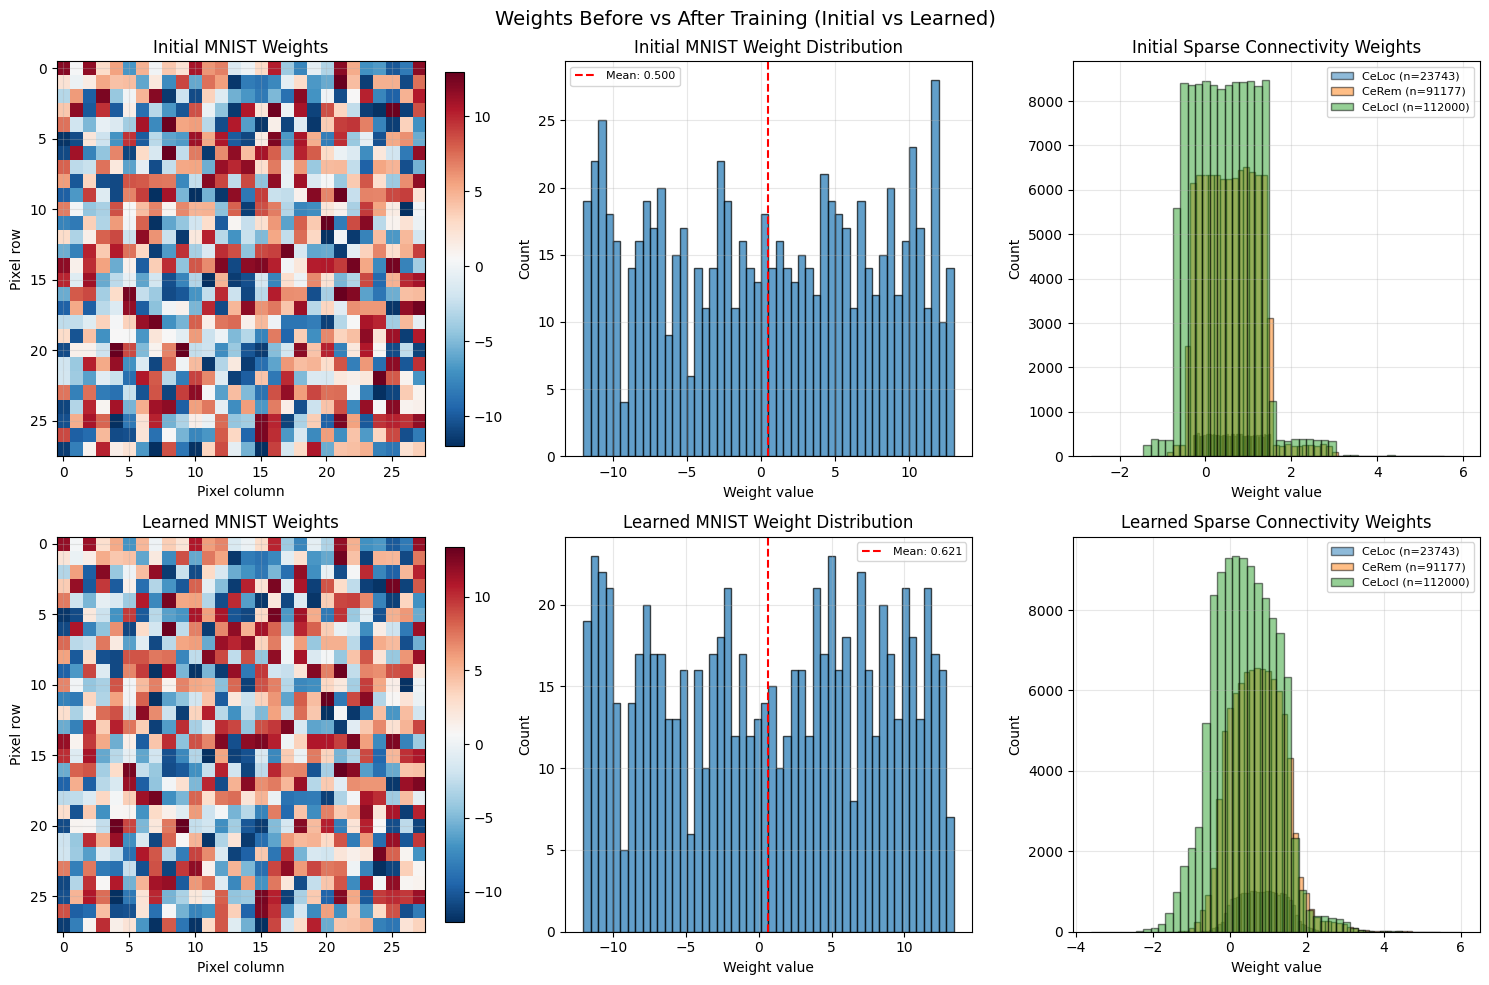

Side-by-side comparison complete.
Top row: initial weights; bottom row: learned weights.


In [26]:
# @title Compare Weights Before and After Training (side-by-side)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt

    # We require that the pre-training visualization cell has been run
    try:
        cache = initial_weight_snapshots
    except NameError as e:
        raise RuntimeError(
            "No cached initial weights found. Run the 'Visualize learnable parameters "
            "(before training)' cell before training, then train the model, and only "
            "then run this comparison cell."
        ) from e

    mnist_init = cache.get("mnist", None)
    celoc_init = cache.get("celoc", None)
    cerem_init = cache.get("cerem", None)
    celoci_init = cache.get("celoci", None)

    if mnist_init is None:
        raise RuntimeError(
            "Cached initial MNIST weights not found in 'initial_weight_snapshots'. "
            "Re-run the pre-training visualization cell before training."
        )

    # Current (learned) weights from the trained model
    mnist_learned = model.mnist_weights.detach().cpu().numpy()
    celoc_learned = model.CeLoc_values.detach().cpu().numpy()
    cerem_learned = model.CeRem_values.detach().cpu().numpy()
    celoci_learned = model.CeLocI_values.detach().cpu().numpy()

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # ---------------- Row 0: INITIAL ----------------

    # Col 0: MNIST spatial pattern, initial
    ax = axes[0, 0]
    if mnist_init.size == 28 * 28:
        im0 = ax.imshow(mnist_init.reshape(28, 28), cmap="RdBu_r", aspect="auto")
        ax.set_title("Initial MNIST Weights")
        ax.set_ylabel("Pixel row")
        ax.set_xlabel("Pixel column")
        plt.colorbar(im0, ax=ax, fraction=0.046)
    else:
        ax.plot(mnist_init)
        ax.set_title("Initial MNIST Weights")
        ax.set_xlabel("Connection index")
        ax.set_ylabel("Weight")
    ax.grid(alpha=0.3)

    # Col 1: MNIST histogram, initial
    ax = axes[0, 1]
    ax.hist(mnist_init, bins=50, edgecolor="black", alpha=0.7)
    ax.set_title("Initial MNIST Weight Distribution")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.3)
    ax.axvline(mnist_init.mean(), color="red", linestyle="--",
               label=f"Mean: {mnist_init.mean():.3f}")
    ax.legend(fontsize=8)

    # Col 2: Sparse connectivity histograms, initial
    ax = axes[0, 2]
    if celoc_init is not None and celoc_init.size > 0:
        ax.hist(celoc_init, bins=50, alpha=0.5,
                label=f"CeLoc (n={celoc_init.size})", edgecolor="black")
    if cerem_init is not None and cerem_init.size > 0:
        ax.hist(cerem_init, bins=50, alpha=0.5,
                label=f"CeRem (n={cerem_init.size})", edgecolor="black")
    if celoci_init is not None and celoci_init.size > 0:
        ax.hist(celoci_init, bins=50, alpha=0.5,
                label=f"CeLocI (n={celoci_init.size})", edgecolor="black")
    ax.set_title("Initial Sparse Connectivity Weights")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # ---------------- Row 1: LEARNED ----------------

    # Col 0: MNIST spatial pattern, learned
    ax = axes[1, 0]
    if mnist_learned.size == 28 * 28:
        im1 = ax.imshow(mnist_learned.reshape(28, 28), cmap="RdBu_r", aspect="auto")
        ax.set_title("Learned MNIST Weights")
        ax.set_ylabel("Pixel row")
        ax.set_xlabel("Pixel column")
        plt.colorbar(im1, ax=ax, fraction=0.046)
    else:
        ax.plot(mnist_learned)
        ax.set_title("Learned MNIST Weights")
        ax.set_xlabel("Connection index")
        ax.set_ylabel("Weight")
    ax.grid(alpha=0.3)

    # Col 1: MNIST histogram, learned
    ax = axes[1, 1]
    ax.hist(mnist_learned, bins=50, edgecolor="black", alpha=0.7)
    ax.set_title("Learned MNIST Weight Distribution")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.3)
    ax.axvline(mnist_learned.mean(), color="red", linestyle="--",
               label=f"Mean: {mnist_learned.mean():.3f}")
    ax.legend(fontsize=8)

    # Col 2: Sparse connectivity histograms, learned
    ax = axes[1, 2]
    if celoc_learned.size > 0:
        ax.hist(celoc_learned, bins=50, alpha=0.5,
                label=f"CeLoc (n={len(celoc_learned)})", edgecolor="black")
    if cerem_learned.size > 0:
        ax.hist(cerem_learned, bins=50, alpha=0.5,
                label=f"CeRem (n={len(cerem_learned)})", edgecolor="black")
    if celoci_learned.size > 0:
        ax.hist(celoci_learned, bins=50, alpha=0.5,
                label=f"CeLocI (n={len(celoci_learned)})", edgecolor="black")
    ax.set_title("Learned Sparse Connectivity Weights")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    plt.suptitle("Weights Before vs After Training (Initial vs Learned)", fontsize=14)
    plt.tight_layout()
    plt.show()

    print("Side-by-side comparison complete.")
    print("Top row: initial weights; bottom row: learned weights.")


In [27]:
# @title Learned Bias Parameters (bias_e and bias_i)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np

    # Require initial/final stats
    if "initial_param_stats" not in globals() or "final_param_stats" not in globals():
        raise RuntimeError("Initial/final parameter statistics not found. "
                           "Run model instantiation and training cells first.")

    init_e = initial_param_stats["bias_e"]
    init_i = initial_param_stats["bias_i"]
    final_e = final_param_stats["bias_e"]
    final_i = final_param_stats["bias_i"]

    init_val_e = init_e["mean"]
    init_val_i = init_i["mean"]
    final_val_e = final_e["mean"]
    final_val_i = final_i["mean"]

    def pct_change(init, final):
        eps = 1e-12
        if abs(init) < eps:
            return float("nan")
        return 100.0 * (final - init) / abs(init)

    pct_e = pct_change(init_val_e, final_val_e)
    pct_i = pct_change(init_val_i, final_val_i)

    print("=" * 70)
    print("LEARNED BIAS PARAMETERS (bias_e and bias_i)")
    print("=" * 70)
    print(f"bias_e: initial mean {init_val_e:.4f}, final mean {final_val_e:.4f}, "
          f"Δ = {final_val_e - init_val_e:+.4f} ({pct_e:+.2f}% change)")
    print(f"bias_i: initial mean {init_val_i:.4f}, final mean {final_val_i:.4f}, "
          f"Δ = {final_val_i - init_val_i:+.4f} ({pct_i:+.2f}% change)")
    print()
    print("Note:")
    print("  • More negative biases make neurons harder to activate (higher effective threshold).")
    print("  • More positive biases make neurons easier to activate (lower effective threshold).")

    # Also summarize inhibitory-to-excitatory gain distribution
    if hasattr(model, 'inh_to_exc_gain'):
        inh_vals = model.inh_to_exc_gain.detach().cpu().numpy()
        print("\n" + "=" * 50)
        print("INHIBITORY-TO-EXCITATORY GAIN SUMMARY (Inh2Py, FINAL)")
        print("=" * 50)
        print(f"Mean: {inh_vals.mean():.4f}, Std: {inh_vals.std():.4f}")
        print(f"Min:  {inh_vals.min():.4f}")
        print(f"Max:  {inh_vals.max():.4f}")
        print()


LEARNED BIAS PARAMETERS (bias_e and bias_i)
bias_e: initial mean -1.4302, final mean -0.0530, Δ = +1.3772 (+96.29% change)
bias_i: initial mean -2.4352, final mean -5.8050, Δ = -3.3698 (-138.38% change)

Note:
  • More negative biases make neurons harder to activate (higher effective threshold).
  • More positive biases make neurons easier to activate (lower effective threshold).

INHIBITORY-TO-EXCITATORY GAIN SUMMARY (Inh2Py, FINAL)
Mean: 24.4153, Std: 7.3372
Min:  11.0061
Max:  36.8361



📷 Captured figure 12 -> saved_figures/figure_12_126a3cdc.png


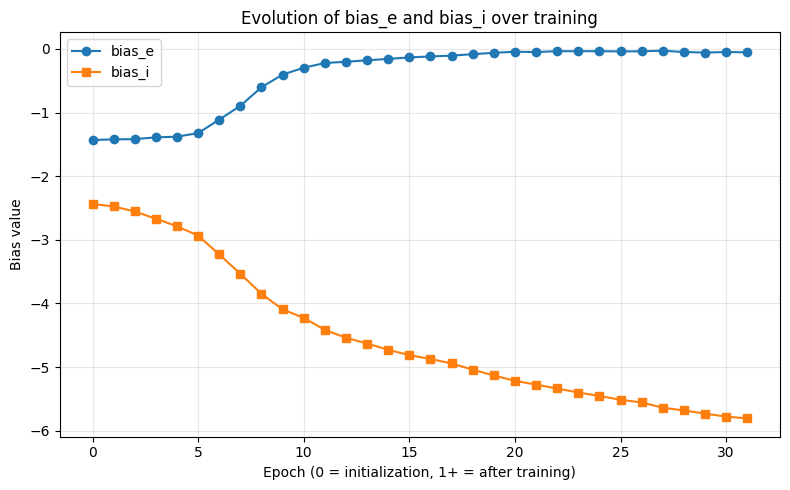

In [28]:

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    # @title Bias evolution over epochs

    import numpy as np
    import matplotlib.pyplot as plt

    try:
        n_epochs = len(bias_e_per_epoch)
    except NameError as e:
        raise RuntimeError(
            "bias_e_per_epoch not found. Run the training cell first so that "
            "bias_e and bias_i are recorded across epochs."
        ) from e

    if n_epochs == 0:
        raise RuntimeError("No bias history recorded. Did training run to completion?")

    # v52: epochs now start from 0 (true initialization) instead of 1
    epochs = np.arange(0, n_epochs)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, bias_e_per_epoch, marker="o", label="bias_e")
    plt.plot(epochs, bias_i_per_epoch, marker="s", label="bias_i")
    plt.xlabel("Epoch (0 = initialization, 1+ = after training)")
    plt.ylabel("Bias value")
    plt.title("Evolution of bias_e and bias_i over training")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


📷 Captured figure 13 -> saved_figures/figure_13_da9fd5ff.png


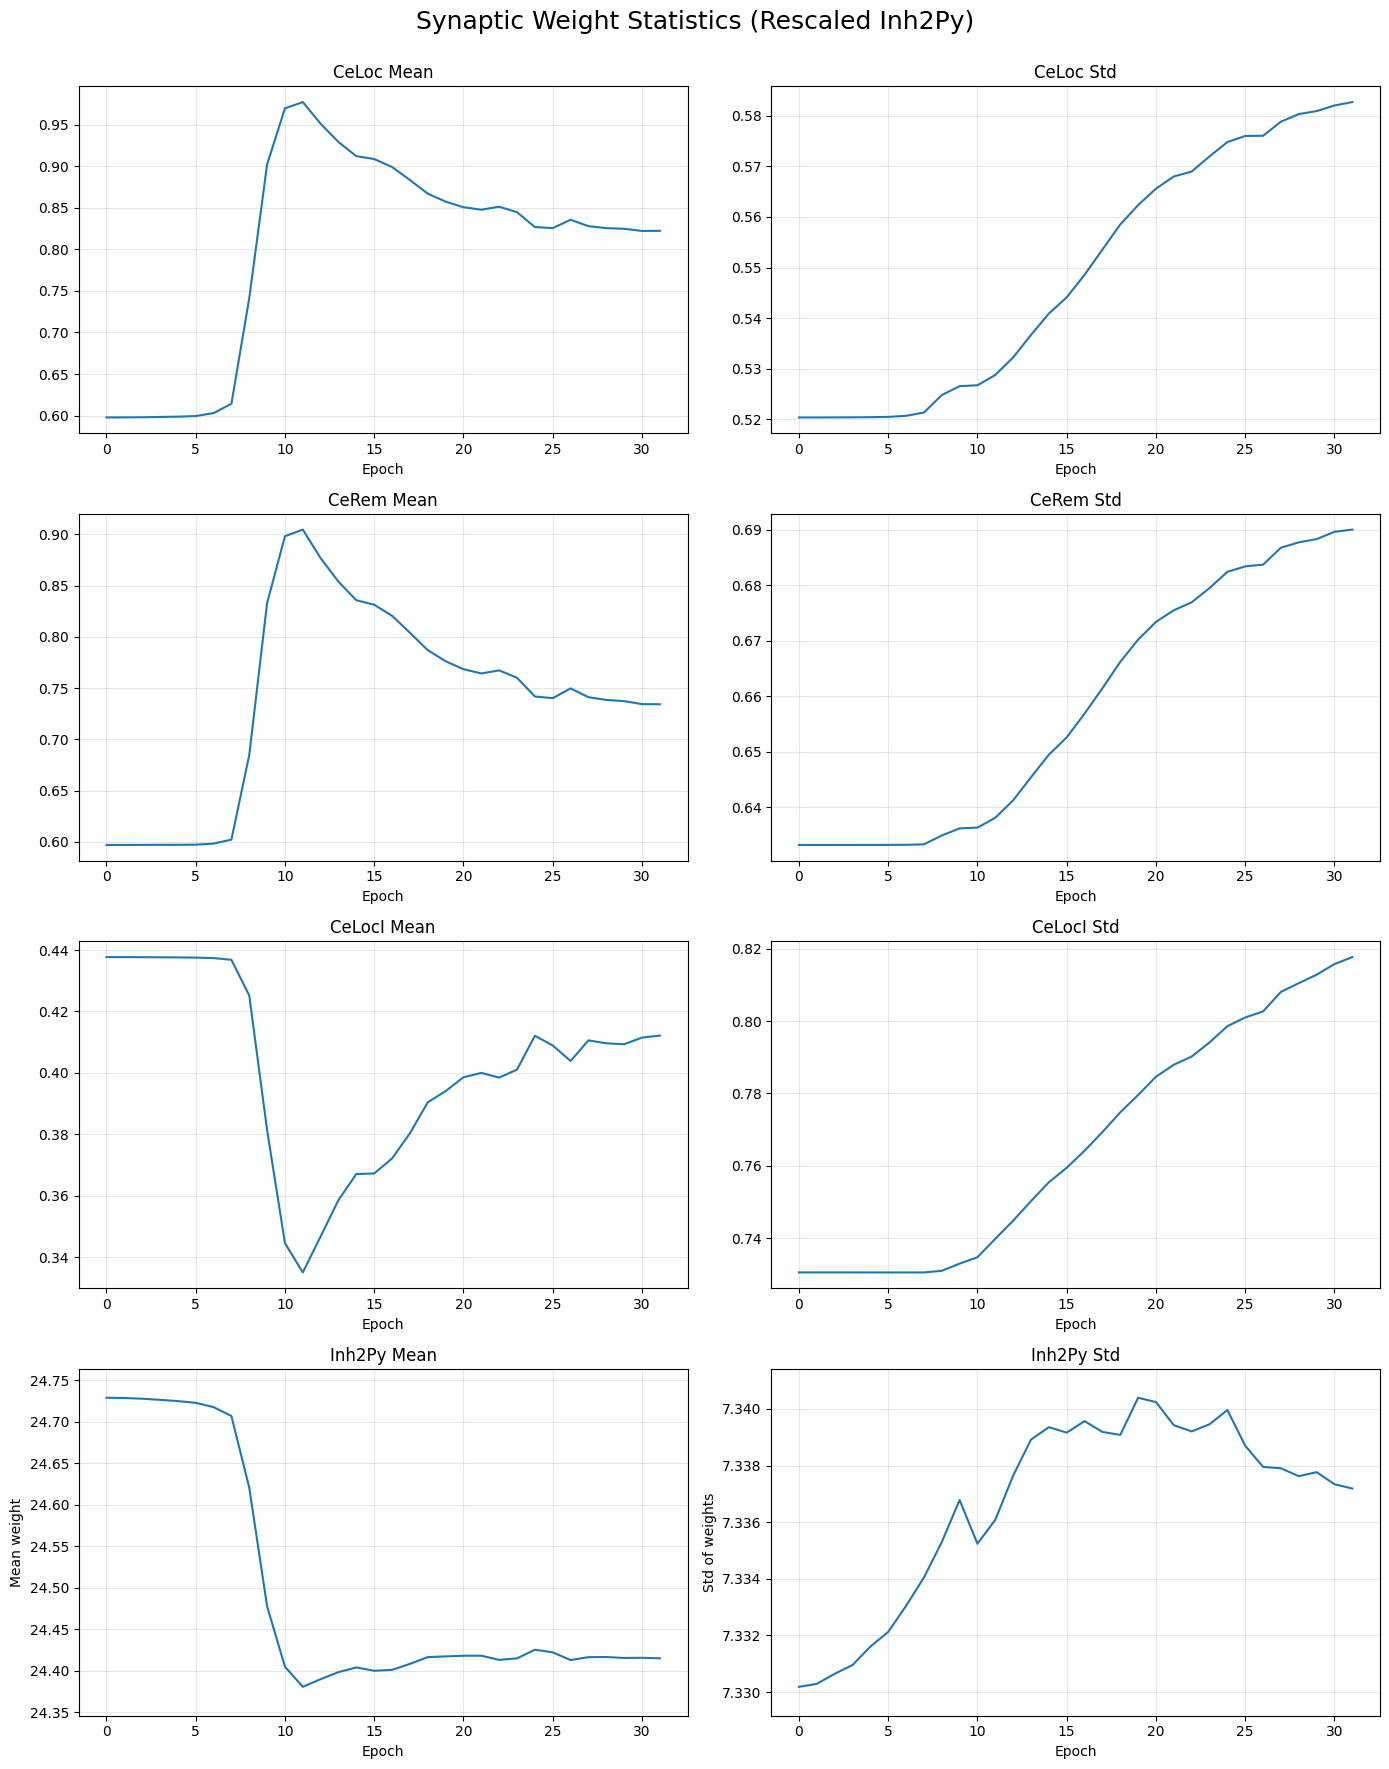

In [29]:
# @title Synaptic weight statistics over training (CeLoc, CeRem, CeLocI, Inh2Py) – rescaled Inh2Py plot

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt

    # Ensure statistics exist
    try:
        n_epochs = len(celoc_mean_per_epoch)
    except NameError as e:
        raise RuntimeError(
            "Connectivity statistics per epoch not found. "
            "Run the training cell first so that celoc_mean_per_epoch, etc., are defined."
        ) from e

    if n_epochs == 0:
        raise RuntimeError("No connectivity history recorded. Did training run to completion?")

    # v52: epochs now start from 0 (true initialization) instead of 1
    epochs = np.arange(0, n_epochs)

    # --- Extract initial Inh2Py values for rescaling ---
    inh2py_initial_mean = inh2py_mean_per_epoch[0]
    inh2py_initial_std  = inh2py_std_per_epoch[0]

    # Rescaled curves
    inh2py_delta_mean = np.array(inh2py_mean_per_epoch) - inh2py_initial_mean
    inh2py_delta_std  = np.array(inh2py_std_per_epoch)  - inh2py_initial_std

    # --- Plotting ---
    fig, axs = plt.subplots(4, 2, figsize=(14, 18))
    fig.suptitle("Synaptic Weight Statistics (Rescaled Inh2Py)", fontsize=18)

    # --------- CeLoc -----------
    axs[0, 0].plot(epochs, celoc_mean_per_epoch, label="CeLoc Mean")
    axs[0, 0].set_title("CeLoc Mean")
    axs[0, 1].plot(epochs, celoc_std_per_epoch, label="CeLoc Std")
    axs[0, 1].set_title("CeLoc Std")

    # --------- CeRem -----------
    axs[1, 0].plot(epochs, cerem_mean_per_epoch, label="CeRem Mean")
    axs[1, 0].set_title("CeRem Mean")
    axs[1, 1].plot(epochs, cerem_std_per_epoch, label="CeRem Std")
    axs[1, 1].set_title("CeRem Std")

    # --------- CeLocI ----------
    axs[2, 0].plot(epochs, celoci_mean_per_epoch, label="CeLocI Mean")
    axs[2, 0].set_title("CeLocI Mean")
    axs[2, 1].plot(epochs, celoci_std_per_epoch, label="CeLocI Std")
    axs[2, 1].set_title("CeLocI Std")

    # --------- Inh2Py (Mean / Std, rescaled axes) ----------
    # We now plot the absolute mean and std of the Inh2Py weights, but
    # rescale the y-axes so that small changes over epochs remain visible.
    inh2py_mean_arr = np.asarray(inh2py_mean_per_epoch, dtype=float)
    inh2py_std_arr  = np.asarray(inh2py_std_per_epoch, dtype=float)

    axs[3, 0].plot(epochs, inh2py_mean_arr)
    axs[3, 0].set_title("Inh2Py Mean")
    axs[3, 0].set_ylabel("Mean weight")

    # Dynamic y-limits to zoom around the observed range of mean values
    if inh2py_mean_arr.size > 0:
        mean_range = float(inh2py_mean_arr.max() - inh2py_mean_arr.min())
        if mean_range == 0:
            # If there is essentially no variation, pad around the mean
            padding = 0.05 * float(abs(inh2py_mean_arr.mean()) if inh2py_mean_arr.mean() != 0 else 1.0)
        else:
            padding = 0.1 * mean_range
        ymin = float(inh2py_mean_arr.min() - padding)
        ymax = float(inh2py_mean_arr.max() + padding)
        if ymin == ymax:
            ymin -= 1e-6
            ymax += 1e-6
        axs[3, 0].set_ylim(ymin, ymax)

    axs[3, 1].plot(epochs, inh2py_std_arr)
    axs[3, 1].set_title("Inh2Py Std")
    axs[3, 1].set_ylabel("Std of weights")

    # Dynamic y-limits for std as well
    if inh2py_std_arr.size > 0:
        std_range = float(inh2py_std_arr.max() - inh2py_std_arr.min())
        if std_range == 0:
            padding = 0.05 * float(abs(inh2py_std_arr.mean()) if inh2py_std_arr.mean() != 0 else 1.0)
        else:
            padding = 0.1 * std_range
        ymin = float(inh2py_std_arr.min() - padding)
        ymax = float(inh2py_std_arr.max() + padding)
        if ymin == ymax:
            ymin -= 1e-6
            ymax += 1e-6
        axs[3, 1].set_ylim(ymin, ymax)

    for row in axs:
        for ax in row:
            ax.set_xlabel("Epoch")
            ax.grid(True, alpha=0.3)

    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


📷 Captured figure 14 -> saved_figures/figure_14_289b6976.png


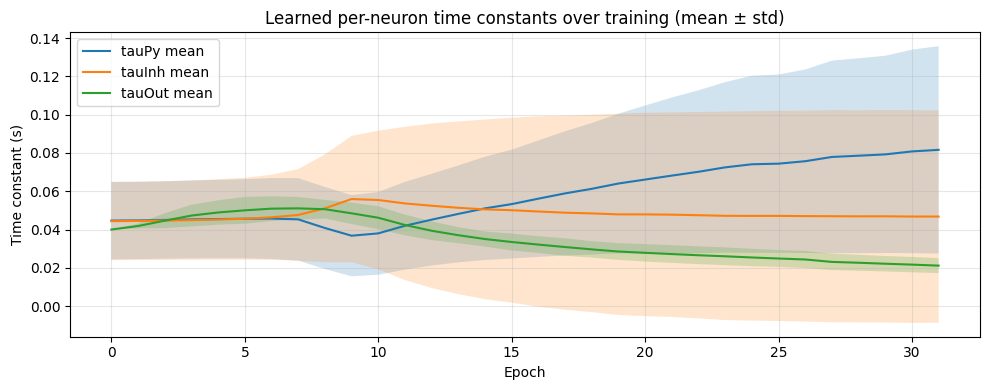

tauPy mean:  init=0.04468  final=0.08164  Δ=+0.03696
tauInh mean: init=0.04440  final=0.04678  Δ=+0.00238
tauOut mean: init=0.04000  final=0.02113  Δ=-0.01887


In [30]:
# @title Time-constant (tau) statistics over training (tauPy, tauInh, tauOut)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt

    # Ensure statistics exist
    try:
        n_epochs = len(tauPy_mean_per_epoch)
    except NameError as e:
        raise RuntimeError(
            "tau-per-epoch history not found. Run the training cell first so that "
            "tauPy_mean_per_epoch / tauPy_std_per_epoch, etc. are defined."
        ) from e

    if n_epochs == 0:
        raise RuntimeError("No tau history recorded. Did training run to completion?")

    # v52: epochs now start from 0 (true initialization) instead of 1
    epochs = np.arange(0, n_epochs)

    tauPy_mean = np.asarray(tauPy_mean_per_epoch, dtype=float)
    tauPy_std  = np.asarray(tauPy_std_per_epoch, dtype=float)
    tauInh_mean = np.asarray(tauInh_mean_per_epoch, dtype=float)
    tauInh_std  = np.asarray(tauInh_std_per_epoch, dtype=float)
    tauOut_mean = np.asarray(tauOut_mean_per_epoch, dtype=float)
    tauOut_std  = np.asarray(tauOut_std_per_epoch, dtype=float)

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(epochs, tauPy_mean, label="tauPy mean")
    ax.fill_between(epochs, tauPy_mean - tauPy_std, tauPy_mean + tauPy_std, alpha=0.2)

    ax.plot(epochs, tauInh_mean, label="tauInh mean")
    ax.fill_between(epochs, tauInh_mean - tauInh_std, tauInh_mean + tauInh_std, alpha=0.2)

    ax.plot(epochs, tauOut_mean, label="tauOut mean")
    ax.fill_between(epochs, tauOut_mean - tauOut_std, tauOut_mean + tauOut_std, alpha=0.2)

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Time constant (s)")
    ax.set_title("Learned per-neuron time constants over training (mean ± std)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

    plt.tight_layout()
    plt.show()

    print(f"tauPy mean:  init={tauPy_mean[0]:.5f}  final={tauPy_mean[-1]:.5f}  Δ={tauPy_mean[-1]-tauPy_mean[0]:+.5f}")
    print(f"tauInh mean: init={tauInh_mean[0]:.5f}  final={tauInh_mean[-1]:.5f}  Δ={tauInh_mean[-1]-tauInh_mean[0]:+.5f}")
    print(f"tauOut mean: init={tauOut_mean[0]:.5f}  final={tauOut_mean[-1]:.5f}  Δ={tauOut_mean[-1]-tauOut_mean[0]:+.5f}")

📷 Captured figure 15 -> saved_figures/figure_15_b4067579.png


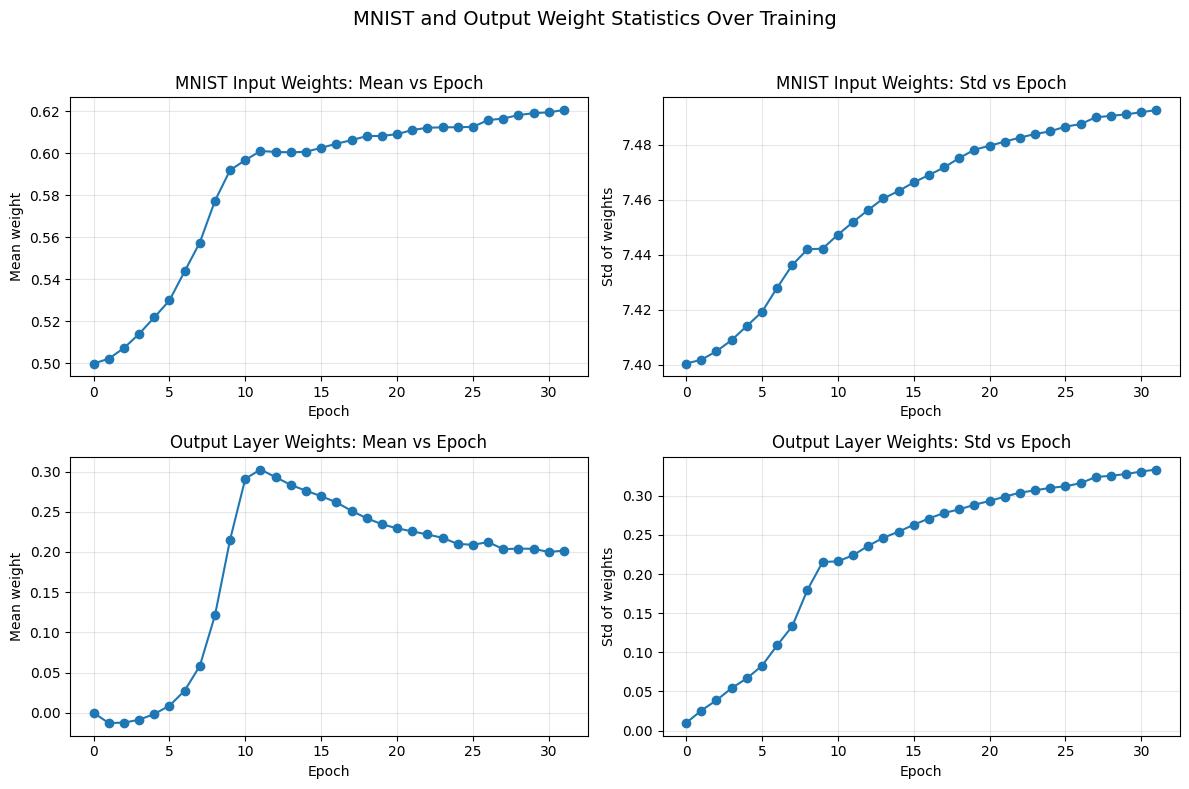

In [31]:
# @title MNIST and Output Weight Statistics over Training

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt

    # Ensure statistics exist
    try:
        n_epochs = len(mnist_mean_per_epoch)
    except NameError as e:
        raise RuntimeError(
            "MNIST/output weight statistics per epoch not found. "
            "Run the training cell first so that mnist_mean_per_epoch, etc., are defined."
        ) from e

    if n_epochs == 0:
        raise RuntimeError("No MNIST/output weight history recorded. Did training run to completion?")

    # v52: epochs now start from 0 (true initialization) instead of 1
    epochs = np.arange(0, n_epochs)

    mnist_mean_arr = np.asarray(mnist_mean_per_epoch, dtype=float)
    mnist_std_arr  = np.asarray(mnist_std_per_epoch, dtype=float)
    out_mean_arr   = np.asarray(output_mean_per_epoch, dtype=float)
    out_std_arr    = np.asarray(output_std_per_epoch, dtype=float)

    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # MNIST weights
    axs[0, 0].plot(epochs, mnist_mean_arr, marker="o")
    axs[0, 0].set_title("MNIST Input Weights: Mean vs Epoch")
    axs[0, 0].set_ylabel("Mean weight")
    axs[0, 0].grid(True, alpha=0.3)

    axs[0, 1].plot(epochs, mnist_std_arr, marker="o")
    axs[0, 1].set_title("MNIST Input Weights: Std vs Epoch")
    axs[0, 1].set_ylabel("Std of weights")
    axs[0, 1].grid(True, alpha=0.3)

    # Output layer weights
    axs[1, 0].plot(epochs, out_mean_arr, marker="o")
    axs[1, 0].set_title("Output Layer Weights: Mean vs Epoch")
    axs[1, 0].set_ylabel("Mean weight")
    axs[1, 0].grid(True, alpha=0.3)

    axs[1, 1].plot(epochs, out_std_arr, marker="o")
    axs[1, 1].set_title("Output Layer Weights: Std vs Epoch")
    axs[1, 1].set_ylabel("Std of weights")
    axs[1, 1].grid(True, alpha=0.3)

    for ax_row in axs:
        for ax in ax_row:
            ax.set_xlabel("Epoch")

    plt.suptitle("MNIST and Output Weight Statistics Over Training", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


In [32]:
# @title Raster viewer: last 10 seconds of each training epoch (saved for Word)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter


    def _stim_onsets_abs_in_window(t0_abs, t1_abs, image_duration_s,
                                  pulsed=False, pulse_on_s=1.0, pulse_off_s=1.0,
                                  align_t0=0.0, dt_s=None):
        """Absolute-time MNIST image onset times in [t0_abs, t1_abs].

        Continuous mode (pulsed=False): onsets every image_duration_s.

        Pulsed mode (pulsed=True): matches the *training loop's* implementation:
          - images_per_block = round(pulse_on_s / image_duration_s)  (typically 1.0s worth)
          - each image advances global time by EXACTLY image_duration_s
          - after each full block (and if not ending the epoch), an OFF segment runs for
            num_off_steps = int(pulse_off_s / dt) steps, so the *effective* OFF duration is
            off_eff = num_off_steps * dt (<= pulse_off_s). This tiny rounding can accumulate
            over long training, so we incorporate dt_s when provided.

        Notes:
          - Uses absolute time, so it works even when plotted time is cumulative across training.
          - align_t0 sets the phase reference (default 0.0 = first image starts at t=0).
        """
        try:
            t0_abs = float(t0_abs); t1_abs = float(t1_abs)
            image_duration_s = float(image_duration_s)
            pulse_on_s = float(pulse_on_s); pulse_off_s = float(pulse_off_s)
            align_t0 = float(align_t0)
            dt_s = None if dt_s is None else float(dt_s)
        except Exception:
            return np.array([], dtype=float)

        if image_duration_s <= 0 or t1_abs <= t0_abs:
            return np.array([], dtype=float)

        eps = 1e-9

        if not pulsed:
            k0 = int(np.ceil((t0_abs - align_t0) / image_duration_s - eps))
            k1 = int(np.floor((t1_abs - align_t0) / image_duration_s + eps))
            if k1 < k0:
                return np.array([], dtype=float)
            ks = np.arange(k0, k1 + 1, dtype=int)
            return (align_t0 + ks * image_duration_s).astype(float)

        # Pulsed mode: ON block (images) then OFF block (silence)
        if pulse_on_s <= 0 or pulse_off_s < 0:
            return np.array([], dtype=float)

        images_per_block = max(int(round(pulse_on_s / image_duration_s)), 1)
        on_eff = images_per_block * image_duration_s  # exactly how global time advances during ON

        # OFF effective duration: int(pulse_off_s/dt)*dt if dt is known, else pulse_off_s
        if dt_s is not None and dt_s > 0:
            off_steps = int(pulse_off_s / dt_s)
            off_eff = off_steps * dt_s
        else:
            off_eff = pulse_off_s

        block_dur = on_eff + off_eff
        if block_dur <= 0:
            return np.array([], dtype=float)

        # Consider blocks overlapping the window (with padding)
        b0 = int(np.floor((t0_abs - align_t0) / block_dur)) - 1
        b1 = int(np.ceil((t1_abs - align_t0) / block_dur)) + 1

        onsets = []
        for b in range(b0, b1 + 1):
            block_start = align_t0 + b * block_dur
            for j in range(images_per_block):
                tt = block_start + j * image_duration_s
                if (tt + eps) < t0_abs or (tt - eps) > t1_abs:
                    continue
                onsets.append(tt)

        if not onsets:
            return np.array([], dtype=float)
        return np.array(sorted(set(onsets)), dtype=float)


    def _add_stim_ticks(ax, stim_times_s, color="k", where="bottom", height_frac=0.03, offset_frac=0.015):
        """Draw short vertical ticks at stim_times_s in data coordinates."""
        stim_times_s = np.asarray(stim_times_s, dtype=float).ravel()
        stim_times_s = stim_times_s[np.isfinite(stim_times_s)]
        if stim_times_s.size == 0:
            return

        y0, y1 = ax.get_ylim()
        yr = (y1 - y0) if (y1 != y0) else 1.0

        if where == "below":
            y_base = y0 - offset_frac * yr
            y_top = y_base + height_frac * yr
            ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=1.0, zorder=50, clip_on=False)
            # Expand ylim a bit so ticks are visible
            ax.set_ylim(y0 - (offset_frac + height_frac + 0.01) * yr, y1)
        else:
            # bottom inside axes
            y_base = y0 + offset_frac * yr
            y_top = y_base + height_frac * yr
            ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=1.0, zorder=50, clip_on=True)


    def _format_seconds_to_hms(x, pos=None):
        try:
            total_seconds = int(round(float(x)))
        except Exception:
            return ""
        h = total_seconds // 3600
        m = (total_seconds % 3600) // 60
        s = total_seconds % 60
        if h > 0:
            return f"{h}h:{m:02d}m:{s:02d}s"
        elif m > 0:
            return f"{m}m:{s:02d}s"
        else:
            return f"{s}s"



    # --- Pulse-phase alignment helper (fix even/odd epoch phase flips) ---
    def _best_pulsed_align(t_arr, E_arr, image_duration_s, dt_s, pulse_on_s=1.0, pulse_off_s=1.0, base_align=0.0):
        """Choose align_t0 (phase reference) that best matches observed activity in this window.
        We test two plausible phases: base_align and base_align + off_eff (≈ 1s shift).
        This is robust to dt quantization in the OFF segment and prevents even/odd phase flips.
        """
        try:
            t = np.asarray(t_arr, dtype=float).ravel()
            E = np.asarray(E_arr, dtype=float)
            image_duration_s = float(image_duration_s)
            dt_s = float(dt_s) if dt_s is not None else None
            pulse_on_s = float(pulse_on_s)
            pulse_off_s = float(pulse_off_s)
            base_align = float(base_align)
        except Exception:
            return base_align

        if t.size == 0 or E.size == 0 or image_duration_s <= 0 or pulse_on_s <= 0:
            return base_align

        images_per_block = max(int(round(pulse_on_s / image_duration_s)), 1)
        on_eff = images_per_block * image_duration_s
        if dt_s is None or dt_s <= 0:
            off_eff = pulse_off_s
        else:
            off_eff = int(pulse_off_s / dt_s) * dt_s
        block_dur = on_eff + off_eff
        if block_dur <= 0:
            return base_align

        # Activity proxy: mean across units
        a = E.mean(axis=1)
        if a.shape[0] != t.shape[0]:
            # If shapes mismatch, fall back
            return base_align

        def score_for_align(align):
            phase = np.mod(t - align, block_dur)
            on = phase < on_eff
            if on.all() or (~on).all():
                return -np.inf
            return float(a[on].mean() - a[~on].mean())

        cand1 = base_align
        cand2 = base_align + off_eff
        s1 = score_for_align(cand1)
        s2 = score_for_align(cand2)
        return cand2 if s2 > s1 else cand1

    # --- Pull and validate data ---
    try:
        epoch_E = train_view_E_per_epoch
    except NameError as e:
        raise RuntimeError(
            "Training-phase activity (train_view_E_per_epoch) not found. "
            "Run the cell titled 'Train the Model - Supervised Learning' first."
        ) from e

    if not epoch_E:
        raise RuntimeError("train_view_E_per_epoch is empty. No training activity to display.")

    window_s = 10.0

    # Determine how often to generate raster figures (every Nth epoch)
    stride = 1
    if 'EPOCH_STRIDE_FOR_WORD_FIGS' in globals():
        try:
            stride = max(1, int(EPOCH_STRIDE_FOR_WORD_FIGS))
        except Exception:
            stride = 1

    pulsed = bool(PULSED_STIMULI) if "PULSED_STIMULI" in globals() else False
    dt_eff = float(dt) if "dt" in globals() else None

    for e, E_arr in enumerate(epoch_E):
        if e % stride != 0:
            continue

        E_arr = np.asarray(E_arr)
        if E_arr.ndim != 2 or E_arr.size == 0:
            print(f"Epoch {e+1}: no E activity recorded, skipping.")
            continue

        Tlen, num_units = E_arr.shape

        # Construct a time axis: prefer absolute training time if available
        if "train_view_t_per_epoch" in globals() and len(train_view_t_per_epoch) > e:
            t_arr = np.asarray(train_view_t_per_epoch[e], dtype=float)
            if t_arr.shape[0] != Tlen:
                t_arr = np.arange(Tlen, dtype=float) * (float(dt) if "dt" in globals() else 1.0)
        else:
            base_dt = float(dt) if "dt" in globals() else 1.0
            t_arr = np.arange(Tlen, dtype=float) * base_dt if Tlen > 1 else np.array([0.0], dtype=float)

        window_eff = (t_arr[-1] - t_arr[0]) if Tlen > 1 else 0.0
        window_eff = min(window_s, window_eff if window_eff > 0 else window_s)

        x0 = float(t_arr[0])
        x1 = float(t_arr[-1]) if Tlen > 1 else float(t_arr[0] + window_eff)

        fig, ax = plt.subplots(figsize=(10, 4))
        im = ax.imshow(
            E_arr.T,
            aspect="auto",
            origin="lower",
            extent=[x0, x1, 0, num_units],
            cmap="viridis",
            vmin=0.0,
            vmax=1.0,
        )

        # Epoch accuracy (if available)
        acc_text = ""
        try:
            if 'train_accuracies' in globals() and len(train_accuracies) > e:
                acc_val = 100.0 * float(train_accuracies[e])
                acc_text = f" (train acc = {acc_val:.1f}%)"
        except Exception:
            acc_text = ""

        # ---- MNIST stimulus markers (image onsets) ----
        try:
            x0 = float(t_arr[0])
            x1 = float(t_arr[-1]) if Tlen > 1 else float(t_arr[0] + window_eff)
            align0 = 0.0
            if pulsed and dt_eff is not None:
                # Choose phase that best matches this window (prevents even/odd flips)
                align0 = _best_pulsed_align(t_arr, E_arr, float(IMAGE_DURATION), float(dt_eff), pulse_on_s=1.0, pulse_off_s=1.0, base_align=0.0)
            stim_times = _stim_onsets_abs_in_window(
                x0, x1,
                image_duration_s=float(IMAGE_DURATION),
                pulsed=pulsed,
                pulse_on_s=1.0,
                pulse_off_s=1.0,
                align_t0=float(align0),
                dt_s=dt_eff,
            )
            # White ticks just above the x-axis, inside the axes (won't get cropped when saved)
            _add_stim_ticks(ax, stim_times, color="white", where="bottom")
        except Exception:
            pass

        ax.xaxis.set_major_formatter(FuncFormatter(_format_seconds_to_hms))
        ax.set_xlabel("Elapsed training time (h:m:s)")
        ax.set_ylabel("Excitatory unit index")
        ax.set_title(f"Epoch {e+1}: E activity, last {window_eff:.1f} s of training" + acc_text)

        fig.colorbar(im, ax=ax, label="E activity")
        fig.tight_layout()
        plt.show()

        # v62: Plot H dynamics (mean ± std) for this epoch
        if "train_view_H_mean_per_epoch" in globals() and len(train_view_H_mean_per_epoch) > e:
            H_mean_arr = np.asarray(train_view_H_mean_per_epoch[e], dtype=float)
            H_std_arr = np.asarray(train_view_H_std_per_epoch[e], dtype=float)

            if H_mean_arr.size > 0 and H_mean_arr.size == t_arr.size:
                fig_h, ax_h = plt.subplots(figsize=(10, 3))

                # Plot mean line
                ax_h.plot(t_arr, H_mean_arr, color='purple', linewidth=1.5, label='Mean H')

                # Plot shaded std region
                ax_h.fill_between(t_arr, H_mean_arr - H_std_arr, H_mean_arr + H_std_arr,
                                  color='purple', alpha=0.3, label='±1 Std')

                # MNIST stimulus markers
                try:
                    stim_times_h = _stim_onsets_abs_in_window(
                        x0, x1,
                        image_duration_s=float(IMAGE_DURATION),
                        pulsed=pulsed,
                        pulse_on_s=1.0,
                        pulse_off_s=1.0,
                        align_t0=float(align0),
                        dt_s=dt_eff,
                    )
                    _add_stim_ticks(ax_h, stim_times_h, color="gray", where="bottom")
                except Exception:
                    pass

                ax_h.xaxis.set_major_formatter(FuncFormatter(_format_seconds_to_hms))
                ax_h.set_xlabel("Elapsed training time (h:m:s)")
                ax_h.set_ylabel("H (adaptation)")
                ax_h.set_title(f"Epoch {e+1}: Mean H ± Std, last {window_eff:.1f} s of training" + acc_text)
                ax_h.legend(loc='upper right', fontsize=8)
                ax_h.grid(True, alpha=0.3)
                fig_h.tight_layout()
                plt.show()


Output hidden; open in https://colab.research.google.com to view.

LFP will be computed over 64.00 s (32000 samples at 500.0 Hz).
📷 Captured figure 80 -> saved_figures/figure_80_66b443b3.png


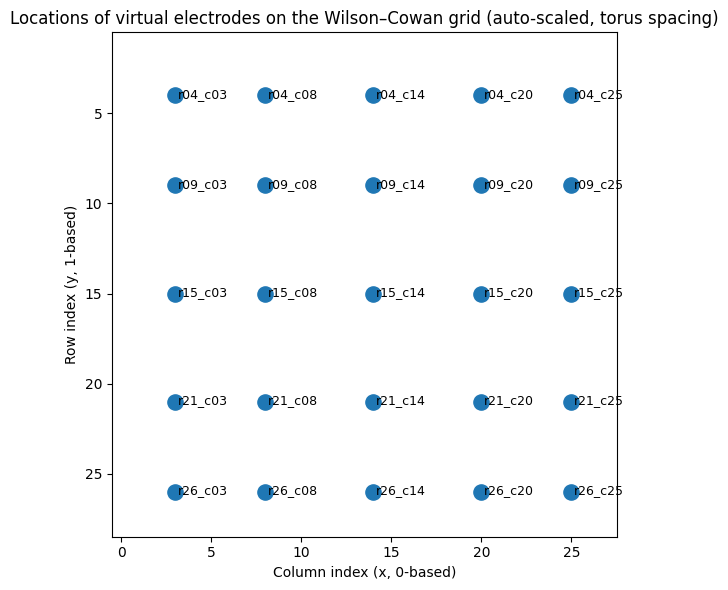

📷 Captured figure 81 -> saved_figures/figure_81_9ff772f5.png


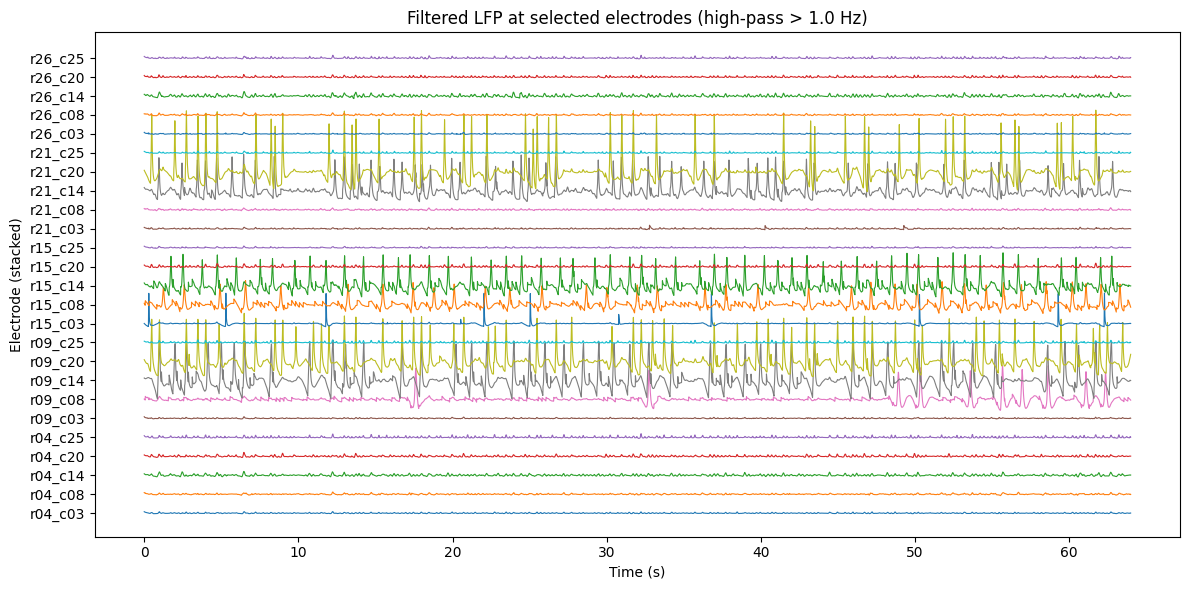

In [33]:
# @title Compute filtered LFP at selected electrodes and plot with spatial labels (post-training evaluation run)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.signal import butter, lfilter


    def _stim_onsets_abs_in_window(t0_abs, t1_abs, image_duration_s,
                                  pulsed=False, pulse_on_s=1.0, pulse_off_s=1.0,
                                  align_t0=0.0):
        """Absolute-time MNIST image onset times in [t0_abs, t1_abs].

        Continuous mode (pulsed=False): onsets every image_duration_s.

        Pulsed mode (pulsed=True): images presented at 1/image_duration_s Hz for pulse_on_s seconds,
        then no images for pulse_off_s seconds, repeating. This matches the training code path that
        runs an additional OFF segment after each block of images.

        Notes:
          - Uses absolute time, so it works even when plotted time is cumulative across training.
          - align_t0 sets the phase reference (default 0.0 = first image starts at t=0).
        """
        try:
            t0_abs = float(t0_abs); t1_abs = float(t1_abs)
            image_duration_s = float(image_duration_s)
            pulse_on_s = float(pulse_on_s); pulse_off_s = float(pulse_off_s)
            align_t0 = float(align_t0)
        except Exception:
            return np.array([], dtype=float)

        if image_duration_s <= 0 or t1_abs <= t0_abs:
            return np.array([], dtype=float)

        eps = 1e-9

        if not pulsed:
            k0 = int(np.ceil((t0_abs - align_t0) / image_duration_s - eps))
            k1 = int(np.floor((t1_abs - align_t0) / image_duration_s + eps))
            if k1 < k0:
                return np.array([], dtype=float)
            ks = np.arange(k0, k1 + 1, dtype=int)
            return (align_t0 + ks * image_duration_s).astype(float)

        # Pulsed mode: block of images then block of silence
        cycle = pulse_on_s + pulse_off_s
        if cycle <= 0 or pulse_on_s <= 0:
            return np.array([], dtype=float)

        images_per_block = max(int(round(pulse_on_s / image_duration_s)), 1)
        block_on_dur = images_per_block * image_duration_s
        block_dur = block_on_dur + pulse_off_s

        # Consider blocks overlapping the window (with 1-block padding)
        b0 = int(np.floor((t0_abs - align_t0) / block_dur)) - 1
        b1 = int(np.ceil((t1_abs - align_t0) / block_dur)) + 1

        onsets = []
        for b in range(b0, b1 + 1):
            block_start = align_t0 + b * block_dur
            # j-th image within ON block
            for j in range(images_per_block):
                tt = block_start + j * image_duration_s
                if (tt + eps) < t0_abs or (tt - eps) > t1_abs:
                    continue
                onsets.append(tt)

        if not onsets:
            return np.array([], dtype=float)
        return np.array(sorted(onsets), dtype=float)

    def _add_stim_ticks(ax, stim_times_s, color="k", where="bottom", height_frac=0.03, offset_frac=0.015):
        """Draw short vertical ticks at stim_times_s in data coordinates."""
        stim_times_s = np.asarray(stim_times_s, dtype=float).ravel()
        stim_times_s = stim_times_s[np.isfinite(stim_times_s)]
        if stim_times_s.size == 0:
            return

        y0, y1 = ax.get_ylim()
        yr = (y1 - y0) if (y1 != y0) else 1.0

        if where == "below":
            y_base = y0 - offset_frac * yr
            y_top = y_base + height_frac * yr
            ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=1.0, zorder=20, clip_on=False)
            # Expand ylim a bit so ticks are visible
            ax.set_ylim(y0 - (offset_frac + height_frac + 0.01) * yr, y1)
        else:
            # bottom inside axes
            y_base = y0 + offset_frac * yr
            y_top = y_base + height_frac * yr
            ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=1.0, zorder=20, clip_on=True)

    # --- User-adjustable parameter ---
    cutoff_hz = 1.0  # Default high-pass cutoff frequency in Hz

    def filter_eeg(eeg, cutoff, sample_rate, high_or_low, order):
        """Zero-phase (forward-backward) IIR filter."""
        eeg = np.asarray(eeg)
        ny = sample_rate / 2.0
        Wn = np.asarray(cutoff) / ny
        b, a = butter(order, Wn, btype=high_or_low)
        eeg_f = lfilter(b, a, eeg, axis=0)
        eeg_f_reverse = eeg_f[::-1, :]
        eeg_f_reverse_f = lfilter(b, a, eeg_f_reverse, axis=0)
        return eeg_f_reverse_f[::-1, :]

    # ---- Pull evaluation-phase data from training (per epoch) ----
    try:
        times_np = np.asarray(times_eval, dtype=float).flatten()
        E_arr = np.asarray(E_eval)
        I_arr = np.asarray(I_eval)
    except NameError as e:
        raise RuntimeError(
            "Post-training evaluation trajectory (times_eval, E_eval, I_eval) not found. "
            "Run the cell titled 'Train the Model - Supervised Learning' first."
        ) from e

    if times_np.size == 0 or E_arr.size == 0 or I_arr.size == 0:
        raise RuntimeError("Empty post-training evaluation trajectory; cannot compute LFP.")

    Tlen, num_cells = E_arr.shape
    if Tlen != len(times_np):
        raise RuntimeError(f"Time vector length ({len(times_np)}) does not match E trajectory length ({Tlen}).")

    dt_eff = float(times_np[1] - times_np[0]) if len(times_np) > 1 else float(dt)
    sample_rate = 1.0 / dt_eff

    print(
        f"LFP will be computed over {times_np[-1] - times_np[0]:.2f} s "
        f"({Tlen} samples at {sample_rate:.1f} Hz)."
    )

    # --------------------------------------------------------------------
    # Electrode selection (torus / periodic boundary conditions)
    # --------------------------------------------------------------------
    def _select_torus_electrodes(num_cells, num_row_electrodes=5, num_col_electrodes=3):
        """Return (n, row_labels_1based, col_labels_0based, linear_indices, labels)."""
        n = int(np.sqrt(num_cells))
        if n * n != int(num_cells):
            raise ValueError(f"num_cells={num_cells} is not a perfect square; cannot infer n×n grid.")

        if num_row_electrodes < 1 or num_col_electrodes < 1:
            raise ValueError("num_row_electrodes and num_col_electrodes must be >= 1")
        if num_row_electrodes > n or num_col_electrodes > n:
            raise ValueError(f"Too many electrodes for grid: n={n}, rows={num_row_electrodes}, cols={num_col_electrodes}")

        row_idx0 = (np.round((np.arange(num_row_electrodes) + 0.5) * (n / num_row_electrodes)) % n).astype(int)
        col_idx0 = (np.round((np.arange(num_col_electrodes) + 0.5) * (n / num_col_electrodes)) % n).astype(int)

        row_labels = np.repeat(row_idx0 + 1, len(col_idx0))   # 1-based rows
        col_labels = np.tile(col_idx0, len(row_idx0))         # 0-based cols

        labels = [f"r{int(r):02d}_c{int(c):02d}" for r, c in zip(row_labels, col_labels)]
        linear = (col_labels * n + (row_labels - 1)).astype(int)

        return n, row_labels, col_labels, linear, labels

    # Choose electrode grid (rows × cols). Adjust as needed.
    NUM_ROW_ELECTRODES = 5
    NUM_COL_ELECTRODES = 5

    n, row_labels, col_labels, lfp_electrodes, lfp_electrode_labels = _select_torus_electrodes(
        num_cells,
        num_row_electrodes=NUM_ROW_ELECTRODES,
        num_col_electrodes=NUM_COL_ELECTRODES,
    )

    # ---- Electrode location plot (spatial labels) ----
    plt.figure(figsize=(6, 6))
    plt.scatter(col_labels, row_labels, s=120)
    for x, y, lab in zip(col_labels, row_labels, lfp_electrode_labels):
        plt.text(x + 0.15, y + 0.15, lab, fontsize=9)

    plt.xlim(-0.5, n - 0.5)
    plt.ylim(0.5, n + 0.5)
    plt.gca().invert_yaxis()
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("Column index (x, 0-based)")
    plt.ylabel("Row index (y, 1-based)")
    plt.title("Locations of virtual electrodes on the Wilson–Cowan grid (auto-scaled, torus spacing)")
    plt.tight_layout()
    plt.show()

    # Expose for reuse by other cells
    globals()["lfp_electrodes"] = lfp_electrodes
    globals()["lfp_electrode_labels"] = lfp_electrode_labels
    globals()["lfp_electrode_row_labels"] = row_labels
    globals()["lfp_electrode_col_labels"] = col_labels
    globals()["n_grid"] = n

    # ---- Subsample connectivity to electrodes ----
    CeLoc_sub = CeLoc_csr[lfp_electrodes, :]
    CeRem_sub = CeRem_csr[lfp_electrodes, :]

    # ---- Reconstruct "LFP" ----
    loc_term  = E_arr @ CeLoc_sub.T
    rem_term  = E_arr @ CeRem_sub.T
    self_term = E_arr[:, lfp_electrodes]
    inh_term  = I_arr[:, lfp_electrodes]

    LFP_elec = 10.0 * self_term + 0.15 * loc_term + 0.05 * rem_term + 25.0 * inh_term

    # ---- Filter ----
    filtLFP_elec = filter_eeg(
        LFP_elec,
        cutoff=cutoff_hz,
        sample_rate=sample_rate,
        high_or_low="high",
        order=4,
    )

    # ---- Stacked plot ----
    E_count = len(lfp_electrodes)
    offsets = np.arange(1, E_count + 1) * 5.0
    stacked_traces = filtLFP_elec + offsets

    plt.figure(figsize=(12, 6))
    plt.plot(times_np, stacked_traces, linewidth=0.8)

    if "image_times_all" in globals():
        ax = plt.gca()
        x0, x1 = ax.get_xlim()
        stim_times = _stim_onsets_abs_in_window(
        x0, x1,
        image_duration_s=float(IMAGE_DURATION),
        pulsed=bool(PULSED_STIMULI) if "PULSED_STIMULI" in globals() else False,
        pulse_on_s=1.0,
        pulse_off_s=1.0,
        align_t0=0.0,
    )
    _add_stim_ticks(ax, stim_times, color="black", where="bottom", height_frac=0.04, offset_frac=0.005)
    if "boundary_time" in globals():
        plt.axvline(boundary_time, color="red", linestyle=":", linewidth=1.5, label="Train/Eval boundary")

    plt.xlabel("Time (s)")
    plt.ylabel("Electrode (stacked)")
    plt.title(f"Filtered LFP at selected electrodes (high-pass > {cutoff_hz} Hz)")
    plt.yticks(offsets, lfp_electrode_labels)
    plt.tight_layout()
    plt.show()


In [34]:
# @title LFP viewer: last 10 seconds of each training epoch (saved for Word)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    from scipy.signal import butter, lfilter

    print("[LFP viewer] Cell started")  # diagnostic


    # -----------------------------
    # Helpers
    # -----------------------------
    def _format_seconds_to_hms(x, pos=None):
        try:
            total_seconds = int(round(float(x)))
        except Exception:
            return ""
        h = total_seconds // 3600
        m = (total_seconds % 3600) // 60
        s = total_seconds % 60
        if h > 0:
            return f"{h}h:{m:02d}m:{s:02d}s"
        elif m > 0:
            return f"{m}m:{s:02d}s"
        else:
            return f"{s}s"


    def _filter_eeg_local(eeg, cutoff, sample_rate, high_or_low, order):
        eeg = np.asarray(eeg)
        ny = sample_rate / 2.0
        Wn = np.asarray(cutoff) / ny
        b, a = butter(order, Wn, btype=high_or_low)
        return lfilter(b, a, eeg, axis=0)


    def _select_torus_electrodes(num_cells, num_row_electrodes=5, num_col_electrodes=3):
        n = int(np.sqrt(num_cells))
        if n * n != int(num_cells):
            raise ValueError(f"num_cells={num_cells} is not a perfect square; cannot infer n×n grid.")
        if num_row_electrodes < 1 or num_col_electrodes < 1:
            raise ValueError("num_row_electrodes and num_col_electrodes must be >= 1")
        if num_row_electrodes > n or num_col_electrodes > n:
            raise ValueError(f"Too many electrodes for grid: n={n}, rows={num_row_electrodes}, cols={num_col_electrodes}")

        row_idx0 = (np.round((np.arange(num_row_electrodes) + 0.5) * (n / num_row_electrodes)) % n).astype(int)
        col_idx0 = (np.round((np.arange(num_col_electrodes) + 0.5) * (n / num_col_electrodes)) % n).astype(int)

        row_labels = np.repeat(row_idx0 + 1, len(col_idx0))
        col_labels = np.tile(col_idx0, len(row_idx0))

        labels = [f"r{int(r):02d}_c{int(c):02d}" for r, c in zip(row_labels, col_labels)]
        linear = (col_labels * n + (row_labels - 1)).astype(int)
        return n, row_labels, col_labels, linear, labels


    def _stim_onsets_abs_in_window_pulsed_dt(t0_abs, t1_abs, image_duration_s, dt_s,
                                            pulse_on_s=1.0, pulse_off_s=1.0, align_t0=0.0):
        """Absolute-time image onset times in [t0_abs, t1_abs] for pulsed schedule,
        matching the effective OFF duration that results from stepping in dt increments.
        """
        try:
            t0_abs = float(t0_abs); t1_abs = float(t1_abs)
            image_duration_s = float(image_duration_s)
            dt_s = float(dt_s)
            pulse_on_s = float(pulse_on_s); pulse_off_s = float(pulse_off_s)
            align_t0 = float(align_t0)
        except Exception:
            return np.array([], dtype=float)

        if image_duration_s <= 0 or dt_s <= 0 or t1_abs <= t0_abs or pulse_on_s <= 0:
            return np.array([], dtype=float)

        eps = 1e-9
        images_per_block = max(int(round(pulse_on_s / image_duration_s)), 1)
        block_on_dur = images_per_block * image_duration_s

        # Effective OFF duration from stepping with dt (matches typical training implementation)
        off_steps = int(np.floor(pulse_off_s / dt_s + eps))
        off_eff = off_steps * dt_s

        block_dur = block_on_dur + off_eff
        if block_dur <= 0:
            return np.array([], dtype=float)

        # blocks overlapping window (pad by one)
        b0 = int(np.floor((t0_abs - align_t0) / block_dur)) - 1
        b1 = int(np.ceil((t1_abs - align_t0) / block_dur)) + 1

        onsets = []
        for b in range(b0, b1 + 1):
            block_start = align_t0 + b * block_dur
            for j in range(images_per_block):
                tt = block_start + j * image_duration_s
                if (tt + eps) < t0_abs or (tt - eps) > t1_abs:
                    continue
                onsets.append(tt)

        if not onsets:
            return np.array([], dtype=float)
        return np.array(sorted(set(onsets)), dtype=float)


    def _choose_pulse_phase_for_window(t_win, E_win_mean, image_duration_s, dt_s,
                                      pulse_on_s=1.0, pulse_off_s=1.0, align_base=0.0):
        """Choose between two plausible phase references for pulsed schedule:
        align_base vs align_base + off_eff. Picks the one where mean activity is higher during ON.
        """
        try:
            t_win = np.asarray(t_win, dtype=float).ravel()
            E_win_mean = np.asarray(E_win_mean, dtype=float).ravel()
            image_duration_s = float(image_duration_s)
            dt_s = float(dt_s)
            pulse_on_s = float(pulse_on_s); pulse_off_s = float(pulse_off_s)
            align_base = float(align_base)
        except Exception:
            return align_base

        if t_win.size == 0 or E_win_mean.size != t_win.size or image_duration_s <= 0 or dt_s <= 0:
            return align_base

        eps = 1e-9
        images_per_block = max(int(round(pulse_on_s / image_duration_s)), 1)
        block_on_dur = images_per_block * image_duration_s
        off_steps = int(np.floor(pulse_off_s / dt_s + eps))
        off_eff = off_steps * dt_s
        block_dur = block_on_dur + off_eff
        if block_dur <= 0:
            return align_base

        candidates = [align_base, align_base + off_eff]

        best_align = candidates[0]
        best_score = -np.inf

        for a in candidates:
            phase = np.mod(t_win - a, block_dur)
            on_mask = phase < (block_on_dur - 1e-12)
            off_mask = ~on_mask

            # Need both ON and OFF samples to score; otherwise fall back
            if on_mask.sum() < 3 or off_mask.sum() < 3:
                score = -np.inf
            else:
                score = float(np.nanmean(E_win_mean[on_mask]) - np.nanmean(E_win_mean[off_mask]))

            if score > best_score:
                best_score = score
                best_align = a

        return best_align


    def _draw_stim_ticks_near_bottom(ax, stim_times_s, color="black",
                                    y_frac_base=0.01, y_frac_height=0.03, lw=1.4):
        """Draw short vertical ticks INSIDE axes near the bottom (robust to tight cropping)."""
        stim_times_s = np.asarray(stim_times_s, dtype=float).ravel()
        stim_times_s = stim_times_s[np.isfinite(stim_times_s)]
        if stim_times_s.size == 0:
            return

        y0, y1 = ax.get_ylim()
        yr = (y1 - y0) if (y1 != y0) else 1.0
        y_base = y0 + y_frac_base * yr
        y_top  = y0 + (y_frac_base + y_frac_height) * yr
        ax.vlines(stim_times_s, y_base, y_top, colors=color, linewidth=lw, zorder=60, clip_on=True)


    # -----------------------------
    # Pull training-phase per-epoch activity
    # -----------------------------
    try:
        epoch_E = train_view_E_per_epoch
        epoch_I = train_view_I_per_epoch
    except NameError as e:
        raise RuntimeError(
            "Training-phase activity (train_view_E_per_epoch / train_view_I_per_epoch) "
            "not found. Run the 'Train the Model - Supervised Learning' cell first."
        ) from e

    if not epoch_E:
        raise RuntimeError("train_view_E_per_epoch is empty. No training activity to display.")


    # -----------------------------
    # Electrode selection
    # -----------------------------
    NUM_ROW_ELECTRODES = 5
    NUM_COL_ELECTRODES = 5

    _, _, _, lfp_electrodes, selector_labels = _select_torus_electrodes(
        num_cells,
        num_row_electrodes=NUM_ROW_ELECTRODES,
        num_col_electrodes=NUM_COL_ELECTRODES,
    )

    try:
        electrodes = np.asarray(lfp_electrodes, dtype=int)
        electrode_labels = list(lfp_electrode_labels)
    except Exception:
        electrodes = np.asarray(lfp_electrodes, dtype=int)
        electrode_labels = list(selector_labels)

    CeLoc_sub = CeLoc_csr[electrodes, :]
    CeRem_sub = CeRem_csr[electrodes, :]


    # -----------------------------
    # Timing + parameters
    # -----------------------------
    dt_eff = float(dt)
    sample_rate = 1.0 / dt_eff
    window = 10.0
    n_epochs = len(epoch_E)

    stride = 1
    if "EPOCH_STRIDE_FOR_WORD_FIGS" in globals():
        try:
            stride = max(1, int(EPOCH_STRIDE_FOR_WORD_FIGS))
        except Exception:
            stride = 1

    # Fixed y-limits (consistent amplitude scaling across epochs)
    FIXED_YMIN = -1.62946
    FIXED_YMAX = 136.055

    pulsed = bool(PULSED_STIMULI) if "PULSED_STIMULI" in globals() else False
    IMAGE_DUR = float(IMAGE_DURATION) if "IMAGE_DURATION" in globals() else 0.25

    for e in range(0, n_epochs, stride):
        E_epoch = np.asarray(epoch_E[e])
        I_epoch = np.asarray(epoch_I[e]) if e < len(epoch_I) else None

        if E_epoch.size == 0:
            continue

        if I_epoch is None or I_epoch.size == 0 or I_epoch.shape != E_epoch.shape:
            I_epoch = np.zeros_like(E_epoch)

        T, N = E_epoch.shape

        # Times: prefer recorded per-epoch time vector if present
        if "train_view_t_per_epoch" in globals() and len(train_view_t_per_epoch) > e:
            times_arr = np.asarray(train_view_t_per_epoch[e], dtype=float)
            if times_arr.shape[0] != T:
                times_arr = np.arange(T, dtype=float) * dt_eff
        else:
            times_arr = np.arange(T, dtype=float) * dt_eff

        # Compute last-window indices
        total_time = float(times_arr[-1] - times_arr[0]) if times_arr.size > 1 else 0.0
        if total_time <= 0:
            window_eff = 0.0
            idx_win = np.arange(times_arr.size)
        else:
            window_eff = min(window, total_time)
            t_start = times_arr[-1] - window_eff
            idx_win = np.where(times_arr >= t_start)[0]

        if idx_win.size == 0:
            continue

        # Compute LFP terms (T x E_count)
        loc_term  = E_epoch @ CeLoc_sub.T
        rem_term  = E_epoch @ CeRem_sub.T
        self_term = E_epoch[:, electrodes]
        inh_term  = I_epoch[:, electrodes]

        LFP_elec = 10.0 * self_term + 0.15 * loc_term + 0.05 * rem_term + 25.0 * inh_term

        filtLFP_elec = _filter_eeg_local(
            LFP_elec,
            cutoff=1.0,
            sample_rate=sample_rate,
            high_or_low="high",
            order=4,
        )

        E_count = len(electrodes)
        offsets = np.arange(E_count) * 5.0
        stacked_traces = filtLFP_elec[:, :E_count] + offsets[None, :]

        t_win = times_arr[idx_win]
        y_win = stacked_traces[idx_win, :]

        # Plot
        fig, ax = plt.subplots(figsize=(10, 5))
        for ch in range(E_count):
            ax.plot(t_win, y_win[:, ch], linewidth=0.7)

        # Fixed y-limits
        ax.set_ylim(FIXED_YMIN, FIXED_YMAX)

        # ---- MNIST stimulus markers (black ticks just below the lowest LFP trace) ----
        try:
            if pulsed:
                # Use windowed E-activity to pick correct pulse phase for this window
                E_win_mean = np.mean(E_epoch[idx_win, :], axis=1)
                align = _choose_pulse_phase_for_window(
                    t_win=t_win,
                    E_win_mean=E_win_mean,
                    image_duration_s=IMAGE_DUR,
                    dt_s=dt_eff,
                    pulse_on_s=1.0,
                    pulse_off_s=1.0,
                    align_base=0.0,
                )
                stim_abs = _stim_onsets_abs_in_window_pulsed_dt(
                    float(t_win[0]), float(t_win[-1]),
                    image_duration_s=IMAGE_DUR,
                    dt_s=dt_eff,
                    pulse_on_s=1.0,
                    pulse_off_s=1.0,
                    align_t0=align,
                )
            else:
                # Continuous: onsets every IMAGE_DURATION
                k0 = int(np.ceil((float(t_win[0]) - 0.0) / IMAGE_DUR - 1e-9))
                k1 = int(np.floor((float(t_win[-1]) - 0.0) / IMAGE_DUR + 1e-9))
                stim_abs = (0.0 + np.arange(k0, k1 + 1) * IMAGE_DUR) if k1 >= k0 else np.array([], dtype=float)

            _draw_stim_ticks_near_bottom(ax, stim_abs, color="black")
        except Exception:
            pass

        # Cosmetics
        ax.xaxis.set_major_formatter(FuncFormatter(_format_seconds_to_hms))
        ax.set_xlabel("Elapsed training time (h:m:s)")
        ax.set_ylabel("Electrode (stacked)")
        ax.set_title(f"Epoch {e+1}: filtered LFP (TRAINING), last {window_eff:.1f} s")

        try:
            if electrode_labels is not None and len(electrode_labels) == E_count:
                ax.set_yticks(offsets)
                ax.set_yticklabels(electrode_labels)
        except Exception:
            pass

        fig.tight_layout()
        plt.show()


Output hidden; open in https://colab.research.google.com to view.

📷 Captured figure 114 -> saved_figures/figure_114_99a3ba88.png


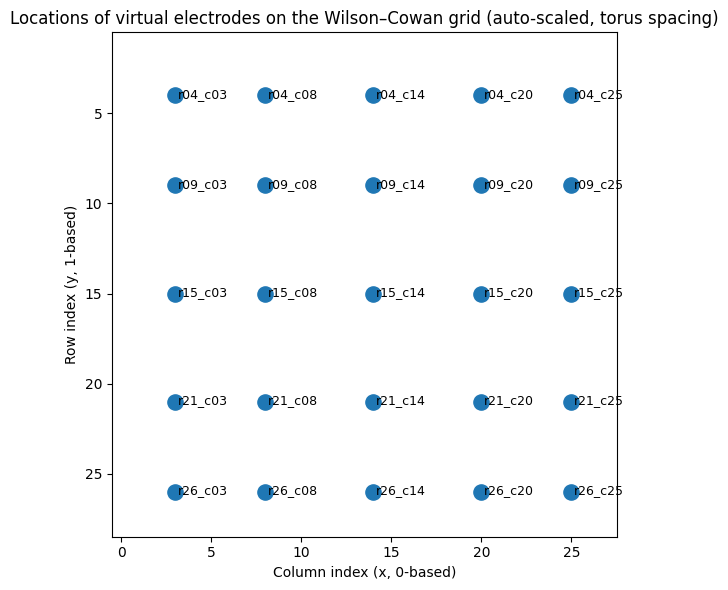

In [35]:
# @title Schematic of electrode locations on the Wilson–Cowan grid (auto-scaled for n)

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:

    import numpy as np
    import matplotlib.pyplot as plt

    # --- Electrode selection (torus / periodic boundary conditions) ---
    def _select_torus_electrodes(num_cells, num_row_electrodes=5, num_col_electrodes=3):
        """Return (n, row_labels_1based, col_labels_0based, linear_indices, labels).

        Electrode positions are spaced as evenly as possible on an n×n torus
        (i.e., periodic boundary conditions / wrap-around).
        """
        import numpy as np

        n = int(np.sqrt(num_cells))
        if n * n != int(num_cells):
            raise ValueError(f"num_cells={num_cells} is not a perfect square; cannot infer n×n grid.")

        if num_row_electrodes < 1 or num_col_electrodes < 1:
            raise ValueError("num_row_electrodes and num_col_electrodes must be >= 1")
        if num_row_electrodes > n or num_col_electrodes > n:
            raise ValueError(f"Too many electrodes for grid: n={n}, rows={num_row_electrodes}, cols={num_col_electrodes}")

        # Even spacing on a torus: choose centers of equally-sized bins and wrap with mod n.
        row_idx0 = (np.round((np.arange(num_row_electrodes) + 0.5) * (n / num_row_electrodes)) % n).astype(int)
        col_idx0 = (np.round((np.arange(num_col_electrodes) + 0.5) * (n / num_col_electrodes)) % n).astype(int)

        # Create a full grid of electrode coordinates
        row_labels = np.repeat(row_idx0 + 1, len(col_idx0))     # 1-based rows for display
        col_labels = np.tile(col_idx0, len(row_idx0))           # 0-based cols for display

        # Labels and linear indices (matching existing convention: idx = col*n + (row-1))
        labels = [f"r{int(r):02d}_c{int(c):02d}" for r, c in zip(row_labels, col_labels)]
        linear = (col_labels * n + (row_labels - 1)).astype(int)

        return n, row_labels, col_labels, linear, labels


    # Choose electrode grid (rows × cols). Adjust as needed.
    NUM_ROW_ELECTRODES = 5
    NUM_COL_ELECTRODES = 5

    n, row_labels, col_labels, lfp_electrodes, lfp_electrode_labels = _select_torus_electrodes(
        num_cells,
        num_row_electrodes=NUM_ROW_ELECTRODES,
        num_col_electrodes=NUM_COL_ELECTRODES,
    )

    # Plot electrode locations
    plt.figure(figsize=(6, 6))
    plt.scatter(col_labels, row_labels, s=120)

    for x, y, lab in zip(col_labels, row_labels, lfp_electrode_labels):
        plt.text(x + 0.15, y + 0.15, lab, fontsize=9)

    plt.xlim(-0.5, n - 0.5)
    plt.ylim(0.5, n + 0.5)
    plt.gca().invert_yaxis()  # match earlier orientation conventions (row index increases downward)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("Column index (x, 0-based)")
    plt.ylabel("Row index (y, 1-based)")
    plt.title("Locations of virtual electrodes on the Wilson–Cowan grid (auto-scaled, torus spacing)")

    plt.tight_layout()
    plt.show()


In [36]:
# @title Save hyperparameters, parameter stats, and captured figures to a Word file

# Skip this cell if PARAM_EXPLORE_MODE is True
if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping (training/visualization cells not used in explore mode).")
else:
    !pip install python-docx --quiet

    import os
    from datetime import datetime
    import math
    import csv

    import docx
    from docx.shared import Inches

    # --------------------------------------------------------------------
    # 1. Create the document and add run metadata
    # --------------------------------------------------------------------
    timestamp = timestamp
    doc_filename = f"WC_MNIST_run_{timestamp}.docx"

    NOTEBOOK_NAME = NOTEBOOK_NAME

    doc = docx.Document()
    doc.add_heading("WC–MNIST Wilson–Cowan Classifier Run", level=0)

    from zoneinfo import ZoneInfo
    eastern = ZoneInfo("America/New_York")
    run_dt = datetime.now(eastern).strftime("%Y-%m-%d %H:%M:%S %Z")
    doc.add_paragraph(f"Run date/time: {run_dt}")
    doc.add_paragraph(
        "This document was generated automatically at the end of the notebook run."
    )
    doc.add_paragraph(f"Notebook: {NOTEBOOK_NAME}")
    # Simulation timing + runtime type (set in the training cell)
    sim_start = globals().get("SIM_START_HUMAN", None)
    sim_end = globals().get("SIM_END_HUMAN", None)
    sim_runtime_type = globals().get("SIM_RUNTIME_TYPE", None)
    sim_duration_sec = globals().get("SIM_DURATION_SEC", None)

    if sim_start is not None:
        doc.add_paragraph(f"Simulation start (ET): {sim_start}")
    if sim_end is not None:
        doc.add_paragraph(f"Simulation end (ET): {sim_end}")
    if sim_duration_sec is not None:
        doc.add_paragraph(f"Simulation duration (s): {sim_duration_sec:.2f}")
        # Also show elapsed time as M min S sec for quick readability
        _mins = int(sim_duration_sec // 60)
        _secs = int(round(sim_duration_sec - 60*_mins))
        if _secs == 60:
            _mins += 1
            _secs = 0
        doc.add_paragraph(f"Elapsed time: {_mins}m {_secs:02d}s")
    if sim_runtime_type is not None:
        doc.add_paragraph(f"Runtime type: {sim_runtime_type}")


    # --------------------------------------------------------------------
    # 2. Hyperparameters and their sampling distributions
    # --------------------------------------------------------------------
    doc.add_heading("Hyperparameters", level=1)
    # v67: Log random seed for reproducibility
    if "RANDOM_SEED" in globals():
        doc.add_paragraph(f"RANDOM_SEED: {RANDOM_SEED}")
    else:
        doc.add_paragraph("RANDOM_SEED: <not set>")

    # Include PULSED_STIMULI explicitly (in addition to any sampling-info dict)
    if "PULSED_STIMULI" in globals():
        try:
            doc.add_paragraph(f"PULSED_STIMULI: {bool(PULSED_STIMULI)}")
        except Exception:
            doc.add_paragraph("PULSED_STIMULI: <unavailable>")

    # v57/v58/v63: Add H adaptation parameters
    if "TAU_H" in globals():
        # v63: Show that TAU_H was sampled from a range
        if "TAU_H_MIN" in globals() and "TAU_H_MAX" in globals():
            doc.add_paragraph(f"TAU_H: {TAU_H:.4f}s ({TAU_H*1000:.0f}ms) (sampled from Uniform({TAU_H_MIN}, {TAU_H_MAX}))")
        else:
            doc.add_paragraph(f"TAU_H: {TAU_H:.4f}s ({TAU_H*1000:.0f}ms)")
    if "ALPHA_H" in globals():
        # v58: Show that ALPHA_H was sampled from a range
        if "ALPHA_H_MIN" in globals() and "ALPHA_H_MAX" in globals():
            doc.add_paragraph(f"ALPHA_H: {ALPHA_H:.4f} (sampled from Uniform({ALPHA_H_MIN}, {ALPHA_H_MAX}))")
        else:
            doc.add_paragraph(f"ALPHA_H: {ALPHA_H:.4f}")
    if "H_INIT_MIN" in globals() and "H_INIT_MAX" in globals():
        doc.add_paragraph(f"H_INIT: Uniform({H_INIT_MIN}, {H_INIT_MAX})")

    if "hyperparam_sampling_info" in globals():
        table = doc.add_table(rows=1, cols=4)
        hdr_cells = table.rows[0].cells
        hdr_cells[0].text = "Name"
        hdr_cells[1].text = "Value"
        hdr_cells[2].text = "Distribution"
        hdr_cells[3].text = "Parameters"

        for name in sorted(hyperparam_sampling_info.keys()):
            info = hyperparam_sampling_info[name]
            row_cells = table.add_row().cells
            row_cells[0].text = str(name)
            row_cells[1].text = f"{info.get('value')}"
            row_cells[2].text = str(info.get("distribution", ""))

            dist = info.get("distribution", "")
            if dist == "Uniform":
                params_str = f"[{info.get('min')}, {info.get('max')}]"
            else:
                extras = {k: v for k, v in info.items()
                          if k not in ("value", "distribution") and v is not None}
                params_str = "" if not extras else str(extras)
            row_cells[3].text = params_str
    else:
        doc.add_paragraph("No hyperparameter sampling metadata found.")

    # --------------------------------------------------------------------
    # 3. Learnable parameters: initial vs final statistics + percent change
    # --------------------------------------------------------------------
    doc.add_heading("Learnable Parameters (Initial vs Final)", level=1)

    def safe_pct_change(init, final):
        eps = 1e-12
        if init is None:
            return None
        if abs(init) < eps:
            return None
        return 100.0 * (final - init) / abs(init)

    # v57: Add H statistics before the learnable parameters table
    if "initial_H_stats" in globals() and "final_H_stats" in globals():
        doc.add_heading("Slow Adaptation Variable H Statistics (v57)", level=2)
        h_table = doc.add_table(rows=1, cols=5)
        h_hdr = h_table.rows[0].cells
        h_hdr[0].text = "Statistic"
        h_hdr[1].text = "Initial"
        h_hdr[2].text = "Final"
        h_hdr[3].text = "Change"
        h_hdr[4].text = "% Change"

        for stat in ["min", "max", "mean", "std"]:
            init_val = initial_H_stats.get(stat, None)
            final_val = final_H_stats.get(stat, None)
            row = h_table.add_row().cells
            row[0].text = stat
            row[1].text = f"{init_val:.6f}" if init_val is not None else "NA"
            row[2].text = f"{final_val:.6f}" if final_val is not None else "NA"
            if init_val is not None and final_val is not None:
                change = final_val - init_val
                pct_change = 100.0 * change / abs(init_val) if abs(init_val) > 1e-12 else float('nan')
                row[3].text = f"{change:+.6f}"
                row[4].text = f"{pct_change:+.2f}%" if not (isinstance(pct_change, float) and (pct_change != pct_change)) else "NA"
            else:
                row[3].text = "NA"
                row[4].text = "NA"
        doc.add_paragraph("")  # Spacer

    if ("initial_param_stats" in globals()) and ("final_param_stats" in globals()):
        table = doc.add_table(rows=1, cols=9)
        hdr = table.rows[0].cells
        hdr[0].text = "Parameter"
        hdr[1].text = "Init mean"
        hdr[2].text = "Init std"
        hdr[3].text = "Final mean"
        hdr[4].text = "Final std"
        hdr[5].text = "Init min/max"
        hdr[6].text = "Final min/max"
        hdr[7].text = "% Δ mean"
        hdr[8].text = "% Δ std"

        # Use the ordering from learnable_param_names if available
        if "learnable_param_names" in globals():
            param_order = list(learnable_param_names.keys())
        else:
            param_order = sorted(initial_param_stats.keys())

        for name in param_order:
            init_stats = initial_param_stats.get(name, {})
            final_stats = final_param_stats.get(name, {})

            init_mean = init_stats.get("mean", None)
            init_std  = init_stats.get("std", None)
            final_mean = final_stats.get("mean", None)
            final_std  = final_stats.get("std", None)

            pct_mean = safe_pct_change(init_mean, final_mean) if init_mean is not None and final_mean is not None else None
            pct_std  = safe_pct_change(init_std, final_std)   if init_std is not None and final_std is not None else None

            row = table.add_row().cells
            row[0].text = name

            row[1].text = "NA" if init_mean is None else f"{init_mean:.4g}"
            row[2].text = "NA" if init_std  is None else f"{init_std:.4g}"
            row[3].text = "NA" if final_mean is None else f"{final_mean:.4g}"
            row[4].text = "NA" if final_std  is None else f"{final_std:.4g}"

            if "min" in init_stats and "max" in init_stats:
                row[5].text = f"[{init_stats['min']:.4g}, {init_stats['max']:.4g}]"
            else:
                row[5].text = "NA"

            if "min" in final_stats and "max" in final_stats:
                row[6].text = f"[{final_stats['min']:.4g}, {final_stats['max']:.4g}]"
            else:
                row[6].text = "NA"

            row[7].text = "NA" if pct_mean is None or (isinstance(pct_mean, float) and math.isnan(pct_mean)) else f"{pct_mean:+.2f}%"
            row[8].text = "NA" if pct_std  is None or (isinstance(pct_std, float) and math.isnan(pct_std))  else f"{pct_std:+.2f}%"
    else:
        doc.add_paragraph(
            "Initial/final parameter statistics not found. "
            "Make sure you have run the model instantiation and training cells."
        )

    # Also record the distributions used for initialization (metadata only)
    if "learnable_param_init_distributions" in globals():
        doc.add_heading("Initialization Distributions for Learnable Parameters", level=2)
        table = doc.add_table(rows=1, cols=4)
        hdr = table.rows[0].cells
        hdr[0].text = "Parameter"
        hdr[1].text = "Distribution"
        hdr[2].text = "Min"
        hdr[3].text = "Max"

        for name in sorted(learnable_param_init_distributions.keys()):
            info = learnable_param_init_distributions[name]
            row = table.add_row().cells
            row[0].text = name
            row[1].text = str(info.get("distribution", ""))
            row[2].text = "" if info.get("min") is None else str(info.get("min"))
            row[3].text = "" if info.get("max") is None else str(info.get("max"))

    # --------------------------------------------------------------------
    # v57: Add H adaptation plots
    # --------------------------------------------------------------------
    if "H_history" in globals() and H_history is not None and len(H_history.get('times', [])) > 0:
        import numpy as np
        import matplotlib.pyplot as plt
        import io

        doc.add_heading("Slow Adaptation Variable H Dynamics (v57)", level=2)

        H_t = np.asarray(H_history['times'], dtype=float).ravel()
        H_m = np.asarray(H_history['means'], dtype=float).ravel()
        H_s = np.asarray(H_history['stds'], dtype=float).ravel()

        # Plot Mean H vs Time
        fig_hm, ax_hm = plt.subplots(figsize=(10, 3))
        ax_hm.plot(H_t, H_m, linewidth=1.0, color='purple')
        ax_hm.set_xlabel("Time (s)")
        ax_hm.set_ylabel("Mean H")
        ax_hm.set_title("Mean H vs Time (Post-Training Evaluation)")
        ax_hm.grid(True, alpha=0.3)
        fig_hm.tight_layout()

        buf_hm = io.BytesIO()
        fig_hm.savefig(buf_hm, format="png", dpi=150, bbox_inches="tight")
        buf_hm.seek(0)
        plt.close(fig_hm)

        doc.add_paragraph("Mean H vs Time:")
        doc.add_picture(buf_hm, width=Inches(5.5))

        # Plot Std H vs Time
        fig_hs, ax_hs = plt.subplots(figsize=(10, 3))
        ax_hs.plot(H_t, H_s, linewidth=1.0, color='orange')
        ax_hs.set_xlabel("Time (s)")
        ax_hs.set_ylabel("Std H")
        ax_hs.set_title("Std H vs Time (Post-Training Evaluation)")
        ax_hs.grid(True, alpha=0.3)
        fig_hs.tight_layout()

        buf_hs = io.BytesIO()
        fig_hs.savefig(buf_hs, format="png", dpi=150, bbox_inches="tight")
        buf_hs.seek(0)
        plt.close(fig_hs)

        doc.add_paragraph("Std H vs Time:")
        doc.add_picture(buf_hs, width=Inches(5.5))

        doc.add_paragraph("")  # Spacer
    else:
        doc.add_heading("Slow Adaptation Variable H Dynamics (v57)", level=2)
        doc.add_paragraph("H history data not available. Run evaluation with record_H_history=True.")

    # --------------------------------------------------------------------
    # 4. Append captured figures
    # --------------------------------------------------------------------
    doc.add_heading("Figures", level=1)

    if "SAVED_FIG_PATHS" in globals() and len(SAVED_FIG_PATHS) > 0:
        for idx, fig_path in enumerate(SAVED_FIG_PATHS, start=1):
            if os.path.exists(fig_path):
                doc.add_paragraph(f"Figure {idx}: {os.path.basename(fig_path)}")
                doc.add_picture(fig_path, width=Inches(5.5))
            else:
                doc.add_paragraph(f"Figure {idx}: (missing file {fig_path})")
    else:
        doc.add_paragraph("No figures were captured. Make sure the 'Figure capture setup' cell was run before plotting.")

    # --------------------------------------------------------------------
    # 5. Save the Word document locally
    # --------------------------------------------------------------------
    doc.save(doc_filename)
    print(f"✅ Saved Word report to: {doc_filename}")
    print("You can download it from the file browser in Colab.")

    # --------------------------------------------------------------------
    # 6. Save to Google Drive in the requested subfolder
    # --------------------------------------------------------------------
    import shutil

    drive_folder = "/content/drive/MyDrive/Colab Notebooks/Learning and Seizures 12_5_25"
    os.makedirs(drive_folder, exist_ok=True)
    drive_path = os.path.join(drive_folder, doc_filename)
    shutil.copy(doc_filename, drive_path)
    print(f"✅ Saved Word report to Google Drive: {drive_path}")

    # --------------------------------------------------------------------
    # 7. Append run summary to CSV log in the same folder
    # --------------------------------------------------------------------
    csv_path = os.path.join(drive_folder, "WC_MNIST_run_log.csv")

    row = {}
    row["timestamp"] = timestamp
    row["notebook_name"] = NOTEBOOK_NAME

    row["PULSED_STIMULI"] = bool(PULSED_STIMULI) if "PULSED_STIMULI" in globals() else None

    # Hyperparameters
    if "hyperparam_sampling_info" in globals():
        for name, info in hyperparam_sampling_info.items():
            col = f"HP_{name}"
            row[col] = info.get("value")

    # v57: H adaptation parameters
    row["TAU_H"] = float(TAU_H) if "TAU_H" in globals() else None
    row["ALPHA_H"] = float(ALPHA_H) if "ALPHA_H" in globals() else None

    # v57: Initial H statistics
    if "initial_H_stats" in globals():
        for key in ("min", "max", "mean", "std"):
            row[f"INIT_H_{key}"] = initial_H_stats.get(key, None)

    # v57: Final H statistics
    if "final_H_stats" in globals():
        for key in ("min", "max", "mean", "std"):
            row[f"FINAL_H_{key}"] = final_H_stats.get(key, None)

    # Losses/accuracies
    row["baseline_test_loss"] = float(baseline_test_loss) if "baseline_test_loss" in globals() else None
    row["baseline_test_acc"]  = float(baseline_test_acc)  if "baseline_test_acc"  in globals() else None
    row["final_test_loss"]    = float(final_test_loss)    if "final_test_loss"    in globals() else None
    row["final_test_acc"]     = float(final_test_acc)     if "final_test_acc"     in globals() else None
    row["final_train_loss"]   = float(final_train_loss)   if "final_train_loss"   in globals() else None
    row["final_train_acc"]    = float(final_train_acc)    if "final_train_acc"    in globals() else None

    # Learnable parameter stats (means/min/max)
    if ("initial_param_stats" in globals()) and ("final_param_stats" in globals()):
        if "learnable_param_names" in globals():
            param_order = list(learnable_param_names.keys())
        else:
            param_order = sorted(initial_param_stats.keys())

        for name in param_order:
            init_stats = initial_param_stats.get(name, {})
            final_stats = final_param_stats.get(name, {})

            for key in ("mean", "std", "min", "max"):
                init_val = init_stats.get(key, None)
                final_val = final_stats.get(key, None)
                row[f"INIT_{name}_{key}"]  = init_val
                row[f"FINAL_{name}_{key}"] = final_val

    # Write or append to CSV
    fieldnames = sorted(row.keys())

    if not os.path.exists(csv_path):
        # Create new file with header
        with open(csv_path, mode="w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
            writer.writerow(row)
        print(f"✅ Created CSV log and wrote first row: {csv_path}")
    else:
        # Append row, ensuring all columns from existing header are preserved
        with open(csv_path, mode="r", newline="") as f:
            reader = csv.DictReader(f)
            existing_fieldnames = reader.fieldnames

        # Merge fieldnames
        merged_fieldnames = list(existing_fieldnames)
        for fn in fieldnames:
            if fn not in merged_fieldnames:
                merged_fieldnames.append(fn)

        # Read existing rows
        rows = []
        with open(csv_path, mode="r", newline="") as f:
            reader = csv.DictReader(f)
            for r in reader:
                rows.append(r)

        # Append new row
        rows.append(row)

        # Rewrite file with merged header
        with open(csv_path, mode="w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=merged_fieldnames)
            writer.writeheader()
            for r in rows:
                writer.writerow(r)

        print(f"✅ Appended run information to CSV log: {csv_path}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 8.9 MB/s eta 0:00:00
✅ Saved Word report to: WC_MNIST_run_20260330_213339.docx
You can download it from the file browser in Colab.
✅ Saved Word report to Google Drive: /content/drive/MyDrive/Colab Notebooks/Learning and Seizures 12_5_25/WC_MNIST_run_20260330_213339.docx
✅ Appended run information to CSV log: /content/drive/MyDrive/Colab Notebooks/Learning and Seizures 12_5_25/WC_MNIST_run_log.csv


TOPOLOGY GRID NOISE FLOOR EVALUATION
  num_samples per grid point: 500
  perturbation_range: ±2.0
  grid_size: 15×15
  cell_size: 0.2857 param units
  repeats for noise estimate: 20

Step 1: Measuring evaluation noise at center point...
    5/20 done...
    10/20 done...
    15/20 done...
    20/20 done...

  Center point loss: 1.912440 ± 0.009561
  Per-point noise σ = 9.56e-03
  Time per evaluation: 54.94s

Step 2: Measuring spatial signal at perturbed points...
    Δbias_e=+0.2857 (1.0 cells): loss=1.931634, signal=1.92e-02, SNR=2.0
    Δbias_e=+0.7143 (2.5 cells): loss=2.300903, signal=3.88e-01, SNR=40.6
    Δbias_e=+1.1429 (4.0 cells): loss=2.302579, signal=3.90e-01, SNR=40.8
    Δbias_e=+1.5714 (5.5 cells): loss=2.302582, signal=3.90e-01, SNR=40.8
    Δbias_e=+2.0000 (7.0 cells): loss=2.302583, signal=3.90e-01, SNR=40.8

RESULTS
  Per-point evaluation noise: σ = 9.56e-03
  Signal at 1-cell spacing:   Δ = 1.92e-02  (SNR = 2.0)
  Signal at full range:       Δ = 3.90e-01  (SNR = 40.8

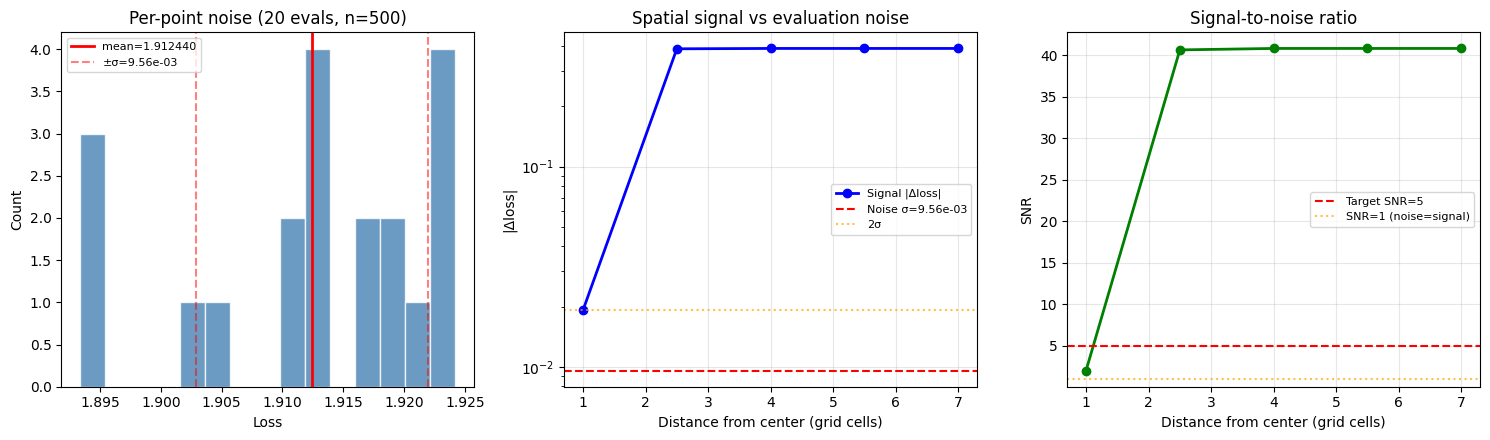

Done.


In [37]:
# @title Topology Grid Noise Floor Evaluation
# ============================================================================
# Measures the per-point evaluation noise in the topology loss grid.
#
# Because train_loader has shuffle=True, each call to
# _topology_compute_loss_at_point draws a different random subset of
# num_samples images. This creates Monte Carlo noise at every grid point.
# If that noise exceeds the spatial variation across the grid, persistent
# homology will detect noise artifacts rather than real landscape features.
#
# This cell:
#   1. Evaluates the center point N_REPEATS times to measure noise std
#   2. Evaluates a few perturbed points to measure the spatial signal
#   3. Computes signal-to-noise ratio (SNR)
#   4. Recommends num_samples needed for SNR ≥ target
#
# Run this AFTER training (or after loading a checkpoint) so the model
# is in its trained state. Requires cell 16 (topology setup) to have run.
# ============================================================================

if globals().get('PARAM_EXPLORE_MODE', False):
    print('PARAM_EXPLORE_MODE is True. Skipping noise evaluation.')
else:
    import time as _time

    # --- Configuration ---
    N_REPEATS = 20           # Times to re-evaluate each point
    N_SPATIAL_PROBES = 5     # Number of perturbation distances to test
    TARGET_SNR = 5.0         # Desired signal-to-noise ratio

    _num_samples = TOPOLOGY_CONFIG['num_samples']
    _pert_range = TOPOLOGY_CONFIG['perturbation_range']
    _grid_size = TOPOLOGY_CONFIG['grid_size']
    _cell_size = (2 * _pert_range) / (_grid_size - 1)
    _device = model.device

    print('=' * 70)
    print('TOPOLOGY GRID NOISE FLOOR EVALUATION')
    print('=' * 70)
    print(f'  num_samples per grid point: {_num_samples}')
    print(f'  perturbation_range: ±{_pert_range}')
    print(f'  grid_size: {_grid_size}×{_grid_size}')
    print(f'  cell_size: {_cell_size:.4f} param units')
    print(f'  repeats for noise estimate: {N_REPEATS}')
    print()

    # ================================================================
    # Step 1: Measure per-point noise at the center (current params)
    # ================================================================
    print('Step 1: Measuring evaluation noise at center point...')
    _t0 = _time.time()

    center_losses = []
    for rep in range(N_REPEATS):
        loss_val = _topology_compute_loss_at_point(
            model, criterion, train_loader, _device, _num_samples
        )
        center_losses.append(loss_val)
        if (rep + 1) % 5 == 0:
            print(f'    {rep+1}/{N_REPEATS} done...')

    center_losses = np.array(center_losses)
    noise_mean = center_losses.mean()
    noise_std = center_losses.std()
    noise_sem = noise_std  # This IS the per-point std (each eval uses num_samples)

    _t1 = _time.time()
    _per_eval_sec = (_t1 - _t0) / N_REPEATS

    print(f'\n  Center point loss: {noise_mean:.6f} ± {noise_std:.6f}')
    print(f'  Per-point noise σ = {noise_std:.2e}')
    print(f'  Time per evaluation: {_per_eval_sec:.2f}s')
    print()

    # ================================================================
    # Step 2: Measure spatial signal at various perturbation distances
    # ================================================================
    print('Step 2: Measuring spatial signal at perturbed points...')

    # Save original parameters
    _param1_name = TOPOLOGY_CONFIG['param1_name']  # 'bias_e'
    _param2_name = TOPOLOGY_CONFIG['param2_name']  # 'bias_i'
    _original_params = {name: param.data.clone()
                        for name, param in model.named_parameters()}

    _param1_ref = dict(model.named_parameters())[_param1_name]
    _param2_ref = dict(model.named_parameters())[_param2_name]
    _p1_center = _param1_ref.item()
    _p2_center = _param2_ref.item()

    # Test perturbation distances from 1 cell to full range
    _distances = np.linspace(_cell_size, _pert_range, N_SPATIAL_PROBES)

    spatial_results = []
    for dist in _distances:
        # Perturb along bias_e axis (holding bias_i constant)
        losses_at_dist = []
        for rep in range(max(3, N_REPEATS // 4)):
            loss_val = _topology_compute_loss_at_params_domain(
                model, criterion, train_loader, _device,
                _param1_name, _p1_center + dist,
                _param2_name, _p2_center,
                _num_samples, _original_params
            )
            losses_at_dist.append(loss_val)

        mean_at_dist = np.mean(losses_at_dist)
        std_at_dist = np.std(losses_at_dist)
        signal = abs(mean_at_dist - noise_mean)
        snr = signal / noise_std if noise_std > 0 else np.inf

        spatial_results.append({
            'distance': dist,
            'distance_cells': dist / _cell_size,
            'mean_loss': mean_at_dist,
            'std_loss': std_at_dist,
            'signal': signal,
            'snr': snr,
        })
        print(f'    Δ{_param1_name}={dist:+.4f} ({dist/_cell_size:.1f} cells): '
              f'loss={mean_at_dist:.6f}, signal={signal:.2e}, SNR={snr:.1f}')

    print()

    # ================================================================
    # Step 3: Compute signal at 1-cell spacing (the critical scale)
    # ================================================================
    # The signal between adjacent grid cells determines whether topology
    # can distinguish real features from noise.

    _one_cell_result = min(spatial_results, key=lambda r: abs(r['distance_cells'] - 1.0))
    _adj_cell_signal = _one_cell_result['signal']
    _adj_cell_snr = _one_cell_result['snr']

    # Also compute signal across the full grid range
    _full_range_result = spatial_results[-1]
    _full_signal = _full_range_result['signal']
    _full_snr = _full_range_result['snr']

    print('=' * 70)
    print('RESULTS')
    print('=' * 70)
    print(f'  Per-point evaluation noise: σ = {noise_std:.2e}')
    print(f'  Signal at 1-cell spacing:   Δ = {_adj_cell_signal:.2e}  (SNR = {_adj_cell_snr:.1f})')
    print(f'  Signal at full range:       Δ = {_full_signal:.2e}  (SNR = {_full_snr:.1f})')
    print()

    if _adj_cell_snr < 1.0:
        print('  ⚠️  NOISE-DOMINATED: Adjacent grid cells are indistinguishable.')
        print('  The persistent homology is analyzing noise, not landscape structure.')
    elif _adj_cell_snr < TARGET_SNR:
        print(f'  ⚠️  LOW SNR: Adjacent cells barely distinguishable (SNR={_adj_cell_snr:.1f}).')
    else:
        print(f'  ✓ ADEQUATE SNR: Adjacent cells well-resolved (SNR={_adj_cell_snr:.1f}).')
    print()

    # ================================================================
    # Step 4: Recommend num_samples
    # ================================================================
    # Noise scales as 1/√n, so:
    #   σ(n) = σ(100) × √(100/n)
    #   For target SNR at 1-cell spacing:
    #     signal / σ(n) ≥ TARGET_SNR
    #     n ≥ 100 × (σ(100) × TARGET_SNR / signal)²

    print('=' * 70)
    print('RECOMMENDATIONS')
    print('=' * 70)

    if _adj_cell_signal > 0:
        _n_needed = _num_samples * (noise_std * TARGET_SNR / _adj_cell_signal) ** 2
        _n_needed = int(np.ceil(_n_needed))

        print(f'\n  To achieve SNR ≥ {TARGET_SNR:.0f} at 1-cell resolution:')
        print(f'    num_samples needed: {_n_needed}')
        print(f'    Current:           {_num_samples}')
        print(f'    Factor increase:   {_n_needed / _num_samples:.1f}×')
        print()

        _time_per_grid = _per_eval_sec * _grid_size ** 2 * (_n_needed / _num_samples)
        _time_current = _per_eval_sec * _grid_size ** 2
        print(f'  Estimated time per topology measurement:')
        print(f'    Current ({_num_samples} samples, {_grid_size}×{_grid_size}):'
              f'  {_time_current:.0f}s ({_time_current/60:.1f} min)')
        print(f'    Proposed ({_n_needed} samples, {_grid_size}×{_grid_size}):'
              f' {_time_per_grid:.0f}s ({_time_per_grid/60:.1f} min)')
        print()

        # Alternative: keep num_samples but reduce grid size
        # Fewer grid points = can afford more samples per point
        # But need at least ~9×9 for meaningful topology
        if _n_needed > _num_samples * 4:
            print('  Alternative strategies (since >4× samples is expensive):')
            print()

            # Strategy A: Use a fixed eval set (no shuffle noise)
            print('  A) USE A FIXED EVALUATION SET (recommended):')
            print('     Pre-sample a fixed batch of images once, reuse for all')
            print('     grid points. Eliminates shuffle noise entirely.')
            print('     Signal-to-noise becomes deterministic (infinite SNR).')
            print()

            # Strategy B: Reduce grid, increase samples
            _budget = _grid_size ** 2 * _num_samples  # total image evals
            _n_for_9 = _budget // (9 * 9)
            _noise_at_9 = noise_std * np.sqrt(_num_samples / _n_for_9)
            _snr_at_9 = _adj_cell_signal / _noise_at_9 if _noise_at_9 > 0 else np.inf
            # Note: cell size changes with grid size
            _cell_9 = (2 * _pert_range) / (9 - 1)
            print(f'  B) REDUCE GRID TO 9×9, increase samples to {_n_for_9}:')
            print(f'     Same total compute budget ({_budget} image evals).')
            print(f'     Noise drops to ~{_noise_at_9:.2e} (from {noise_std:.2e})')
            print(f'     But cell size increases to {_cell_9:.4f} (from {_cell_size:.4f})')
            print()

            # Strategy C: Increase samples moderately + reduce grid moderately
            _n_s_new = _num_samples * 4
            _g_new = int(np.sqrt(_budget / _n_s_new))
            if _g_new % 2 == 0: _g_new += 1
            _g_new = max(7, min(_g_new, _grid_size))
            _noise_c = noise_std * np.sqrt(_num_samples / _n_s_new)
            _snr_c = _adj_cell_signal / _noise_c if _noise_c > 0 else np.inf
            print(f'  C) BALANCED: {_g_new}×{_g_new} grid, {_n_s_new} samples:')
            print(f'     Noise ~{_noise_c:.2e}, approx SNR ~{_snr_c:.1f}')
            print()

    else:
        print('  Signal at 1-cell spacing is zero — landscape may be truly flat')
        print('  in this region. No amount of samples will help if there is no signal.')
    print()

    # ================================================================
    # Step 5: Visualization
    # ================================================================
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    # Panel 1: Noise distribution
    ax1 = axes[0]
    ax1.hist(center_losses, bins=min(15, N_REPEATS), color='steelblue',
             edgecolor='white', alpha=0.8)
    ax1.axvline(noise_mean, color='red', linestyle='-', linewidth=2, label=f'mean={noise_mean:.6f}')
    ax1.axvline(noise_mean - noise_std, color='red', linestyle='--', alpha=0.5)
    ax1.axvline(noise_mean + noise_std, color='red', linestyle='--', alpha=0.5,
                label=f'±σ={noise_std:.2e}')
    ax1.set_xlabel('Loss')
    ax1.set_ylabel('Count')
    ax1.set_title(f'Per-point noise ({N_REPEATS} evals, n={_num_samples})')
    ax1.legend(fontsize=8)

    # Panel 2: Signal vs distance
    ax2 = axes[1]
    dists_cells = [r['distance_cells'] for r in spatial_results]
    signals = [r['signal'] for r in spatial_results]
    ax2.plot(dists_cells, signals, 'b-o', linewidth=2, markersize=6, label='Signal |Δloss|')
    ax2.axhline(noise_std, color='red', linestyle='--', linewidth=1.5,
                label=f'Noise σ={noise_std:.2e}')
    ax2.axhline(noise_std * 2, color='orange', linestyle=':', alpha=0.7, label='2σ')
    ax2.set_xlabel(f'Distance from center (grid cells)')
    ax2.set_ylabel('|Δloss|')
    ax2.set_title('Spatial signal vs evaluation noise')
    ax2.legend(fontsize=8)
    ax2.set_yscale('log')
    ax2.grid(True, alpha=0.3)

    # Panel 3: SNR vs distance
    ax3 = axes[2]
    snrs = [r['snr'] for r in spatial_results]
    ax3.plot(dists_cells, snrs, 'g-o', linewidth=2, markersize=6)
    ax3.axhline(TARGET_SNR, color='red', linestyle='--', label=f'Target SNR={TARGET_SNR:.0f}')
    ax3.axhline(1.0, color='orange', linestyle=':', alpha=0.7, label='SNR=1 (noise=signal)')
    ax3.set_xlabel('Distance from center (grid cells)')
    ax3.set_ylabel('SNR')
    ax3.set_title('Signal-to-noise ratio')
    ax3.legend(fontsize=8)
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print('Done.')


PERTURBATION RANGE SWEEP
  Ranges to test: ±[0.5, 1.0, 2.0, 4.0]
  Grid size: 15×15
  Samples per grid point: 500
  Methods: ['domain', 'hessian']


  METHOD: DOMAIN

  --- Perturbation range: ±0.5 ---
    Pre-sampled fixed evaluation batch: 500 images
    Sampling 15x15 grid (domain method, v80 batched)...
      bias_e: [-0.553, 0.447] (center: -0.053)
      bias_i: [-6.305, -5.305] (center: -5.805)
    Saddle points:     0
    Local minima:      1
    Avg persistence:   0.000000
    Max persistence:   0.000000
    Loss range:        [1.7967, 2.3201] (Δ=0.5234)
    Time:              20.7s

  --- Perturbation range: ±1.0 ---
    Pre-sampled fixed evaluation batch: 500 images
    Sampling 15x15 grid (domain method, v80 batched)...
      bias_e: [-1.053, 0.947] (center: -0.053)
      bias_i: [-6.805, -4.805] (center: -5.805)
    Saddle points:     1
    Local minima:      2
    Avg persistence:   0.000942
    Max persistence:   0.000942
    Loss range:        [1.7928, 2.3720] (Δ=0.5792)

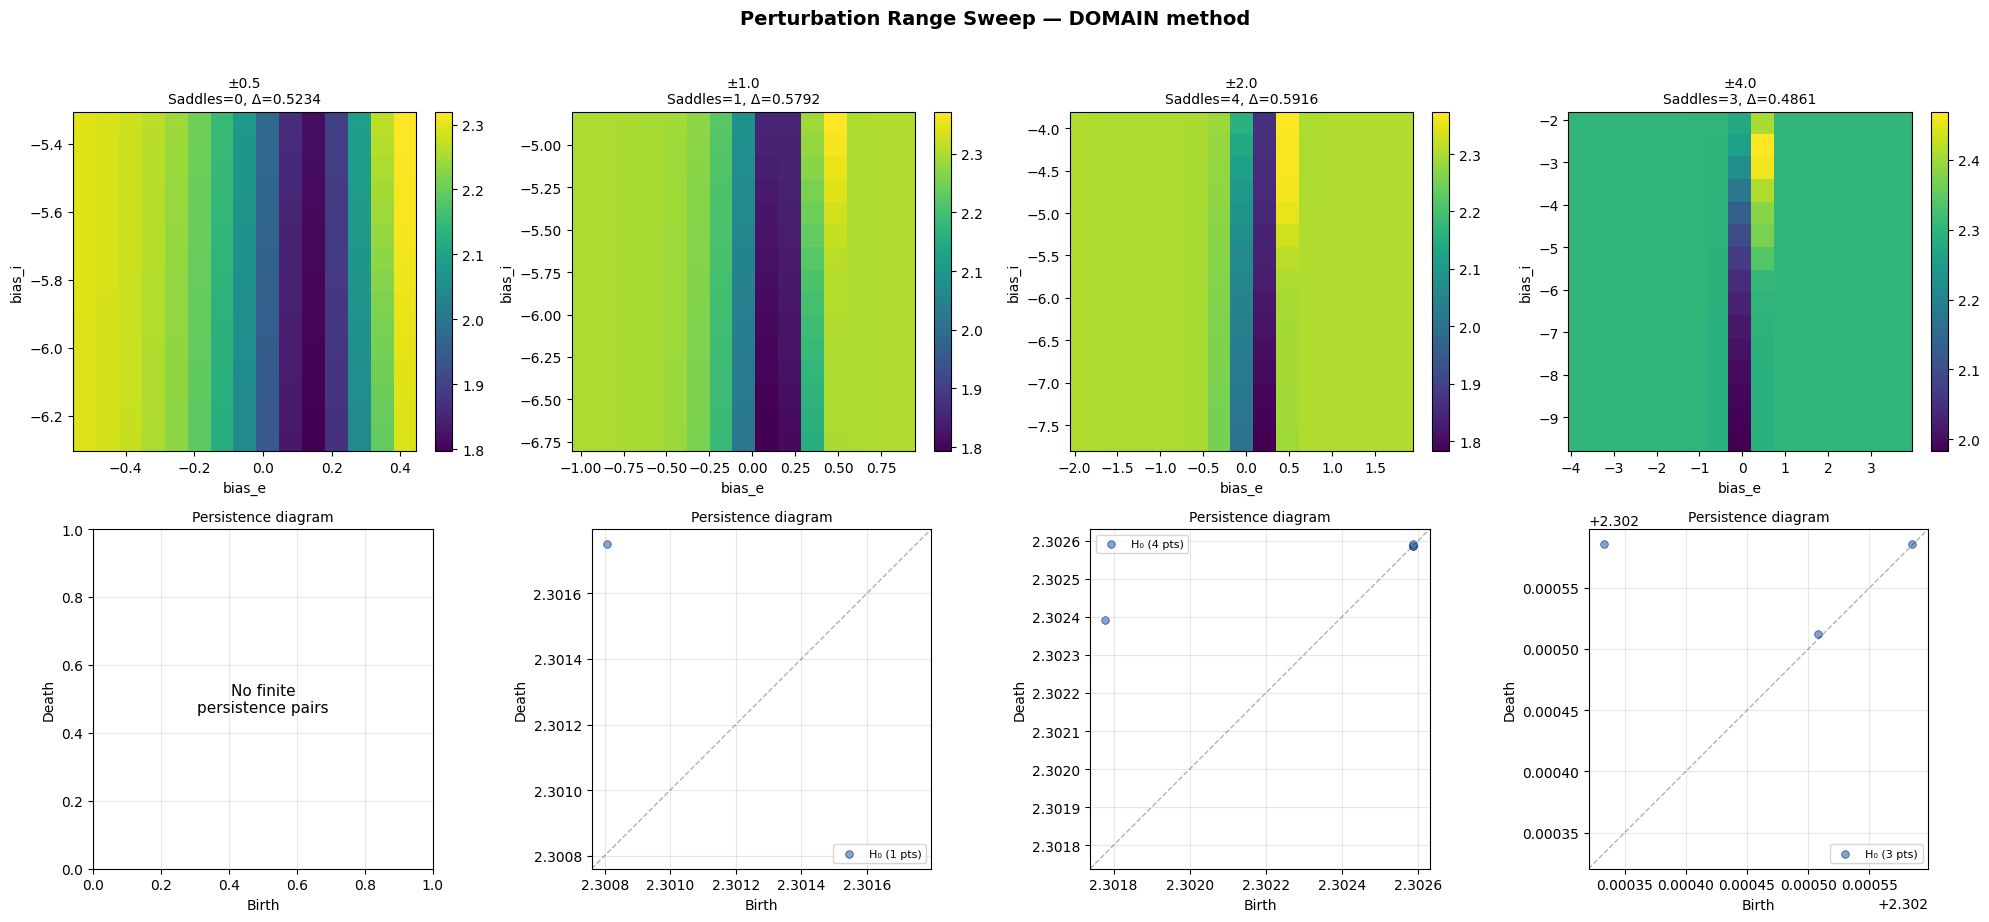

📷 Captured figure 117 -> saved_figures/figure_117_5dc22d61.png


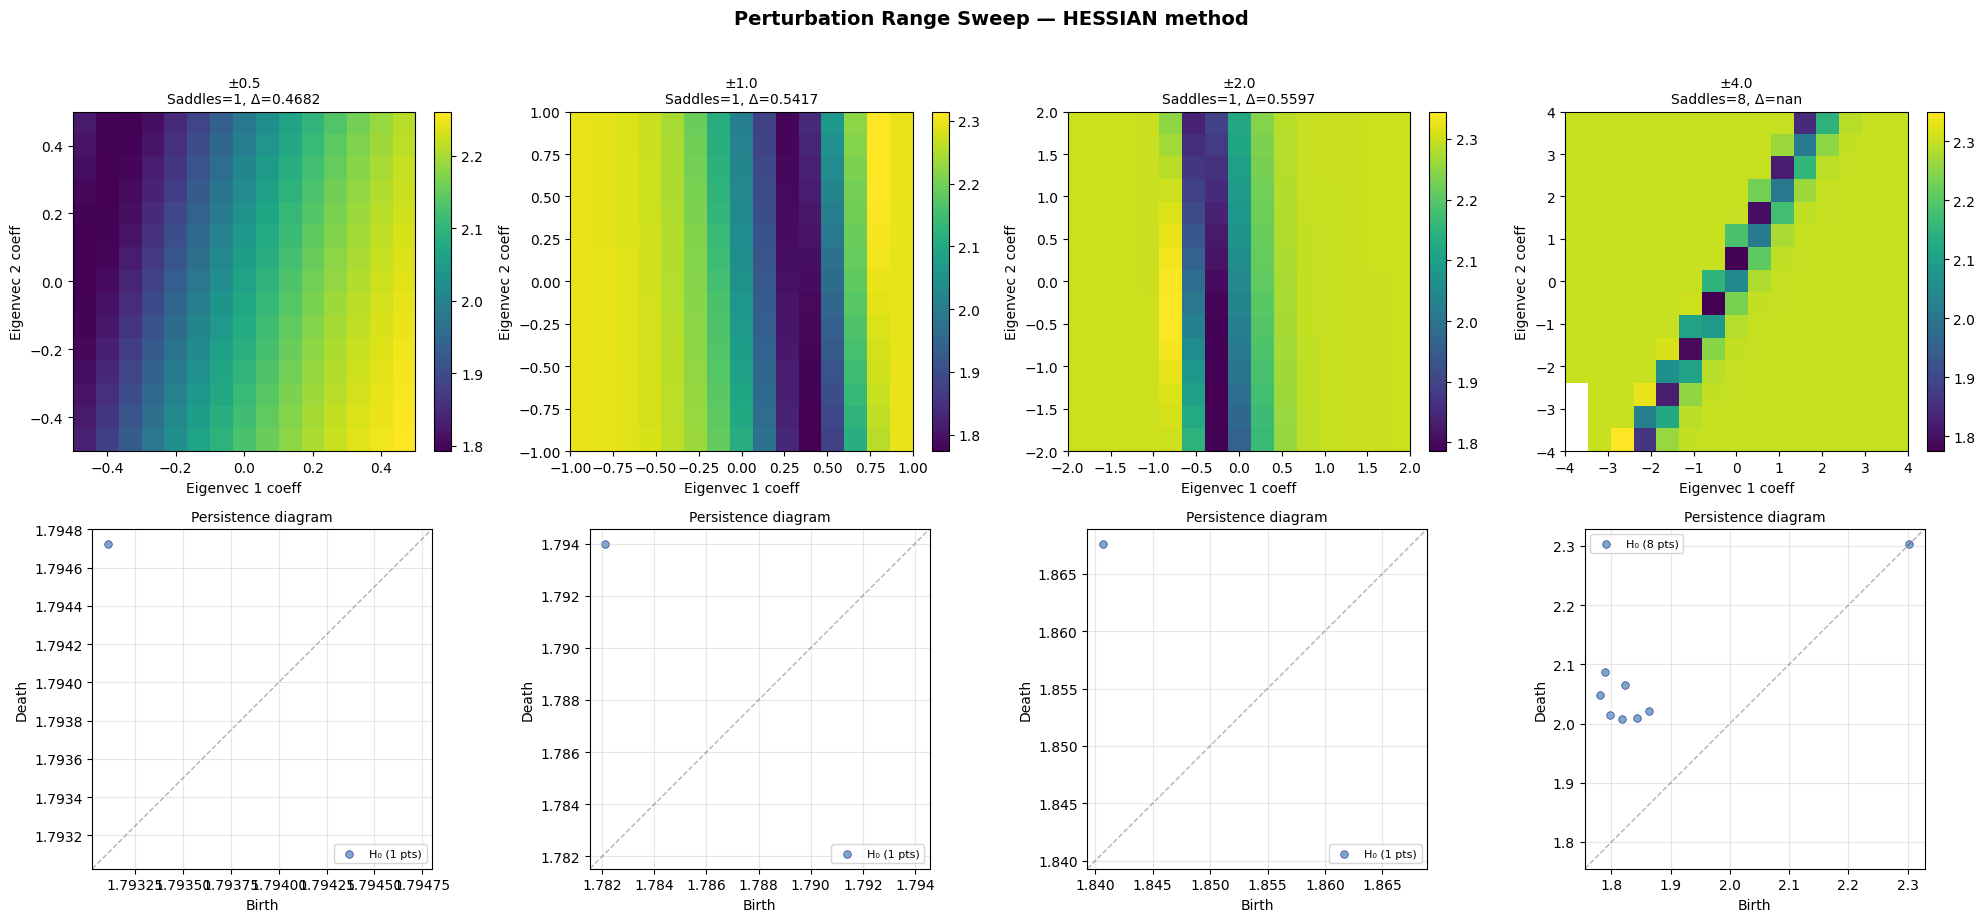

📷 Captured figure 118 -> saved_figures/figure_118_825ffcaa.png


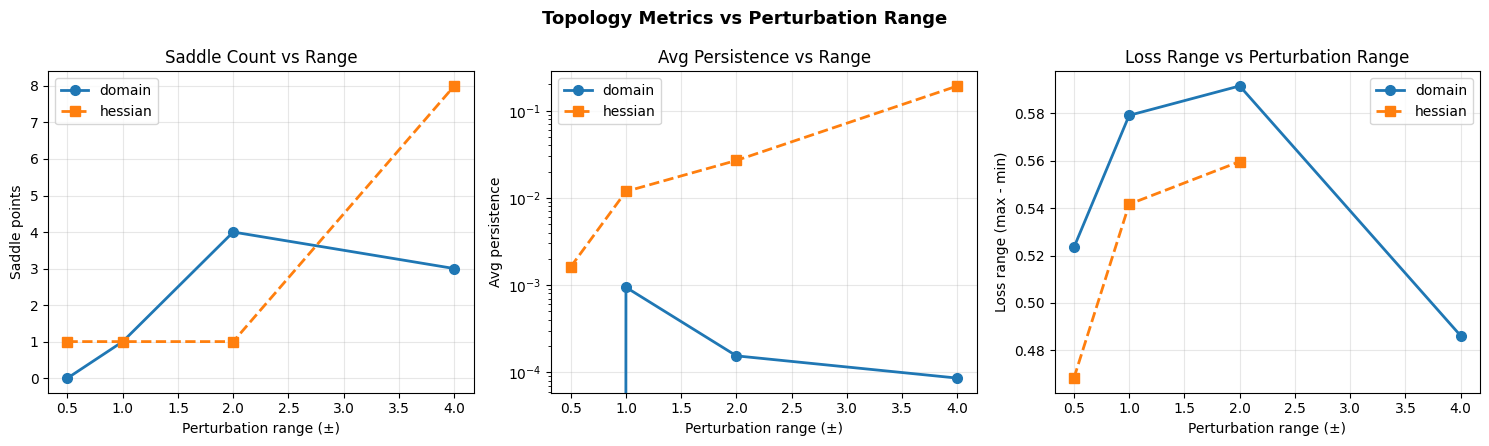


Done. Look for where saddle count and persistence plateau — that indicates the perturbation range captures the full basin structure.


In [38]:
# @title Perturbation Range Sweep — Find the right scale for topology analysis
# ============================================================================
# Runs topology analysis at multiple perturbation ranges (±1.0, ±2.0, ±4.0)
# using the current trained model state. Compares saddle counts, persistence,
# and loss range across scales to find where landscape features stabilize.
#
# Run this AFTER training completes. Requires cell 16 (topology setup),
# the trained model, criterion, and train_loader to be in scope.
# ============================================================================

if globals().get('PARAM_EXPLORE_MODE', False):
    print('PARAM_EXPLORE_MODE is True. Skipping perturbation range sweep.')
else:
    import time as _sweep_time

    # --- Configuration ---
    SWEEP_RANGES = [0.5, 1.0, 2.0, 4.0]  # perturbation ranges to test
    SWEEP_GRID_SIZE = TOPOLOGY_CONFIG['grid_size']       # use same grid resolution
    SWEEP_NUM_SAMPLES = TOPOLOGY_CONFIG['num_samples']   # use same sample count
    SWEEP_METHODS = ['domain', 'hessian']  # which methods to sweep

    _device = model.device

    print('=' * 70)
    print('PERTURBATION RANGE SWEEP')
    print('=' * 70)
    print(f'  Ranges to test: ±{SWEEP_RANGES}')
    print(f'  Grid size: {SWEEP_GRID_SIZE}×{SWEEP_GRID_SIZE}')
    print(f'  Samples per grid point: {SWEEP_NUM_SAMPLES}')
    print(f'  Methods: {SWEEP_METHODS}')
    print()

    sweep_results = {}  # {method: {range: {metrics + grid}}}

    for method in SWEEP_METHODS:
        sweep_results[method] = {}
        print(f'\n{"="*70}')
        print(f'  METHOD: {method.upper()}')
        print(f'{"="*70}')

        for pert_range in SWEEP_RANGES:
            print(f'\n  --- Perturbation range: ±{pert_range} ---')
            _t0 = _sweep_time.time()

            if method == 'domain':
                coord1, coord2, loss_grid, metadata = _topology_sample_loss_landscape_domain(
                    model, criterion, train_loader, _device,
                    TOPOLOGY_CONFIG['param1_name'], TOPOLOGY_CONFIG['param2_name'],
                    SWEEP_GRID_SIZE, pert_range, SWEEP_NUM_SAMPLES,
                    verbose=True
                )
            else:  # hessian
                coord1, coord2, loss_grid, metadata = _topology_sample_loss_landscape_hessian(
                    model, criterion, train_loader, _device,
                    SWEEP_GRID_SIZE, pert_range, SWEEP_NUM_SAMPLES,
                    TOPOLOGY_CONFIG.get('hessian_num_samples', 100),
                    verbose=True
                )

            metrics = _topology_compute_metrics(loss_grid)
            _elapsed = _sweep_time.time() - _t0

            sweep_results[method][pert_range] = {
                'metrics': metrics,
                'loss_grid': loss_grid,
                'coord1': coord1,
                'coord2': coord2,
                'metadata': metadata,
                'elapsed': _elapsed,
            }

            print(f'    Saddle points:     {metrics["num_saddle_points"]}')
            print(f'    Local minima:      {metrics["num_minima"]}')
            avg_p = metrics['avg_persistence']
            max_p = metrics['max_persistence']
            if avg_p > 0 and avg_p < 0.0001:
                print(f'    Avg persistence:   {avg_p:.2e}')
            else:
                print(f'    Avg persistence:   {avg_p:.6f}')
            if max_p > 0 and max_p < 0.0001:
                print(f'    Max persistence:   {max_p:.2e}')
            else:
                print(f'    Max persistence:   {max_p:.6f}')
            print(f'    Loss range:        [{metrics["loss_min"]:.4f}, {metrics["loss_max"]:.4f}] '
                  f'(Δ={metrics["loss_range"]:.4f})')
            print(f'    Time:              {_elapsed:.1f}s')

    # ================================================================
    # Summary table
    # ================================================================
    print(f'\n\n{"="*70}')
    print('SWEEP SUMMARY')
    print(f'{"="*70}')
    for method in SWEEP_METHODS:
        print(f'\n  {method.upper()} METHOD:')
        print(f'  {"Range":>8}  {"Saddles":>8}  {"Minima":>8}  {"Avg Persist":>14}  '
              f'{"Max Persist":>14}  {"Loss Range":>12}')
        print(f'  {"-"*8}  {"-"*8}  {"-"*8}  {"-"*14}  {"-"*14}  {"-"*12}')
        for pert_range in SWEEP_RANGES:
            m = sweep_results[method][pert_range]['metrics']
            avg_p = m['avg_persistence']
            max_p = m['max_persistence']
            avg_s = f'{avg_p:.2e}' if avg_p < 0.001 else f'{avg_p:.6f}'
            max_s = f'{max_p:.2e}' if max_p < 0.001 else f'{max_p:.6f}'
            print(f'  ±{pert_range:<7.1f} {m["num_saddle_points"]:>8d}  {m["num_minima"]:>8d}  '
                  f'{avg_s:>14}  {max_s:>14}  {m["loss_range"]:>12.4f}')

    # ================================================================
    # Visualization
    # ================================================================
    for method in SWEEP_METHODS:
        n_ranges = len(SWEEP_RANGES)
        fig, axes = plt.subplots(2, n_ranges, figsize=(5 * n_ranges, 9))
        if n_ranges == 1:
            axes = axes.reshape(2, 1)

        for idx, pert_range in enumerate(SWEEP_RANGES):
            res = sweep_results[method][pert_range]
            grid = res['loss_grid']
            m = res['metrics']

            # Row 1: Loss grid heatmap
            ax1 = axes[0, idx]
            c1 = res['coord1']
            c2 = res['coord2']
            im = ax1.imshow(grid, cmap='viridis', origin='lower', aspect='auto',
                           extent=[c1[0], c1[-1], c2[0], c2[-1]])
            ax1.set_title(f'±{pert_range}\n'
                         f'Saddles={m["num_saddle_points"]}, '
                         f'Δ={m["loss_range"]:.4f}',
                         fontsize=10)
            if method == 'domain':
                ax1.set_xlabel(TOPOLOGY_CONFIG['param1_name'])
                ax1.set_ylabel(TOPOLOGY_CONFIG['param2_name'])
            else:
                ax1.set_xlabel('Eigenvec 1 coeff')
                ax1.set_ylabel('Eigenvec 2 coeff')
            plt.colorbar(im, ax=ax1, fraction=0.046)

            # Row 2: Persistence diagram
            ax2 = axes[1, idx]
            # Recompute persistence pairs for plotting
            cubical_complex = gudhi.CubicalComplex(
                top_dimensional_cells=grid.flatten(),
                dimensions=grid.shape
            )
            cubical_complex.compute_persistence()

            births_0, deaths_0 = [], []
            for interval in cubical_complex.persistence_intervals_in_dimension(0):
                b, d = interval
                if not np.isinf(d):
                    births_0.append(b)
                    deaths_0.append(d)

            if births_0:
                ax2.scatter(births_0, deaths_0, c='steelblue', s=30, alpha=0.7,
                           edgecolors='navy', linewidths=0.5, label=f'H₀ ({len(births_0)} pts)')
                # Diagonal reference line
                all_vals = births_0 + deaths_0
                lo, hi = min(all_vals), max(all_vals)
                margin = (hi - lo) * 0.05 if hi > lo else 0.001
                ax2.plot([lo - margin, hi + margin], [lo - margin, hi + margin],
                        'k--', alpha=0.3, linewidth=1)
                ax2.set_xlim(lo - margin, hi + margin)
                ax2.set_ylim(lo - margin, hi + margin)
                ax2.legend(fontsize=8)
            else:
                ax2.text(0.5, 0.5, 'No finite\npersistence pairs',
                        ha='center', va='center', transform=ax2.transAxes, fontsize=11)

            ax2.set_xlabel('Birth')
            ax2.set_ylabel('Death')
            ax2.set_title(f'Persistence diagram', fontsize=10)
            ax2.set_aspect('equal')
            ax2.grid(True, alpha=0.3)

        fig.suptitle(f'Perturbation Range Sweep — {method.upper()} method',
                    fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.show()

    # ================================================================
    # Trend plot: metrics vs perturbation range
    # ================================================================
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    for method in SWEEP_METHODS:
        ranges = SWEEP_RANGES
        saddles = [sweep_results[method][r]['metrics']['num_saddle_points'] for r in ranges]
        avg_pers = [sweep_results[method][r]['metrics']['avg_persistence'] for r in ranges]
        loss_ranges = [sweep_results[method][r]['metrics']['loss_range'] for r in ranges]

        style = '-o' if method == 'domain' else '--s'
        axes[0].plot(ranges, saddles, style, label=method, linewidth=2, markersize=7)
        axes[1].plot(ranges, avg_pers, style, label=method, linewidth=2, markersize=7)
        axes[2].plot(ranges, loss_ranges, style, label=method, linewidth=2, markersize=7)

    axes[0].set_xlabel('Perturbation range (±)')
    axes[0].set_ylabel('Saddle points')
    axes[0].set_title('Saddle Count vs Range')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].set_xlabel('Perturbation range (±)')
    axes[1].set_ylabel('Avg persistence')
    axes[1].set_title('Avg Persistence vs Range')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].set_yscale('log')

    axes[2].set_xlabel('Perturbation range (±)')
    axes[2].set_ylabel('Loss range (max - min)')
    axes[2].set_title('Loss Range vs Perturbation Range')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.suptitle('Topology Metrics vs Perturbation Range', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print('\nDone. Look for where saddle count and persistence plateau — '
          'that indicates the perturbation range captures the full basin structure.')


In [39]:
# @title v79: Export topology data to Excel for manual Seizure annotation
# ============================================================================
# Exports all topology measurements from both methods to an Excel workbook.
# Two sheets: "Domain Topology" and "Hessian Topology".
# The "Seizure" column is left blank — fill it in manually after inspecting
# the raster heatmaps, then re-upload for downstream analysis.
#
# Also exports the 1-D E-I balance scan as a third sheet ("EI Scan").
# ============================================================================

if globals().get("PARAM_EXPLORE_MODE", False):
    print("PARAM_EXPLORE_MODE is True. Skipping topology export.")
else:
    try:
        import openpyxl
    except ImportError:
        get_ipython().system('pip install openpyxl --quiet')
        import openpyxl

    import os
    import math

    def _safe(v):
        """Convert NaN/inf to None (Excel-safe)."""
        try:
            if v is None:
                return None
            f = float(v)
            return None if (math.isnan(f) or math.isinf(f)) else f
        except Exception:
            return str(v)

    wb = openpyxl.Workbook()

    # ─────────────────────────────────────────────────────────────────────
    # Sheet 1: Domain topology (one row per measurement epoch)
    # ─────────────────────────────────────────────────────────────────────
    ws_d = wb.active
    ws_d.title = "Domain Topology"

    domain_headers = [
        "Epoch", "Train Loss", "Train Acc (%)",
        "bias_e_center", "bias_i_center",
        "Num Saddle Points", "Avg Persistence", "Max Persistence",
        "Loss Min", "Loss Max", "Loss Range", "Loss Std",
        "Local Minima Locations (bi, be, loss)",
        "Seizure",
    ]
    ws_d.append(domain_headers)

    if 'topology_tracker_domain' in globals():
        td = topology_tracker_domain
        n = len(td.epochs)
        for k in range(n):
            locs = td.local_minima_locations[k] if k < len(td.local_minima_locations) else []
            locs_str = " | ".join(
                f"bi={bi:.3f} be={be:.3f} L={lv:.4f}"
                for (bi, be, lv) in locs
            ) if locs else ""
            row = [
                td.epochs[k],
                _safe(td.train_loss[k] if k < len(td.train_loss) else None),
                _safe(td.train_acc[k]  if k < len(td.train_acc)  else None),
                _safe(td.param1_values[k] if k < len(td.param1_values) else None),
                _safe(td.param2_values[k] if k < len(td.param2_values) else None),
                td.num_saddle_points[k],
                _safe(td.avg_persistence[k]),
                _safe(td.max_persistence[k]),
                _safe(td.loss_min_list[k] if k < len(td.loss_min_list) else None),
                _safe(td.loss_max_list[k] if k < len(td.loss_max_list) else None),
                _safe(td.loss_range[k]),
                _safe(td.loss_std_list[k] if k < len(td.loss_std_list) else None),
                locs_str,
                "",   # Seizure — fill manually
            ]
            ws_d.append(row)
    else:
        ws_d.append(["topology_tracker_domain not found"])

    # ─────────────────────────────────────────────────────────────────────
    # Sheet 2: Hessian topology
    # ─────────────────────────────────────────────────────────────────────
    ws_h = wb.create_sheet("Hessian Topology")

    # v82: discover parameter group names from eigenvector energy data
    _param_groups_v82 = []
    if 'topology_tracker_hessian' in globals():
        _th = topology_tracker_hessian
        if hasattr(_th, 'eigvec1_param_energy'):
            for _d in _th.eigvec1_param_energy:
                if _d:
                    _param_groups_v82 = list(_d.keys())
                    break

    hessian_headers = [
        "Epoch", "Train Loss", "Train Acc (%)",
        "Eigenvalue 1", "Eigenvalue 2",
        "Num Saddle Points", "Avg Persistence", "Max Persistence",
        "Loss Min", "Loss Max", "Loss Range", "Loss Std",
        "Eigvec1 bias_e proj", "Eigvec1 bias_i proj",
        "Eigvec1 angle from seizure normal (deg)",
    ] + [f"Eigvec1 frac: {pg}" for pg in _param_groups_v82
    ] + [f"Eigvec2 frac: {pg}" for pg in _param_groups_v82
    ] + ["Seizure"]
    ws_h.append(hessian_headers)

    if 'topology_tracker_hessian' in globals():
        th = topology_tracker_hessian
        n = len(th.epochs)
        for k in range(n):
            row = [
                th.epochs[k],
                _safe(th.train_loss[k] if k < len(th.train_loss) else None),
                _safe(th.train_acc[k]  if k < len(th.train_acc)  else None),
                _safe(th.eigenvalue1[k] if k < len(th.eigenvalue1) else None),
                _safe(th.eigenvalue2[k] if k < len(th.eigenvalue2) else None),
                th.num_saddle_points[k],
                _safe(th.avg_persistence[k]),
                _safe(th.max_persistence[k]),
                _safe(th.loss_min_list[k] if k < len(th.loss_min_list) else None),
                _safe(th.loss_max_list[k] if k < len(th.loss_max_list) else None),
                _safe(th.loss_range[k]),
                _safe(th.loss_std_list[k] if k < len(th.loss_std_list) else None),
                _safe(th.eigvec1_bias_e_proj[k] if k < len(th.eigvec1_bias_e_proj) else None),
                _safe(th.eigvec1_bias_i_proj[k] if k < len(th.eigvec1_bias_i_proj) else None),
                _safe(th.eigvec1_bias_angle[k]  if k < len(th.eigvec1_bias_angle)  else None),
            ]
            # v82: append per-param-group energy fractions
            _e1 = th.eigvec1_param_energy[k] if hasattr(th, 'eigvec1_param_energy') and k < len(th.eigvec1_param_energy) else {}
            _e2 = th.eigvec2_param_energy[k] if hasattr(th, 'eigvec2_param_energy') and k < len(th.eigvec2_param_energy) else {}
            _frac1 = [_safe(_e1.get(pg, {}).get('frac', None)) if _e1 else None for pg in _param_groups_v82]
            _frac2 = [_safe(_e2.get(pg, {}).get('frac', None)) if _e2 else None for pg in _param_groups_v82]
            row.extend(_frac1)
            row.extend(_frac2)
            row.append("")   # Seizure — fill manually
            ws_h.append(row)
    else:
        ws_h.append(["topology_tracker_hessian not found"])

    # ─────────────────────────────────────────────────────────────────────
    # Sheet 3: 1-D E-I balance scan (one row per scan point per epoch)
    # ─────────────────────────────────────────────────────────────────────
    ws_s = wb.create_sheet("EI Scan")
    scan_headers = [
        "Epoch", "t (E-I balance offset)", "Loss", "bias_e", "bias_i", "Seizure"
    ]
    ws_s.append(scan_headers)

    if 'topology_tracker_domain' in globals():
        td = topology_tracker_domain
        for k, ep in enumerate(td.epochs):
            t_v  = td.ei_scan_t[k]    if k < len(td.ei_scan_t)    else []
            l_v  = td.ei_scan_loss[k] if k < len(td.ei_scan_loss) else []
            be_v = td.ei_scan_be[k]   if k < len(td.ei_scan_be)   else []
            bi_v = td.ei_scan_bi[k]   if k < len(td.ei_scan_bi)   else []
            for t, l, be, bi in zip(t_v, l_v, be_v, bi_v):
                ws_s.append([ep, _safe(t), _safe(l), _safe(be), _safe(bi), ""])

    # ─────────────────────────────────────────────────────────────────────
    # Auto-size columns
    # ─────────────────────────────────────────────────────────────────────
    for ws in [ws_d, ws_h, ws_s]:
        for col in ws.columns:
            max_len = max((len(str(cell.value)) for cell in col if cell.value), default=8)
            ws.column_dimensions[col[0].column_letter].width = min(max_len + 2, 60)

    # Save
    out_dir = globals().get("OUTPUT_DIR", "/content/drive/MyDrive/Colab Notebooks/Learning and Seizures 12_5_25")
    os.makedirs(out_dir, exist_ok=True)
    timestamp_tag = globals().get("timestamp", "notimestamp")
    topo_xlsx_path = os.path.join(out_dir, f"topology_export_{timestamp_tag}.xlsx")
    wb.save(topo_xlsx_path)
    print(f"✅ Topology spreadsheet saved: {topo_xlsx_path}")
    print(f"   Domain sheet:  {len(topology_tracker_domain.epochs) if 'topology_tracker_domain' in globals() else 0} epochs")
    print(f"   Hessian sheet: {len(topology_tracker_hessian.epochs) if 'topology_tracker_hessian' in globals() else 0} epochs")
    print(f"   EI Scan sheet: fill 'Seizure' column manually after inspecting raster heatmaps")


✅ Topology spreadsheet saved: /content/drive/MyDrive/Colab Notebooks/Learning and Seizures 12_5_25/topology_export_20260330_213339.xlsx
   Domain sheet:  21 epochs
   Hessian sheet: 21 epochs
   EI Scan sheet: fill 'Seizure' column manually after inspecting raster heatmaps


In [40]:
# @title Gracefully finalize and disconnect Colab runtime
import time

print("All outputs written successfully.")
print("Disconnecting Colab runtime...")

time.sleep(2)

try:
    from google.colab import runtime
    runtime.unassign()
except Exception:
    print("Not running in Colab; exiting normally.")



All outputs written successfully.
Disconnecting Colab runtime...
